# Inicialização

## Import de bibliotecas

In [94]:
import os
import io
import sys
import time

import pandas as pd
import numpy as np
import collections
import seaborn as sns
import joblib
from pathlib import Path
import contextlib
from joblib import Parallel, delayed

import warnings
warnings.filterwarnings("ignore")
from pprint import pprint

# from google.colab import drive

from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox
from matplotlib.ticker import MaxNLocator

from sklearn import svm, tree
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.model_selection import cross_val_score, cross_val_predict, train_test_split, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score,accuracy_score,roc_curve,\
classification_report,confusion_matrix,auc, matthews_corrcoef
from sklearn.preprocessing import label_binarize, StandardScaler

pd.set_option('max_colwidth', 800)

In [96]:
# Project root: the first folder, from the working directory upwards, that holds
#   prototipo/, feature_store/ and datasets/. Lets the notebook run from any subfolder.
def find_project_root(markers=('prototipo', 'feature_store', 'datasets')):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if all((folder / marker).is_dir() for marker in markers):
            return folder
    raise RuntimeError(f'project root not found from {Path.cwd()}; '
                       f'expected a folder holding {markers}')


PROJECT_ROOT = find_project_root()

# Local modules, imported by file name, so their folders go on sys.path:
#   feature_store/pipeline.py                 -> fs (feature store)
#   scripts/evaluation/protocolo_temporal.py  -> pt (temporal evaluation protocol)
for folder in [PROJECT_ROOT / 'feature_store', PROJECT_ROOT / 'scripts' / 'evaluation']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import pipeline as fs
import protocolo_temporal as pt

print(f'project root       : {PROJECT_ROOT}')
print(f'fs (feature store) : {fs.__file__}')
print(f'pt (protocol)      : {pt.__file__}')

project root       : /home/beatrizam/Documents/beatriz/path-aware-datasets
fs (feature store) : /home/beatrizam/Documents/beatriz/path-aware-datasets/feature_store/pipeline.py
pt (protocol)      : /home/beatrizam/Documents/beatriz/path-aware-datasets/scripts/evaluation/protocolo_temporal.py


## Setup de plotagem de gráficos

In [97]:
rotas = {
    1: { 'cor': '#00bf63', 'nome': 'Verde' },
    2: { 'cor': '#ff3131', 'nome': 'Vermelho' },
    3: { 'cor': '#2440f7', 'nome': 'Azul' },
    4: { 'cor': '#ffd735', 'nome': 'Amarelo' }
}

# plots saving/showing configurations
save_file_flag=True
show_IV_plot=True

In [98]:
# function to return key for any value

def get_key(val,mydict):
	for key, value in mydict.items():
		if val == value:
			return key

def count_label(labels,labels_dic):
    label_buf=collections.Counter(labels)
    counted_labels_dic={get_key(key1,labels_dic):value1 for key1,value1 in label_buf.items()}
    return counted_labels_dic

In [99]:
def lines_plot(df_i,save_path,title_str='',y_label='',x_label='',save_file=''):

    fig=plt.figure()
    for key in df_i.keys():
        plt.plot(np.arange(len(df_i[key])),df_i[key],marker='x',label=key)
    plt.xticks(np.arange(len(df_i[key])),list(map(str,np.arange(1,len(df_i[key])+1,1))))
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title_str)
    #plt.legend(loc="best",bbox_to_anchor=(0.6, 0.4), ncol=2)
    plt.legend(loc="best")
    plt.grid()
    if save_file:
         plt.savefig(f"{os.path.join(save_path, save_file)}", dpi=300, format='pdf', bbox_inches='tight')
    plt.show()


def create_boxplot(valu_vec,save_path,date_set,title_str='',y_label='',x_label='',save_file=''):

    meanpointprops = dict(marker='+', markeredgecolor='darkgoldenrod',markerfacecolor='red')
    medianprops = dict(linestyle='-', linewidth=1, color='red')

    pltbx=plt.boxplot(valu_vec, showfliers=False,labels=date_set,meanprops=meanpointprops,medianprops=medianprops,
            showmeans=True,patch_artist=True)
    means_vals = [item.get_ydata()[0] for item in pltbx['means']]
    plt.setp(pltbx['boxes'], color='blue',facecolor='white')
    plt.title("%s"%title_str)
    #plt.ylim(0,10)
    plt.ylabel(y_label)
    plt.xlabel(x_label)
    #plt.xticks(rotation = 45)
    legend_elements = [Line2D([0], [0], color='red', lw=1, label='Median'),
                    Line2D([0], [0], color='darkgoldenrod',marker='+',label='Mean'),
                  Line2D([0], [0], color='blue', lw=1, label='25%-75%'),
                   Line2D([0], [0], color='black', lw=1, label='9%-91%')]
    plt.legend(handles=legend_elements,loc='best',  fancybox=True, framealpha=1)
    plt.grid()
    if save_file:
         plt.savefig(f"{os.path.join(save_path, save_file)}", dpi=300, format='pdf', bbox_inches='tight')
    plt.show()
    return means_vals

#####################################################################################################################

def call_compute_color_position(ax,confusion_mat):
    for i in range(confusion_mat.shape[0]):
        for j in range(confusion_mat.shape[1]):
            ax.text(x=j, y=i,s=confusion_mat[i, j], va='center', ha='center', size='large')
    ax.tick_params(top=False, bottom=True,labeltop=False, labelbottom=True)
    #ax.tick_params(top=True, bottom=False,labeltop=True, labelbottom=False)
    return ax

def plot_matrix(conf_mat,class_labels,classifier,title_str='',save_path='', file_prefix='mc'):

    fig = plt.figure()
    axes = fig.add_subplot(111)
    cax=axes.matshow(conf_mat, cmap=plt.cm.YlGnBu, alpha=0.8)
    fig.colorbar(cax)
    axes=call_compute_color_position(axes,conf_mat)
    axes.set_xlabel('Predictions')
    axes.set_ylabel('Actuals')
    axes.set_title(f'{title_str}',fontsize=10)
    axes.set_xticklabels([''] + class_labels)
    axes.set_yticklabels([''] + class_labels)
    if save_path and file_prefix:
        os.makedirs(save_path, exist_ok=True)
        file_to_save=f"{file_prefix}_{classifier}.png"
        plt.savefig(f"{os.path.join(save_path, file_to_save)}", dpi=300, bbox_inches='tight')
    plt.show()

In [100]:
def plot_roc_curve(y_test_binarized, class_labels, classifier, y_pred_proba, title_str='', save_path='', save_file='', binary_classification=True):
    n_class = len(class_labels)

    if binary_classification:
        unique_classes = np.unique(y_test)
        y_test_binary = np.where(y_test == unique_classes[0], 0, 1)

        y_score = y_pred_proba[:, 1]

        fpr, tpr, _ = roc_curve(y_test_binary, y_score)
        roc_auc = auc(fpr, tpr)

        plt.plot(fpr, tpr, linewidth=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    else:
        unique_classes = np.unique(y_test)
        y_test_binarized = label_binarize(y_test, classes=unique_classes)

        if y_test_binarized.shape[1] == 1:
            y_test_binarized = np.hstack([1 - y_test_binarized, y_test_binarized])

        fpr = {}
        tpr = {}
        roc_auc = {}

        for i in range(n_class):
            fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], y_pred_proba[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])
            plt.plot(fpr[i], tpr[i], linestyle='--', linewidth=2,
                    label=f'{class_labels[i]} vs Rest (AUC = {roc_auc[i]:.3f})')

        fpr["micro"], tpr["micro"], _ = roc_curve(y_test_binarized.ravel(), y_pred_proba.ravel())
        roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

        all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_class)]))
        mean_tpr = np.zeros_like(all_fpr)
        for i in range(n_class):
            mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
        mean_tpr /= n_class

        fpr["macro"] = all_fpr
        tpr["macro"] = mean_tpr
        roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

        # Plotar médias
        plt.plot(fpr["micro"], tpr["micro"],
                label=f'micro-average (AUC = {roc_auc["micro"]:.3f})',
                color="deeppink", linestyle="-.", linewidth=3)

        plt.plot(fpr["macro"], tpr["macro"],
                label=f'macro-average (AUC = {roc_auc["macro"]:.3f})',
                color="navy", linestyle="-.", linewidth=3)

    plt.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1.5,
            label='Random Classifier')

    # Configurações do gráfico
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(title_str if title_str else f'{classifier} - ROC Curve', fontsize=14)
    plt.legend(loc='lower right', fontsize=10)
    plt.grid(alpha=0.3)

    # Salvar se necessário
    if save_file and save_path:
        file_to_save = f"{save_file}_{classifier}.pdf"
        full_path = os.path.join(save_path, file_to_save)
        plt.savefig(full_path, dpi=300, bbox_inches='tight')
        print(f"Gráfico salvo em: {full_path}")

    plt.show()
    plt.close()

In [101]:
def full_extent(ax, pad=0.0):
    """Get the full extent of an axes, including axes labels, tick labels, and
    titles."""
    # For text objects, we need to draw the figure first, otherwise the extents
    # are undefined.
    ax.figure.canvas.draw()
    items = ax.get_xticklabels() + ax.get_yticklabels()
#    items += [ax, ax.title, ax.xaxis.label, ax.yaxis.label]
    items += [ax, ax.title]
    bbox = Bbox.union([item.get_window_extent() for item in items])

    return bbox.expanded(0.98 + pad, 1.12 + pad)



def plot_Prob_Dist_OvR(class_labels,classifier,y_pred_proba,y_target,title_str='',save_path='',save_file=''):
    fig=plt.figure(figsize = (15, 4))
    bins = [i/20 for i in range(20)] + [1]
    roc_auc_ovr = {}
    prob_class_dic={}
    i=0
    for key,value in class_labels.items():
        class_binary = [1 if y == value else 0 for y in y_target]

        # Prepares an auxiliar dataframe to help with the plots
        prob_class_dic['class'] = class_binary
        prob_class_dic['prob'] = y_pred_proba[:, i]
        df_aux=pd.DataFrame(prob_class_dic)
        df_aux = df_aux.reset_index(drop = True)


        # Plots the probability distribution for the class and the rest
        ax = plt.subplot(1, 4, i+1)
        #fig=sns.histplot(x='prob',data = df_aux, color = 'b', hue = 'class',ax = ax, bins = bins).get_figure()
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        sns.histplot(x='prob',data = df_aux, color = 'b', hue = 'class',ax = ax, bins = bins)
        #ax.set_title(value)
        ax.legend([f"Class: {key}", "Rest"])
        ax.set_xlabel(f"P(x = {key})")
        i=i+1
        if save_file:
            extent = full_extent(ax).transformed(fig.dpi_scale_trans.inverted())
            file_to_save=f"{save_file}_{classifier}_{key}.pdf"
            fig.savefig(f"{os.path.join(save_path, file_to_save)}", dpi=350,bbox_inches=extent)

    plt.tight_layout()
    plt.show()

In [102]:
# Colour of each feature set, in the order of feature_sets
FEATURE_SET_PALETTE = ['tab:blue', 'tab:red', 'tab:green', 'tab:purple']


def plot_block_shares_fs(shares, title, path=None):
    """Share of each route in the training and test blocks, one bar pair per dataset.

    shares: {dataset: {block: share of each route (Series indexed by route)}}.
    Routes take their colour from `rotas`.
    """
    fig, ax = plt.subplots(figsize=(11, 0.9 * len(shares) + 1.5))
    labels, position = [], 0
    for dataset, blocks in shares.items():
        for block, block_shares in blocks.items():
            left = 0.0
            for route in sorted(block_shares.index):
                ax.barh(position, block_shares[route], left=left, color=rotas[route]['cor'],
                        edgecolor='white', label=f'route {route}')
                if block_shares[route] >= 0.06:
                    ax.text(left + block_shares[route] / 2, position, f'{block_shares[route]:.0%}',
                            ha='center', va='center', fontsize=7)
                left += block_shares[route]
            labels.append(f'{dataset} {block}')
            position += 1
        position += 0.5

    ticks = [i + 0.5 * (i // 2) for i in range(len(labels))]
    ax.set_yticks(ticks, labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel('share of the instants')
    ax.set_title(title)
    handles, names = ax.get_legend_handles_labels()
    unique = dict(zip(names, handles))
    ax.legend([unique[n] for n in sorted(unique)], sorted(unique), fontsize=8,
              loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=len(unique))
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def _dataset_panels_fs(datasets, n_cols=2):
    """One panel per dataset, n_cols per row; the unused panels are hidden."""
    n_rows = int(np.ceil(len(datasets) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4.2 * n_rows), squeeze=False)
    for axis in axes.ravel()[len(datasets):]:
        axis.axis('off')
    return fig, axes


def plot_sweep_accuracy_fs(best, baselines, datasets, feature_sets, colors, title, path=None):
    """Scenario 1: accuracy of the best model against H, next to the two baselines.

    best: accuracy indexed by (dataset, feature set, horizon_s).
    baselines: one row per (dataset, feature_set, horizon_s) with persistence and
    majority; those of the first feature set are drawn.
    """
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        for feature_set in feature_sets:
            curve = best.loc[(dataset, feature_set), 'accuracy']
            axis.plot(curve.index, curve.values, marker='o', color=colors[feature_set],
                      label=f'best model, {feature_set}')
        base = baselines[(baselines.dataset == dataset)
                         & (baselines.feature_set == feature_sets[0])]
        axis.plot(base.horizon_s, base.persistence, 's--', color='black', label='persistence')
        axis.plot(base.horizon_s, base.majority, '^:', color='gray', label='majority class')
        axis.set_title(dataset)
        axis.set_xlabel('prediction horizon H (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=8, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def plot_window_accuracy_fs(window_best, best, horizon_s, datasets, feature_sets, colors,
                            title, path=None):
    """Scenario 2: accuracy of the best window model against W, at one horizon.

    window_best: indexed by (dataset, feature set, horizon_s, window_s), with accuracy,
    persistence and window_majority. best: the scenario 1 table, drawn as the
    full-block reference of each feature set.
    """
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        for feature_set in feature_sets:
            cases = window_best.loc[(dataset, feature_set, horizon_s)]
            color = colors[feature_set]
            axis.plot(cases.index, cases.accuracy, marker='o', color=color,
                      label=f'best window model, {feature_set}')
            full = best.loc[(dataset, feature_set, horizon_s), 'accuracy']
            axis.axhline(full, color=color, linestyle='-.', alpha=0.6,
                         label=f'full block, {feature_set}')
        reference = window_best.loc[(dataset, feature_sets[0], horizon_s)]
        axis.plot(reference.index, reference.persistence, 's--', color='black', label='persistence')
        axis.plot(reference.index, reference.window_majority, '^:', color='gray',
                  label='window majority')
        axis.set_title(dataset)
        axis.set_xlabel('training window W (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def plot_metric_panels_fs(best_metrics, class_metrics, x, metrics, baselines, datasets,
                          feature_sets, colors, title, x_label, curve_label='best model',
                          path=None):
    """One panel per (dataset, metric): best model of each feature set against x.

    best_metrics: indexed by (dataset, feature set, x), one column per metric.
    class_metrics: one row per (case, predictor); the baselines of the first feature
    set are drawn from it, persistence in black and the other one in gray.
    """
    fig, axes = plt.subplots(len(datasets), len(metrics),
                             figsize=(4.0 * len(metrics), 2.8 * len(datasets)),
                             squeeze=False, layout='constrained')
    for row, dataset in enumerate(datasets):
        for col, metric in enumerate(metrics):
            axis = axes[row][col]
            for feature_set in feature_sets:
                curve = best_metrics.loc[(dataset, feature_set), metric]
                axis.plot(curve.index, curve.values, marker='o', color=colors[feature_set],
                          label=f'{curve_label}, {feature_set}')
            reference = class_metrics[(class_metrics.dataset == dataset)
                                      & (class_metrics.feature_set == feature_sets[0])]
            for predictor, style in zip(baselines, ('s--', '^:')):
                line = reference[reference.predictor == predictor].sort_values(x)
                axis.plot(line[x], line[metric], style,
                          color='black' if predictor == 'persistence' else 'gray',
                          label=f'baseline: {predictor}')
            axis.set_ylim(-1.02 if metric == 'mcc' else 0, 1.02)
            if metric == 'mcc':
                axis.axhline(0, color='gray', linewidth=0.8)
            axis.grid(alpha=0.3)
            if row == 0:
                axis.set_title(metric, fontsize=10)
            if col == 0:
                axis.set_ylabel(dataset, fontsize=10)
            if row == len(datasets) - 1:
                axis.set_xlabel(x_label, fontsize=9)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()

In [103]:
# Confusion matrices and heatmaps of the feature store section

def plot_confusion_rows_fs(predictions, dataset, title, predictors, feature_sets,
                           normalize=True, path=None):
    """Confusion matrices of one dataset: rows are feature sets, columns predictors.

    predictions: one row per test instant with dataset, feature_set, y_true and one
    column per predictor (NaN where a model was not trained). Actual routes are on
    the rows and predicted ones on the columns (the orientation of plot_matrix).
    normalize=True divides each row by its support, so the diagonal becomes the
    recall of that route; the raw count is shown below it.
    """
    part = predictions[predictions.dataset == dataset]
    labels = sorted(set(part.y_true.astype(int))
                    | {int(v) for p in predictors for v in part[p].dropna()})
    feature_sets = [s for s in feature_sets if s in set(part.feature_set)]

    fig, axes = plt.subplots(len(feature_sets), len(predictors),
                             figsize=(2.2 * len(predictors), 2.6 * len(feature_sets)),
                             squeeze=False, layout='constrained')
    for row, feature_set in enumerate(feature_sets):
        rows = part[part.feature_set == feature_set]
        for col, predictor in enumerate(predictors):
            axis = axes[row][col]
            valid = rows[predictor].notna()
            if not valid.any():
                axis.axis('off')
                axis.set_title(f'{predictor}\nnot trained', fontsize=8)
                continue
            y_true = rows.y_true[valid].astype(int)
            y_pred = rows[predictor][valid].astype(int)
            matrix = confusion_matrix(y_true, y_pred, labels=labels)
            support = matrix.sum(axis=1, keepdims=True)
            shown = (np.divide(matrix, support, out=np.zeros(matrix.shape), where=support > 0)
                     if normalize else matrix)
            axis.imshow(shown, cmap=plt.cm.YlGnBu, vmin=0,
                        vmax=1 if normalize else max(matrix.max(), 1))
            for i in range(len(labels)):
                for j in range(len(labels)):
                    text = (f'{shown[i, j]:.2f}\n({matrix[i, j]})' if normalize
                            else f'{matrix[i, j]}')
                    axis.text(j, i, text, ha='center', va='center', fontsize=6)
            ticks = [str(label) for label in labels]
            axis.set_xticks(range(len(labels)), ticks, fontsize=7)
            axis.set_yticks(range(len(labels)), ticks, fontsize=7)
            accuracy = accuracy_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
            mcc = matthews_corrcoef(y_true, y_pred)
            axis.set_title(f'{predictor}\nacc {accuracy:.2f} | F1 {f1:.2f} | MCC {mcc:.2f}',
                           fontsize=7)
            if col == 0:
                axis.set_ylabel(f'{feature_set}\nactual', fontsize=7)
            if row == len(feature_sets) - 1:
                axis.set_xlabel('predicted', fontsize=7)

    fig.suptitle(title, fontsize=10)
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def window_grid_fs(grid_source, dataset, feature_set, metric, windows, horizons):
    """Matrix W x H of one metric, rows and columns in the given order."""
    part = grid_source[(grid_source.dataset == dataset)
                       & (grid_source.feature_set == feature_set)]
    return (part.pivot(index='window_s', columns='horizon_s', values=metric)
                .reindex(index=windows, columns=horizons))


def plot_window_grid_fs(grid_source, metric, title, datasets, feature_sets, windows, horizons,
                        single_class_mark, path=None):
    """Scenario 2: one heatmap of `metric` over W x H per dataset and feature set.

    grid_source: one row per (dataset, feature_set, horizon_s, window_s) with the
    metric and single_class_pct. A metric whose name starts with 'gain' uses a
    diverging scale centred on 0. A '*' marks the cells where at least
    single_class_mark % of the windows hold a single label.
    """
    diverging = metric.startswith('gain')
    values = grid_source[metric].dropna()
    limit = max(float(values.abs().max()), 1e-6) if diverging else 1.0

    fig, axes = plt.subplots(len(datasets), len(feature_sets),
                             figsize=(5.2 * len(feature_sets), 3.3 * len(datasets)),
                             squeeze=False, layout='constrained')
    for row, dataset in enumerate(datasets):
        for col, feature_set in enumerate(feature_sets):
            axis = axes[row][col]
            matrix = window_grid_fs(grid_source, dataset, feature_set, metric, windows, horizons)
            single = window_grid_fs(grid_source, dataset, feature_set, 'single_class_pct',
                                    windows, horizons)
            image = axis.imshow(matrix.to_numpy(dtype=float), aspect='auto',
                                cmap='RdBu' if diverging else 'YlGnBu',
                                vmin=-limit if diverging else 0.0, vmax=limit)

            for i, W in enumerate(matrix.index):
                for j, H in enumerate(matrix.columns):
                    value = matrix.loc[W, H]
                    if pd.isna(value):
                        continue
                    mark = '*' if single.loc[W, H] >= single_class_mark else ''
                    axis.text(j, i, f'{value:+.2f}{mark}' if diverging else f'{value:.2f}{mark}',
                              ha='center', va='center', fontsize=7)

            axis.set_xticks(range(len(matrix.columns)), matrix.columns, fontsize=8)
            axis.set_yticks(range(len(matrix.index)), matrix.index, fontsize=8)
            axis.set_xlabel('horizon H (s)', fontsize=8)
            axis.set_ylabel(f'{dataset}\nwindow W (s)', fontsize=9)
            if row == 0:
                axis.set_title(feature_set, fontsize=10)

    fig.colorbar(image, ax=axes, shrink=0.6, label=metric)
    fig.suptitle(f'{title}\n'
                 f"'*': at least {single_class_mark}% of the windows hold a single label",
                 fontsize=11)
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()

## Ambiente de avaliação dos modelos

In [104]:
Path('models').mkdir(exist_ok=True)

In [105]:
# Definir modelos
models = [
    ('LogisticRegression', LogisticRegression(max_iter=1000)),
    ('KNeighbors', KNeighborsClassifier()),
    ('SVC', svm.SVC(probability=True)),
    ('DecisionTree', tree.DecisionTreeClassifier()),
    ('ExtraTrees', ExtraTreesClassifier()),
    ('RandomForest', RandomForestClassifier()),
    ('GaussianNB', GaussianNB())
]

pipelines = {}

for model_name, model in models:
        pipelines[model_name] = Pipeline(steps=[('classifier', model)])

In [106]:
def model_cross_validation(X_train, y_train, pipelines, folds=5, binary_classification=True):
    """
    Realiza validação cruzada nos dados de TREINO usando Stratified K-Fold
    Garante que cada dobra (fold) mantenha a proporção de classes
    """

    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)

    cv_results = []

    print("="*80)
    print("VALIDAÇÃO CRUZADA NO CONJUNTO DE TREINO (Stratified K-Fold)")
    print("="*80)

    for model_name, pipeline in pipelines.items():
        try:
            scores = cross_val_score(pipeline, X_train, y_train, cv=skf, scoring='accuracy')
            y_pred = cross_val_predict(pipeline, X_train, y_train, cv=skf, method='predict')
            y_predproba = cross_val_predict(pipeline, X_train, y_train, cv=skf, method='predict_proba')

            precision = precision_score(y_train, y_pred, average='macro', zero_division=0)
            recall = recall_score(y_train, y_pred, average='macro', zero_division=0)
            f1 = f1_score(y_train, y_pred, average='macro', zero_division=0)

            cv_results.append({
                'Model': model_name,
                'Acc_mean': f"{scores.mean():.4f}",
                'Acc_std': f"{scores.std():.4f}",
                'Precision': f"{precision:.4f}",
                'Recall': f"{recall:.4f}",
                'F1-Score': f"{f1:.4f}"
            })

            print(f"{model_name:20s} | Acc: {scores.mean():.4f} ± {scores.std():.4f}")

        except Exception as e:
            print(f"{model_name:20s} | ERRO: {str(e)}")
            cv_results.append({
                'Model': model_name,
                'Acc_mean': 'ERRO',
                'Acc_std': 'ERRO',
                'Precision': 'ERRO',
                'Recall': 'ERRO',
                'F1-Score': 'ERRO'
            })

    cv_df = pd.DataFrame(cv_results)
    return cv_df

In [107]:
def model_train(X_train, y_train, pipelines):
    # Treinar pipeline completo para uso posterior com dados de teste (não vistos)
    trained_pipelines = {}

    for model_name, pipeline in pipelines.items():
        pipeline.fit(X_train, y_train)
        trained_pipelines[model_name] = pipeline

        joblib.dump(pipeline, f'models/{model_name}.pkl')

    return trained_pipelines

In [108]:
def evaluate_on_test(X_test, y_test, trained_pipelines, class_labels, binary_classification=True, result_path=''):
    # Avalia todos os modelos treinados no conjunto de TESTE

    lines = []

    def log(text=''):
        print(text)
        lines.append(str(text))

    log("="*80)
    log("AVALIAÇÃO NO CONJUNTO DE TESTE (DADOS NÃO VISTOS)")
    log("="*80 + "\n")

    class_labels_str = [str(label) for label in class_labels]
    test_results = []

    for model_name, pipeline in trained_pipelines.items():
        log(f"\n{'─'*80}")
        log(f"Modelo: {model_name}")
        log(f"{'─'*80}")

        try:
            y_pred = pipeline.predict(X_test)
            y_pred_proba = pipeline.predict_proba(X_test)

            accuracy  = accuracy_score(y_test, y_pred)
            precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
            recall    = recall_score(y_test, y_pred, average='macro', zero_division=0)
            f1        = f1_score(y_test, y_pred, average='macro', zero_division=0)

            test_results.append({
                'Model': model_name,
                'Accuracy': f"{accuracy:.4f}",
                'Precision': f"{precision:.4f}",
                'Recall': f"{recall:.4f}",
                'F1-Score': f"{f1:.4f}"
            })

            log("\nRelatório de Classificação:")
            log(classification_report(y_test, y_pred,
                                      target_names=class_labels_str,
                                      labels=class_labels,
                                      zero_division=0))

            cm = confusion_matrix(y_test, y_pred, labels=class_labels)
            log("\nMatriz de Confusão:")
            log(cm)

            plot_matrix(cm, class_labels_str, model_name,
                        title_str=f'{model_name} - Conjunto de Teste',
                        save_path=result_path,
                        file_prefix='mc')

        except Exception as e:
            log(f"\nERRO ao avaliar {model_name}: {str(e)}")
            test_results.append({
                'Model': model_name,
                'Accuracy': 'ERRO', 'Precision': 'ERRO',
                'Recall': 'ERRO',   'F1-Score': 'ERRO'
            })

    log("\n" + "="*80)
    log("RELATÓRIO RESUMIDO - CONJUNTO DE TESTE")
    log("="*80)

    for result in test_results:
        log(f"{result['Model']:20s} | Acc: {result['Accuracy']}")

    log("="*80 + "\n")

    # Salvar summary.txt na mesma pasta das imagens
    summary_path = os.path.join(result_path, 'summary.txt')
    with open(summary_path, 'w', encoding='utf-8') as f:
        f.write('\n'.join(lines))

    test_df = pd.DataFrame(test_results)
    return test_df

In [109]:
def compare_train_test_performance(cv_df, test_df, result_path='./results'):
    """
    Compara performance entre validação cruzada (treino) e teste
    Lida com modelos que falharam (valores 'ERRO' ou 'N/A')
    """
    print("\n" + "="*80)
    print("COMPARAÇÃO: VALIDAÇÃO CRUZADA vs TESTE")
    print("="*80 + "\n")

    comparison = pd.DataFrame({
        'Model': cv_df['Model'],
        'CV_Accuracy': cv_df['Acc_mean'],
        'Test_Accuracy': test_df['Accuracy']
    })

    print(comparison.to_string(index=False))

    # Filtrar apenas modelos que funcionaram (sem 'ERRO' ou 'N/A')
    def is_valid_value(val):
        """Verifica se o valor é numérico válido"""
        if pd.isna(val):
            return False
        if isinstance(val, str) and val.upper() in ['ERRO', 'N/A', 'NAN']:
            return False
        try:
            float(val)
            return True
        except (ValueError, TypeError):
            return False

    # Criar máscara para linhas válidas
    valid_mask = (
        comparison['CV_Accuracy'].apply(is_valid_value) &
        comparison['Test_Accuracy'].apply(is_valid_value)
    )

    comparison_valid = comparison[valid_mask].copy()
    comparison_invalid = comparison[~valid_mask].copy()

    # Informar sobre modelos excluídos
    if len(comparison_invalid) > 0:
        print(f"\n⚠️  {len(comparison_invalid)} modelo(s) excluído(s) do gráfico por conter erros:")
        for model in comparison_invalid['Model']:
            print(f"   - {model}")

    # Verificar se há modelos válidos para plotar
    if len(comparison_valid) == 0:
        print("\nERRO: Nenhum modelo válido para comparação!")
        return comparison

    # Converter para float
    comparison_valid['CV_Accuracy'] = comparison_valid['CV_Accuracy'].astype(float)
    comparison_valid['Test_Accuracy'] = comparison_valid['Test_Accuracy'].astype(float)

    # Plotar comparação
    fig, ax = plt.subplots(figsize=(14, 5))

    models = comparison_valid['Model']
    x = np.arange(len(models))
    width = 0.35

    # Acurácia
    cv_acc = comparison_valid['CV_Accuracy'].values
    test_acc = comparison_valid['Test_Accuracy'].values

    bars1 = ax.bar(x - width/2, cv_acc, width, label='Validação Cruzada', alpha=0.8, color='skyblue')
    bars2 = ax.bar(x + width/2, test_acc, width, label='Teste', alpha=0.8, color='coral')

    # Adicionar valores nas barras
    for bar in bars1:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=8)
    for bar in bars2:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=8)

    ax.set_xlabel('Modelo', fontsize=11)
    ax.set_ylabel('Acurácia', fontsize=11)
    ax.set_title('Comparação de Acurácia', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45, ha='right', fontsize=9)
    ax.legend(loc='best')
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim([0, 1.1])

    plt.tight_layout()

    save_path = f"{result_path}/comparacao_treino_vs_teste.png"
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

    # Análise de overfitting
    print("\n" + "="*80)
    print("ANÁLISE DE OVERFITTING")
    print("="*80)

    for idx, row in comparison_valid.iterrows():
        model = row['Model']
        cv_acc = row['CV_Accuracy']
        test_acc = row['Test_Accuracy']
        diff = cv_acc - test_acc

        print(f"{model:20s} | CV: {cv_acc:.4f} | Test: {test_acc:.4f} | Diff: {diff:+.4f}")

    return comparison

# Carregamento do dataset
Atualize os parâmetros para carregar o dataset desejado.

In [13]:
# Se "True", descomente o import do Google Drive e garanta que o pacote esteja instalado no ambiente
TEST_ON_COLAB = False

DATASET_FOLDER = 'datasets'
RESULTS_FOLDER = 'resultados_am'
DATASET = 'D1'

CENARIO = 'CombinedTelemetry_LowerLatency'

telemetry_history_csv = 'historico_telemetria_h1_h6.csv' # sempre csv
historico_latencias_csv = 'latencia_rotas_h1_h6_12.csv' # sempre csv
historico_banda_csv = 'banda_rotas_h1_h6.csv' # sempre csv
rotulos_txt = 'rotulos_menor_latencia_historico.txt'    # sempre txt

telemetry_sources_quantity = 2 # latency, bandwidth...

if TEST_ON_COLAB:
    pasta_dataset = f"/content/drive/MyDrive/{DATASET_FOLDER}/{DATASET}"
    drive.mount("/content/drive")
else:
    pasta_dataset = f"{DATASET_FOLDER}/{DATASET}"

pasta_resultados=f"{RESULTS_FOLDER}/Cenario{CENARIO}_{DATASET}"

os.makedirs(pasta_dataset, exist_ok=True)
os.makedirs(pasta_resultados, exist_ok=True)

## Import de Dados

In [14]:
telemetry_history = pd.read_csv(f"{pasta_dataset}/{telemetry_history_csv}")
rotulos = np.loadtxt(f"{pasta_dataset}/{rotulos_txt}", comments='#', dtype=int)

telemetry_values = telemetry_history.iloc[:, 1:].values

datetimes = telemetry_history.iloc[:, 0].values
datetimes_dt = pd.to_datetime(datetimes)

temporal_features = np.column_stack([
    datetimes_dt.hour,           # Hora do dia (0-23)
    datetimes_dt.minute,         # Minuto (0-59)
    datetimes_dt.second,         # Segundo (0-59)
    # datetimes_dt.dayofweek,    # Dia da semana (0=Segunda, 6=Domingo) - irrelevante para o conjunto de dados atual
    datetimes_dt.day,            # Dia do mês (1-31)
    datetimes_dt.month,          # Mês (1-12)
    datetimes_dt.year            # Ano
])

print('Datetimes\n', datetimes[:5], '\n')
print(datetimes_dt[:5], '\n')
print(temporal_features[:5], '\n')
print('Telemetry values\n', telemetry_values[:5], '\n')
print('Labels\n', rotulos[:5])

Datetimes
 <StringArray>
['2025-11-26 11:00:23', '2025-11-26 11:00:24', '2025-11-26 11:00:25',
 '2025-11-26 11:00:26', '2025-11-26 11:00:27']
Length: 5, dtype: str 

DatetimeIndex(['2025-11-26 11:00:23', '2025-11-26 11:00:24',
               '2025-11-26 11:00:25', '2025-11-26 11:00:26',
               '2025-11-26 11:00:27'],
              dtype='datetime64[us]', freq=None) 

[[  11    0   23   26   11 2025]
 [  11    0   24   26   11 2025]
 [  11    0   25   26   11 2025]
 [  11    0   26   26   11 2025]
 [  11    0   27   26   11 2025]] 

Telemetry values
 [[24.96260223 36.65921116 23.16917491 19.72448474 99.99412537 99.99487305
  99.99487305 99.99412537]
 [24.1        34.90455225 21.91784083 19.19295738 99.99700928 99.99700928
  99.99700928 99.99700928]
 [24.1        35.18569537 22.38142768 19.1036347  99.99700928 99.99700928
  99.99700928 99.99700928]
 [24.1        35.2        22.4        19.38866208 99.99700928 99.99700928
  99.99700928 99.99700928]
 [24.1        35.10500653 22.496

In [15]:
X = np.hstack([temporal_features, telemetry_values])
y = rotulos

In [16]:
print(X.shape)
print(y.shape)

(3599, 14)
(3599,)


In [17]:
path_count = n_classes = (telemetry_values.shape[1] // telemetry_sources_quantity)
pathIds = list(range(1, path_count +1))

In [18]:
print(f"Shape: {X.shape}")
print("First lines:", X[:5])
print(y)

print(pathIds, n_classes)

Shape: (3599, 14)
First lines: [[  11.            0.           23.           26.           11.
  2025.           24.96260223   36.65921116   23.16917491   19.72448474
    99.99412537   99.99487305   99.99487305   99.99412537]
 [  11.            0.           24.           26.           11.
  2025.           24.1          34.90455225   21.91784083   19.19295738
    99.99700928   99.99700928   99.99700928   99.99700928]
 [  11.            0.           25.           26.           11.
  2025.           24.1          35.18569537   22.38142768   19.1036347
    99.99700928   99.99700928   99.99700928   99.99700928]
 [  11.            0.           26.           26.           11.
  2025.           24.1          35.2          22.4          19.38866208
    99.99700928   99.99700928   99.99700928   99.99700928]
 [  11.            0.           27.           26.           11.
  2025.           24.1          35.10500653   22.49605717   19.49606321
    99.99700928   99.99700928   99.99700928   99.99700

# Análise do dataset

In [44]:
classes = {}

for pathId in pathIds:
    nome = rotas[pathId]["nome"]
    classes[nome] = pathId

print(classes)

{'Verde': 1, 'Vermelho': 2, 'Azul': 3, 'Amarelo': 4}


In [54]:
d = {  'labels': pd.Series(rotulos),
	   'temeletry': pd.Series(telemetry_values.tolist()) }

df = pd.DataFrame(d)

telemetry_readings_count = df.shape[0]
labels_count = rotulos.shape[0]
telemetry_count = df['temeletry'].shape[0]

if telemetry_readings_count != labels_count !=  telemetry_count:
    print("TELEMETRY COUNT DOES NOT MATCH!")
    print("Telemetry reading count: ", telemetry_readings_count)
    print("Labels count: ", labels_count)
    print("Telemetry count: ", telemetry_count)
else: 
    print('Telemetry count:', telemetry_count)

print(df['labels'].value_counts())

Telemetry count: 3599
labels
4    3597
3       2
Name: count, dtype: int64


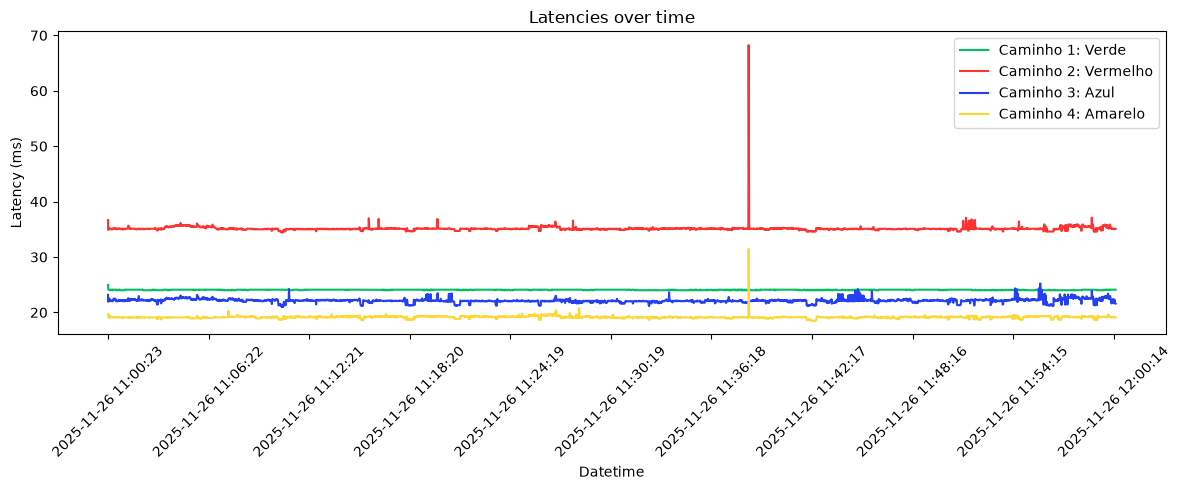

In [57]:
fig = plt.figure(figsize=(12, 5))

for pathId in pathIds:
    propriedades = rotas[pathId]
    nome = propriedades["nome"]
    cor = propriedades["cor"]

    plt.plot(datetimes, telemetry_values[:, pathId - 1], label=f'Caminho {pathId}: {nome}', color=cor, linewidth=1.5)

step = max(1, len(datetimes) // 10)  # mostra +- 10 datas no eixo
plt.xticks(datetimes[::step], rotation=45)

plt.legend()
plt.xlabel('Datetime')
plt.ylabel('Latency (ms)')
plt.title('Latencies over time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Banda disponível por caminho

Carrega o CSV consolidado de banda disponível por caminho (`banda_rotas_h1_h6.csv`), gerado a partir dos relatórios finais de cada rota (`banda_rota_h1<r>_h6<r>.txt`) pela função `consolidarBanda` em `prototipo/helpers/parser_banda.py`, do mesmo jeito que `latencia_rotas_h1_h6.csv` é gerado para a latência.

In [ ]:
historico_banda = pd.read_csv(f"{pasta_dataset}/{historico_banda_csv}")

banda_por_rota = historico_banda.iloc[:, 1:].values

banda_datetimes = historico_banda.iloc[:, 0].values
banda_datetimes_dt = pd.to_datetime(banda_datetimes)

print(banda_datetimes[:5], '\n')
print(banda_por_rota[:5])

FileNotFoundError: [Errno 2] No such file or directory: 'datasets/D4a/banda_rotas_h1_h6.csv'

In [58]:
fig = plt.figure(figsize=(12, 5))

for pathId in pathIds:
    propriedades = rotas[pathId]
    nome = propriedades["nome"]
    cor = propriedades["cor"]

    plt.plot(banda_datetimes, banda_por_rota[:, pathId - 1], label=f'Caminho {pathId}: {nome}', color=cor, linewidth=1.5)

step = max(1, len(banda_datetimes) // 10)  # mostra +- 10 datas no eixo
plt.xticks(banda_datetimes[::step], rotation=45)

# Desativa a notação de offset do matplotlib (ex.: "+9.999e1"), que em datasets com
# pouca variação (ex: D1, banda quase toda entre 99.99 e 100 Mbps) deixava o eixo Y
# confuso. Mostra os valores reais diretamente, mantendo o zoom automático nos dados.
plt.ticklabel_format(axis='y', style='plain', useOffset=False)

plt.legend()
plt.xlabel('Data/Hora')
plt.ylabel('Banda disponível (Mbps)')
plt.title('Banda disponível ao longo do tempo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'banda_datetimes' is not defined

<Figure size 1200x500 with 0 Axes>

## Interpolação da banda para os timestamps da latência

A banda e a latência são coletadas em processos separados, então seus timestamps não coincidem exatamente segundo a segundo. Para poder usar as duas em conjunto (ex.: como features do mesmo modelo), a banda disponível de cada caminho é interpolada nos timestamps exatos da latência (`datetimes_dt`), por interpolação temporal (`interpolate(method='time')`).

In [ ]:
banda_indexada = historico_banda.copy()
banda_indexada[banda_indexada.columns[0]] = pd.to_datetime(banda_indexada[banda_indexada.columns[0]])
banda_indexada = banda_indexada.set_index(banda_indexada.columns[0])

# Une os timestamps da banda com os da latência, interpola no tempo e depois
# mantém só os timestamps da latência, alinhando as duas séries
indice_uniao = banda_indexada.index.union(datetimes_dt)
banda_interpolada = (
    banda_indexada
    .reindex(indice_uniao)
    .sort_index()
    .interpolate(method='time', limit_direction='both')
    .reindex(datetimes_dt)
)

banda_por_rota_interp = banda_interpolada.values

print(f"Timestamps latência: {len(datetimes_dt)} | Timestamps banda original: {len(banda_datetimes_dt)}")
print(f"NaNs após interpolação: {np.isnan(banda_por_rota_interp).sum()}")
print(banda_por_rota_interp[:5])

In [19]:
rotulos_dataset = np.unique(y).tolist()
binaryClassification = len(rotulos_dataset) <= 2

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=1234,
                                                    shuffle=True, stratify=None)
print(f"Total de amostras: {len(y)}\n")

print(f"Classes únicas:\t\t{rotulos_dataset}")
print(f'Classes em y_train:\t{np.unique(y_train)}')
print(f'Classes em y_test:\t{np.unique(y_test)}')

print("\nDistribuição das classes:")
print(pd.Series(y).value_counts())

Total de amostras: 3599

Classes únicas:		[3, 4]
Classes em y_train:	[3 4]
Classes em y_test:	[3 4]

Distribuição das classes:
4    3597
3       2
Name: count, dtype: int64


In [20]:
print(len(y_train), len(y_test), len(y_train) + len(y_test))

2879 720 3599


In [21]:
resultados_cv = model_cross_validation(X_train, y_train, pipelines, folds=5, binary_classification=binaryClassification)

VALIDAÇÃO CRUZADA NO CONJUNTO DE TREINO (Stratified K-Fold)
LogisticRegression   | ERRO: This solver needs samples of at least 2 classes in the data, but the data contains only one class: np.int64(4)
KNeighbors           | Acc: 0.9997 ± 0.0007
SVC                  | ERRO: The number of classes has to be greater than one; got 1 class
DecisionTree         | Acc: 0.9997 ± 0.0007
ExtraTrees           | Acc: 0.9997 ± 0.0007
RandomForest         | Acc: 0.9997 ± 0.0007
GaussianNB           | Acc: 0.9997 ± 0.0007


In [ ]:
trained_pipelines = model_train(X_train, y_train, pipelines)

In [ ]:
test_results = evaluate_on_test(
    X_test, 
    y_test, 
    trained_pipelines, 
    rotulos_dataset, 
    binary_classification=binaryClassification, 
    result_path=f'{pasta_resultados}'
)

In [ ]:
compare_train_test_performance(resultados_cv, test_results, result_path=f'{pasta_resultados}')

Obter cortes dos dados em momentos diferentes, para analisar como o modelo generalizou os diferentes padrões da rede ao longo do tempo.

In [ ]:
historico_latencias_novo = pd.read_csv(f"nova_latencia/60min_streaming_simultaneo/latencia_rotas_h1_h6.csv")
rotulos_novo = np.loadtxt(f"nova_latencia/60min_streaming_simultaneo/labels_h1_h6.txt", comments='#', dtype=int)

different_datetimes = historico_latencias_novo.iloc[:, 0].values
different_datetimes_dt = pd.to_datetime(different_datetimes)

different_temporal_features = np.column_stack([
    different_datetimes_dt.hour,           # Hora do dia (0-23)
    different_datetimes_dt.minute,         # Minuto (0-59)
    different_datetimes_dt.second,         # Segundo (0-59)
    # datetimes_dt.dayofweek,    # Dia da semana (0=Segunda, 6=Domingo) - irrelevante para o conjunto de dados atual
    different_datetimes_dt.day,            # Dia do mês (1-31)
    different_datetimes_dt.month,          # Mês (1-12)
    different_datetimes_dt.year            # Ano
])

different_routes_latency = historico_latencias_novo.iloc[:, 1:].values

X_different = np.hstack([different_temporal_features, different_routes_latency])
y_different = rotulos_novo

pathIds = [1, 2, 3, 4]
n_classes = len(pathIds)
binaryClassification = n_classes <= 2


fig = plt.figure(figsize=(12, 5))

for i in range(n_classes):
    pathId = i + 1

    propriedades = rotas[pathId]
    nome = propriedades["nome"]
    cor = propriedades["cor"]

    plt.plot(different_datetimes, different_routes_latency[:, i], label=f'Caminho {pathId}: {nome}', color=cor, linewidth=1.5)

step = max(1, len(different_datetimes) // 10)  # mostra +- 10 datas no eixo
plt.xticks(different_datetimes[::step], rotation=45)

plt.legend()
plt.xlabel('Data/Hora')
plt.ylabel('Latência (ms)')
plt.title('Latência ao longo do tempo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

test_results = evaluate_on_test(X_different, y_different, trained_pipelines, pathIds, binary_classification=binaryClassification, result_path=f'testes/antiga2nova/4/results')

## Outros testes

In [ ]:
begin = 0
end = 800

fraction_datetimes = datetimes[begin:end]
fraction_datetimes_dt = datetimes_dt[begin:end]
fraction_temporal_features = temporal_features[begin:end]
fraction_routes_latency = historico_latencias[begin:end]
fraction_routes_label = rotas[begin:end]

X_fraction = np.hstack([fraction_temporal_features, fraction_routes_latency])
y_fraction = fraction_routes_label

pathIds = np.unique(y)
n_classes = len(historico_latencias[0])

fig = plt.figure(figsize=(12, 5))

for i in range(n_classes):
    pathId = i + 1

    propriedades = rotas[pathId]
    nome = propriedades["nome"]
    cor = propriedades["cor"]

    plt.plot(fraction_datetimes, fraction_routes_latency[:, i], label=f'Caminho {pathId}: {nome}', color=cor, linewidth=1.5)

step = max(1, len(fraction_datetimes) // 10)  # mostra +- 10 datas no eixo
plt.xticks(fraction_datetimes[::step], rotation=45)

plt.legend()
plt.xlabel('Data/Hora')
plt.ylabel('Latência (ms)')
plt.title('Latência ao longo do tempo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

test_results = evaluate_on_test(X_fraction, y_fraction, trained_pipelines, rotulos_dataset, binary_classification=binaryClassification, result_path=f'{pasta_resultados}')

In [ ]:
begin = 1001
end = 2001

fraction_datetimes = datetimes[begin:end]
fraction_datetimes_dt = datetimes_dt[begin:end]
fraction_temporal_features = temporal_features[begin:end]
fraction_routes_latency = routes_latency[begin:end]
fraction_routes_label = routes_label[begin:end]

X_fraction = np.hstack([fraction_temporal_features, fraction_routes_latency])
y_fraction = fraction_routes_label

print(np.unique(y_fraction))

pathIds = np.unique(y)
n_classes = len(routes_latency[0])

fig = plt.figure(figsize=(12, 5))

for i in range(n_classes):
    pathId = i + 1

    propriedades = routes[pathId]
    nome = propriedades["nome"]
    cor = propriedades["cor"]

    plt.plot(fraction_datetimes, fraction_routes_latency[:, i], label=f'Caminho {pathId}: {nome}', color=cor, linewidth=1.5)

step = max(1, len(fraction_datetimes) // 10)  # mostra +- 10 datas no eixo
plt.xticks(fraction_datetimes[::step], rotation=45)

plt.legend()
plt.xlabel('Data/Hora')
plt.ylabel('Latência (ms)')
plt.title('Latência ao longo do tempo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

test_results = evaluate_on_test(X_fraction, y_fraction, trained_pipelines, class_labels, binary_classification=binaryClassification, result_path=f'{data_path}/results')

In [2]:
def carregar_X_y(dataset, pasta_raiz='datasets', metrica='latencia'):
    """Carrega X (temporal_features + metrica por rota) e y (rotulos) de um dataset.

    metrica: 'latencia' -> usa latencia_rotas_h1_h6.csv (igual ao artigo)
             'banda'     -> usa banda_rotas_h1_h6.csv (proxy alternativo)
    y sempre vem de rotulos_h1_h6.txt (definido como argmin(latencia) no instante),
    igual nos dois casos — só X muda. Com banda, X e y são juntados por timestamp.
    """
    pasta = f"{pasta_raiz}/{dataset}"
    arquivo_csv = 'latencia_rotas_h1_h6.csv' if metrica == 'latencia' else 'banda_rotas_h1_h6.csv'

    historico = pd.read_csv(f"{pasta}/{arquivo_csv}")
    rotulos_ds = np.loadtxt(f"{pasta}/rotulos_h1_h6.txt", comments='#', dtype=int)

    # Os rótulos foram gerados linha a linha a partir de latencia_rotas_h1_h6.csv,
    # então só nesse CSV a correspondência por posição é a correta. A banda
    # começa a ser registrada 1 s antes da latência nos 8 datasets: juntar por
    # posição faria cada rótulo descrever o segundo seguinte ao da leitura de
    # banda ao lado dele (e em D2b, D4 e D4b, com o mesmo número de linhas, sem
    # nenhum aviso). Por isso, para outras métricas, o rótulo é associado ao
    # timestamp da latência e a junção com X é feita por timestamp.
    if metrica != 'latencia':
        instantes_rotulo = pd.to_datetime(
            pd.read_csv(f"{pasta}/latencia_rotas_h1_h6.csv", usecols=[0]).iloc[:, 0]
        )
        if len(instantes_rotulo) != len(rotulos_ds):
            raise ValueError(
                f"{dataset}: latencia_rotas_h1_h6.csv tem {len(instantes_rotulo)} linhas, "
                f"rotulos_h1_h6.txt tem {len(rotulos_ds)}"
            )
        coluna_tempo = historico.columns[0]
        historico[coluna_tempo] = pd.to_datetime(historico[coluna_tempo])
        rotulos_por_instante = pd.DataFrame({
            coluna_tempo: instantes_rotulo.values,
            '_rotulo': rotulos_ds,
        })
        historico = historico.merge(rotulos_por_instante, on=coluna_tempo, how='inner')
        rotulos_ds = historico.pop('_rotulo').to_numpy()

    valores_por_rota = historico.iloc[:, 1:].values
    datetimes_ds = pd.to_datetime(historico.iloc[:, 0].values)

    temporal = np.column_stack([
        datetimes_ds.hour,
        datetimes_ds.minute,
        datetimes_ds.second,
        datetimes_ds.day,
        datetimes_ds.month,
        datetimes_ds.year,
    ])

    X_ds = np.hstack([temporal, valores_por_rota])
    y_ds = rotulos_ds

    # Datasets podem ter tamanhos ligeiramente diferentes entre X e y (ex.: 1
    # instante a mais/menos por causa de bordas de alinhamento entre latência e
    # banda) — trunca ao menor tamanho comum em vez de falhar, avisando quando
    # a diferença for maior que um punhado de linhas (o que indicaria um
    # problema real de desalinhamento, não apenas borda)
    if len(X_ds) != len(y_ds):
        diferenca = abs(len(X_ds) - len(y_ds))
        if diferenca > 5:
            raise ValueError(
                f"{dataset}/{metrica}: X tem {len(X_ds)} linhas, y tem {len(y_ds)} "
                f"(diferença de {diferenca}, maior que o esperado por borda de alinhamento)"
            )
        print(f"[{dataset}/{metrica}] truncando {diferenca} linha(s) de borda: "
              f"X={len(X_ds)}, y={len(y_ds)}")
        tamanho_comum = min(len(X_ds), len(y_ds))
        X_ds = X_ds[:tamanho_comum]
        y_ds = y_ds[:tamanho_comum]

    # Algumas leituras de banda/latência têm falhas pontuais (NaN) — descarta a
    # linha inteira (todas as rotas daquele instante) em vez de imputar valores,
    # para não introduzir viés artificial nos poucos pontos afetados
    linhas_validas = ~np.isnan(X_ds).any(axis=1)
    if not linhas_validas.all():
        descartadas = (~linhas_validas).sum()
        print(f"[{dataset}/{metrica}] descartando {descartadas}/{len(X_ds)} linha(s) com NaN")
    X_ds = X_ds[linhas_validas]
    y_ds = y_ds[linhas_validas]

    return X_ds, y_ds


In [3]:
def experimento_cross_dataset(dataset_treino, datasets_teste, metrica, pasta_raiz='datasets',
                              random_state=1234):
    """Treina os 7 modelos clássicos em `dataset_treino` e testa em cada um de
    `datasets_teste`, usando `metrica` ('latencia' ou 'banda') como feature de rota.

    Retorna um DataFrame long: uma linha por (modelo, dataset_teste), com a
    acurácia — no mesmo espírito da Tabela 2 do artigo, mas parametrizado pela
    métrica usada como X.

    random_state fixa a semente dos modelos estocásticos. Sem ela o resultado
    muda a cada execução: com latência, a DecisionTree treinada em D1 empata
    entre separar pelas colunas temporais ou pelas de rota, e conforme a
    semente acerta ~0,88 ou ~0,007 em D2b/D3b.
    """
    X_treino, y_treino = carregar_X_y(dataset_treino, pasta_raiz, metrica)

    modelos_locais = {
        'LogisticRegression': LogisticRegression(max_iter=1000),
        'KNeighbors': KNeighborsClassifier(),
        'SVC': svm.SVC(probability=True, random_state=random_state),
        'DecisionTree': tree.DecisionTreeClassifier(random_state=random_state),
        'ExtraTrees': ExtraTreesClassifier(random_state=random_state),
        'RandomForest': RandomForestClassifier(random_state=random_state),
        'GaussianNB': GaussianNB(),
    }

    for modelo in modelos_locais.values():
        modelo.fit(X_treino, y_treino)

    linhas = []
    for dataset_teste in datasets_teste:
        X_teste, y_teste = carregar_X_y(dataset_teste, pasta_raiz, metrica)
        for nome_modelo, modelo in modelos_locais.items():
            try:
                y_pred = modelo.predict(X_teste)
                acc = accuracy_score(y_teste, y_pred)
            except Exception as e:
                acc = np.nan
                print(f"[{metrica}] {nome_modelo} em {dataset_teste}: ERRO {e}")
            linhas.append({
                'Metrica_X': metrica,
                'Treino': dataset_treino,
                'Teste': dataset_teste,
                'Modelo': nome_modelo,
                'Acuracia': acc,
            })

    return pd.DataFrame(linhas)


In [4]:
resultados_cross = []

cenarios_teste = {
    'latencias_originais': ['D2', 'D3', 'D4'],
    'latencias_modificadas': ['D2b', 'D3b', 'D4b'],
}

for nome_cenario, datasets_teste in cenarios_teste.items():
    for metrica in ['latencia', 'banda']:
        r = experimento_cross_dataset('D1', datasets_teste, metrica)
        r.insert(0, 'Cenario', nome_cenario)
        resultados_cross.append(r)

resultados_cross_df = pd.concat(resultados_cross, ignore_index=True)
resultados_cross_df


,Cenario,Metrica_X,Treino,Teste,Modelo,Acuracia
0,latencias_originais,latencia,D1,D2,LogisticRegression,0.777869
1,latencias_originais,latencia,D1,D2,KNeighbors,0.833607
2,latencias_originais,latencia,D1,D2,SVC,0.833607
3,latencias_originais,latencia,D1,D2,DecisionTree,0.930874
4,latencias_originais,latencia,D1,D2,ExtraTrees,0.853552
...,...,...,...,...,...,...
79,latencias_modificadas,banda,D1,D4b,SVC,0.002653
80,latencias_modificadas,banda,D1,D4b,DecisionTree,0.002653
81,latencias_modificadas,banda,D1,D4b,ExtraTrees,0.002653
82,latencias_modificadas,banda,D1,D4b,RandomForest,0.002653


In [5]:
# Resumo: acurácia média por (Cenário, Métrica_X, Modelo), agregando os datasets
# de teste de cada cenário — comparável à queda de desempenho relatada na Tabela 2
resumo_cross = (
    resultados_cross_df
    .groupby(['Cenario', 'Metrica_X', 'Modelo'])['Acuracia']
    .mean()
    .unstack('Metrica_X')
    .rename(columns={'latencia': 'Acc_media_com_latencia', 'banda': 'Acc_media_com_banda'})
    .sort_values(['Cenario', 'Acc_media_com_latencia'], ascending=[True, False])
)

resumo_cross['Diferenca_banda_menos_latencia'] = (
    resumo_cross['Acc_media_com_banda'] - resumo_cross['Acc_media_com_latencia']
)

resumo_cross.round(4)


Metrica_X                                 Acc_media_com_banda  \
Cenario               Modelo                                    
latencias_modificadas DecisionTree                     0.0018   
                      LogisticRegression               0.0014   
                      ExtraTrees                       0.0014   
                      RandomForest                     0.0014   
                      GaussianNB                       0.0014   
                      KNeighbors                       0.0014   
                      SVC                              0.0014   
latencias_originais   DecisionTree                     0.6202   
                      LogisticRegression               0.6203   
                      ExtraTrees                       0.6203   
                      RandomForest                     0.6203   
                      GaussianNB                       0.6203   
                      KNeighbors                       0.6203   
                      SVC                              0.6203   

Metrica_X                                 Acc_media_com_latencia  \
Cenario               Modelo                                       
latencias_modificadas DecisionTree                        0.8913   
                      LogisticRegression                  0.1366   
                      ExtraTrees                          0.0741   
                      RandomForest                        0.0473   
                      GaussianNB                          0.0014   
                      KNeighbors                          0.0014   
                      SVC                                 0.0014   
latencias_originais   DecisionTree                        0.9242   
                      LogisticRegression                  0.7538   
                      ExtraTrees                          0.7409   
                      RandomForest                        0.6999   
                      GaussianNB                          0.6203   
                      KNeighbors                          0.6203   
                      SVC                                 0.6203   

Metrica_X                                 Diferenca_banda_menos_latencia  
Cenario               Modelo                                              
latencias_modificadas DecisionTree                               -0.8895  
                      LogisticRegression                         -0.1351  
                      ExtraTrees                                 -0.0727  
                      RandomForest                               -0.0459  
                      GaussianNB                                  0.0000  
                      KNeighbors                                  0.0000  
                      SVC                                         0.0000  
latencias_originais   DecisionTree                               -0.3039  
                      LogisticRegression                         -0.1335  
                      ExtraTrees                                 -0.1206  
                      RandomForest                               -0.0797  
                      GaussianNB                                 -0.0000  
                      KNeighbors                                 -0.0000  
                      SVC                                        -0.0000

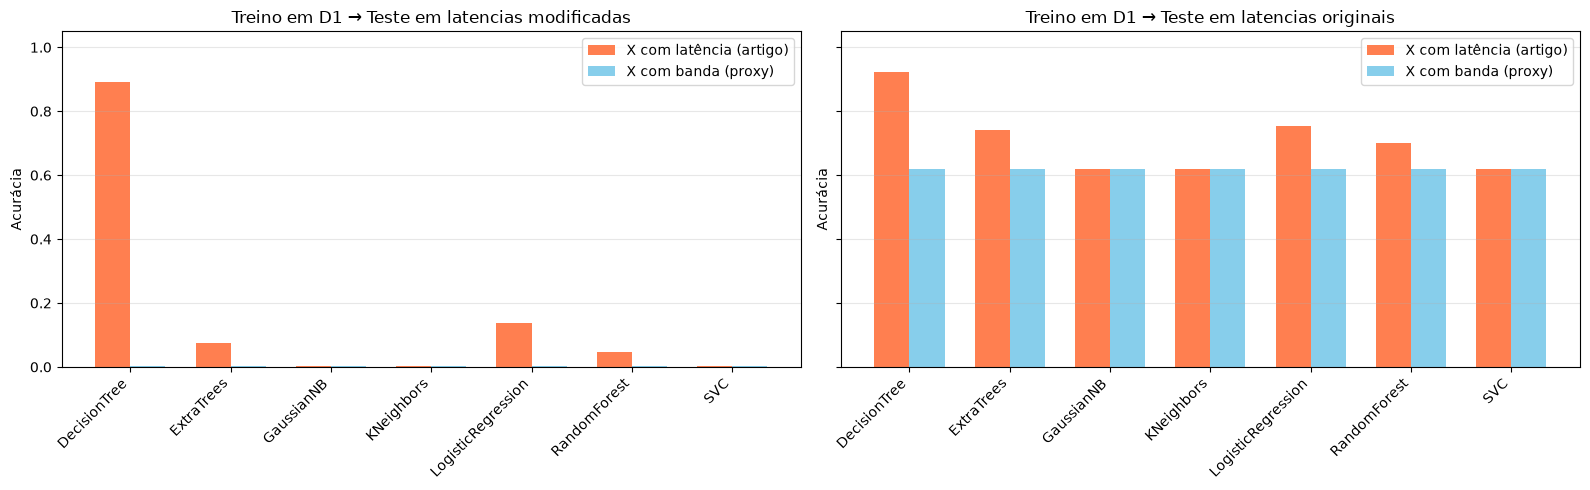

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

for ax, (nome_cenario, dados) in zip(axes, resultados_cross_df.groupby('Cenario')):
    pivot = dados.groupby(['Modelo', 'Metrica_X'])['Acuracia'].mean().unstack('Metrica_X')
    pivot = pivot.reindex(columns=['latencia', 'banda'])

    x = np.arange(len(pivot))
    width = 0.35

    ax.bar(x - width/2, pivot['latencia'], width, label='X com latência (artigo)', color='coral')
    ax.bar(x + width/2, pivot['banda'], width, label='X com banda (proxy)', color='skyblue')

    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index, rotation=45, ha='right')
    ax.set_title(f'Treino em D1 → Teste em {nome_cenario.replace("_", " ")}')
    ax.set_ylabel('Acurácia')
    ax.set_ylim([0, 1.05])
    ax.grid(axis='y', alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig('resultados_am/generalizacao_latencia_vs_banda.png', dpi=300, bbox_inches='tight')
plt.show()


## Feature importance do experimento de generalização

Por que os modelos treinados em D1 colapsam ao testar em D2b/D3b/D4b (latências
modificadas)? Uma forma de investigar é olhar **quais features o RandomForest treinado
em D1 considerou mais importantes**, tanto por MDI (impureza média, calculada só com
dados de treino) quanto por **permutation importance calculada no dataset de teste**
(que reflete o que realmente contribui para acerto fora da distribuição de treino).

Colunas de `X`: `[hora, minuto, segundo, dia, mês, ano, rota_1, rota_2, rota_3, rota_4]`
(as 4 últimas são a métrica escolhida — latência ou banda — por caminho).

Comparar a MDI (calculada em D1) com a permutation importance calculada em D2b mostra
diretamente se o modelo está usando as colunas de rota (o que seria esperado/desejável)
ou se ele apenas decorou os padrões temporais de D1, que deixam de fazer sentido quando
a topologia de latências muda.


In [7]:
from sklearn.inspection import permutation_importance

NOMES_COLUNAS_X = ['hora', 'minuto', 'segundo', 'dia', 'mes', 'ano',
                    'rota_1', 'rota_2', 'rota_3', 'rota_4']


def importancia_cross_dataset(dataset_treino, dataset_teste, metrica, pasta_raiz='datasets',
                               random_state=42):
    """Treina um RandomForest em `dataset_treino` e retorna MDI (do treino) +
    permutation importance (avaliada em `dataset_teste`), lado a lado.

    Isso evidencia se o modelo se apoia nas colunas de rota (generalizável) ou
    nas colunas temporais (memorização do horário/dia de coleta de D1, que não
    tem nenhuma relação causal com qual rota é mais rápida).
    """
    X_treino, y_treino = carregar_X_y(dataset_treino, pasta_raiz, metrica)
    X_teste, y_teste = carregar_X_y(dataset_teste, pasta_raiz, metrica)

    modelo = RandomForestClassifier(random_state=random_state)
    modelo.fit(X_treino, y_treino)

    mdi = pd.Series(modelo.feature_importances_, index=NOMES_COLUNAS_X, name='MDI_treino')

    perm = permutation_importance(
        modelo, X_teste, y_teste, n_repeats=10, random_state=random_state, n_jobs=-1
    )
    permutacao = pd.Series(perm.importances_mean, index=NOMES_COLUNAS_X, name='Permutacao_teste')

    tabela = pd.concat([mdi, permutacao], axis=1)
    tabela['Metrica_X'] = metrica
    tabela['Treino'] = dataset_treino
    tabela['Teste'] = dataset_teste
    tabela['Acuracia_teste'] = accuracy_score(y_teste, modelo.predict(X_teste))

    return tabela.reset_index().rename(columns={'index': 'Feature'})


In [8]:
casos_importancia = [
    ('D1', 'D2', 'latencia'),
    ('D1', 'D2b', 'latencia'),
    ('D1', 'D2', 'banda'),
    ('D1', 'D2b', 'banda'),
]

tabelas_importancia = [
    importancia_cross_dataset(treino, teste, metrica)
    for treino, teste, metrica in casos_importancia
]

importancia_df = pd.concat(tabelas_importancia, ignore_index=True)
importancia_df.round(4)


,Feature,MDI_treino,Permutacao_teste,Metrica_X,Treino,Teste,Acuracia_teste
0,hora,0.0000,0.0000,latencia,D1,D2,0.8481
1,minuto,0.0056,-0.0010,latencia,D1,D2,0.8481
2,segundo,0.0008,-0.0022,latencia,D1,D2,0.8481
3,dia,0.0000,0.0000,latencia,D1,D2,0.8481
4,mes,0.0000,0.0000,latencia,D1,D2,0.8481
5,ano,0.0000,0.0000,latencia,D1,D2,0.8481
6,rota_1,0.0328,-0.0004,latencia,D1,D2,0.8481
7,rota_2,0.5003,0.0053,latencia,D1,D2,0.8481
8,rota_3,0.0001,-0.0008,latencia,D1,D2,0.8481
9,rota_4,0.4604,0.0215,latencia,D1,D2,0.8481


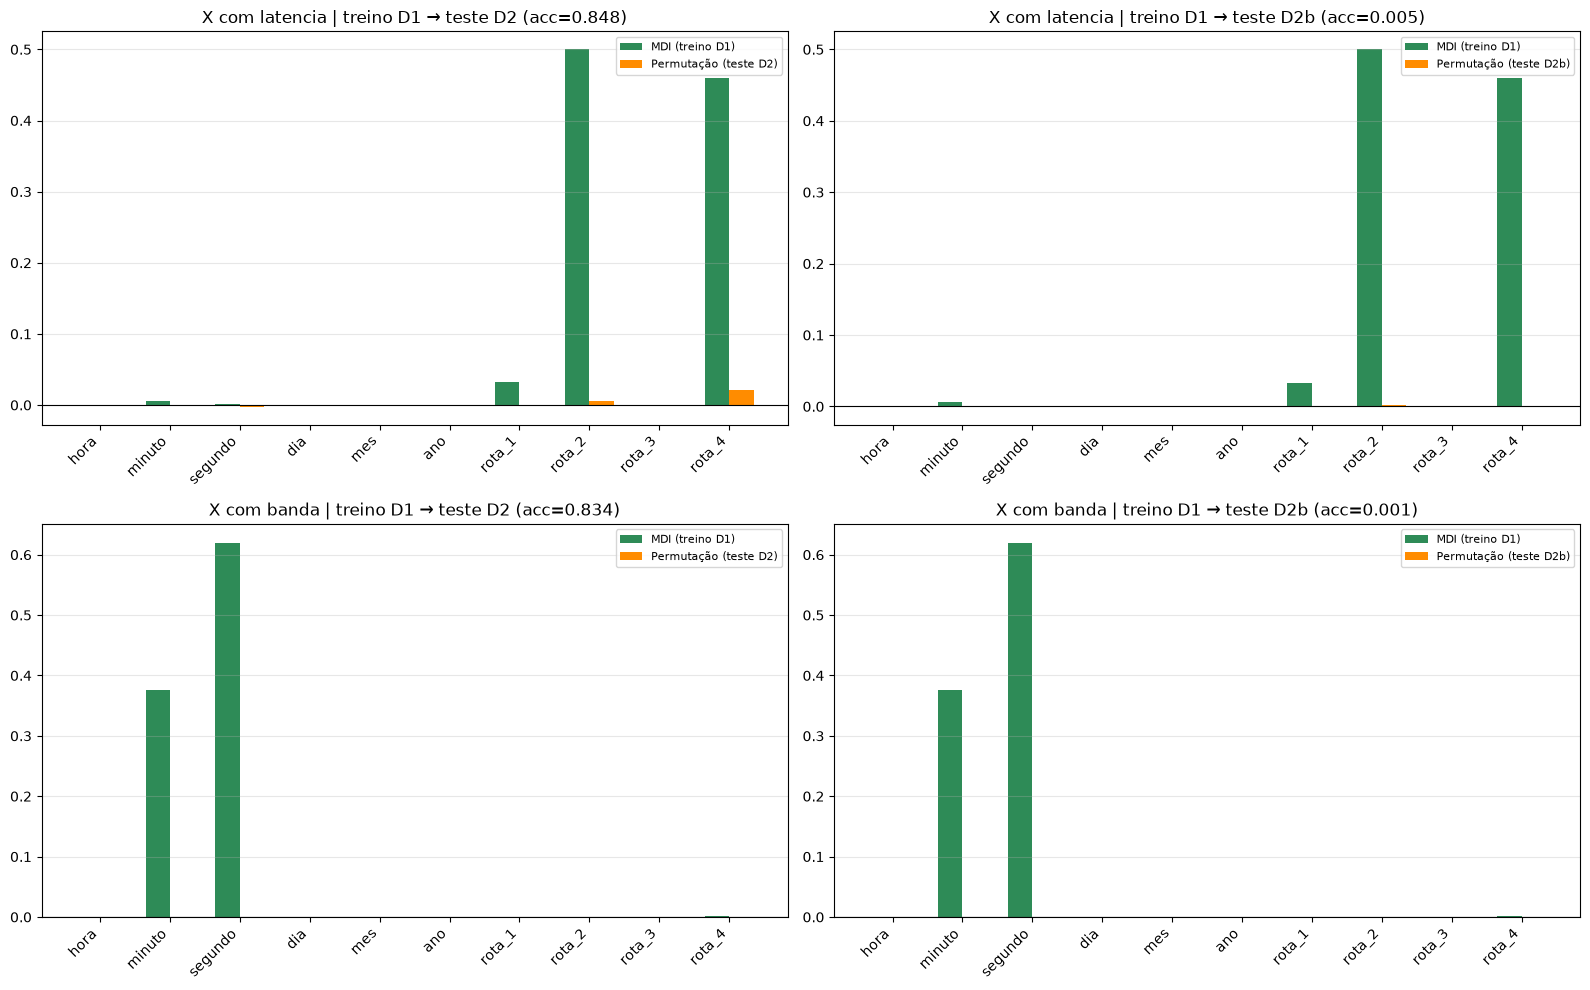

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (treino, teste, metrica) in zip(axes.ravel(), casos_importancia):
    subset = importancia_df[
        (importancia_df.Treino == treino) &
        (importancia_df.Teste == teste) &
        (importancia_df.Metrica_X == metrica)
    ].set_index('Feature')

    x = np.arange(len(subset))
    width = 0.35

    ax.bar(x - width/2, subset['MDI_treino'], width, label=f'MDI (treino {treino})', color='seagreen')
    ax.bar(x + width/2, subset['Permutacao_teste'], width, label=f'Permutação (teste {teste})', color='darkorange')

    acc = subset['Acuracia_teste'].iloc[0]
    ax.set_xticks(x)
    ax.set_xticklabels(subset.index, rotation=45, ha='right')
    ax.set_title(f'X com {metrica} | treino {treino} → teste {teste} (acc={acc:.3f})')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('resultados_am/importancia_generalizacao_latencia_vs_banda.png', dpi=300, bbox_inches='tight')
plt.show()


In [14]:
historico_latencia = pd.read_csv(f"{pasta_dataset}/{arquivo_latencia_csv}")

faltantes_latencia = historico_latencia.iloc[:, 1:].isna().sum().sum()
if faltantes_latencia:
    print(f"Aviso: {faltantes_latencia} valores de latência faltantes — preenchidos por interpolação linear.")
    historico_latencia.iloc[:, 1:] = historico_latencia.iloc[:, 1:].interpolate(method='linear', limit_direction='both')

rotulos_lat = np.loadtxt(f"{pasta_dataset}/{arquivo_rotulos_latencia}", comments='#', dtype=int)

latencia_por_rota = historico_latencia.iloc[:, 1:].values

datetimes_lat = historico_latencia.iloc[:, 0].values
datetimes_lat_dt = pd.to_datetime(datetimes_lat)

temporal_features_lat = np.column_stack([
    datetimes_lat_dt.hour,
    datetimes_lat_dt.minute,
    datetimes_lat_dt.second,
    datetimes_lat_dt.day,
    datetimes_lat_dt.month,
    datetimes_lat_dt.year
])

print(datetimes_lat[:5], '\n')
print(temporal_features_lat[:5], '\n')
print(latencia_por_rota[:5], '\n')
print(rotulos_lat[:5])


<StringArray>
['2025-11-26 09:50:17', '2025-11-26 09:50:18', '2025-11-26 09:50:19',
 '2025-11-26 09:50:20', '2025-11-26 09:50:21']
Length: 5, dtype: str 

[[   9   50   17   26   11 2025]
 [   9   50   18   26   11 2025]
 [   9   50   19   26   11 2025]
 [   9   50   20   26   11 2025]
 [   9   50   21   26   11 2025]] 

[[24.96291004 36.23178991 22.43566547 19.34241361]
 [24.00283623 34.79592894 21.79664958 18.79260389]
 [24.         35.08746972 22.18643918 19.08827817]
 [24.         35.1        22.29659758 19.1       ]
 [24.         35.00419371 22.20340329 19.00413029]] 

[4 4 4 4 4]


In [15]:
X_lat = np.hstack([temporal_features_lat, latencia_por_rota])
y_lat = rotulos_lat

pathIds_lat = list(range(1, latencia_por_rota.shape[1] + 1))
n_classes_lat = len(pathIds_lat)

print(f"Shape: {X_lat.shape}")
print(pathIds_lat, n_classes_lat)


Shape: (3660, 10)
[1, 2, 3, 4] 4


## Análise do dataset (latência)

In [16]:
classes_lat = {}
for pathId in pathIds_lat:
    nome = rotas[pathId]["nome"]
    classes_lat[nome] = pathId

print(classes_lat)


{'Verde': 1, 'Vermelho': 2, 'Azul': 3, 'Amarelo': 4}


In [17]:
d_lat = {  'rotulos': pd.Series(rotulos_lat),
	   'latencias': pd.Series(latencia_por_rota.tolist()) }

df_lat = pd.DataFrame(d_lat)

print("Numero de linhas: ", df_lat.shape[0])
print("Qtd Rótulos: ", rotulos_lat.shape)
print("Qtd Latências: ", df_lat['latencias'].shape)

print(df_lat['rotulos'].value_counts())


Numero de linhas:  3660
Qtd Rótulos:  (3660,)
Qtd Latências:  (3660,)
rotulos
4    3051
3     400
1     196
2      13
Name: count, dtype: int64


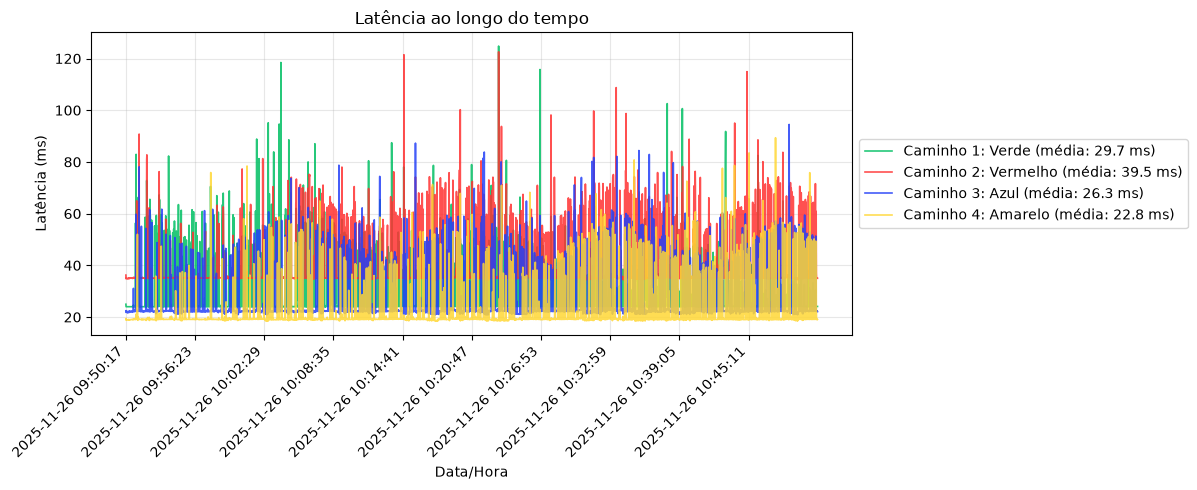

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))

for pathId in pathIds_lat:
    propriedades = rotas[pathId]
    nome = propriedades["nome"]
    cor = propriedades["cor"]

    media = np.nanmean(latencia_por_rota[:, pathId - 1])
    ax.plot(
        datetimes_lat, latencia_por_rota[:, pathId - 1],
        label=f'Caminho {pathId}: {nome} (média: {media:.1f} ms)',
        color=cor, linewidth=1.2, alpha=0.85
    )

step = max(1, len(datetimes_lat) // 10)  # mostra +- 10 datas no eixo
ax.set_xticks(datetimes_lat[::step])
ax.set_xticklabels(datetimes_lat[::step], rotation=45, ha='right')

ax.grid(True, alpha=0.3)
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
ax.set_xlabel('Data/Hora')
ax.set_ylabel('Latência (ms)')
ax.set_title('Latência ao longo do tempo')
plt.tight_layout()
plt.show()


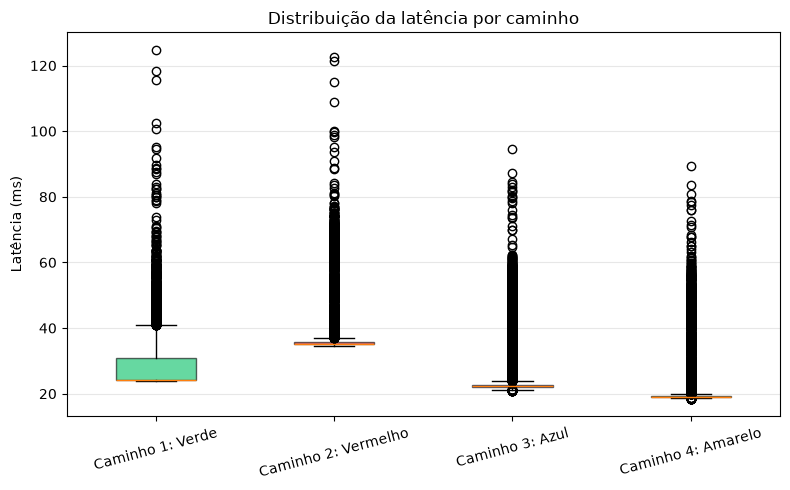

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))

dados_boxplot_lat = [latencia_por_rota[:, pathId - 1] for pathId in pathIds_lat]
cores_lat = [rotas[pathId]['cor'] for pathId in pathIds_lat]
labels_boxplot_lat = [f"Caminho {pathId}: {rotas[pathId]['nome']}" for pathId in pathIds_lat]

caixas = ax.boxplot(dados_boxplot_lat, tick_labels=labels_boxplot_lat, patch_artist=True)
for caixa, cor in zip(caixas['boxes'], cores_lat):
    caixa.set_facecolor(cor)
    caixa.set_alpha(0.6)

ax.set_ylabel('Latência (ms)')
ax.set_title('Distribuição da latência por caminho')
ax.grid(True, axis='y', alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## Pipeline (latência)

1.   Separação dos dados entre treino e teste (80% : 20%)
2.   Validação cruzada dos modelos com o conjunto de treino, com estratificação
3.   Treinamento dos modelos com o conjunto de treino
4.   Teste dos modelos com o conjunto de teste
5.   Comparação de desempenho entre treino (validação cruzada) e teste

In [20]:
pasta_resultados_lat = f"{RESULTS_FOLDER}/CenarioLatencia_{DATASET}"
os.makedirs(pasta_resultados_lat, exist_ok=True)

rotulos_dataset_lat = np.unique(y_lat).tolist()
binaryClassification_lat = len(rotulos_dataset_lat) <= 2

X_train_lat, X_test_lat, y_train_lat, y_test_lat = train_test_split(
    X_lat, y_lat,
    test_size=0.2,
    random_state=1234,
    shuffle=True,
    stratify=None
)

print(f"Total de amostras: {len(y_lat)}\n")
print(f"Classes únicas:\t\t{rotulos_dataset_lat}")
print(f"Classes em y_train_lat:\t{np.unique(y_train_lat)}")
print(f"Classes em y_test_lat:\t{np.unique(y_test_lat)}")
print("\nDistribuição das classes:")
print(pd.Series(y_lat).value_counts())


Total de amostras: 3660

Classes únicas:		[1, 2, 3, 4]
Classes em y_train_lat:	[1 2 3 4]
Classes em y_test_lat:	[1 2 3 4]

Distribuição das classes:
4    3051
3     400
1     196
2      13
Name: count, dtype: int64


VALIDAÇÃO CRUZADA NO CONJUNTO DE TREINO (Stratified K-Fold)


LogisticRegression   | Acc: 0.9959 ± 0.0017


KNeighbors           | Acc: 0.9553 ± 0.0096


SVC                  | Acc: 0.8327 ± 0.0001
DecisionTree         | Acc: 0.9891 ± 0.0038


ExtraTrees           | Acc: 0.9860 ± 0.0058


RandomForest         | Acc: 0.9898 ± 0.0032
GaussianNB           | Acc: 0.9255 ± 0.0153


AVALIAÇÃO NO CONJUNTO DE TESTE (DADOS NÃO VISTOS)


────────────────────────────────────────────────────────────────────────────────
Modelo: LogisticRegression
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.98      1.00      0.99        44
           2       1.00      0.50      0.67         2
           3       1.00      1.00      1.00        73
           4       1.00      1.00      1.00       613

    accuracy                           1.00       732
   macro avg       0.99      0.88      0.91       732
weighted avg       1.00      1.00      1.00       732


Matriz de Confusão:
[[ 44   0   0   0]
 [  1   1   0   0]
 [  0   0  73   0]
 [  0   0   0 613]]


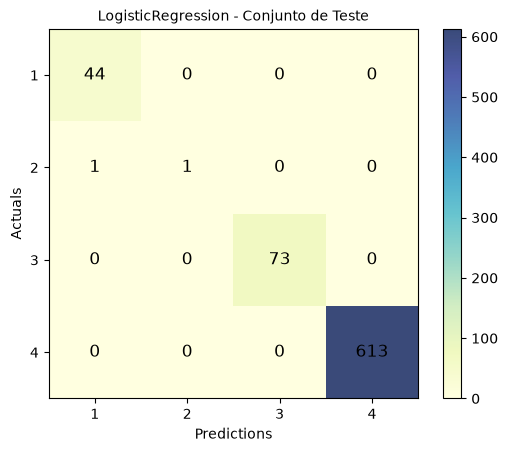


────────────────────────────────────────────────────────────────────────────────
Modelo: KNeighbors
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.94      0.75      0.84        44
           2       0.00      0.00      0.00         2
           3       0.92      0.79      0.85        73
           4       0.97      1.00      0.98       613

    accuracy                           0.96       732
   macro avg       0.71      0.64      0.67       732
weighted avg       0.96      0.96      0.96       732


Matriz de Confusão:
[[ 33   0   5   6]
 [  2   0   0   0]
 [  0   0  58  15]
 [  0   0   0 613]]


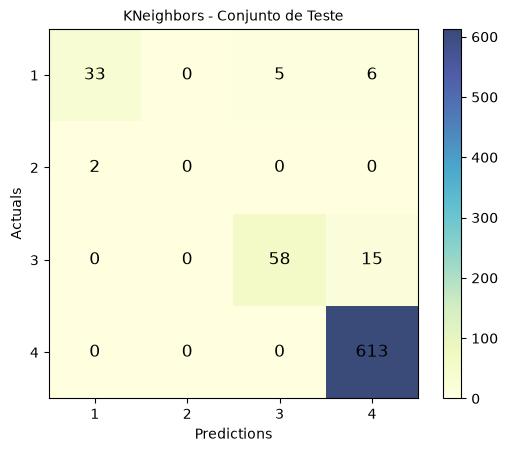


────────────────────────────────────────────────────────────────────────────────
Modelo: SVC
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        44
           2       0.00      0.00      0.00         2
           3       0.00      0.00      0.00        73
           4       0.84      1.00      0.91       613

    accuracy                           0.84       732
   macro avg       0.21      0.25      0.23       732
weighted avg       0.70      0.84      0.76       732


Matriz de Confusão:
[[  0   0   0  44]
 [  0   0   0   2]
 [  0   0   0  73]
 [  0   0   0 613]]


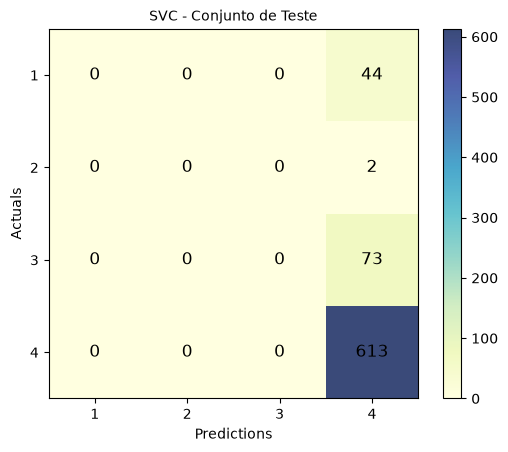


────────────────────────────────────────────────────────────────────────────────
Modelo: DecisionTree
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       1.00      0.95      0.98        44
           2       1.00      1.00      1.00         2
           3       0.97      0.97      0.97        73
           4       0.99      1.00      1.00       613

    accuracy                           0.99       732
   macro avg       0.99      0.98      0.99       732
weighted avg       0.99      0.99      0.99       732


Matriz de Confusão:
[[ 42   0   0   2]
 [  0   2   0   0]
 [  0   0  71   2]
 [  0   0   2 611]]


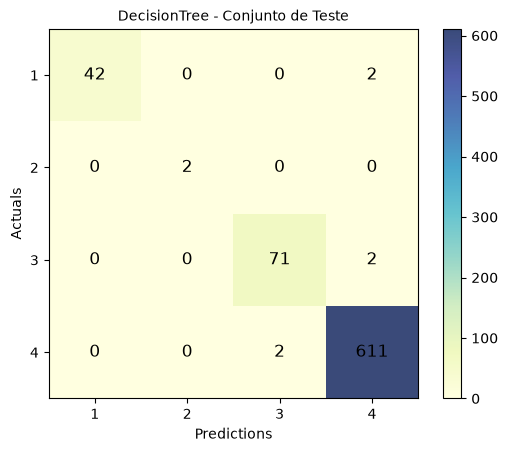


────────────────────────────────────────────────────────────────────────────────
Modelo: ExtraTrees
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.97      0.89      0.93        44
           2       1.00      0.50      0.67         2
           3       0.95      0.97      0.96        73
           4       0.99      1.00      1.00       613

    accuracy                           0.99       732
   macro avg       0.98      0.84      0.89       732
weighted avg       0.99      0.99      0.99       732


Matriz de Confusão:
[[ 39   0   3   2]
 [  1   1   0   0]
 [  0   0  71   2]
 [  0   0   1 612]]


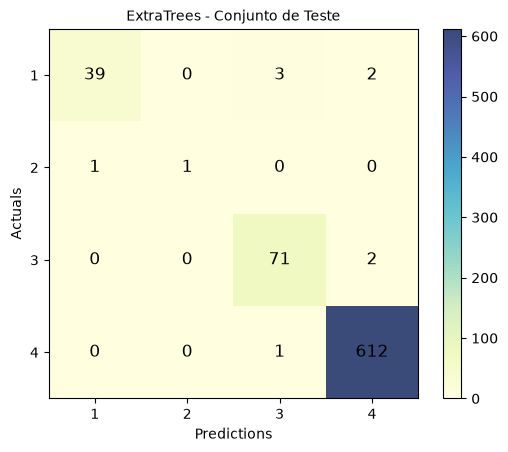


────────────────────────────────────────────────────────────────────────────────
Modelo: RandomForest
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.98      0.98      0.98        44
           2       1.00      0.50      0.67         2
           3       0.95      0.99      0.97        73
           4       1.00      1.00      1.00       613

    accuracy                           0.99       732
   macro avg       0.98      0.86      0.90       732
weighted avg       0.99      0.99      0.99       732


Matriz de Confusão:
[[ 43   0   1   0]
 [  1   1   0   0]
 [  0   0  72   1]
 [  0   0   3 610]]


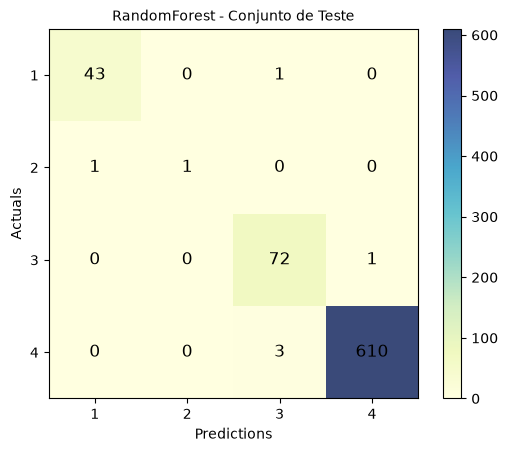


────────────────────────────────────────────────────────────────────────────────
Modelo: GaussianNB
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.69      0.45      0.55        44
           2       0.07      1.00      0.12         2
           3       0.79      0.93      0.86        73
           4       1.00      0.96      0.98       613

    accuracy                           0.92       732
   macro avg       0.64      0.84      0.63       732
weighted avg       0.96      0.92      0.94       732


Matriz de Confusão:
[[ 20  21   3   0]
 [  0   2   0   0]
 [  0   4  68   1]
 [  9   3  15 586]]


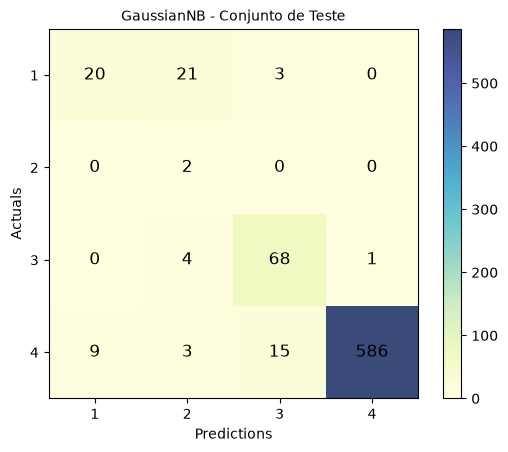


RELATÓRIO RESUMIDO - CONJUNTO DE TESTE
LogisticRegression   | Acc: 0.9986
KNeighbors           | Acc: 0.9617
SVC                  | Acc: 0.8374
DecisionTree         | Acc: 0.9918
ExtraTrees           | Acc: 0.9877
RandomForest         | Acc: 0.9918
GaussianNB           | Acc: 0.9235


COMPARAÇÃO: VALIDAÇÃO CRUZADA vs TESTE

             Model CV_Accuracy Test_Accuracy
LogisticRegression      0.9959        0.9986
        KNeighbors      0.9553        0.9617
               SVC      0.8327        0.8374
      DecisionTree      0.9891        0.9918
        ExtraTrees      0.9860        0.9877
      RandomForest      0.9898        0.9918
        GaussianNB      0.9255        0.9235


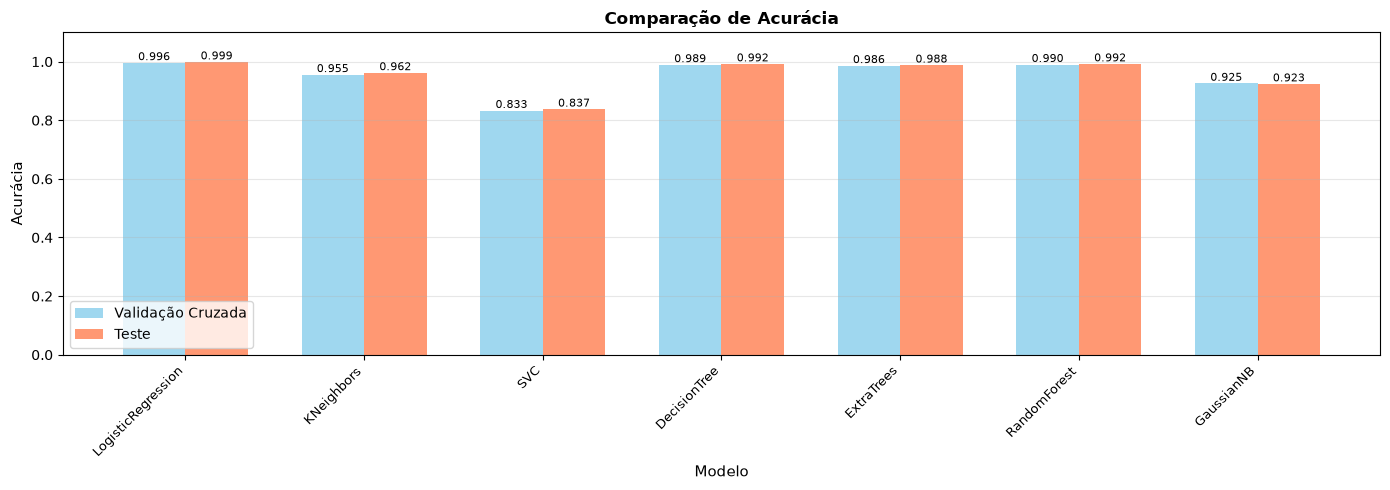


ANÁLISE DE OVERFITTING
LogisticRegression   | CV: 0.9959 | Test: 0.9986 | Diff: -0.0027
KNeighbors           | CV: 0.9553 | Test: 0.9617 | Diff: -0.0064
SVC                  | CV: 0.8327 | Test: 0.8374 | Diff: -0.0047
DecisionTree         | CV: 0.9891 | Test: 0.9918 | Diff: -0.0027
ExtraTrees           | CV: 0.9860 | Test: 0.9877 | Diff: -0.0017
RandomForest         | CV: 0.9898 | Test: 0.9918 | Diff: -0.0020
GaussianNB           | CV: 0.9255 | Test: 0.9235 | Diff: +0.0020


,Model,CV_Accuracy,Test_Accuracy
0,LogisticRegression,0.9959,0.9986
1,KNeighbors,0.9553,0.9617
2,SVC,0.8327,0.8374
3,DecisionTree,0.9891,0.9918
4,ExtraTrees,0.9860,0.9877
5,RandomForest,0.9898,0.9918
6,GaussianNB,0.9255,0.9235


In [21]:
resultados_cv_lat = model_cross_validation(X_train_lat, y_train_lat, pipelines, folds=5, binary_classification=binaryClassification_lat)
trained_pipelines_lat = model_train(X_train_lat, y_train_lat, pipelines, model_dir=f'{pasta_resultados_lat}/models')
test_results_lat = evaluate_on_test(
    X_test_lat,
    y_test_lat,
    trained_pipelines_lat,
    rotulos_dataset_lat,
    binary_classification=binaryClassification_lat,
    result_path=pasta_resultados_lat
)
compare_train_test_performance(resultados_cv_lat, test_results_lat, result_path=pasta_resultados_lat)


In [22]:
historico_banda = pd.read_csv(f"{pasta_dataset}/{arquivo_banda_csv}")

# Algumas leituras de banda podem faltar pontualmente para uma rota (coleta
# feita em processo separado da latência); preenche por interpolação linear
# para não propagar NaN para os gráficos e para o treinamento dos modelos.
faltantes_banda = historico_banda.iloc[:, 1:].isna().sum().sum()
if faltantes_banda:
    print(f"Aviso: {faltantes_banda} valores de banda faltantes — preenchidos por interpolação linear.")
    historico_banda.iloc[:, 1:] = historico_banda.iloc[:, 1:].interpolate(method='linear', limit_direction='both')

rotulos_banda = np.loadtxt(f"{pasta_dataset}/{arquivo_rotulos_banda}", comments='#', dtype=int)

banda_por_rota = historico_banda.iloc[:, 1:].values

datetimes_banda = historico_banda.iloc[:, 0].values
datetimes_banda_dt = pd.to_datetime(datetimes_banda)

temporal_features_banda = np.column_stack([
    datetimes_banda_dt.hour,
    datetimes_banda_dt.minute,
    datetimes_banda_dt.second,
    datetimes_banda_dt.day,
    datetimes_banda_dt.month,
    datetimes_banda_dt.year
])

print(datetimes_banda[:5], '\n')
print(temporal_features_banda[:5], '\n')
print(banda_por_rota[:5], '\n')
print(rotulos_banda[:5])


Aviso: 2 valores de banda faltantes — preenchidos por interpolação linear.
<StringArray>
['2025-11-26 09:50:16', '2025-11-26 09:50:17', '2025-11-26 09:50:18',
 '2025-11-26 09:50:19', '2025-11-26 09:50:20']
Length: 5, dtype: str 

[[   9   50   16   26   11 2025]
 [   9   50   17   26   11 2025]
 [   9   50   18   26   11 2025]
 [   9   50   19   26   11 2025]
 [   9   50   20   26   11 2025]] 

[[100.         100.         100.         100.        ]
 [ 99.99412537  99.99487305  99.99487305  99.99412537]
 [ 99.99700928  99.99700928  99.99700928  99.99700928]
 [ 99.99700928  99.99700928  99.99700928  99.99700928]
 [ 99.99700928  99.99700928  99.99700928  99.99700928]] 

[1 2 1 1 1]


In [23]:
X_banda = np.hstack([temporal_features_banda, banda_por_rota])
y_banda = rotulos_banda

pathIds_banda = list(range(1, banda_por_rota.shape[1] + 1))
n_classes_banda = len(pathIds_banda)

print(f"Shape: {X_banda.shape}")
print(pathIds_banda, n_classes_banda)


Shape: (3659, 10)
[1, 2, 3, 4] 4


## Análise do dataset (banda)

In [24]:
classes_banda = {}
for pathId in pathIds_banda:
    nome = rotas[pathId]["nome"]
    classes_banda[nome] = pathId

print(classes_banda)


{'Verde': 1, 'Vermelho': 2, 'Azul': 3, 'Amarelo': 4}


In [25]:
d_banda = {  'rotulos': pd.Series(rotulos_banda),
	   'banda': pd.Series(banda_por_rota.tolist()) }

df_banda = pd.DataFrame(d_banda)

print("Numero de linhas: ", df_banda.shape[0])
print("Qtd Rótulos: ", rotulos_banda.shape)
print("Qtd Bandas: ", df_banda['banda'].shape)

print(df_banda['rotulos'].value_counts())


Numero de linhas:  3659
Qtd Rótulos:  (3659,)
Qtd Bandas:  (3659,)
rotulos
1    2095
3    1157
2     383
4      24
Name: count, dtype: int64


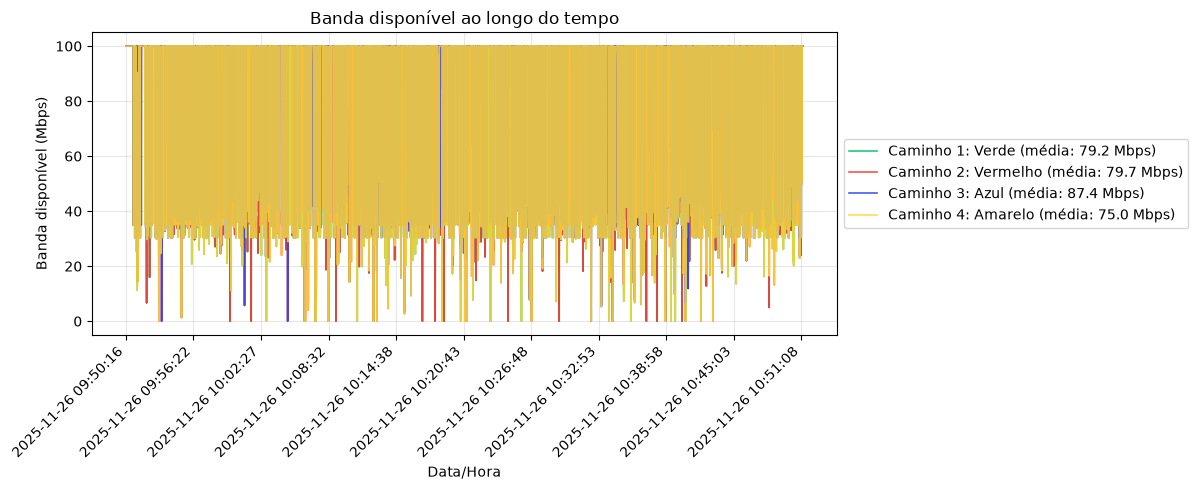

In [26]:
fig, ax = plt.subplots(figsize=(12, 5))

for pathId in pathIds_banda:
    propriedades = rotas[pathId]
    nome = propriedades["nome"]
    cor = propriedades["cor"]

    media = np.nanmean(banda_por_rota[:, pathId - 1])
    ax.plot(
        datetimes_banda, banda_por_rota[:, pathId - 1],
        label=f'Caminho {pathId}: {nome} (média: {media:.1f} Mbps)',
        color=cor, linewidth=1.2, alpha=0.85
    )

step = max(1, len(datetimes_banda) // 10)  # mostra +- 10 datas no eixo
ax.set_xticks(datetimes_banda[::step])
ax.set_xticklabels(datetimes_banda[::step], rotation=45, ha='right')

# Desativa a notação de offset do matplotlib (ex.: "+9.999e1"), que em datasets com
# pouca variação (ex: D1, banda quase toda entre 99.99 e 100 Mbps) deixava o eixo Y
# confuso. Mostra os valores reais diretamente, mantendo o zoom automático nos dados.
ax.ticklabel_format(axis='y', style='plain', useOffset=False)

banda_min, banda_max = np.nanmin(banda_por_rota), np.nanmax(banda_por_rota)
margem = max(1.0, (banda_max - banda_min) * 0.05)
ax.set_ylim(banda_min - margem, banda_max + margem)
ax.grid(True, alpha=0.3)

ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
ax.set_xlabel('Data/Hora')
ax.set_ylabel('Banda disponível (Mbps)')
ax.set_title('Banda disponível ao longo do tempo')
plt.tight_layout()
plt.show()


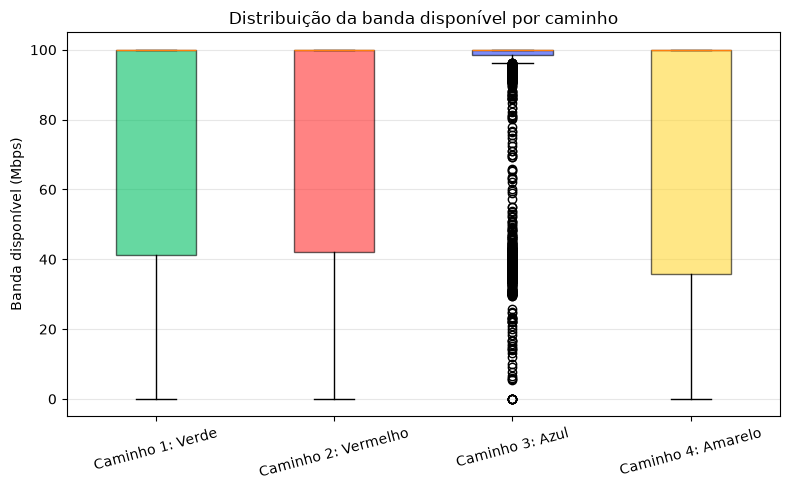

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))

dados_boxplot_banda = [banda_por_rota[:, pathId - 1] for pathId in pathIds_banda]
cores_banda = [rotas[pathId]['cor'] for pathId in pathIds_banda]
labels_boxplot_banda = [f"Caminho {pathId}: {rotas[pathId]['nome']}" for pathId in pathIds_banda]

caixas = ax.boxplot(dados_boxplot_banda, tick_labels=labels_boxplot_banda, patch_artist=True)
for caixa, cor in zip(caixas['boxes'], cores_banda):
    caixa.set_facecolor(cor)
    caixa.set_alpha(0.6)

ax.set_ylabel('Banda disponível (Mbps)')
ax.set_title('Distribuição da banda disponível por caminho')
ax.grid(True, axis='y', alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## Pipeline (banda)

In [28]:
pasta_resultados_banda = f"{RESULTS_FOLDER}/CenarioBanda_{DATASET}"
os.makedirs(pasta_resultados_banda, exist_ok=True)

rotulos_dataset_banda = np.unique(y_banda).tolist()
binaryClassification_banda = len(rotulos_dataset_banda) <= 2

X_train_banda, X_test_banda, y_train_banda, y_test_banda = train_test_split(
    X_banda, y_banda,
    test_size=0.2,
    random_state=1234,
    shuffle=True,
    stratify=None
)

print(f"Total de amostras: {len(y_banda)}\n")
print(f"Classes únicas:\t\t{rotulos_dataset_banda}")
print(f"Classes em y_train_banda:\t{np.unique(y_train_banda)}")
print(f"Classes em y_test_banda:\t{np.unique(y_test_banda)}")
print("\nDistribuição das classes:")
print(pd.Series(y_banda).value_counts())


Total de amostras: 3659

Classes únicas:		[1, 2, 3, 4]
Classes em y_train_banda:	[1 2 3 4]
Classes em y_test_banda:	[1 2 3 4]

Distribuição das classes:
1    2095
3    1157
2     383
4      24
Name: count, dtype: int64


VALIDAÇÃO CRUZADA NO CONJUNTO DE TREINO (Stratified K-Fold)


LogisticRegression   | Acc: 0.8705 ± 0.0078


KNeighbors           | Acc: 0.8015 ± 0.0061


SVC                  | Acc: 0.7171 ± 0.0058


DecisionTree         | Acc: 0.9320 ± 0.0109


ExtraTrees           | Acc: 0.9218 ± 0.0044


RandomForest         | Acc: 0.9429 ± 0.0107
GaussianNB           | Acc: 0.7188 ± 0.0114


AVALIAÇÃO NO CONJUNTO DE TESTE (DADOS NÃO VISTOS)


────────────────────────────────────────────────────────────────────────────────
Modelo: LogisticRegression
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.86      1.00      0.92       437
           2       0.87      0.62      0.72        63
           3       0.98      0.77      0.86       228
           4       1.00      0.25      0.40         4

    accuracy                           0.89       732
   macro avg       0.93      0.66      0.73       732
weighted avg       0.90      0.89      0.88       732


Matriz de Confusão:
[[437   0   0   0]
 [ 21  39   3   0]
 [ 47   6 175   0]
 [  3   0   0   1]]


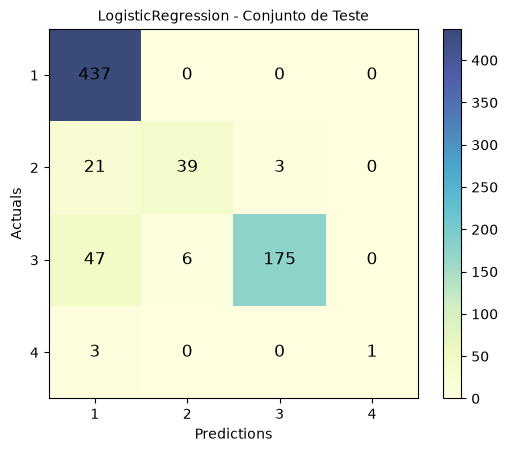


────────────────────────────────────────────────────────────────────────────────
Modelo: KNeighbors
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.80      0.98      0.88       437
           2       0.71      0.51      0.59        63
           3       0.92      0.61      0.73       228
           4       0.00      0.00      0.00         4

    accuracy                           0.82       732
   macro avg       0.61      0.52      0.55       732
weighted avg       0.82      0.82      0.80       732


Matriz de Confusão:
[[427   1   9   0]
 [ 28  32   3   0]
 [ 78  12 138   0]
 [  4   0   0   0]]


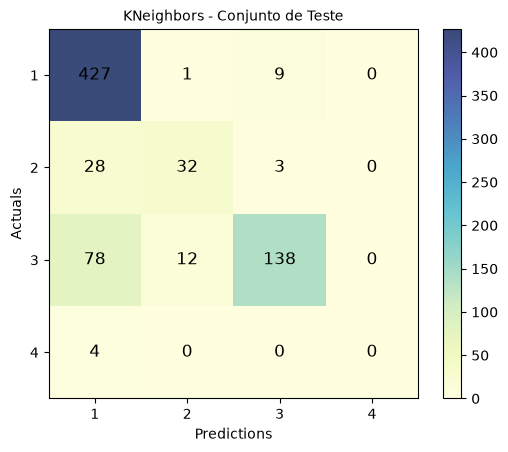


────────────────────────────────────────────────────────────────────────────────
Modelo: SVC
────────────────────────────────────────────────────────────────────────────────



Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.76      0.92      0.84       437
           2       0.00      0.00      0.00        63
           3       0.65      0.57      0.61       228
           4       0.00      0.00      0.00         4

    accuracy                           0.73       732
   macro avg       0.35      0.37      0.36       732
weighted avg       0.66      0.73      0.69       732


Matriz de Confusão:
[[404   0  33   0]
 [ 26   0  37   0]
 [ 97   0 131   0]
 [  2   0   2   0]]


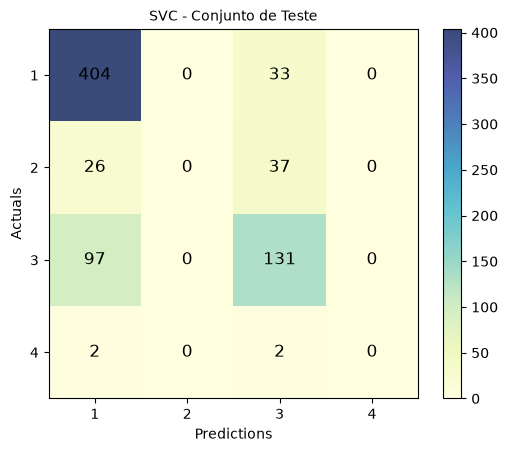


────────────────────────────────────────────────────────────────────────────────
Modelo: DecisionTree
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.96      0.97      0.96       437
           2       0.82      0.89      0.85        63
           3       0.96      0.93      0.95       228
           4       0.33      0.25      0.29         4

    accuracy                           0.95       732
   macro avg       0.77      0.76      0.76       732
weighted avg       0.95      0.95      0.95       732


Matriz de Confusão:
[[423   7   6   1]
 [  4  56   2   1]
 [ 10   5 213   0]
 [  3   0   0   1]]


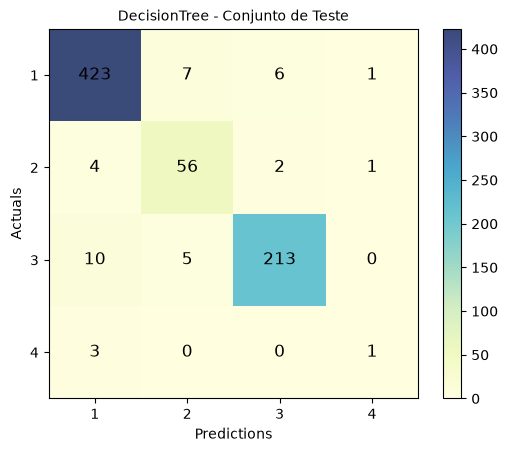


────────────────────────────────────────────────────────────────────────────────
Modelo: ExtraTrees
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.93      0.97      0.95       437
           2       0.83      0.79      0.81        63
           3       0.92      0.87      0.90       228
           4       1.00      0.25      0.40         4

    accuracy                           0.92       732
   macro avg       0.92      0.72      0.77       732
weighted avg       0.92      0.92      0.92       732


Matriz de Confusão:
[[425   0  12   0]
 [  8  50   5   0]
 [ 19  10 199   0]
 [  3   0   0   1]]


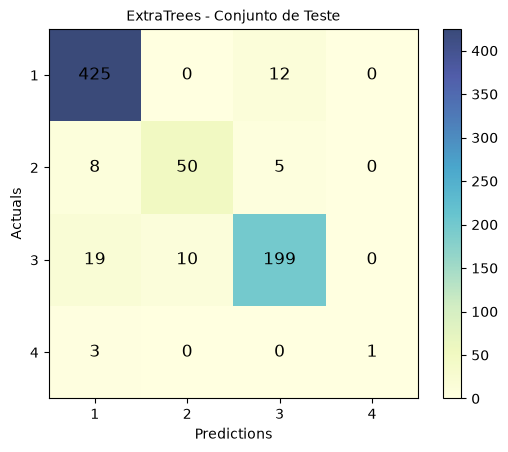


────────────────────────────────────────────────────────────────────────────────
Modelo: RandomForest
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.94      0.98      0.96       437
           2       0.96      0.83      0.89        63
           3       0.95      0.92      0.94       228
           4       0.00      0.00      0.00         4

    accuracy                           0.95       732
   macro avg       0.71      0.68      0.70       732
weighted avg       0.94      0.95      0.94       732


Matriz de Confusão:
[[430   0   7   0]
 [  7  52   4   0]
 [ 16   2 210   0]
 [  4   0   0   0]]


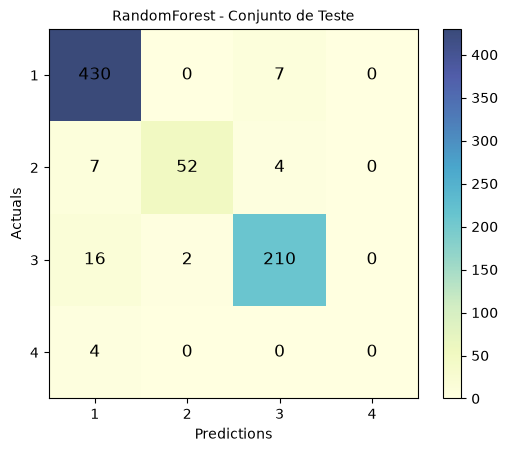


────────────────────────────────────────────────────────────────────────────────
Modelo: GaussianNB
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.78      0.90      0.83       437
           2       0.67      0.03      0.06        63
           3       0.62      0.61      0.61       228
           4       0.00      0.00      0.00         4

    accuracy                           0.73       732
   macro avg       0.52      0.38      0.38       732
weighted avg       0.71      0.73      0.69       732


Matriz de Confusão:
[[393   1  43   0]
 [ 21   2  40   0]
 [ 90   0 138   0]
 [  2   0   2   0]]


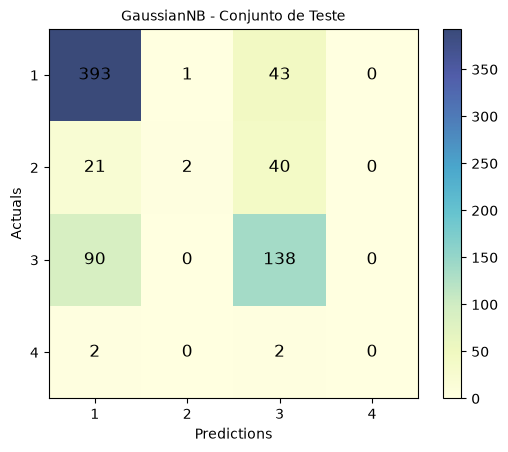


RELATÓRIO RESUMIDO - CONJUNTO DE TESTE
LogisticRegression   | Acc: 0.8907
KNeighbors           | Acc: 0.8156
SVC                  | Acc: 0.7309
DecisionTree         | Acc: 0.9467
ExtraTrees           | Acc: 0.9221
RandomForest         | Acc: 0.9454
GaussianNB           | Acc: 0.7281


COMPARAÇÃO: VALIDAÇÃO CRUZADA vs TESTE

             Model CV_Accuracy Test_Accuracy
LogisticRegression      0.8705        0.8907
        KNeighbors      0.8015        0.8156
               SVC      0.7171        0.7309
      DecisionTree      0.9320        0.9467
        ExtraTrees      0.9218        0.9221
      RandomForest      0.9429        0.9454
        GaussianNB      0.7188        0.7281


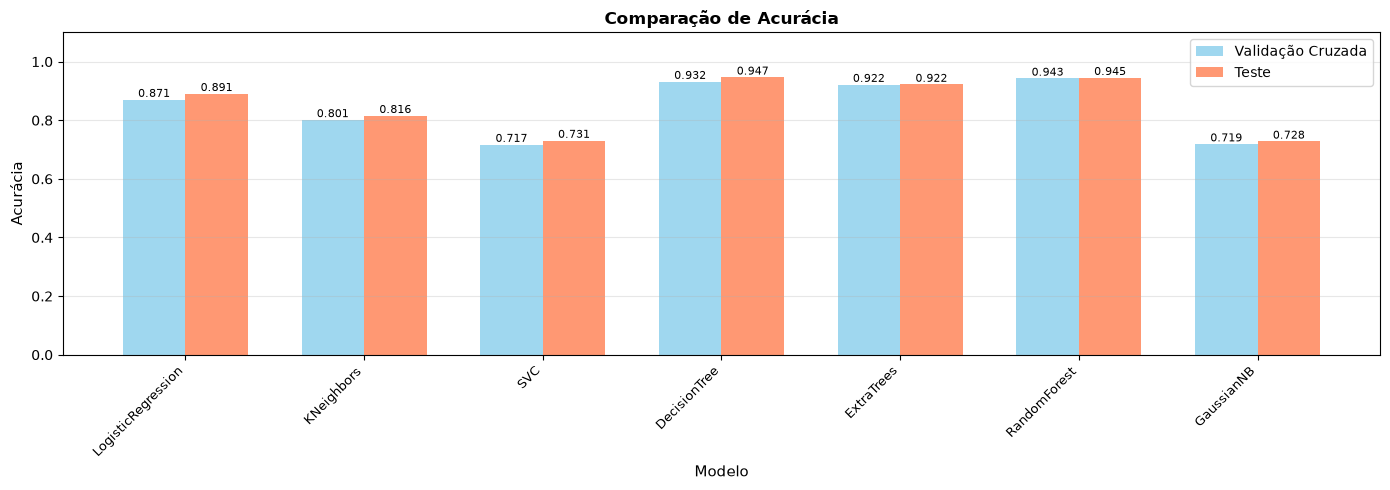


ANÁLISE DE OVERFITTING
LogisticRegression   | CV: 0.8705 | Test: 0.8907 | Diff: -0.0202
KNeighbors           | CV: 0.8015 | Test: 0.8156 | Diff: -0.0141
SVC                  | CV: 0.7171 | Test: 0.7309 | Diff: -0.0138
DecisionTree         | CV: 0.9320 | Test: 0.9467 | Diff: -0.0147
ExtraTrees           | CV: 0.9218 | Test: 0.9221 | Diff: -0.0003
RandomForest         | CV: 0.9429 | Test: 0.9454 | Diff: -0.0025
GaussianNB           | CV: 0.7188 | Test: 0.7281 | Diff: -0.0093


,Model,CV_Accuracy,Test_Accuracy
0,LogisticRegression,0.8705,0.8907
1,KNeighbors,0.8015,0.8156
2,SVC,0.7171,0.7309
3,DecisionTree,0.9320,0.9467
4,ExtraTrees,0.9218,0.9221
5,RandomForest,0.9429,0.9454
6,GaussianNB,0.7188,0.7281


In [29]:
resultados_cv_banda = model_cross_validation(X_train_banda, y_train_banda, pipelines, folds=5, binary_classification=binaryClassification_banda)
trained_pipelines_banda = model_train(X_train_banda, y_train_banda, pipelines, model_dir=f'{pasta_resultados_banda}/models')
test_results_banda = evaluate_on_test(
    X_test_banda,
    y_test_banda,
    trained_pipelines_banda,
    rotulos_dataset_banda,
    binary_classification=binaryClassification_banda,
    result_path=pasta_resultados_banda
)
compare_train_test_performance(resultados_cv_banda, test_results_banda, result_path=pasta_resultados_banda)


In [30]:
historico_fluxo = pd.read_csv(f"{pasta_dataset}/{arquivo_historico_fluxo}")

# Mesmo cuidado das seções anteriores: preenche eventuais falhas pontuais de
# leitura (latência ou banda) por interpolação linear antes de montar X/y.
colunas_numericas_fluxo = historico_fluxo.columns.drop(['timestamp', 'categoria'])
faltantes_fluxo = historico_fluxo[colunas_numericas_fluxo].isna().sum().sum()
if faltantes_fluxo:
    print(f"Aviso: {faltantes_fluxo} valores faltantes no histórico multiobjetivo — preenchidos por interpolação linear.")
    historico_fluxo[colunas_numericas_fluxo] = historico_fluxo[colunas_numericas_fluxo].interpolate(method='linear', limit_direction='both')

rotulos_fluxo = np.loadtxt(f"{pasta_dataset}/{arquivo_rotulos_fluxo}", comments='#', dtype=int)

colunas_latencia = [coluna for coluna in historico_fluxo.columns if coluna.startswith('latencia_')]
colunas_banda = [coluna for coluna in historico_fluxo.columns if coluna.startswith('banda_')]

fluxo_datetimes = historico_fluxo.iloc[:, 0].values
fluxo_datetimes_dt = pd.to_datetime(fluxo_datetimes)

fluxo_temporal_features = np.column_stack([
    fluxo_datetimes_dt.hour,
    fluxo_datetimes_dt.minute,
    fluxo_datetimes_dt.second,
    fluxo_datetimes_dt.day,
    fluxo_datetimes_dt.month,
    fluxo_datetimes_dt.year
])

latencia_por_rota_fluxo = historico_fluxo[colunas_latencia].values
banda_por_rota_fluxo = historico_fluxo[colunas_banda].values
categoria_fluxo = historico_fluxo['categoria'].values

# Codifica a categoria como feature numérica: o rótulo correto de uma mesma
# linha de telemetria depende de qual categoria de fluxo ela representa
categorias_unicas = sorted(np.unique(categoria_fluxo))
categoria_para_id = {categoria: indice for indice, categoria in enumerate(categorias_unicas)}
categoria_codificada = np.array([[categoria_para_id[c]] for c in categoria_fluxo])

print(f"Categorias: {categoria_para_id}")

X_fluxo = np.hstack([fluxo_temporal_features, latencia_por_rota_fluxo, banda_por_rota_fluxo, categoria_codificada])
y_fluxo = rotulos_fluxo

print(f"Shape X_fluxo: {X_fluxo.shape}")
print(pd.Series(categoria_fluxo).value_counts())


Aviso: 4 valores faltantes no histórico multiobjetivo — preenchidos por interpolação linear.
Categorias: {'elephant': 0, 'mice': 1}
Shape X_fluxo: (7316, 15)
mice        3658
elephant    3658
Name: count, dtype: int64


In [31]:
# As linhas do histórico multiobjetivo estão agrupadas por categoria (todas
# as 'mice' primeiro, depois todas as 'elephant'). Embaralha X, y e a
# categoria juntos (mesma permutação) para misturar as categorias antes do
# treino/teste e da validação cruzada.
X_fluxo, y_fluxo, categoria_fluxo = shuffle(X_fluxo, y_fluxo, categoria_fluxo, random_state=1234)

print("Categorias após o shuffle (primeiras 20 linhas):")
print(categoria_fluxo[:20])


Categorias após o shuffle (primeiras 20 linhas):
<StringArray>
[    'mice',     'mice', 'elephant',     'mice', 'elephant',     'mice',
 'elephant', 'elephant',     'mice',     'mice',     'mice',     'mice',
     'mice', 'elephant', 'elephant',     'mice', 'elephant',     'mice',
 'elephant',     'mice']
Length: 20, dtype: str


In [32]:
pasta_resultados_fluxo = f"{RESULTS_FOLDER}/CenarioMultiObjetivo_{DATASET}"
os.makedirs(pasta_resultados_fluxo, exist_ok=True)

rotulos_dataset_fluxo = np.unique(y_fluxo).tolist()
binaryClassification_fluxo = len(rotulos_dataset_fluxo) <= 2

X_train_fluxo, X_test_fluxo, y_train_fluxo, y_test_fluxo = train_test_split(
    X_fluxo, y_fluxo,
    test_size=0.2,
    random_state=1234,
    shuffle=True,
    stratify=None
)

print(f"Total de amostras: {len(y_fluxo)}\n")
print(f"Classes únicas:\t\t{rotulos_dataset_fluxo}")
print(f"Classes em y_train_fluxo:\t{np.unique(y_train_fluxo)}")
print(f"Classes em y_test_fluxo:\t{np.unique(y_test_fluxo)}")

print("\nDistribuição das classes:")
print(pd.Series(y_fluxo).value_counts())


Total de amostras: 7316

Classes únicas:		[1, 2, 3, 4]
Classes em y_train_fluxo:	[1 2 3 4]
Classes em y_test_fluxo:	[1 2 3 4]

Distribuição das classes:
4    3073
1    2290
3    1557
2     396
Name: count, dtype: int64


VALIDAÇÃO CRUZADA NO CONJUNTO DE TREINO (Stratified K-Fold)


LogisticRegression   | Acc: 0.8416 ± 0.0104


KNeighbors           | Acc: 0.4903 ± 0.0092


SVC                  | Acc: 0.4236 ± 0.0008


DecisionTree         | Acc: 0.9634 ± 0.0042


ExtraTrees           | Acc: 0.9347 ± 0.0070


RandomForest         | Acc: 0.9598 ± 0.0031
GaussianNB           | Acc: 0.8346 ± 0.0146


AVALIAÇÃO NO CONJUNTO DE TESTE (DADOS NÃO VISTOS)


────────────────────────────────────────────────────────────────────────────────
Modelo: LogisticRegression
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.74      0.89      0.81       458
           2       0.67      0.45      0.54        87
           3       0.81      0.62      0.70       299
           4       0.93      0.94      0.94       620

    accuracy                           0.83      1464
   macro avg       0.79      0.72      0.75      1464
weighted avg       0.83      0.83      0.82      1464


Matriz de Confusão:
[[409   1  20  28]
 [ 31  39  12   5]
 [ 91  15 184   9]
 [ 23   3  12 582]]


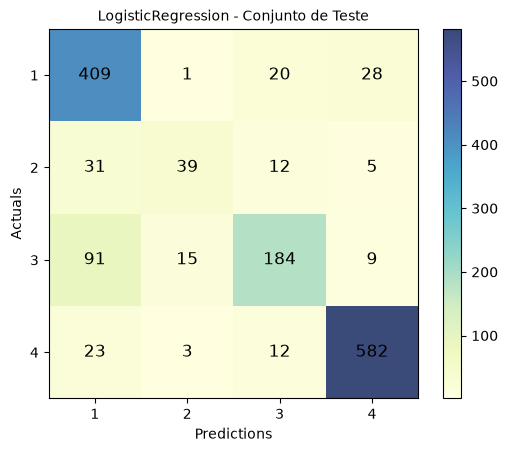


────────────────────────────────────────────────────────────────────────────────
Modelo: KNeighbors
────────────────────────────────────────────────────────────────────────────────



Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.48      0.54      0.51       458
           2       0.28      0.20      0.23        87
           3       0.55      0.51      0.53       299
           4       0.49      0.49      0.49       620

    accuracy                           0.49      1464
   macro avg       0.45      0.43      0.44      1464
weighted avg       0.49      0.49      0.49      1464


Matriz de Confusão:
[[246   2  25 185]
 [ 18  17  16  36]
 [ 43  12 151  93]
 [206  29  82 303]]


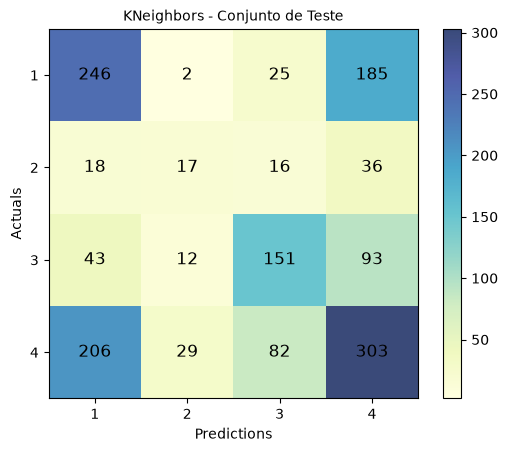


────────────────────────────────────────────────────────────────────────────────
Modelo: SVC
────────────────────────────────────────────────────────────────────────────────



Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00       458
           2       0.00      0.00      0.00        87
           3       0.75      0.18      0.30       299
           4       0.44      0.98      0.61       620

    accuracy                           0.45      1464
   macro avg       0.30      0.29      0.23      1464
weighted avg       0.34      0.45      0.32      1464


Matriz de Confusão:
[[  0   0   6 452]
 [  0   0   2  85]
 [  0   0  55 244]
 [  0   0  10 610]]


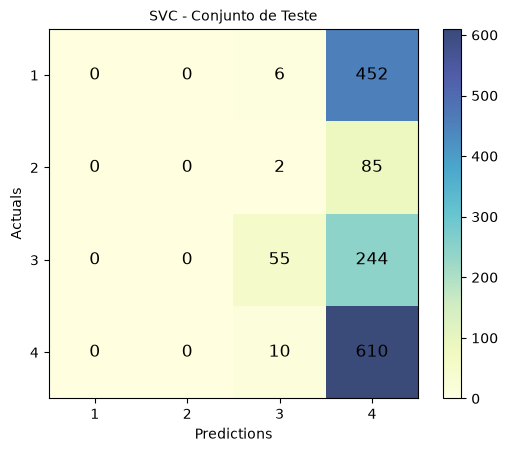


────────────────────────────────────────────────────────────────────────────────
Modelo: DecisionTree
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.97      0.97      0.97       458
           2       0.88      0.86      0.87        87
           3       0.93      0.94      0.94       299
           4       1.00      0.99      0.99       620

    accuracy                           0.97      1464
   macro avg       0.94      0.94      0.94      1464
weighted avg       0.97      0.97      0.97      1464


Matriz de Confusão:
[[444   3  10   1]
 [  2  75  10   0]
 [  9   6 282   2]
 [  3   1   2 614]]


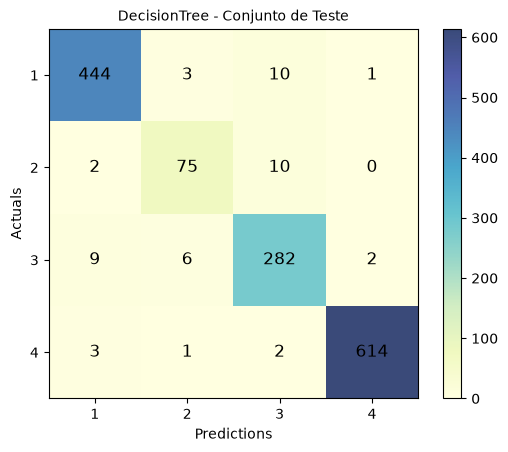


────────────────────────────────────────────────────────────────────────────────
Modelo: ExtraTrees
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.92      0.97      0.94       458
           2       0.93      0.72      0.81        87
           3       0.90      0.89      0.90       299
           4       0.98      0.99      0.98       620

    accuracy                           0.94      1464
   macro avg       0.93      0.89      0.91      1464
weighted avg       0.94      0.94      0.94      1464


Matriz de Confusão:
[[442   0  10   6]
 [  7  63  16   1]
 [ 24   5 265   5]
 [  5   0   2 613]]


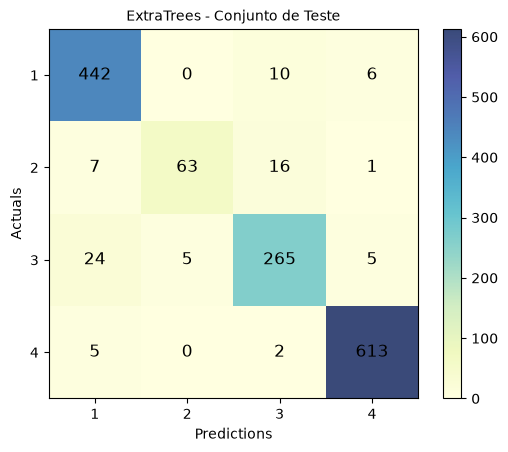


────────────────────────────────────────────────────────────────────────────────
Modelo: RandomForest
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.95      0.97      0.96       458
           2       0.96      0.83      0.89        87
           3       0.91      0.94      0.92       299
           4       1.00      0.98      0.99       620

    accuracy                           0.96      1464
   macro avg       0.95      0.93      0.94      1464
weighted avg       0.96      0.96      0.96      1464


Matriz de Confusão:
[[446   0  12   0]
 [  6  72   9   0]
 [ 14   3 280   2]
 [  5   0   6 609]]


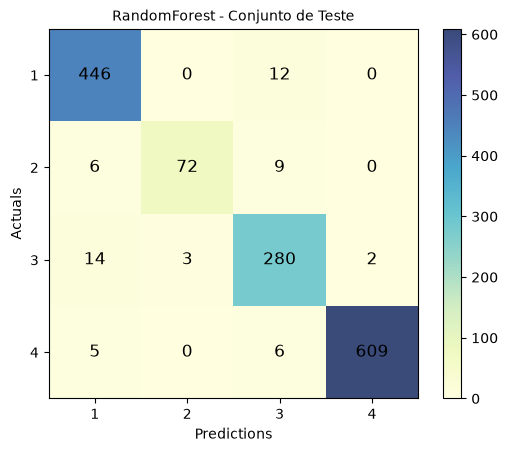


────────────────────────────────────────────────────────────────────────────────
Modelo: GaussianNB
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.78      0.86      0.82       458
           2       0.49      0.47      0.48        87
           3       0.73      0.67      0.70       299
           4       0.99      0.96      0.97       620

    accuracy                           0.84      1464
   macro avg       0.75      0.74      0.74      1464
weighted avg       0.84      0.84      0.84      1464


Matriz de Confusão:
[[395  22  40   1]
 [ 33  41  13   0]
 [ 73  19 199   8]
 [  6   1  20 593]]


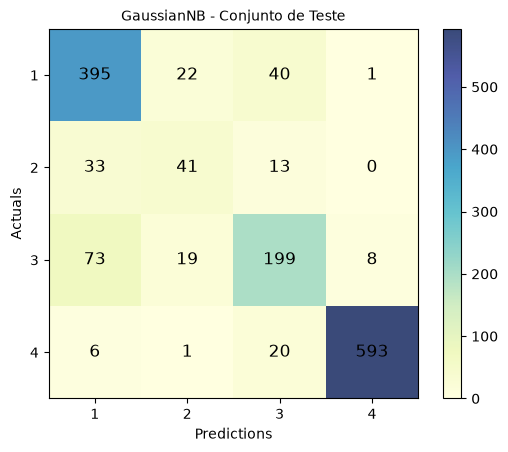


RELATÓRIO RESUMIDO - CONJUNTO DE TESTE
LogisticRegression   | Acc: 0.8292
KNeighbors           | Acc: 0.4898
SVC                  | Acc: 0.4542
DecisionTree         | Acc: 0.9665
ExtraTrees           | Acc: 0.9447
RandomForest         | Acc: 0.9611
GaussianNB           | Acc: 0.8388


COMPARAÇÃO: VALIDAÇÃO CRUZADA vs TESTE

             Model CV_Accuracy Test_Accuracy
LogisticRegression      0.8416        0.8292
        KNeighbors      0.4903        0.4898
               SVC      0.4236        0.4542
      DecisionTree      0.9634        0.9665
        ExtraTrees      0.9347        0.9447
      RandomForest      0.9598        0.9611
        GaussianNB      0.8346        0.8388


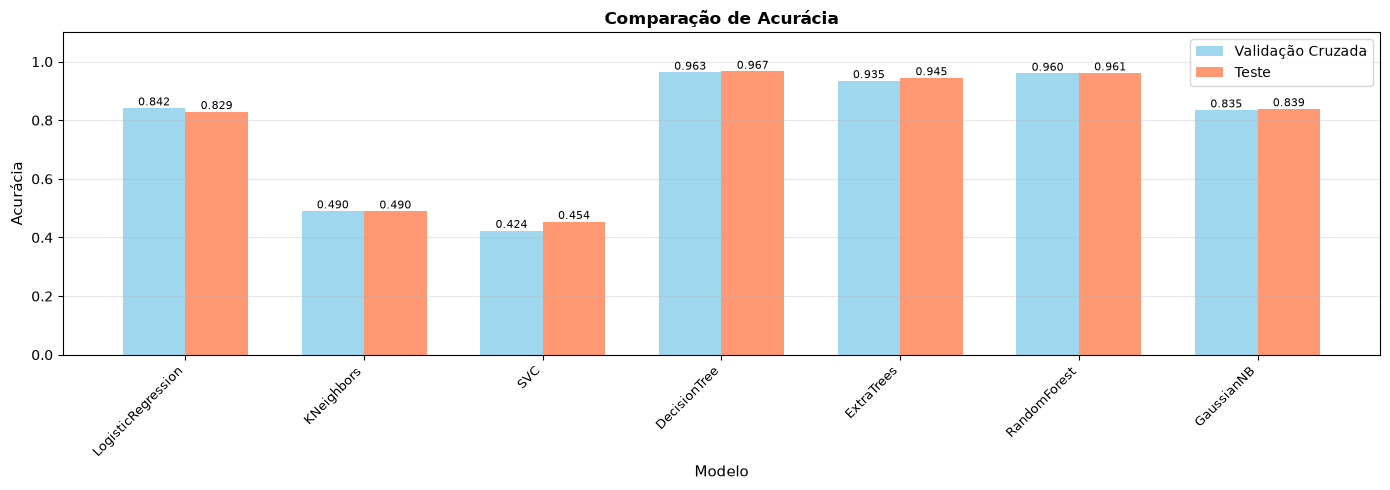


ANÁLISE DE OVERFITTING
LogisticRegression   | CV: 0.8416 | Test: 0.8292 | Diff: +0.0124
KNeighbors           | CV: 0.4903 | Test: 0.4898 | Diff: +0.0005
SVC                  | CV: 0.4236 | Test: 0.4542 | Diff: -0.0306
DecisionTree         | CV: 0.9634 | Test: 0.9665 | Diff: -0.0031
ExtraTrees           | CV: 0.9347 | Test: 0.9447 | Diff: -0.0100
RandomForest         | CV: 0.9598 | Test: 0.9611 | Diff: -0.0013
GaussianNB           | CV: 0.8346 | Test: 0.8388 | Diff: -0.0042


,Model,CV_Accuracy,Test_Accuracy
0,LogisticRegression,0.8416,0.8292
1,KNeighbors,0.4903,0.4898
2,SVC,0.4236,0.4542
3,DecisionTree,0.9634,0.9665
4,ExtraTrees,0.9347,0.9447
5,RandomForest,0.9598,0.9611
6,GaussianNB,0.8346,0.8388


In [33]:
resultados_cv_fluxo = model_cross_validation(X_train_fluxo, y_train_fluxo, pipelines, folds=5, binary_classification=binaryClassification_fluxo)
trained_pipelines_fluxo = model_train(X_train_fluxo, y_train_fluxo, pipelines, model_dir=f'{pasta_resultados_fluxo}/models')
test_results_fluxo = evaluate_on_test(
    X_test_fluxo,
    y_test_fluxo,
    trained_pipelines_fluxo,
    rotulos_dataset_fluxo,
    binary_classification=binaryClassification_fluxo,
    result_path=pasta_resultados_fluxo
)
compare_train_test_performance(resultados_cv_fluxo, test_results_fluxo, result_path=pasta_resultados_fluxo)


In [34]:
historico_fluxo_robusto = pd.read_csv(f"{pasta_dataset}/{arquivo_historico_fluxo}")
rotulos_fluxo_robusto = np.loadtxt(f"{pasta_dataset}/{arquivo_rotulos_fluxo}", comments='#', dtype=int)

colunas_latencia_robusto = [c for c in historico_fluxo_robusto.columns if c.startswith('latencia_')]
colunas_banda_robusto = [c for c in historico_fluxo_robusto.columns if c.startswith('banda_')]
colunas_numericas_robusto = colunas_latencia_robusto + colunas_banda_robusto

if historico_fluxo_robusto[colunas_numericas_robusto].isna().any().any():
    print("Aviso: valores faltantes no histórico — preenchidos por interpolação linear.")
    historico_fluxo_robusto[colunas_numericas_robusto] = (
        historico_fluxo_robusto[colunas_numericas_robusto]
        .interpolate(method='linear', limit_direction='both')
    )

datetimes_robusto = pd.to_datetime(historico_fluxo_robusto['timestamp'])
elapsed_seconds_robusto = (datetimes_robusto - datetimes_robusto.min()).dt.total_seconds().values.reshape(-1, 1)

latencia_por_rota_robusto = historico_fluxo_robusto[colunas_latencia_robusto].values
banda_por_rota_robusto = historico_fluxo_robusto[colunas_banda_robusto].values
categoria_fluxo_robusto = historico_fluxo_robusto['categoria'].values

# Codifica a categoria como feature numérica (mesma lógica da seção anterior)
categorias_unicas_robusto = sorted(np.unique(categoria_fluxo_robusto))
categoria_para_id_robusto = {categoria: indice for indice, categoria in enumerate(categorias_unicas_robusto)}
categoria_codificada_robusto = np.array([[categoria_para_id_robusto[c]] for c in categoria_fluxo_robusto])

X_robusto = np.hstack([elapsed_seconds_robusto, latencia_por_rota_robusto, banda_por_rota_robusto, categoria_codificada_robusto])
y_robusto = rotulos_fluxo_robusto

print(f"Categorias: {categoria_para_id_robusto}")
print(f"Shape X_robusto: {X_robusto.shape}")
print(f"Intervalo de elapsed_seconds: {elapsed_seconds_robusto.min():.0f}s a {elapsed_seconds_robusto.max():.0f}s")


Aviso: valores faltantes no histórico — preenchidos por interpolação linear.
Categorias: {'elephant': 0, 'mice': 1}
Shape X_robusto: (7316, 10)
Intervalo de elapsed_seconds: 0s a 3659s


In [35]:
def split_temporal_por_categoria(categorias, fracao_treino=0.8):
    """
    Split cronológico (não aleatório) feito separadamente dentro de cada
    categoria: as primeiras 'fracao_treino' linhas de cada categoria (na
    ordem em que aparecem no histórico, ou seja, por tempo) vão para o
    treino, o restante para o teste. Evita que timestamps vizinhos — com
    condições de rede quase idênticas — caiam ao mesmo tempo em treino e
    teste.
    """
    indices_treino, indices_teste = [], []
    for categoria in np.unique(categorias):
        indices_categoria = np.where(categorias == categoria)[0]
        corte = int(len(indices_categoria) * fracao_treino)
        indices_treino.extend(indices_categoria[:corte])
        indices_teste.extend(indices_categoria[corte:])
    return np.array(indices_treino), np.array(indices_teste)

indices_treino_robusto, indices_teste_robusto = split_temporal_por_categoria(categoria_fluxo_robusto)

X_train_robusto, X_test_robusto = X_robusto[indices_treino_robusto], X_robusto[indices_teste_robusto]
y_train_robusto, y_test_robusto = y_robusto[indices_treino_robusto], y_robusto[indices_teste_robusto]
categoria_teste_robusto = categoria_fluxo_robusto[indices_teste_robusto]

rotulos_dataset_robusto = np.unique(y_robusto).tolist()
binaryClassification_robusto = len(rotulos_dataset_robusto) <= 2

print(f"Treino: {len(y_train_robusto)} | Teste: {len(y_test_robusto)}")
print("\nDistribuição das classes no treino:")
print(pd.Series(y_train_robusto).value_counts())
print("\nDistribuição das classes no teste:")
print(pd.Series(y_test_robusto).value_counts())
print("\nCategorias no teste:")
print(pd.Series(categoria_teste_robusto).value_counts())


Treino: 5852 | Teste: 1464

Distribuição das classes no treino:
4    2542
1    1788
3    1196
2     326
Name: count, dtype: int64

Distribuição das classes no teste:
4    531
1    502
3    361
2     70
Name: count, dtype: int64

Categorias no teste:
elephant    732
mice        732
Name: count, dtype: int64


In [36]:
# Mesmos 7 modelos das seções anteriores, mas com class_weight='balanced' nos
# que suportam o parâmetro (compensa a classe minoritária) e um StandardScaler
# antes do classificador (evita que a banda, com faixa 0-100, domine a
# distância/kernel de KNN e SVC sobre a categoria, que é só 0/1).
modelos_robustos = [
    ('LogisticRegression', LogisticRegression(max_iter=1000, class_weight='balanced')),
    ('KNeighbors', KNeighborsClassifier()),
    ('SVC', svm.SVC(probability=True, class_weight='balanced')),
    ('DecisionTree', tree.DecisionTreeClassifier(class_weight='balanced')),
    ('ExtraTrees', ExtraTreesClassifier(class_weight='balanced')),
    ('RandomForest', RandomForestClassifier(class_weight='balanced')),
    ('GaussianNB', GaussianNB())
]

pipelines_robustos = {}
for nome_modelo, modelo in modelos_robustos:
    pipelines_robustos[nome_modelo] = Pipeline(steps=[
        ('scaler', StandardScaler()),
        ('classifier', modelo)
    ])


VALIDAÇÃO CRUZADA NO CONJUNTO DE TREINO (Stratified K-Fold)


LogisticRegression   | Acc: 0.8633 ± 0.0127


KNeighbors           | Acc: 0.8766 ± 0.0061


SVC                  | Acc: 0.8756 ± 0.0067


DecisionTree         | Acc: 0.9617 ± 0.0050


ExtraTrees           | Acc: 0.9528 ± 0.0030


RandomForest         | Acc: 0.9663 ± 0.0023


GaussianNB           | Acc: 0.8395 ± 0.0097


AVALIAÇÃO NO CONJUNTO DE TESTE (DADOS NÃO VISTOS)


────────────────────────────────────────────────────────────────────────────────
Modelo: LogisticRegression
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.80      0.82      0.81       502
           2       0.39      0.69      0.49        70
           3       0.82      0.69      0.75       361
           4       0.98      0.98      0.98       531

    accuracy                           0.84      1464
   macro avg       0.75      0.79      0.76      1464
weighted avg       0.85      0.84      0.84      1464


Matriz de Confusão:
[[410  42  48   2]
 [ 20  48   2   0]
 [ 74  32 249   6]
 [  7   2   4 518]]


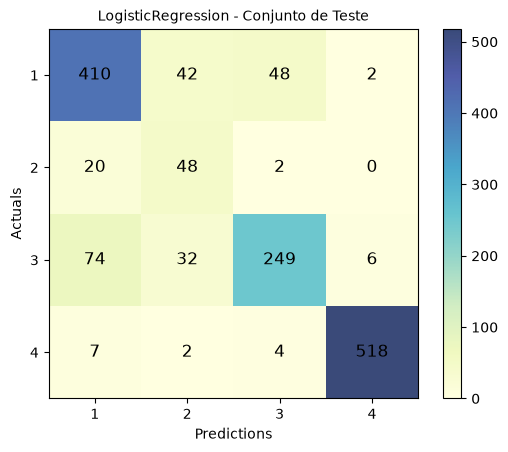


────────────────────────────────────────────────────────────────────────────────
Modelo: KNeighbors
────────────────────────────────────────────────────────────────────────────────



Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.80      0.86      0.83       502
           2       0.48      0.49      0.48        70
           3       0.79      0.66      0.72       361
           4       0.95      0.98      0.97       531

    accuracy                           0.84      1464
   macro avg       0.75      0.75      0.75      1464
weighted avg       0.84      0.84      0.84      1464


Matriz de Confusão:
[[434   6  55   7]
 [ 30  34   6   0]
 [ 74  30 238  19]
 [  7   1   2 521]]


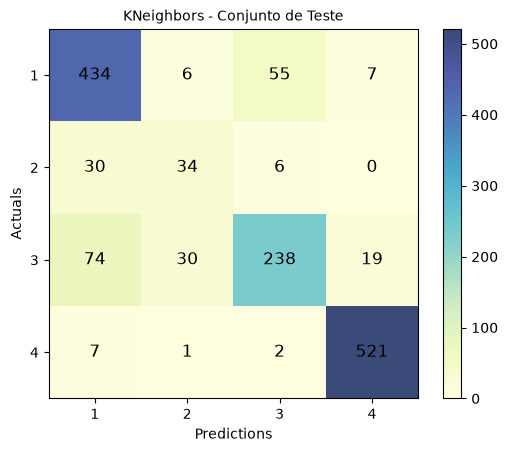


────────────────────────────────────────────────────────────────────────────────
Modelo: SVC
────────────────────────────────────────────────────────────────────────────────



Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.84      0.88      0.86       502
           2       0.40      0.63      0.49        70
           3       0.87      0.72      0.79       361
           4       0.98      0.98      0.98       531

    accuracy                           0.87      1464
   macro avg       0.77      0.80      0.78      1464
weighted avg       0.88      0.87      0.87      1464


Matriz de Confusão:
[[441  24  33   4]
 [ 23  44   3   0]
 [ 54  40 261   6]
 [  6   1   3 521]]


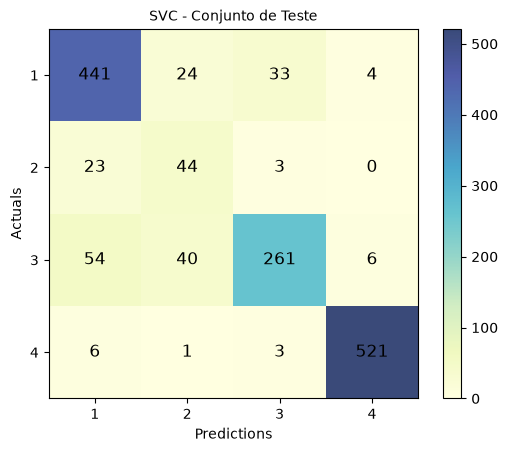


────────────────────────────────────────────────────────────────────────────────
Modelo: DecisionTree
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.95      0.95      0.95       502
           2       0.83      0.81      0.82        70
           3       0.92      0.92      0.92       361
           4       0.98      0.98      0.98       531

    accuracy                           0.95      1464
   macro avg       0.92      0.92      0.92      1464
weighted avg       0.95      0.95      0.95      1464


Matriz de Confusão:
[[477   3  15   7]
 [  4  57   9   0]
 [ 19   9 331   2]
 [  4   0   5 522]]


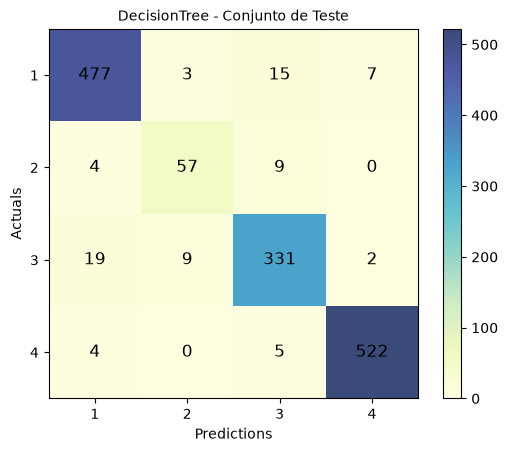


────────────────────────────────────────────────────────────────────────────────
Modelo: ExtraTrees
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.92      0.94      0.93       502
           2       0.84      0.70      0.77        70
           3       0.90      0.88      0.89       361
           4       0.97      0.98      0.98       531

    accuracy                           0.93      1464
   macro avg       0.91      0.88      0.89      1464
weighted avg       0.93      0.93      0.93      1464


Matriz de Confusão:
[[474   0  22   6]
 [ 12  49   9   0]
 [ 24   9 318  10]
 [  6   0   3 522]]


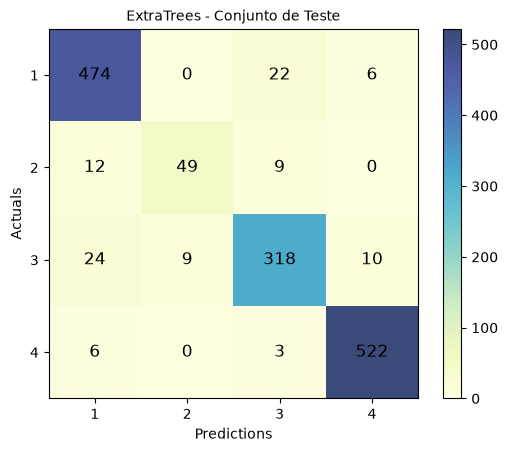


────────────────────────────────────────────────────────────────────────────────
Modelo: RandomForest
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.94      0.96      0.95       502
           2       0.89      0.77      0.82        70
           3       0.92      0.93      0.93       361
           4       0.99      0.98      0.98       531

    accuracy                           0.95      1464
   macro avg       0.93      0.91      0.92      1464
weighted avg       0.95      0.95      0.95      1464


Matriz de Confusão:
[[483   0  18   1]
 [  9  54   7   0]
 [ 14   7 337   3]
 [  8   0   5 518]]


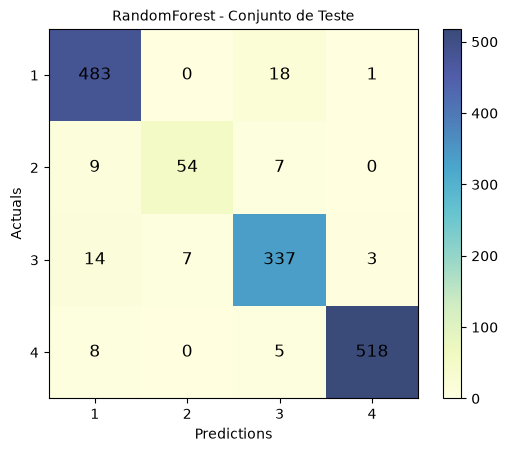


────────────────────────────────────────────────────────────────────────────────
Modelo: GaussianNB
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.77      0.76      0.77       502
           2       0.30      0.34      0.32        70
           3       0.69      0.66      0.68       361
           4       0.96      0.97      0.97       531

    accuracy                           0.79      1464
   macro avg       0.68      0.69      0.68      1464
weighted avg       0.80      0.79      0.79      1464


Matriz de Confusão:
[[384  35  78   5]
 [ 26  24  20   0]
 [ 85  21 240  15]
 [  6   1  10 514]]


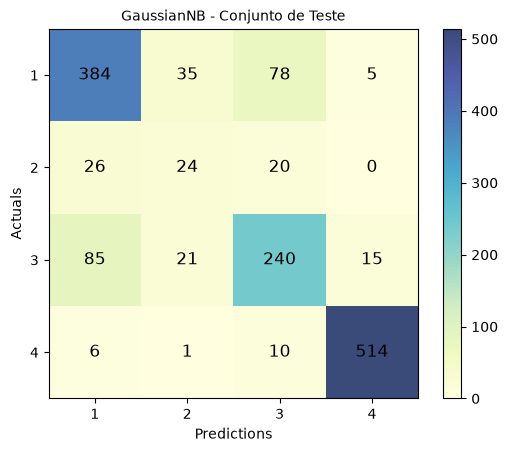


RELATÓRIO RESUMIDO - CONJUNTO DE TESTE
LogisticRegression   | Acc: 0.8367
KNeighbors           | Acc: 0.8381
SVC                  | Acc: 0.8654
DecisionTree         | Acc: 0.9474
ExtraTrees           | Acc: 0.9310
RandomForest         | Acc: 0.9508
GaussianNB           | Acc: 0.7937


COMPARAÇÃO: VALIDAÇÃO CRUZADA vs TESTE

             Model CV_Accuracy Test_Accuracy
LogisticRegression      0.8633        0.8367
        KNeighbors      0.8766        0.8381
               SVC      0.8756        0.8654
      DecisionTree      0.9617        0.9474
        ExtraTrees      0.9528        0.9310
      RandomForest      0.9663        0.9508
        GaussianNB      0.8395        0.7937


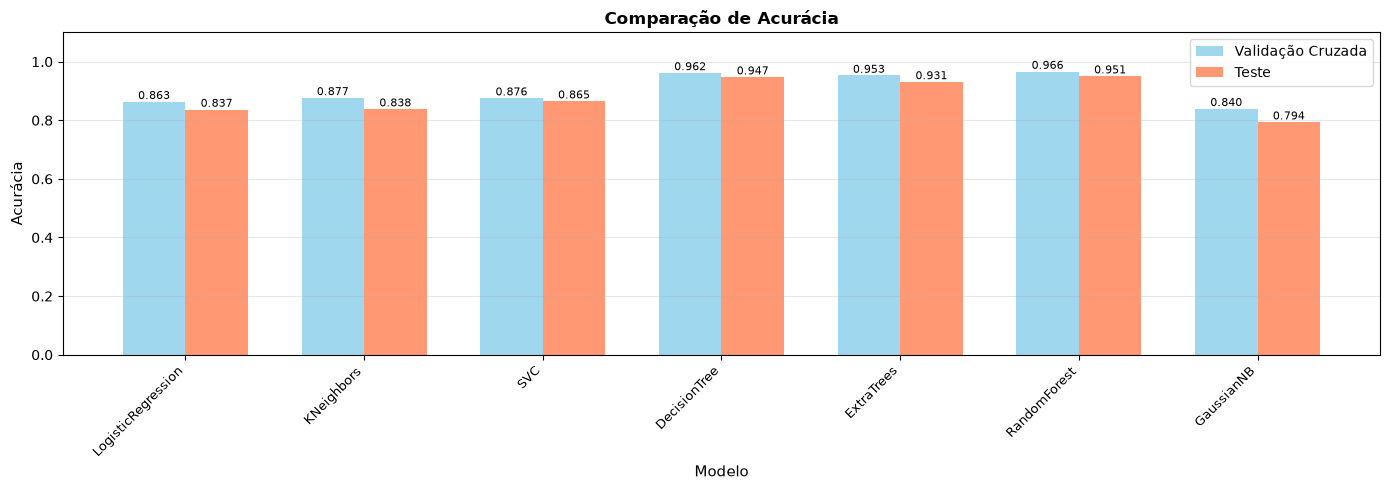


ANÁLISE DE OVERFITTING
LogisticRegression   | CV: 0.8633 | Test: 0.8367 | Diff: +0.0266
KNeighbors           | CV: 0.8766 | Test: 0.8381 | Diff: +0.0385
SVC                  | CV: 0.8756 | Test: 0.8654 | Diff: +0.0102
DecisionTree         | CV: 0.9617 | Test: 0.9474 | Diff: +0.0143
ExtraTrees           | CV: 0.9528 | Test: 0.9310 | Diff: +0.0218
RandomForest         | CV: 0.9663 | Test: 0.9508 | Diff: +0.0155
GaussianNB           | CV: 0.8395 | Test: 0.7937 | Diff: +0.0458


,Model,CV_Accuracy,Test_Accuracy
0,LogisticRegression,0.8633,0.8367
1,KNeighbors,0.8766,0.8381
2,SVC,0.8756,0.8654
3,DecisionTree,0.9617,0.9474
4,ExtraTrees,0.9528,0.9310
5,RandomForest,0.9663,0.9508
6,GaussianNB,0.8395,0.7937


In [37]:
pasta_resultados_robusto = f"{RESULTS_FOLDER}/CenarioMultiObjetivoRobusto_{DATASET}"
os.makedirs(pasta_resultados_robusto, exist_ok=True)

resultados_cv_robusto = model_cross_validation(X_train_robusto, y_train_robusto, pipelines_robustos, folds=5, binary_classification=binaryClassification_robusto)
trained_pipelines_robusto = model_train(X_train_robusto, y_train_robusto, pipelines_robustos, model_dir=f'{pasta_resultados_robusto}/models')
test_results_robusto = evaluate_on_test(
    X_test_robusto,
    y_test_robusto,
    trained_pipelines_robusto,
    rotulos_dataset_robusto,
    binary_classification=binaryClassification_robusto,
    result_path=pasta_resultados_robusto
)
compare_train_test_performance(resultados_cv_robusto, test_results_robusto, result_path=pasta_resultados_robusto)


In [389]:
# Shared temporal evaluation protocol: pt, imported at initialization together with
#   PROJECT_ROOT. RAIZ_PRED keeps the name the cells of this section use.
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit

RAIZ_PRED = PROJECT_ROOT

print(f'raiz do projeto : {RAIZ_PRED}')
print(f'módulo comum    : {pt.__file__}')
print(f'deslocar_alvo   : {pt.deslocar_alvo.__module__}.deslocar_alvo')
print(f'split_temporal  : {pt.split_temporal.__module__}.split_temporal')

raiz do projeto : /home/beatrizam/Documents/beatriz/path-aware-datasets
módulo comum    : /home/beatrizam/Documents/beatriz/path-aware-datasets/protocolo_temporal.py
deslocar_alvo   : protocolo_temporal.deslocar_alvo
split_temporal  : protocolo_temporal.split_temporal


In [390]:
# Candidate datasets. D3a and D4a hold only 2 routes and spell their files
#   differently, which resolve_dataset_files sorts out; nothing downstream
#   assumes a fixed number of routes. Both now hold bandwidth as well
#   (banda_rotas_h1_h6_12.csv, rotulos_maior_banda_12.txt); datasets_com_metrica()
#   still filters this list by what each dataset actually holds.
DATASETS_PRED = ['D1', 'D1b', 'D2', 'D2b', 'D3', 'D3a', 'D3b', 'D4', 'D4a', 'D4b']

# Prediction horizons in seconds. H = 0 reproduces the contemporaneous task of
#   the previous sections, but already with a chronological split: the gap
#   between that column and the accuracy of the "Execução do Pipeline" section
#   isolates how much came from the shuffle and how much from the features.
HORIZONTES_PRED = [0, 1, 5, 15, 30, 60]

# Reference horizon, used by the per-dataset tables and the saved artefacts
H_PRED = 30

FRACAO_TREINO_PRED = 0.8
RANDOM_STATE_PRED = 1234
CV_FOLDS_PRED = 5

# GaussianNB floors every within-class variance at var_smoothing * max(variance
#   over the features). The default, 1e-9, lets a class with one or two training
#   samples collapse into a spike whose log-density beats any class prior: in D1
#   with bandwidth the two route-3 instants bought a +41 bonus against a -7.3
#   prior handicap, and the model predicted route 3 on 76% of the test block.
#   Swept over the datasets at H=30: 1e-3, 5e-3 and 1e-2 do not fix D1 with
#   bandwidth (accuracy stays at 0.21) because the spike merely widens; 5e-2 does
#   (0.24 -> 1.00 at every horizon). The cost is on the H=0 column, which is the
#   contemporaneous near-identity artefact and not a predictive result: D4 with
#   latency drops from 0.879 to 0.779 there. At H > 0 the informative datasets
#   move by at most a point, mostly upwards (D3 with latency 0.114 -> 0.138).
#   No dataset is excluded because of this, so for D1 and D1b with bandwidth
#   this floor is what keeps GaussianNB comparable with the other six models.
VAR_SMOOTHING_PRED = 5e-2

# A feature whose coefficient of variation (std / |mean|) falls below this is
#   constant up to numerical noise. Measured across the ten datasets the two
#   sides are well apart: the bandwidth columns of D1 and D1b sit at 3e-6 to
#   5e-6, with 16 and 39 distinct values in an hour, because with nothing
#   competing for the links the available bandwidth stays pinned at capacity;
#   the least variable column of every other dataset and metric sits at 2e-3 or
#   above, with at least 390 distinct values.
#   The threshold only labels: construir_largo warns and relatorio_variacao
#   reports, and no dataset is ever dropped from an experiment because of it.
LIMIAR_VARIACAO_PRED = 1e-4

# Reuses the configuration of the "Carregamento do dataset" section when it has
#   already run; otherwise falls back to the same defaults.
DATASET_PRED = globals().get('DATASET', 'D2')
PASTA_DATASETS_PRED = RAIZ_PRED / globals().get('DATASET_FOLDER', 'datasets')
PASTA_RESULTADOS_RAIZ_PRED = RAIZ_PRED / globals().get('RESULTS_FOLDER', 'resultados_am')

# Telemetry source(s) used as features: 'latencia', 'banda', or several of them
#   at once, e.g. ('latencia', 'banda'). This is the single switch of the section.
#
#   One source  - read from its own consolidated CSV, latencia_rotas_h1_h6*.csv
#                 or banda_rotas_h1_h6*.csv, exactly as before.
#   Two or more - read together from the combined historico_telemetria_h1_h6*.csv
#                 (historico_telemetria_h1_h6_12.csv in D3a/D4a). Its columns
#                 are named '<metric>_<route>' and come in blocks, one per
#                 metric, with the routes in the same order in every block:
#                     timestamp, latencia_h11_h61, ..., latencia_h14_h64,
#                                banda_h11_h61,    ..., banda_h14_h64[, categoria]
#                 Any column that is not '<requested metric>_<route>', such as
#                 'categoria', is left out of X.
#
#   Either way every feature column is named '<prefix>__<route>', the prefix
#   shared with the feature store (latencia_ms, banda_Mbps), so a frame that
#   combines metrics keeps the metric of each column readable.
#
#   The target does not follow this switch, ALVO_PRED below picks it. With
#   'banda' alone and the default target the question becomes "predict the
#   lowest-latency route from bandwidth", the cross-metric experiment of the
#   Tabela 2 section.
METRICA_PRED = ('latencia', 'banda')


def normalize_metrics(metrics):
    """Tuple of metric names out of a single name or an iterable of names.

    Keeps the order given (it is the order of the feature blocks in X) and
    rejects unknown names and repeats, which would otherwise surface later as an
    empty or duplicated block of columns.
    """
    metrics = (metrics,) if isinstance(metrics, str) else tuple(metrics)
    if not metrics:
        raise ValueError('at least one telemetry source is required')
    unknown = [m for m in metrics if m not in pt.PREFIXO_POR_METRICA]
    if unknown:
        raise ValueError(f'unknown metric(s) {unknown}; '
                         f'expected any of {list(pt.PREFIXO_POR_METRICA)}')
    if len(set(metrics)) != len(metrics):
        raise ValueError(f'repeated metric in {metrics}')
    return metrics


def metrics_label(metrics=None, sep='+'):
    """Readable name of a set of metrics, e.g. 'latencia+banda'."""
    return sep.join(normalize_metrics(metrics or METRICA_PRED))


METRICAS_PRED = normalize_metrics(METRICA_PRED)
PREFIXOS_PRED = tuple(pt.PREFIXO_POR_METRICA[m] for m in METRICAS_PRED)

# Target of the task, independent of the metric(s) used as features:
#   'menor_latencia' - route with the lowest latency, from rotulos_h1_h6.txt
#                      (rotulos_h1_h6_12.txt / labels_h1_h6_12.txt in D3a/D4a).
#                      The label of the paper, and the default here.
#   'menor_latencia_historico'
#                    - route with the lowest latency, ties broken by the mean
#                      over the previous 10 s and then by a seeded draw
#                      (desempate_rotulos.py), from
#                      rotulos_menor_latencia_historico{suffix}.txt.
#   'maior_banda'    - route with the most available bandwidth, from
#                      rotulos_maior_banda.txt, written by gerar_rotulos_banda.py
#                      out of banda_rotas_h1_h6.csv (rotulos_maior_banda_12.txt
#                      out of banda_rotas_h1_h6_12.csv in D3a/D4a).
#   Features and target may come from different sources: construir_largo joins
#   them by timestamp in that case, and pairs them row by row only when the
#   features are the very CSV the label file was written from. Mind that the
#   target metric among the features brings back the structural leak of the
#   H = 0 column, where the target is the argmax (or argmin) of columns in X.
ALVO_PRED = 'menor_latencia'

# Which CSV each target is derived from. This is what decides between pairing by
#   row position and joining by timestamp.
METRICA_DO_ALVO_PRED = {
    'menor_latencia': 'latencia',
    'menor_latencia_historico': 'latencia',
    'maior_banda': 'banda',
}

# One results folder per combination of features and target, so that running
#   the section with another source does not overwrite the previous run. The
#   latency-only run with the default target keeps the folder it always had.
_RESULTS_TAG_PRED = ''.join(m.capitalize() for m in METRICAS_PRED)
if ALVO_PRED != 'menor_latencia':
    _RESULTS_TAG_PRED += f'_{ALVO_PRED}'

PASTA_MODELOS_PRED = RAIZ_PRED / 'models_preditivo'
pasta_resultados_pred = (PASTA_RESULTADOS_RAIZ_PRED /
                         f'CenarioPreditivo{_RESULTS_TAG_PRED}_{DATASET_PRED}_H{H_PRED}')
pasta_resultados_pred.mkdir(parents=True, exist_ok=True)

print(f'dataset     : {DATASET_PRED} ({metrics_label()} -> {ALVO_PRED})')
print(f'horizons    : {HORIZONTES_PRED} (reference: H={H_PRED}s)')
print(f'results     : {pasta_resultados_pred}')

dataset     : D4a (latencia -> menor_latencia)
horizontes  : [0, 1, 5, 15, 30, 60] (referência: H=30s)
resultados  : /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPreditivoLatencia_D4a_H30


In [391]:
# D1 to D4b keep their four routes in latencia_rotas_h1_h6.csv and
#   banda_rotas_h1_h6.csv, next to rotulos_h1_h6.txt, and both metrics together
#   in historico_telemetria_h1_h6.csv. D3a and D4a hold two routes in
#   latencia_rotas_h1_h6_12.csv, banda_rotas_h1_h6_12.csv and
#   historico_telemetria_h1_h6_12.csv, with rotulos_maior_banda_12.txt as
#   bandwidth target, and disagree with each other on the latency label file
#   name: labels_h1_h6_12.txt in D3a, rotulos_h1_h6_12.txt in D4a. Resolving the
#   names by glob and by suffix keeps those spellings in one place.

# Stem of the feature CSV of a single metric, and of the combined one
STEM_POR_METRICA_PRED = {metric: f'{metric}_rotas_h1_h6' for metric in pt.PREFIXO_POR_METRICA}
STEM_COMBINADO_PRED = 'historico_telemetria_h1_h6'


def _unico_csv(folder, pattern):
    matches = sorted(folder.glob(pattern))
    if len(matches) != 1:
        raise FileNotFoundError(
            f'{folder}: expected exactly one {pattern}, found {[m.name for m in matches]}'
        )
    return matches[0]


def combined_columns_by_metric(columns, metrics):
    """Map each requested metric to its '<metric>_<route>' columns, in file order.

    Returns ({metric: [(column, route), ...]}, ignored_columns). Fails when a
    metric has no column, or when the metrics do not cover the same routes in the
    same order: the feature blocks must line up route by route, as the paths of
    the latency block are the paths of the bandwidth block.
    """
    by_metric = {metric: [] for metric in metrics}
    ignored = []
    for column in columns:
        # Longest metric name first, so that no name shadows another that
        #   starts with it
        for metric in sorted(metrics, key=len, reverse=True):
            if column.startswith(f'{metric}_'):
                by_metric[metric].append((column, column[len(metric) + 1:]))
                break
        else:
            ignored.append(column)

    missing = [metric for metric, pairs in by_metric.items() if not pairs]
    if missing:
        raise KeyError(f'no {[f"{m}_<route>" for m in missing]} column')

    routes = {metric: [route for _, route in pairs] for metric, pairs in by_metric.items()}
    reference = routes[metrics[0]]
    for metric in metrics[1:]:
        if routes[metric] != reference:
            raise ValueError(
                f'the routes of {metric} {routes[metric]} do not match the routes '
                f'of {metrics[0]} {reference}'
            )
    return by_metric, ignored


def resolve_dataset_files(dataset, metric=None, root=None, alvo=None):
    """Feature CSV and label TXT of a dataset, as a pair of paths.

    The feature CSV follows `metric`: a single metric points to its own
    consolidated CSV, several metrics to the combined historico_telemetria CSV,
    which must hold a column block for each of them. The label file follows
    `alvo`. Both label files carry the suffix of the CSVs ('' for the four-route
    datasets, '_12' for D3a and D4a): the bandwidth target is
    rotulos_maior_banda{suffix}.txt, while the latency one also changes its stem
    by dataset.
    """
    metrics = normalize_metrics(metric or METRICA_PRED)
    alvo = alvo or ALVO_PRED
    folder = Path(root or PASTA_DATASETS_PRED) / dataset

    if len(metrics) == 1:
        stem = STEM_POR_METRICA_PRED[metrics[0]]
        features = _unico_csv(folder, f'{stem}*.csv')
    else:
        stem = STEM_COMBINADO_PRED
        features = _unico_csv(folder, f'{stem}*.csv')
        try:
            combined_columns_by_metric(
                pd.read_csv(features, nrows=0).columns[1:], metrics
            )
        except (KeyError, ValueError) as error:
            # FileNotFoundError, so that datasets_com_metrica drops the dataset
            #   instead of failing halfway through a loop over DATASETS_PRED
            raise FileNotFoundError(f'{features}: {error}') from error

    # '' for the four-route datasets, '_12' for D3a and D4a
    suffix = features.stem[len(stem):]

    if alvo == 'maior_banda':
        labels = folder / f'rotulos_maior_banda{suffix}.txt'
        if not labels.is_file():
            raise FileNotFoundError(
                f'{folder}: no {labels.name} (run gerar_rotulos_banda.py)'
            )
        return features, labels

    if alvo == 'menor_latencia_historico':
        labels = folder / f'rotulos_menor_latencia_historico{suffix}.txt'
        if not labels.is_file():
            raise FileNotFoundError(f'{folder}: no {labels.name}')
        return features, labels

    for label_stem in (f'rotulos_h1_h6{suffix}', f'labels_h1_h6{suffix}'):
        labels = folder / f'{label_stem}.txt'
        if labels.is_file():
            return features, labels

    raise FileNotFoundError(
        f'{folder}: no rotulos_h1_h6{suffix}.txt nor labels_h1_h6{suffix}.txt'
    )


def datasets_com_metrica(metric=None, candidatos=None, root=None):
    """Candidate datasets that actually hold `metric`, in the declared order.

    `metric` may be one metric or several. A dataset missing the feature CSV,
    one of the requested metric blocks, or the label file of the requested
    target is dropped here instead of failing halfway through a loop over
    DATASETS_PRED.
    """
    disponiveis = []
    for dataset in (candidatos if candidatos is not None else DATASETS_PRED):
        try:
            resolve_dataset_files(dataset, metric, root)
            disponiveis.append(dataset)
        except FileNotFoundError:
            pass
    return disponiveis


def colunas_features(largo, metrica=None):
    """Feature columns of the frame, restricted to the given metric(s).

    Defaults to METRICA_PRED. With several metrics the columns come out in
    blocks, one per metric in the order given, each block in route order. Pass
    `metrica` when handling a frame built for a different metric than the
    configured one.
    """
    columns = []
    for metric in normalize_metrics(metrica or METRICA_PRED):
        columns += pt.colunas_de_feature(largo, prefixo=pt.PREFIXO_POR_METRICA[metric])
    return columns


def combined_wide_frame(csv_path, metrics, grupo, verboso=True):
    """Wide frame of the features of several metrics, from the combined CSV.

    The multi-metric counterpart of pt.largo_de_csv without labels: one row per
    instant, dataset_id and ts_epoch as keys and one '<prefix>__<route>' column
    per (metric, route). Columns of metrics that were not requested, and
    non-numeric ones such as 'categoria', stay out.
    """
    readings = pd.read_csv(csv_path)
    by_metric, ignored = combined_columns_by_metric(readings.columns[1:], metrics)
    instants = pd.to_datetime(readings.iloc[:, 0])

    largo = pd.DataFrame({
        pt.CHAVE_GRUPO_PADRAO: grupo,
        pt.COLUNA_TEMPO_PADRAO: pt.para_epoch(instants).to_numpy(),
    })
    for metric in metrics:
        prefix = pt.PREFIXO_POR_METRICA[metric]
        for column, route in by_metric[metric]:
            largo[f'{prefix}__{route}'] = pd.to_numeric(readings[column]).to_numpy(dtype=float)

    if verboso and ignored:
        print(f'[{grupo}] {Path(csv_path).name}: column(s) left out of X: {ignored}')

    # Every dataset but D1 still keeps the per-flow layout written by
    #   gerar_historico_fluxo.py: each instant appears once per flow category
    #   (mice, elephant) with the very same telemetry, and only 'categoria'
    #   tells the copies apart. Those copies are the same reading, so they
    #   collapse into one row. Copies that disagree on any feature are not, and
    #   fail below: repeated instants would duplicate rows in the t -> t+H
    #   matching.
    before = len(largo)
    largo = largo.drop_duplicates()
    if verboso and len(largo) != before:
        print(f'[{grupo}] {Path(csv_path).name}: collapsing {before} rows into '
              f'{len(largo)} instants (one row per flow category, same telemetry)')

    repeated = int(largo[pt.COLUNA_TEMPO_PADRAO].duplicated().sum())
    if repeated:
        raise ValueError(f'{csv_path}: {repeated} instant(s) repeated with different '
                         f'telemetry in {pt.COLUNA_TEMPO_PADRAO}')

    before = len(largo)
    largo = largo.dropna()
    if verboso and len(largo) != before:
        print(f'[{grupo}] dropping {before - len(largo)}/{before} row(s) with NaN')

    return largo.reset_index(drop=True)


def variacao_das_features(largo, colunas=None, metrica=None):
    """Coefficient of variation (std / |mean|) of every feature column.

    Scale free on purpose. An absolute threshold cannot serve both metrics: a
    standard deviation of 0.0003 is a real signal for a latency column and pure
    arithmetic noise for a bandwidth one sitting at 99.997 Mbps.
    """
    valores = largo[colunas if colunas is not None else colunas_features(largo, metrica)]
    variacao = valores.std() / valores.mean().abs()
    return variacao.replace([np.inf, -np.inf], np.nan)


def features_degeneradas(largo, colunas=None, limiar=None, metrica=None):
    """Feature columns that are constant up to numerical noise."""
    limiar = LIMIAR_VARIACAO_PRED if limiar is None else limiar
    variacao = variacao_das_features(largo, colunas, metrica)
    return list(variacao.index[(variacao < limiar) | variacao.isna()])


def construir_largo(dataset, metrica=None, pasta_raiz=None, verboso=True, alvo=None):
    """Wide frame of a dataset, in the protocolo_temporal contract.

    Features come from the CSV of `metrica` (one metric, or several read from the
    combined CSV), the target from the label file. The two are paired row by row
    only when the features are the CSV the label file was written from, and
    joined **by timestamp** otherwise.

    Joining by row position, the obvious route, would silently misalign them:
    bandwidth starts recording one second before latency in all eight datasets,
    and in D2b, D4 and D4b both series have the same number of rows, so not even
    the edge-truncation warning of largo_de_csv would show up. Every label would
    then describe the second after the bandwidth reading it sits next to, and the
    models would be predicting H+1 seconds ahead while the tables said H. The
    combined CSV has the same problem in another form: it only keeps the instants
    where every metric was measured, so in D1 it is one row short of the latency
    labels (11:25:26 is missing), and every label after that row would be one
    second off.
    """
    metrics = normalize_metrics(metrica or METRICA_PRED)
    alvo = alvo or ALVO_PRED
    metrica_do_alvo = METRICA_DO_ALVO_PRED[alvo]
    features_csv, rotulos_txt = resolve_dataset_files(dataset, metrics, pasta_raiz, alvo)

    if metrics == (metrica_do_alvo,):
        # The label file was written row by row from this very CSV, so here the
        #   positional correspondence is the correct one, and it has to be exact.
        #   tolerancia_borda=0 makes a label file that no longer matches its CSV
        #   fail loudly instead of being silently truncated, which is what a stale
        #   rotulos_maior_banda.txt looks like after the CSV is regenerated.
        largo = pt.largo_de_csv(features_csv, rotulos_txt, grupo=dataset,
                                tolerancia_borda=0, verboso=verboso)
    else:
        if len(metrics) == 1:
            features = pt.largo_de_csv(features_csv, grupo=dataset, verboso=verboso)
        else:
            features = combined_wide_frame(features_csv, metrics, dataset, verboso)

        alvo_csv, alvo_txt = resolve_dataset_files(dataset, metrica_do_alvo,
                                                  pasta_raiz, alvo)
        quadro_alvo = pt.largo_de_csv(alvo_csv, alvo_txt, grupo=dataset,
                                      tolerancia_borda=0, verboso=verboso)
        quadro_alvo = quadro_alvo[['dataset_id', 'ts_epoch', 'melhor_rota']]

        largo = features.merge(quadro_alvo, on=['dataset_id', 'ts_epoch'], how='inner')
        if verboso:
            print(f'[{dataset}] {metrics_label(metrics)} features ({features_csv.name}): '
                  f'{len(features)} instants, {alvo} target: {len(quadro_alvo)} '
                  f'-> {len(largo)} matched by timestamp')

    if verboso:
        degeneradas = features_degeneradas(largo, metrica=metrics)
        if degeneradas:
            pior = variacao_das_features(largo, metrica=metrics)[degeneradas].max()
            print(f'[{dataset}] WARNING: {len(degeneradas)} of '
                  f'{len(colunas_features(largo, metrics))} {metrics_label(metrics)} '
                  f'feature(s) constant up to numerical noise (variation <= {pior:.1e}): '
                  f'{degeneradas}. StandardScaler would promote that noise to unit '
                  f'variance.')

    return largo


def relatorio_variacao(metric=None, candidatos=None, root=None, limiar=None):
    """How much each dataset's features actually vary, one row per dataset.

    A diagnostic, not a filter: every dataset stays in the experiments, and this
    only documents where a result rests on a feature that does not vary. With
    bandwidth, D1 and D1b come out with all four columns flagged, because in the
    idle scenarios nothing competes for the links and the available bandwidth
    stays pinned at capacity; read their numbers with that in mind.

    Columns: how many feature columns the dataset has, how many of them are
    constant up to numerical noise, the range of the coefficient of variation,
    and the smallest number of distinct values among the columns.
    """
    metrics = normalize_metrics(metric or METRICA_PRED)
    limiar = LIMIAR_VARIACAO_PRED if limiar is None else limiar

    linhas = []
    for dataset in datasets_com_metrica(metrics, candidatos, root):
        largo = construir_largo(dataset, metrics, root, verboso=False)
        colunas = colunas_features(largo, metrics)
        assert colunas, f'{dataset}: no {metrics_label(metrics)} feature column in the frame'
        variacao = variacao_das_features(largo, colunas)
        linhas.append({
            'dataset': dataset,
            'features': len(colunas),
            'degenerate': len(features_degeneradas(largo, colunas, limiar)),
            'cv_min': variacao.min(),
            'cv_max': variacao.max(),
            'distinct_min': int(largo[colunas].nunique().min()),
        })

    return pd.DataFrame(linhas).set_index('dataset')


# Previous names, kept because the cells below still call them
construir_largo_latencia = construir_largo
colunas_latencia = colunas_features


largo_pred = construir_largo(DATASET_PRED)
_routes_pred = sorted({c.split('__')[-1] for c in colunas_features(largo_pred)})

print(f'{DATASET_PRED} ({metrics_label()}): {len(largo_pred)} instants, '
      f'{len(_routes_pred)} routes, {len(colunas_features(largo_pred))} features')
print(f'classes present: {sorted(largo_pred.melhor_rota.unique().tolist())}')
print(f'datasets with {metrics_label()}: {datasets_com_metrica()}')
print(f'relative variation of the features: '
      f'{ {c: round(v, 6) for c, v in variacao_das_features(largo_pred).items()} }')
largo_pred.head()

D4a (latencia): 3851 instantes, 2 rotas
classes presentes: [1, 2]
datasets com latencia: ['D1', 'D1b', 'D2', 'D2b', 'D3', 'D3a', 'D3b', 'D4', 'D4a', 'D4b']
variação relativa das features: {'h11_h61': 0.939431, 'h12_h62': 0.682492}


,dataset_id,ts_epoch,latencia_ms__h11_h61,latencia_ms__h12_h62,melhor_rota
0,D4a,1764287973,24.942129,36.365284,1
1,D4a,1764287974,24.100000,34.600000,1
2,D4a,1764287975,24.390681,34.504804,1
3,D4a,1764287976,24.303245,34.690034,1
4,D4a,1764287977,24.106714,34.510190,1


## Class distribution

Three views of the target for the reference horizon: the whole series, the
training block alone and the test block alone. Train and test do not add up to
the full count, because the `H`-second gap `split_temporal` leaves between the
blocks belongs to neither, and `deslocar_alvo` drops the rows whose `t + H` was
not observed.

Worth reading before any accuracy number. A scenario where one route is best in
virtually every instant (D1) has almost nothing to predict, so a high accuracy
only restates the imbalance. And when the dominant route differs between the two
blocks (D4), the majority-class baseline stops measuring the imbalance and starts
measuring the regime shift between the periods.

In [392]:
def class_distribution(largo, horizon_s=H_PRED, fraction=FRACAO_TREINO_PRED):
    """Target distribution over the whole series and over each chronological block.

    Rows are routes, columns are the absolute count and the share within each
    block. Applies the same protocol as the evaluation (deslocar_alvo followed by
    split_temporal), so the numbers describe exactly the blocks the models are
    trained and tested on.
    """
    frame, train, test = pt.preparar_treino_teste(largo, horizon_s, fracao_treino=fraction)
    target = frame['melhor_rota'].astype(int)
    routes = sorted(target.unique())

    blocks = {
        'full': target,
        'train': target[train.to_numpy()],
        'test': target[test.to_numpy()],
    }

    columns = {}
    for name, block in blocks.items():
        counts = block.value_counts().reindex(routes, fill_value=0)
        columns[f'{name}_n'] = counts
        columns[f'{name}_%'] = (counts / len(block) * 100).round(2) if len(block) else counts * 0.0

    table = pd.DataFrame(columns)
    table.index.name = 'route'

    totals = {}
    for name, block in blocks.items():
        totals[f'{name}_n'] = len(block)
        totals[f'{name}_%'] = 100.0 if len(block) else 0.0
    table.loc['total'] = pd.Series(totals)

    # Adding a row with .loc promotes the counts to float; bring them back to int
    for name in blocks:
        table[f'{name}_n'] = table[f'{name}_n'].astype(int)

    for name, block in blocks.items():
        if not len(block):
            print(f'{name:5s}: empty block')
            continue
        dominant = int(block.value_counts().idxmax())
        print(f'{name:5s}: {len(block):5d} instants | {block.nunique()} class(es) present | '
              f'dominant route {dominant} in {(block == dominant).mean():.2%} of them')

    return table


print(f'{DATASET_PRED}, H={H_PRED}s, train fraction {FRACAO_TREINO_PRED:.0%}')
distribution_pred = class_distribution(largo_pred)
distribution_pred

D4a, H=30s, train fraction 80%
deslocar_alvo(H=30s): descartando 30/3851 linha(s) sem observacao em t+30s
full :  3821 instants | 2 class(es) present | dominant route 1 in 52.08% of them
train:  3057 instants | 2 class(es) present | dominant route 2 in 52.93% of them
test :   734 instants | 2 class(es) present | dominant route 1 in 72.34% of them


,full_n,full_%,train_n,train_%,test_n,test_%
route,,,,,,
1,1990,52.08,1439,47.07,531,72.34
2,1831,47.92,1618,52.93,203,27.66
total,3821,100.00,3057,100.00,734,100.00


In [393]:
def pipelines_preditivos(random_state=RANDOM_STATE_PRED):
    """Os mesmos 7 classificadores da seção "Ambiente de avaliação dos modelos",
    agora com StandardScaler no pipeline: KNN e SVC são sensíveis à escala, e as
    latências variam de poucos a centenas de milissegundos entre as rotas.

    Devolve instâncias novas a cada chamada, para que um horizonte não herde o
    estado treinado do horizonte anterior.
    """
    modelos = [
        ('LogisticRegression', LogisticRegression(max_iter=1000)),
        ('KNeighbors', KNeighborsClassifier()),
        ('SVC', svm.SVC(probability=True, random_state=random_state)),
        ('DecisionTree', tree.DecisionTreeClassifier(random_state=random_state)),
        ('ExtraTrees', ExtraTreesClassifier(random_state=random_state)),
        ('RandomForest', RandomForestClassifier(random_state=random_state)),
        ('GaussianNB', GaussianNB(var_smoothing=VAR_SMOOTHING_PRED)),
    ]
    return {
        nome: Pipeline(steps=[('scaler', StandardScaler()), ('classifier', modelo)])
        for nome, modelo in modelos
    }


def validacao_cruzada_temporal(X_train, y_train, pipelines, folds=CV_FOLDS_PRED):
    """Validação cruzada com TimeSeriesSplit, dentro do bloco de treino.

    Cada dobra treina em um prefixo da série e valida no trecho imediatamente
    seguinte. Substitui model_cross_validation, cujo StratifiedKFold embaralha
    os instantes e reintroduz, dentro do treino, o vazamento que o split
    cronológico acabou de eliminar.

    Devolve um DataFrame com as mesmas colunas de model_cross_validation, para
    poder ser passado a compare_train_test_performance.
    """
    tscv = TimeSeriesSplit(n_splits=folds)
    linhas = []

    print('=' * 80)
    print(f'VALIDAÇÃO CRUZADA TEMPORAL NO TREINO (TimeSeriesSplit, {folds} dobras)')
    print('=' * 80)

    for nome_modelo, pipeline in pipelines.items():
        try:
            acuracias, precisoes, revocacoes, f1s = [], [], [], []

            for indices_treino, indices_validacao in tscv.split(X_train):
                modelo = clone(pipeline)
                modelo.fit(X_train[indices_treino], y_train[indices_treino])
                y_pred = modelo.predict(X_train[indices_validacao])
                y_real = y_train[indices_validacao]

                acuracias.append(accuracy_score(y_real, y_pred))
                precisoes.append(precision_score(y_real, y_pred, average='macro', zero_division=0))
                revocacoes.append(recall_score(y_real, y_pred, average='macro', zero_division=0))
                f1s.append(f1_score(y_real, y_pred, average='macro', zero_division=0))

            linhas.append({
                'Model': nome_modelo,
                'Acc_mean': f'{np.mean(acuracias):.4f}',
                'Acc_std': f'{np.std(acuracias):.4f}',
                'Precision': f'{np.mean(precisoes):.4f}',
                'Recall': f'{np.mean(revocacoes):.4f}',
                'F1-Score': f'{np.mean(f1s):.4f}',
            })

            print(f'{nome_modelo:20s} | Acc: {np.mean(acuracias):.4f} ± {np.std(acuracias):.4f}')

        except Exception as erro:
            print(f'{nome_modelo:20s} | ERRO: {erro}')
            linhas.append({
                'Model': nome_modelo, 'Acc_mean': 'ERRO', 'Acc_std': 'ERRO',
                'Precision': 'ERRO', 'Recall': 'ERRO', 'F1-Score': 'ERRO',
            })

    return pd.DataFrame(linhas)

In [394]:
def avaliar_preditivo_latencia(largo, horizonte_s, fracao_treino=FRACAO_TREINO_PRED,
                               salvar_modelos=False):
    """Treina e avalia a previsão de melhor_rota em t + horizonte_s.

    1. pt.deslocar_alvo  - y passa a ser melhor_rota(t + H); o rótulo de agora
                           fica em alvo_atual, para o baseline de persistência
    2. pt.split_temporal - primeiros `fracao_treino` instantes de cada dataset
                           para treino, últimos para teste, com lacuna de H s
    3. treino dos 7 modelos e avaliação no bloco de teste

    Os passos 1 e 2 vêm de pt.preparar_treino_teste. Com H = 0 o alvo não é
    deslocado (a tarefa fica contemporânea, mas já com corte cronológico) e
    alvo_atual recebe o próprio alvo, então a persistência dá 1.0 por
    construção: só as linhas com H > 0 comparam de fato contra ela.

    Dois baselines contextualizam a acurácia:
      persistência - prever que a melhor rota daqui a H segundos é a de agora;
                     é o que um controlador reativo faria sem modelo nenhum
      majoritária  - prever sempre a classe mais frequente do TREINO (estimar
                     essa classe no teste já seria vazamento)
    """
    quadro, treino, teste = pt.preparar_treino_teste(
        largo, horizonte_s, fracao_treino=fracao_treino
    )

    colunas_X = colunas_latencia(quadro)
    X = quadro[colunas_X].to_numpy(dtype=float)
    y = quadro['melhor_rota'].to_numpy(dtype=int)

    mascara_treino, mascara_teste = treino.to_numpy(), teste.to_numpy()
    X_treino, y_treino = X[mascara_treino], y[mascara_treino]
    X_teste, y_teste = X[mascara_teste], y[mascara_teste]

    pipelines_locais = pipelines_preditivos()
    treinados = {}
    linhas = []

    for nome_modelo, pipeline in pipelines_locais.items():
        pipeline.fit(X_treino, y_treino)
        treinados[nome_modelo] = pipeline

        if salvar_modelos:
            PASTA_MODELOS_PRED.mkdir(exist_ok=True)
            # Latency-only models keep their previous file name; any other source
            #   is tagged, so that runs with different sources do not overwrite each other
            tag = '' if _RESULTS_TAG_PRED == 'Latencia' else f'_{_RESULTS_TAG_PRED}'
            joblib.dump(pipeline, PASTA_MODELOS_PRED / f'{nome_modelo}{tag}_H{horizonte_s}.pkl')

        y_pred = pipeline.predict(X_teste)
        linhas.append({
            'Modelo': nome_modelo,
            'Acuracia': accuracy_score(y_teste, y_pred),
            'F1-macro': f1_score(y_teste, y_pred, average='macro', zero_division=0),
        })

    # Baselines medidos exatamente nas mesmas linhas de teste, para serem
    #   comparáveis com a acurácia dos modelos
    persistencia = float(
        (quadro.loc[teste, pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int) == y_teste).mean()
    )
    classe_majoritaria = int(pd.Series(y_treino).value_counts().idxmax())
    majoritaria = float((y_teste == classe_majoritaria).mean())

    return {
        'horizonte_s': horizonte_s,
        'resultados': pd.DataFrame(linhas),
        'persistencia': persistencia,
        'majoritaria': majoritaria,
        'classe_majoritaria': classe_majoritaria,
        'n_treino': len(X_treino),
        'n_teste': len(X_teste),
        'colunas_X': colunas_X,
        'classes': sorted(set(y_treino.tolist()) | set(y_teste.tolist())),
        'treinados': treinados,
        'X_treino': X_treino, 'y_treino': y_treino,
        'X_teste': X_teste, 'y_teste': y_teste,
    }

## Varredura de horizontes

Uma execução por horizonte, sempre no dataset configurado. A leitura importante
não é a acurácia absoluta, e sim a comparação de cada linha com a persistência:
se o modelo não supera "a melhor rota daqui a `H` segundos é a melhor rota de
agora", ele não está prevendo nada que um controlador reativo não obtivesse de
graça.

In [395]:
resultados_pred = {}

for H in HORIZONTES_PRED:
    resultados_pred[H] = avaliar_preditivo_latencia(largo_pred, H)
    r = resultados_pred[H]
    melhor = r['resultados'].sort_values('Acuracia', ascending=False).iloc[0]
    print(f"H={H:3d}s | treino={r['n_treino']:5d} teste={r['n_teste']:5d} | "
          f"melhor modelo: {melhor['Modelo']:18s} acc={melhor['Acuracia']:.4f} | "
          f"persistência={r['persistencia']:.4f} | majoritária={r['majoritaria']:.4f}")

H=  0s | treino= 3081 teste=  770 | melhor modelo: ExtraTrees         acc=0.9987 | persistência=1.0000 | majoritária=0.2792
deslocar_alvo(H=1s): descartando 1/3851 linha(s) sem observacao em t+1s
H=  1s | treino= 3081 teste=  768 | melhor modelo: SVC                acc=0.8112 | persistência=0.7917 | majoritária=0.2799
deslocar_alvo(H=5s): descartando 5/3851 linha(s) sem observacao em t+5s
H=  5s | treino= 3077 teste=  764 | melhor modelo: LogisticRegression acc=0.7618 | persistência=0.7042 | majoritária=0.2788
deslocar_alvo(H=15s): descartando 15/3851 linha(s) sem observacao em t+15s
H= 15s | treino= 3069 teste=  752 | melhor modelo: LogisticRegression acc=0.7553 | persistência=0.6941 | majoritária=0.2779
deslocar_alvo(H=30s): descartando 30/3851 linha(s) sem observacao em t+30s
H= 30s | treino= 3057 teste=  734 | melhor modelo: LogisticRegression acc=0.7289 | persistência=0.6812 | majoritária=0.2766
deslocar_alvo(H=60s): descartando 60/3851 linha(s) sem observacao em t+60s
H= 60s | tr

In [396]:
# Acurácia por modelo e por horizonte, com os dois baselines nas últimas linhas
tabela_pred = pd.concat(
    [r['resultados'].assign(Horizonte=H) for H, r in resultados_pred.items()],
    ignore_index=True
).pivot(index='Modelo', columns='Horizonte', values='Acuracia')

baselines_pred = pd.DataFrame(
    {
        'baseline: persistência': {H: r['persistencia'] for H, r in resultados_pred.items()},
        'baseline: classe majoritária': {H: r['majoritaria'] for H, r in resultados_pred.items()},
    }
).T
baselines_pred.columns.name = 'Horizonte'

tabela_pred_completa = pd.concat([tabela_pred, baselines_pred])

# Mean and sample standard deviation (ddof=1) across the predictive horizons
#   only. H = 0 is left out on purpose: there y and X come from the same instant,
#   so that column is a near-identity mapping rather than a forecast, and
#   averaging it in would inflate every row by the same artifact.
horizontes_preditivos = [h for h in tabela_pred_completa.columns if h > 0]
tabela_pred_completa['mean (H>0)'] = tabela_pred_completa[horizontes_preditivos].mean(axis=1)
tabela_pred_completa['std (H>0)'] = tabela_pred_completa[horizontes_preditivos].std(axis=1)

tabela_pred_completa.to_csv(pasta_resultados_pred / 'acuracia_por_horizonte.csv')

print(f'salvo em {pasta_resultados_pred / "acuracia_por_horizonte.csv"}')
tabela_pred_completa.round(4)

salvo em /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPreditivoLatencia_D4a_H30/acuracia_por_horizonte.csv


Horizonte,0,1,5,15,30,60,mean (H>0),std (H>0)
DecisionTree,0.9961,0.7956,0.6649,0.6011,0.5722,0.5215,0.6311,0.1056
ExtraTrees,0.9987,0.8073,0.6793,0.5891,0.5804,0.5129,0.6338,0.1136
GaussianNB,0.7844,0.7721,0.7487,0.7434,0.7112,0.7092,0.7369,0.0267
KNeighbors,0.9948,0.8034,0.7029,0.6223,0.5218,0.4900,0.6281,0.1292
LogisticRegression,0.9325,0.7969,0.7618,0.7553,0.7289,0.7135,0.7513,0.0322
RandomForest,0.9935,0.8047,0.6806,0.5758,0.5545,0.4986,0.6228,0.1212
SVC,0.9870,0.8112,0.7592,0.7553,0.7248,0.7077,0.7516,0.0396
baseline: persistência,1.0000,0.7917,0.7042,0.6941,0.6812,0.6834,0.7109,0.0461
baseline: classe majoritária,0.2792,0.2799,0.2788,0.2779,0.2766,0.2779,0.2782,0.0012


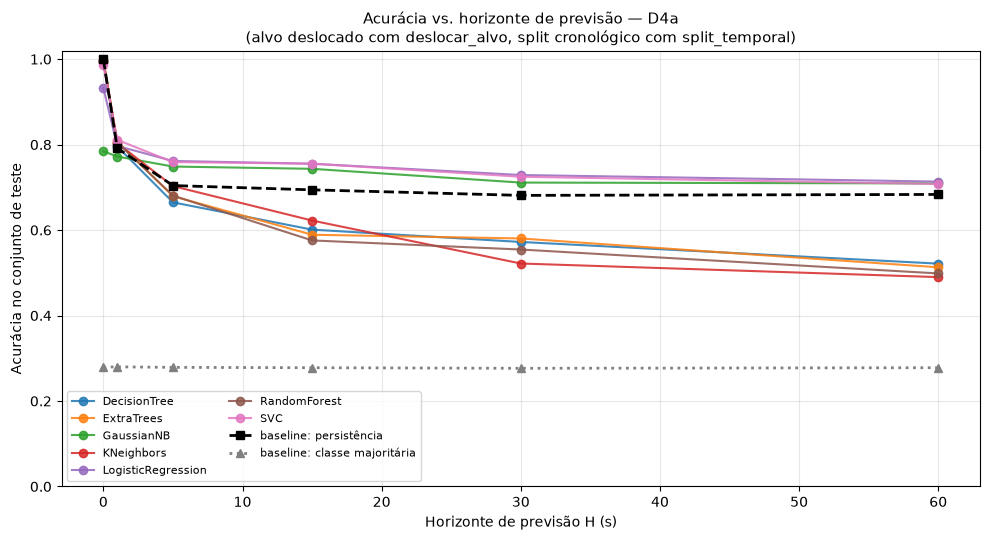

In [397]:
fig, ax = plt.subplots(figsize=(10, 5.5))

for modelo in tabela_pred.index:
    ax.plot(tabela_pred.columns, tabela_pred.loc[modelo], marker='o', alpha=0.85, label=modelo)

ax.plot(baselines_pred.columns, baselines_pred.loc['baseline: persistência'],
        marker='s', linestyle='--', color='black', linewidth=2, label='baseline: persistência')
ax.plot(baselines_pred.columns, baselines_pred.loc['baseline: classe majoritária'],
        marker='^', linestyle=':', color='gray', linewidth=2, label='baseline: classe majoritária')

ax.set_xlabel('Horizonte de previsão H (s)')
ax.set_ylabel('Acurácia no conjunto de teste')
ax.set_title(f'Acurácia vs. horizonte de previsão — {DATASET_PRED} ({metrics_label()})\n'
             f'(alvo deslocado com deslocar_alvo, split cronológico com split_temporal)',
             fontsize=11)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2, loc='lower left')

plt.tight_layout()
plt.savefig(pasta_resultados_pred / 'acuracia_por_horizonte.png', dpi=300, bbox_inches='tight')
plt.show()

## Validação cruzada temporal e artefatos do horizonte de referência

Fecha a seção com o mesmo encadeamento das seções anteriores (validação cruzada
no treino, avaliação no teste, comparação entre as duas), mas com
`TimeSeriesSplit` no lugar do `StratifiedKFold` embaralhado. As matrizes de
confusão, o `summary.txt` e o gráfico de comparação são gravados em
`resultados_am/CenarioPreditivo_{DATASET}_H{H}/`, sem tocar nas pastas das
execuções anteriores.

In [398]:
caso_pred = resultados_pred[H_PRED]

cv_pred = validacao_cruzada_temporal(
    caso_pred['X_treino'], caso_pred['y_treino'], pipelines_preditivos()
)
cv_pred

VALIDAÇÃO CRUZADA TEMPORAL NO TREINO (TimeSeriesSplit, 5 dobras)
LogisticRegression   | Acc: 0.5104 ± 0.0734
KNeighbors           | Acc: 0.5230 ± 0.0267
SVC                  | Acc: 0.5430 ± 0.0877
DecisionTree         | Acc: 0.5324 ± 0.0200
ExtraTrees           | Acc: 0.5269 ± 0.0277
RandomForest         | Acc: 0.5422 ± 0.0180
GaussianNB           | Acc: 0.5446 ± 0.0403


,Model,Acc_mean,Acc_std,Precision,Recall,F1-Score
0,LogisticRegression,0.5104,0.0734,0.5112,0.5201,0.4980
1,KNeighbors,0.5230,0.0267,0.5221,0.5217,0.5147
2,SVC,0.5430,0.0877,0.5300,0.5453,0.5213
3,DecisionTree,0.5324,0.0200,0.5303,0.5306,0.5284
4,ExtraTrees,0.5269,0.0277,0.5245,0.5248,0.5207
5,RandomForest,0.5422,0.0180,0.5400,0.5396,0.5348
6,GaussianNB,0.5446,0.0403,0.5553,0.5500,0.5254


AVALIAÇÃO NO CONJUNTO DE TESTE (DADOS NÃO VISTOS)


────────────────────────────────────────────────────────────────────────────────
Modelo: LogisticRegression
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.76      0.92      0.83       531
           2       0.52      0.24      0.33       203

    accuracy                           0.73       734
   macro avg       0.64      0.58      0.58       734
weighted avg       0.69      0.73      0.69       734


Matriz de Confusão:
[[486  45]
 [154  49]]


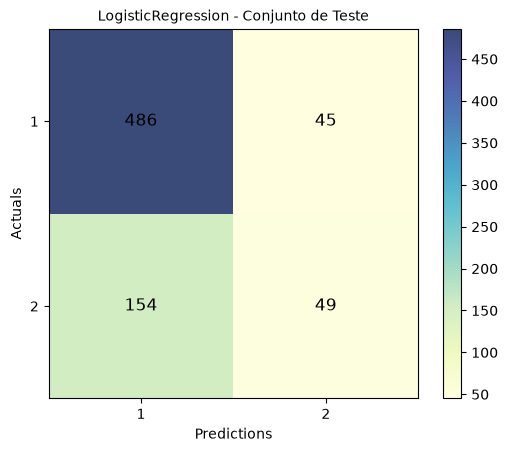


────────────────────────────────────────────────────────────────────────────────
Modelo: KNeighbors
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.72      0.56      0.63       531
           2       0.27      0.42      0.33       203

    accuracy                           0.52       734
   macro avg       0.49      0.49      0.48       734
weighted avg       0.59      0.52      0.55       734


Matriz de Confusão:
[[297 234]
 [117  86]]


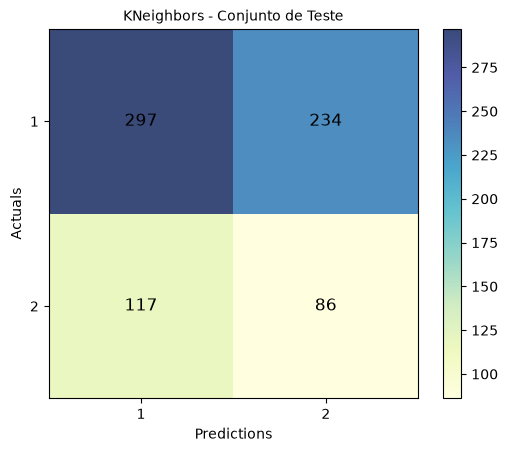


────────────────────────────────────────────────────────────────────────────────
Modelo: SVC
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.77      0.89      0.82       531
           2       0.50      0.29      0.36       203

    accuracy                           0.72       734
   macro avg       0.64      0.59      0.59       734
weighted avg       0.69      0.72      0.70       734


Matriz de Confusão:
[[474  57]
 [145  58]]


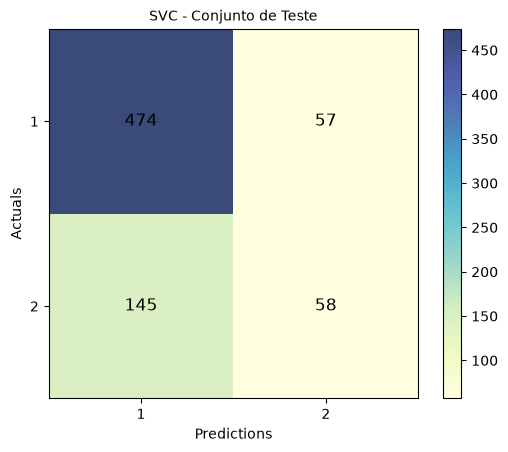


────────────────────────────────────────────────────────────────────────────────
Modelo: DecisionTree
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.75      0.62      0.68       531
           2       0.31      0.45      0.37       203

    accuracy                           0.57       734
   macro avg       0.53      0.54      0.52       734
weighted avg       0.63      0.57      0.59       734


Matriz de Confusão:
[[328 203]
 [111  92]]


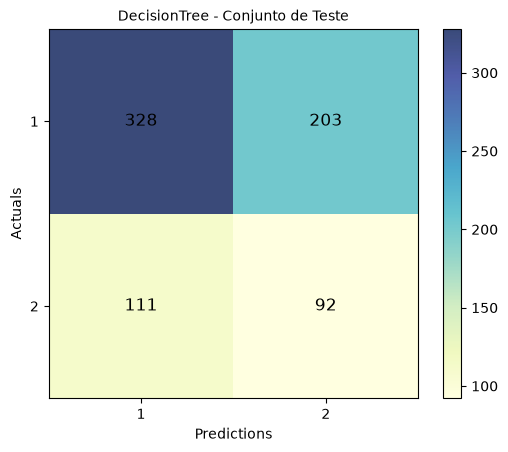


────────────────────────────────────────────────────────────────────────────────
Modelo: ExtraTrees
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.75      0.63      0.68       531
           2       0.32      0.46      0.38       203

    accuracy                           0.58       734
   macro avg       0.54      0.54      0.53       734
weighted avg       0.63      0.58      0.60       734


Matriz de Confusão:
[[332 199]
 [109  94]]


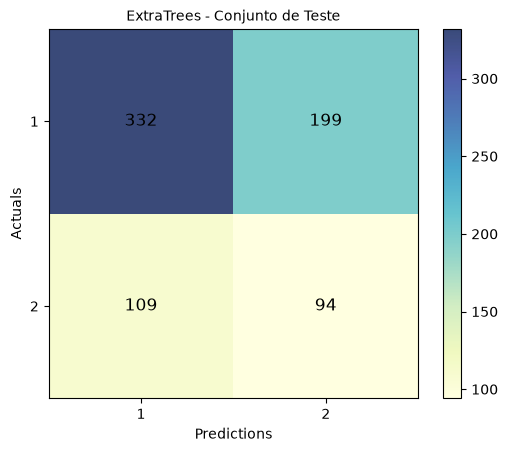


────────────────────────────────────────────────────────────────────────────────
Modelo: RandomForest
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.74      0.59      0.66       531
           2       0.30      0.46      0.36       203

    accuracy                           0.55       734
   macro avg       0.52      0.52      0.51       734
weighted avg       0.62      0.55      0.58       734


Matriz de Confusão:
[[314 217]
 [110  93]]


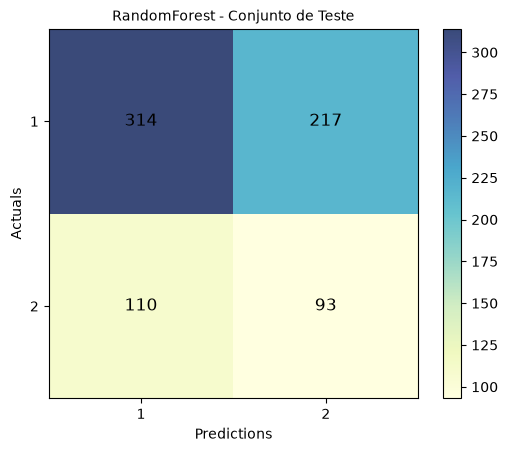


────────────────────────────────────────────────────────────────────────────────
Modelo: GaussianNB
────────────────────────────────────────────────────────────────────────────────

Relatório de Classificação:
              precision    recall  f1-score   support

           1       0.74      0.93      0.82       531
           2       0.43      0.13      0.20       203

    accuracy                           0.71       734
   macro avg       0.58      0.53      0.51       734
weighted avg       0.65      0.71      0.65       734


Matriz de Confusão:
[[496  35]
 [177  26]]


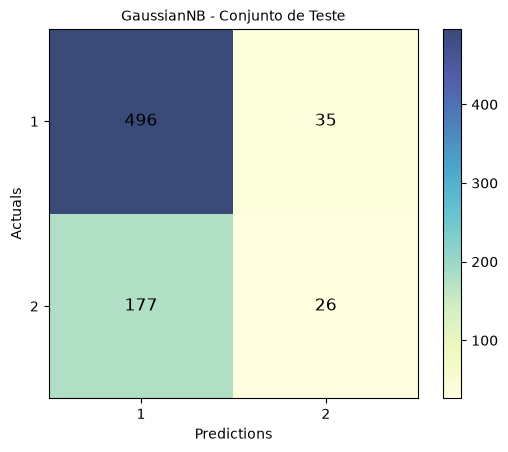


RELATÓRIO RESUMIDO - CONJUNTO DE TESTE
LogisticRegression   | Acc: 0.7289
KNeighbors           | Acc: 0.5218
SVC                  | Acc: 0.7248
DecisionTree         | Acc: 0.5722
ExtraTrees           | Acc: 0.5804
RandomForest         | Acc: 0.5545
GaussianNB           | Acc: 0.7112



In [399]:
test_results_pred = evaluate_on_test(
    caso_pred['X_teste'],
    caso_pred['y_teste'],
    caso_pred['treinados'],
    caso_pred['classes'],
    binary_classification=len(caso_pred['classes']) <= 2,
    result_path=str(pasta_resultados_pred)
)

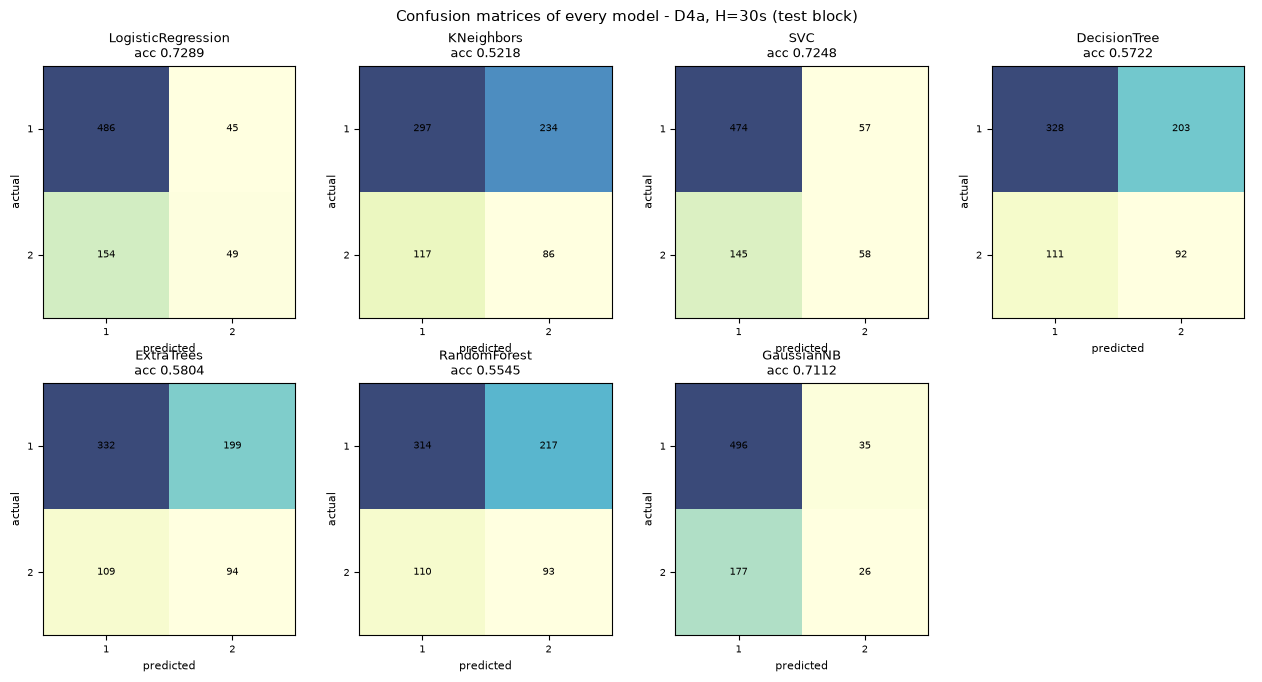

In [400]:
# All the confusion matrices of the previous cell in a single figure.
#   evaluate_on_test draws one figure per model and saves them as mc_<model>.png,
#   which is fine to inspect one model but makes the seven hard to compare. Here
#   the same matrices are laid out side by side, with the actual routes on the
#   rows and the predicted ones on the columns, the same orientation plot_matrix
#   uses.
def plot_confusion_grid(trained_pipelines, X, y, class_labels, title='',
                        columns=4, normalize=False, save_path=None):
    """Confusion matrix of every trained model, side by side in one figure.

    normalize=True divides each row by its support, so the diagonal becomes the
    recall of that route. Worth using when one route dominates the test set and
    the raw counts of the other rows are too small to read.

    Returns the matrices keyed by model name, for inspection afterwards.
    """
    matrices = {}
    for name, pipeline in trained_pipelines.items():
        try:
            matrices[name] = confusion_matrix(y, pipeline.predict(X), labels=class_labels)
        except Exception as erro:
            print(f'{name}: ERRO {erro}')

    if not matrices:
        print('no matrix to show')
        return matrices

    rows = int(np.ceil(len(matrices) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3.2 * columns, 3.4 * rows),
                             squeeze=False)
    ticks = [str(label) for label in class_labels]

    for axis, (name, matrix) in zip(axes.ravel(), matrices.items()):
        shown = matrix.astype(float)
        if normalize:
            support = matrix.sum(axis=1, keepdims=True)
            shown = np.divide(shown, support, out=np.zeros_like(shown), where=support > 0)

        axis.matshow(shown, cmap=plt.cm.YlGnBu, alpha=0.8)
        for i in range(matrix.shape[0]):
            for j in range(matrix.shape[1]):
                texto = f'{shown[i, j]:.2f}' if normalize else f'{matrix[i, j]}'
                axis.text(j, i, texto, ha='center', va='center', fontsize=7)

        axis.set_xticks(range(len(ticks)), ticks, fontsize=7)
        axis.set_yticks(range(len(ticks)), ticks, fontsize=7)
        axis.xaxis.set_ticks_position('bottom')
        total = matrix.sum()
        acuracia = matrix.diagonal().sum() / total if total else float('nan')
        axis.set_title(f'{name}\nacc {acuracia:.4f}', fontsize=9)
        axis.set_xlabel('predicted', fontsize=8)
        axis.set_ylabel('actual', fontsize=8)

    # Sobras da grade, quando o número de modelos não fecha as colunas
    for axis in axes.ravel()[len(matrices):]:
        axis.axis('off')

    if title:
        fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) or '.', exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    return matrices


matrizes_pred = plot_confusion_grid(
    caso_pred['treinados'],
    caso_pred['X_teste'],
    caso_pred['y_teste'],
    caso_pred['classes'],
    title=f'Confusion matrices of every model - {DATASET_PRED} ({metrics_label()}), H={H_PRED}s (test block)',
    save_path=str(pasta_resultados_pred / f'confusion_matrices_H{H_PRED}.png'),
)


COMPARAÇÃO: VALIDAÇÃO CRUZADA vs TESTE

             Model CV_Accuracy Test_Accuracy
LogisticRegression      0.5104        0.7289
        KNeighbors      0.5230        0.5218
               SVC      0.5430        0.7248
      DecisionTree      0.5324        0.5722
        ExtraTrees      0.5269        0.5804
      RandomForest      0.5422        0.5545
        GaussianNB      0.5446        0.7112


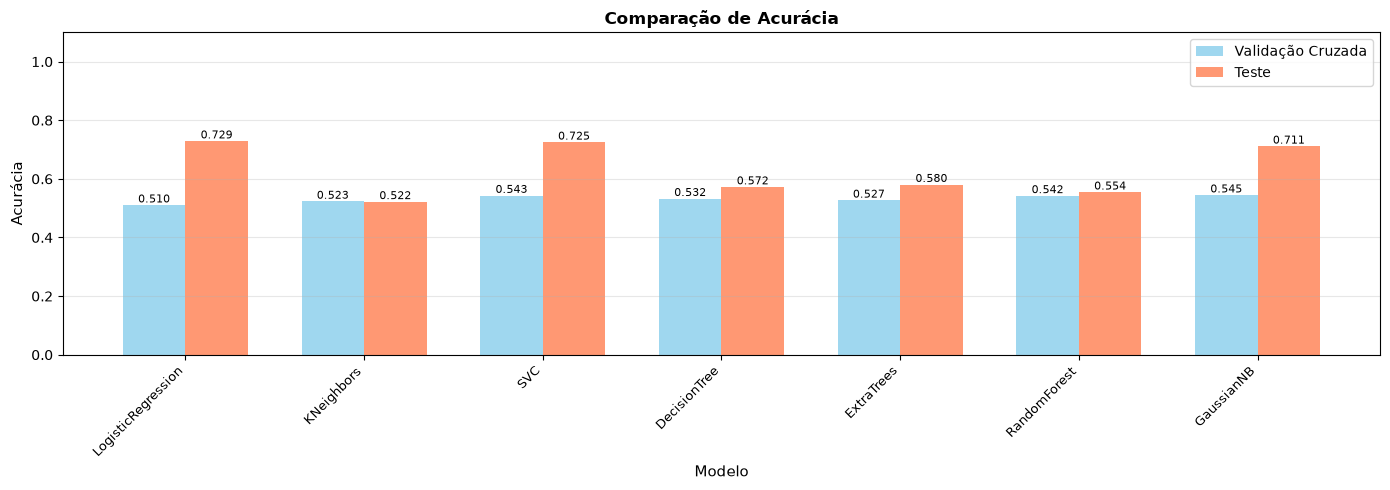


ANÁLISE DE OVERFITTING
LogisticRegression   | CV: 0.5104 | Test: 0.7289 | Diff: -0.2185
KNeighbors           | CV: 0.5230 | Test: 0.5218 | Diff: +0.0012
SVC                  | CV: 0.5430 | Test: 0.7248 | Diff: -0.1818
DecisionTree         | CV: 0.5324 | Test: 0.5722 | Diff: -0.0398
ExtraTrees           | CV: 0.5269 | Test: 0.5804 | Diff: -0.0535
RandomForest         | CV: 0.5422 | Test: 0.5545 | Diff: -0.0123
GaussianNB           | CV: 0.5446 | Test: 0.7112 | Diff: -0.1666


In [401]:
comparacao_pred = compare_train_test_performance(
    cv_pred, test_results_pred, result_path=str(pasta_resultados_pred)
)

## Pruning the tree models

The section grows every tree with scikit-learn's defaults, which means no
pruning at all: `max_depth=None` and `min_samples_leaf=1` let a tree keep
splitting until each leaf is pure. A single anomalous instant then gets a leaf of
its own, which is memorisation rather than learning. D1 shows this in its
smallest possible form: route 3 is the best route in exactly 2 of 3599 instants,
and an unpruned `DecisionTreeClassifier` isolates one of them with a single split
(`h14_h64 > 26.13 -> route 3`), a rule that does not fire for the other one.

Each setting below constrains that in a different way: a floor on how many
samples a leaf must hold, a ceiling on depth, and cost-complexity post-pruning
(`ccp_alpha`), which grows the full tree and then removes the subtrees whose
contribution to purity does not pay for their size.

Besides accuracy and F1-macro, the table reports how many classes the model
actually predicts and the size of the fitted trees, averaged over the ensemble
for the forests. Those two columns are what makes the effect of pruning visible:
accuracy can stay flat while the tree shrinks by two orders of magnitude.

In [402]:
# Pruning settings applied to every tree model. Kept small on purpose: one
#   representative of each family of constraint, so the table stays readable.
PRUNING_GRID = {
    'none (default)': {},
    'min_samples_leaf=3': {'min_samples_leaf': 3},
    'min_samples_leaf=5': {'min_samples_leaf': 5},
    'min_samples_leaf=20': {'min_samples_leaf': 20},
    'min_samples_leaf=40': {'min_samples_leaf': 40},
    'max_depth=2': {'max_depth': 2},
    'max_depth=4': {'max_depth': 4},
    'ccp_alpha=0.001': {'ccp_alpha': 0.001},
}

TREE_MODELS = {
    'DecisionTree': tree.DecisionTreeClassifier,
    'ExtraTrees': ExtraTreesClassifier,
    'RandomForest': RandomForestClassifier,
}


def tree_size(estimator):
    """Depth and leaf count of a fitted tree, averaged over the trees of a forest."""
    trees = getattr(estimator, 'estimators_', [estimator])
    return (float(np.mean([t.get_depth() for t in trees])),
            float(np.mean([t.get_n_leaves() for t in trees])))


def evaluate_tree_pruning(largo, horizon_s=H_PRED, fraction=FRACAO_TREINO_PRED,
                          grid=PRUNING_GRID, random_state=RANDOM_STATE_PRED):
    """Evaluate each tree model under each pruning setting, on the same blocks.

    Uses the protocol of the rest of the section (deslocar_alvo followed by
    split_temporal), so the accuracies are directly comparable with the horizon
    table, and returns the two baselines for reference.

    Returns (table, matrices, labels, reference).
    """
    frame, train, test = pt.preparar_treino_teste(largo, horizon_s, fracao_treino=fraction)
    features = colunas_latencia(frame)

    X = frame[features].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    X_train, y_train = X[train.to_numpy()], y[train.to_numpy()]
    X_test, y_test = X[test.to_numpy()], y[test.to_numpy()]
    labels = sorted(set(y_train.tolist()) | set(y_test.tolist()))

    rows, matrices = [], {}
    for model_name, constructor in TREE_MODELS.items():
        for setting_name, params in grid.items():
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('classifier', constructor(random_state=random_state, **params)),
            ])
            pipeline.fit(X_train, y_train)
            y_pred = pipeline.predict(X_test)

            depth, leaves = tree_size(pipeline.named_steps['classifier'])
            rows.append({
                'model': model_name,
                'pruning': setting_name,
                'accuracy': accuracy_score(y_test, y_pred),
                'recall_macro': recall_score(y_test, y_pred, average='macro', zero_division=0),
                'f1_macro': f1_score(y_test, y_pred, average='macro', zero_division=0),
                'classes_predicted': len(set(y_pred.tolist())),
                'depth': round(depth, 1),
                'leaves': round(leaves, 1),
            })
            matrices[(model_name, setting_name)] = confusion_matrix(
                y_test, y_pred, labels=labels
            )

    table = pd.DataFrame(rows).set_index(['model', 'pruning'])

    persistence = float(
        (frame.loc[test, pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int) == y_test).mean()
    )
    majority_class = int(pd.Series(y_train).value_counts().idxmax())
    reference = {
        'n_test': len(y_test),
        'persistence': persistence,
        'majority': float((y_test == majority_class).mean()),
        'majority_class': majority_class,
    }
    return table, matrices, labels, reference


pruning_table, pruning_matrices, pruning_labels, pruning_reference = \
    evaluate_tree_pruning(largo_pred)

print(f"{DATASET_PRED}, H={H_PRED}s | test block: {pruning_reference['n_test']} instants")
print(f"reference | persistence {pruning_reference['persistence']:.4f} | "
      f"majority class {pruning_reference['majority_class']}: "
      f"{pruning_reference['majority']:.4f}")
pruning_table.round(4)

deslocar_alvo(H=30s): descartando 30/3851 linha(s) sem observacao em t+30s
D4a, H=30s | test block: 734 instants
reference | persistence 0.6812 | majority class 2: 0.2766


accuracy  recall_macro  f1_macro  \
model        pruning                                                 
DecisionTree none (default)         0.5722        0.5355    0.5229   
             min_samples_leaf=3     0.5736        0.5410    0.5267   
             min_samples_leaf=5     0.5381        0.5210    0.5015   
             min_samples_leaf=20    0.5668        0.5226    0.5129   
             min_samples_leaf=40    0.4932        0.4656    0.4534   
             max_depth=2            0.6172        0.6198    0.5868   
             max_depth=4            0.5123        0.4682    0.4612   
             ccp_alpha=0.001        0.5627        0.4817    0.4811   
ExtraTrees   none (default)         0.5804        0.5441    0.5311   
             min_samples_leaf=3     0.6512        0.5825    0.5790   
             min_samples_leaf=5     0.7098        0.6108    0.6159   
             min_samples_leaf=20    0.7112        0.5935    0.5992   
             min_samples_leaf=40    0.7016        0.5930    0.5978   
             max_depth=2            0.6935        0.6010    0.6039   
             max_depth=4            0.7262        0.5962    0.6028   
             ccp_alpha=0.001        0.7248        0.5983    0.6052   
RandomForest none (default)         0.5545        0.5247    0.5101   
             min_samples_leaf=3     0.5477        0.5139    0.5012   
             min_samples_leaf=5     0.5341        0.4939    0.4843   
             min_samples_leaf=20    0.5777        0.5423    0.5290   
             min_samples_leaf=40    0.6063        0.5636    0.5522   
             max_depth=2            0.6390        0.6166    0.5961   
             max_depth=4            0.6730        0.6295    0.6183   
             ccp_alpha=0.001        0.5708        0.5284    0.5180   

                                  classes_predicted  depth  leaves  
model        pruning                                                
DecisionTree none (default)                       2   35.0  1084.0  
             min_samples_leaf=3                   2   31.0   664.0  
             min_samples_leaf=5                   2   27.0   449.0  
             min_samples_leaf=20                  2   18.0   115.0  
             min_samples_leaf=40                  2   11.0    60.0  
             max_depth=2                          2    2.0     4.0  
             max_depth=4                          2    4.0    15.0  
             ccp_alpha=0.001                      2    7.0    20.0  
ExtraTrees   none (default)                       2   35.9  2156.8  
             min_samples_leaf=3                   2   19.3   173.2  
             min_samples_leaf=5                   2   13.4    73.1  
             min_samples_leaf=20                  2    6.6    15.5  
             min_samples_leaf=40                  2    4.4     7.8  
             max_depth=2                          2    2.0     3.9  
             max_depth=4                          2    4.0    13.8  
             ccp_alpha=0.001                      2    4.6     6.0  
RandomForest none (default)                       2   32.7   807.1  
             min_samples_leaf=3                   2   26.0   423.6  
             min_samples_leaf=5                   2   22.7   267.3  
             min_samples_leaf=20                  2   13.5    68.2  
             min_samples_leaf=40                  2    9.8    35.0  
             max_depth=2                          2    2.0     4.0  
             max_depth=4                          2    4.0    14.8  
             ccp_alpha=0.001                      2   19.9    96.7

In [403]:
def recall_by_class(matrices, labels):
    """Recall of every route under every pruning setting.

    Derived from the confusion matrices of the previous cell instead of a new
    fit, so the two cannot disagree. The recall of a route is the diagonal cell
    over the sum of its row: the instants where that route was the right answer
    and the model said so, over all the instants where it was the right answer.

    A route with no instants in the test block has undefined recall and shows
    NaN rather than zero. The recall_macro column of the previous table is the
    plain mean of these columns, which is why a model that predicts a single
    route out of four lands on exactly 0.25.
    """
    rows = []
    for (model_name, setting_name), matrix in matrices.items():
        support = matrix.sum(axis=1)
        row = {'model': model_name, 'pruning': setting_name}
        for label, hits, total in zip(labels, matrix.diagonal(), support):
            row[f'recall_route_{label}'] = hits / total if total else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index(['model', 'pruning'])


pruning_recall = recall_by_class(pruning_matrices, pruning_labels)

# The support is a property of the test block, the same for every row, so it is
#   printed once instead of repeated as columns
support_por_rota = next(iter(pruning_matrices.values())).sum(axis=1)
print(f'{DATASET_PRED}, H={H_PRED}s | instants per route in the test block: '
      f'{ {int(l): int(s) for l, s in zip(pruning_labels, support_por_rota)} }')
pruning_recall.round(4)

D4a, H=30s | instants per route in the test block: {1: 531, 2: 203}


recall_route_1  recall_route_2
model        pruning                                            
DecisionTree none (default)               0.6177          0.4532
             min_samples_leaf=3           0.6139          0.4680
             min_samples_leaf=5           0.5593          0.4828
             min_samples_leaf=20          0.6215          0.4236
             min_samples_leaf=40          0.5273          0.4039
             max_depth=2                  0.6139          0.6256
             max_depth=4                  0.5669          0.3695
             ccp_alpha=0.001              0.6629          0.3005
ExtraTrees   none (default)               0.6252          0.4631
             min_samples_leaf=3           0.7363          0.4286
             min_samples_leaf=5           0.8324          0.3892
             min_samples_leaf=20          0.8569          0.3300
             min_samples_leaf=40          0.8362          0.3498
             max_depth=2                  0.8079          0.3941
             max_depth=4                  0.8870          0.3054
             ccp_alpha=0.001              0.8814          0.3153
RandomForest none (default)               0.5913          0.4581
             min_samples_leaf=3           0.5895          0.4384
             min_samples_leaf=5           0.5838          0.4039
             min_samples_leaf=20          0.6215          0.4631
             min_samples_leaf=40          0.6591          0.4680
             max_depth=2                  0.6667          0.5665
             max_depth=4                  0.7269          0.5320
             ccp_alpha=0.001              0.6234          0.4335

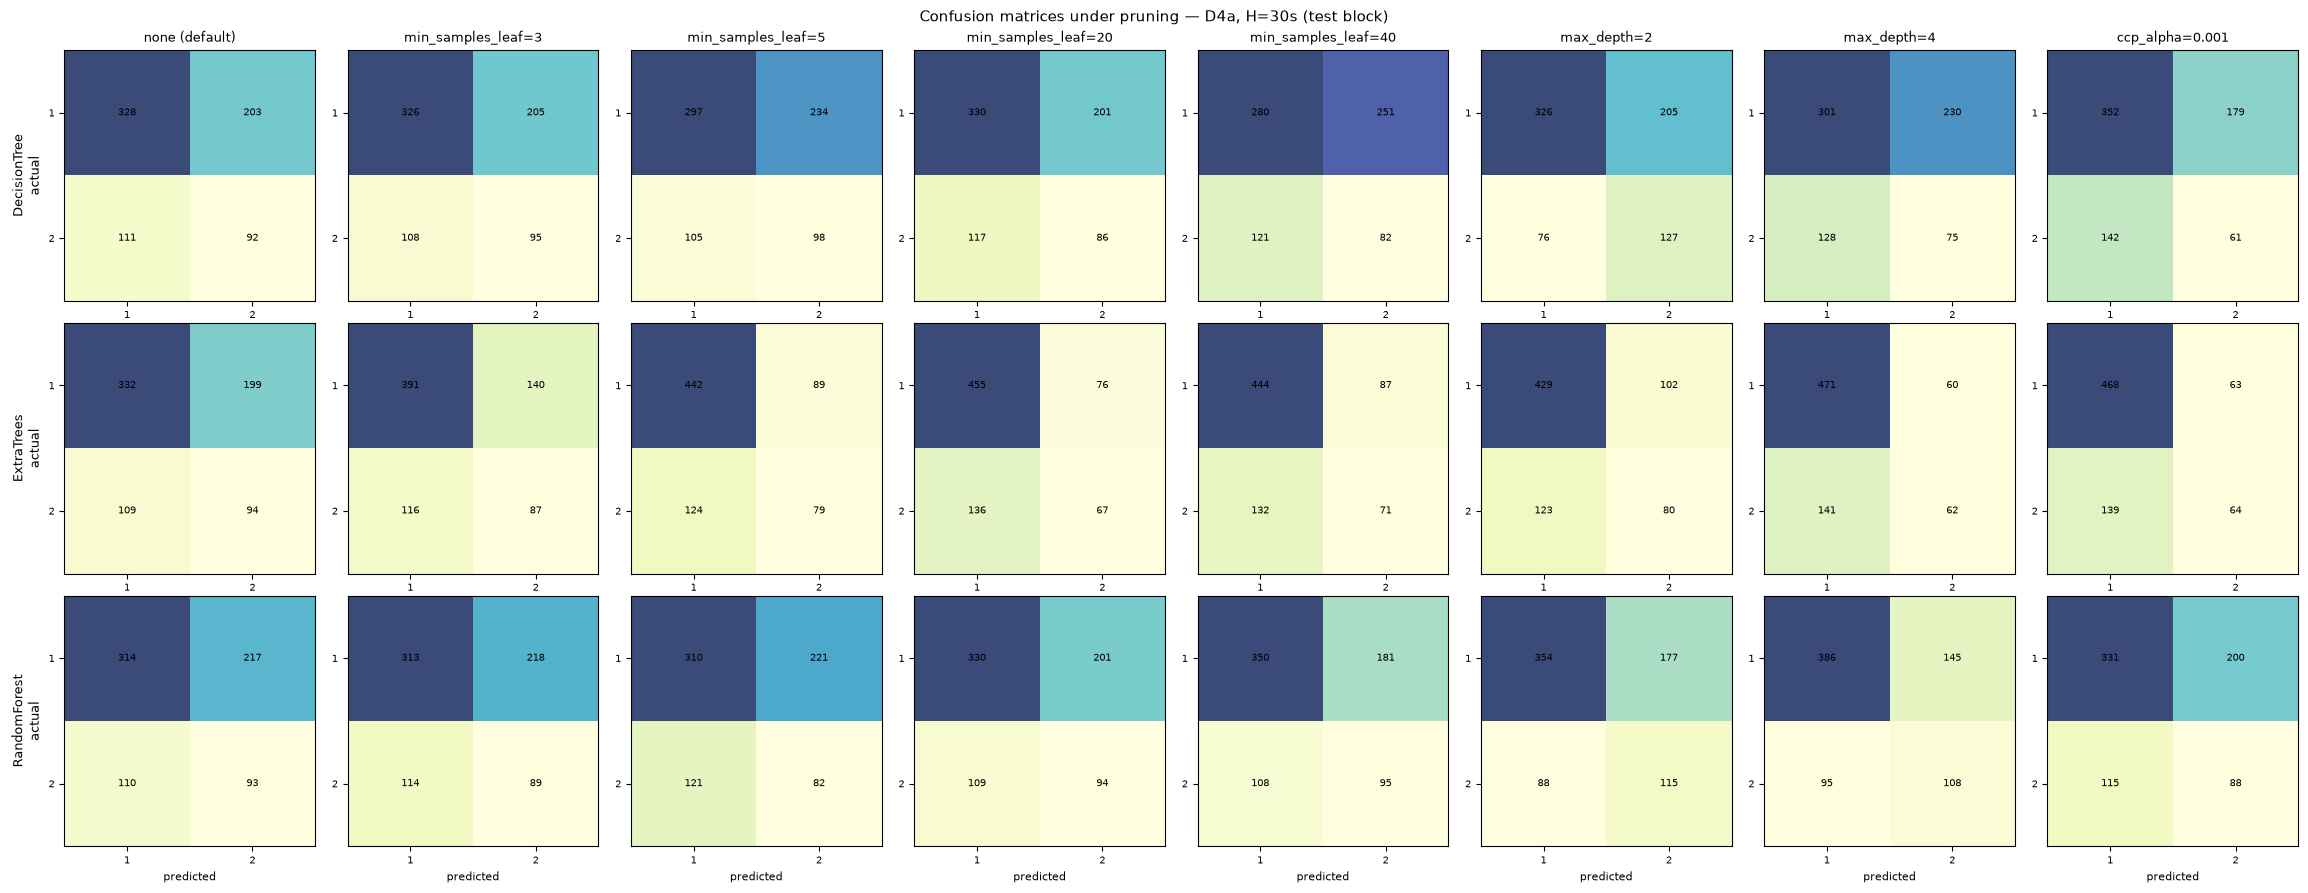

In [404]:
def plot_pruning_confusion_matrices(matrices, labels, path=None):
    """Confusion matrices of the pruning study: one row per model, one column per setting.

    Rows of each matrix are the actual routes and columns the predicted ones, the
    same orientation as plot_matrix. A column that concentrates every count is a
    model that collapsed into predicting a single route.
    """
    models = list(dict.fromkeys(model for model, _ in matrices))
    settings = list(dict.fromkeys(setting for _, setting in matrices))

    fig, axes = plt.subplots(
        len(models), len(settings),
        figsize=(2.9 * len(settings), 3.0 * len(models)),
        squeeze=False,
    )

    for row, model_name in enumerate(models):
        for column, setting_name in enumerate(settings):
            eixo = axes[row][column]
            matriz = matrices[(model_name, setting_name)]
            eixo.matshow(matriz, cmap=plt.cm.YlGnBu, alpha=0.8)

            for i in range(matriz.shape[0]):
                for j in range(matriz.shape[1]):
                    eixo.text(j, i, matriz[i, j], ha='center', va='center', fontsize=7)

            eixo.set_xticks(range(len(labels)), [str(l) for l in labels], fontsize=7)
            eixo.set_yticks(range(len(labels)), [str(l) for l in labels], fontsize=7)
            eixo.xaxis.set_ticks_position('bottom')
            if row == 0:
                eixo.set_title(setting_name, fontsize=9)
            if column == 0:
                eixo.set_ylabel(f'{model_name}\nactual', fontsize=9)
            if row == len(models) - 1:
                eixo.set_xlabel('predicted', fontsize=8)

    fig.suptitle(
        f'Confusion matrices under pruning — {DATASET_PRED} ({metrics_label()}), H={H_PRED}s (test block)',
        fontsize=11,
    )
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


plot_pruning_confusion_matrices(
    pruning_matrices, pruning_labels,
    path=pasta_resultados_pred / f'pruning_confusion_matrices_H{H_PRED}.png',
)

# Setup
This section stablishes the config parameters of the experiment.

In [ ]:
# Target, always read from the label files of datasets/<D>/, never from the store.
#   targets lists them; every experiment below runs once per target, and each
#   target writes to its own results folder.
#   'menor_latencia'           - rotulos_menor_latencia.txt (rotulos_h1_h6_12.txt in
#                                D4a, labels_h1_h6_12.txt in D3a)
#   'menor_latencia_historico' - rotulos_menor_latencia_historico{suffix}.txt
#   'maior_banda'              - rotulos_maior_banda{suffix}.txt


# Feature sets of X, both read from the store:
#   'store: bandwidth features' - every store column but latencia_* and bdp
#   'store: all features'       - every store column, latency included

# Scenario 2: sliding training window. For each evaluated test instant t the models
#   are retrained on the last W seconds of labelled history only.

# Scenario 2 does not evaluate every test instant, only one every WINDOW_STEP seconds
#   of each test block (30: t0, t0 + 30, t0 + 60, ...). Every evaluated instant
#   retrains all the models on its own window, so this sets the runtime of scenario 2
#   and how many instants its metrics rest on: 1 evaluates every instant (about 30
#   times slower than 30), 60 halves the work. Scenario 1 always uses every instant.

# Same threshold as LIMIAR_VARIACAO_PRED: a feature whose coefficient of variation
#   falls below it is constant up to numerical noise. It only labels, never drops.
# Results folder of each target: CenarioPreditivoFS for menor_latencia,
#   CenarioPreditivoFS_<target> for the others

# Results folder of each target: CenarioPreditivoFS for menor_latencia,
#   CenarioPreditivoFS_<target> for the others

In [92]:

datasets = ['D1', 'D2', 'D3', 'D3a', 'D4', 'D4a'] # Datasets evaluated one by one, in this order
targets = ['menor_latencia', 'maior_banda']
feature_sets = ['store: bandwidth features', 'store: all features']
evaluated_models = ['LogisticRegression', 'KNeighbors', 'SVC', 'DecisionTree',
                  'ExtraTrees', 'RandomForest', 'GaussianNB']

horizons = [0, 1, 5, 15, 30, 60]
H_REF = 30

windows = [5, 10, 15, 30, 45, 60]
WINDOW_STEP = 30

TRAIN_FRACTION = 0.8
RANDOM_STATE = 1234
N_JOBS = -1 # CPU cores for those retrainings (-1: all of them); the results do not depend on it

VAR_SMOOTHING = 5e-2
VARIATION_THRESHOLD = 1e-4

feature_sets_colors = dict(zip(feature_sets, FEATURE_SET_PALETTE))

if isinstance(targets, str):  # a single name works too
    targets = [targets]


FEATURES_DIR = PROJECT_ROOT / 'feature_store' / 'data'
DATASETS_DIR = PROJECT_ROOT / 'datasets'

RESULTS_DIR = {
    target: PROJECT_ROOT / 'resultados_am' / (
        'CenarioPreditivoFS' + ('' if target == 'menor_latencia' else f'_{target}'))
    for target in targets }

for _folder in RESULTS_DIR.values():
    _folder.mkdir(parents=True, exist_ok=True)

_missing_fs = [d for d in datasets
               if not (FEATURES_DIR / d / 'csv' / 'consolidado.csv').is_file()]
assert not _missing_fs, (f'no feature store for {_missing_fs}: build it with '
                         f'Feature_Store_Datasets.ipynb (D3a/D4a: fs.construir_dataset(name))')


print(f'datasets     : {datasets}')
print(f'targets      : {targets}')
print(f'feature sets : {feature_sets}')
print(f'scenario 1   : H = {horizons} (reference H={H_REF}s)')
print(f'scenario 2   : W = {windows} x H = {horizons}, '
      f'one instant every {WINDOW_STEP} s')
for _target, _folder in RESULTS_DIR.items():
    print(f'results      : {_folder} ({_target})')

datasets     : ['D1', 'D2', 'D3', 'D3a', 'D4', 'D4a']
targets      : ['menor_latencia', 'maior_banda']
feature sets : ['store: bandwidth features', 'store: all features']
scenario 1   : H = [0, 1, 5, 15, 30, 60] (reference H=30s)
scenario 2   : W = [5, 10, 15, 30, 45, 60] x H = [0, 1, 5, 15, 30, 60], one instant every 30 s
results      : /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPreditivoFS (menor_latencia)
results      : /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPreditivoFS_maior_banda (maior_banda)


# Predictive pipeline with the feature store, dataset by dataset

The section *Pipeline com protocolo preditivo* builds `X` from the raw per-route
CSVs (`latencia_rotas_h1_h6.csv`, `banda_rotas_h1_h6.csv` or
`historico_telemetria_h1_h6.csv`) and evaluates one `DATASET` per run. This section
**adds** a second input and runs the whole evaluation over a list of datasets:

```
datasets = ['D1', 'D2', 'D3', 'D3a', 'D4', 'D4a']
joint analysis of the datasets          -> build report, class distribution, feature variation
for dataset in datasets:
    scenario 1: horizon sweep H         -> models trained once on the whole training block
    scenario 2: training window W       -> models retrained on the last W seconds before t
```

| item | *Pipeline com protocolo preditivo* | this section |
|---|---|---|
| source of `X` | raw per-route CSVs of `datasets/<D>/` | feature store of `feature_store/data/<D>/`, wide layout (`fs.construir_wide`) |
| columns of `X` | one value per (metric, route) | every store feature per route: instant values, 5/15/30 s windows, deltas |
| feature sets | `METRICA_PRED` | `store: bandwidth features` and `store: all features`, side by side |
| target `y` | label file of `ALVO_PRED`, joined by timestamp | **the same label files**, joined by timestamp after moving the store onto the datasets' clock |
| datasets | one `DATASET` per run | `datasets`, in a loop |
| protocol | `pt.preparar_treino_teste` | unchanged |
| models | 7 classifiers + `StandardScaler` | unchanged (`SVC` without `probability=True`, only `predict` is used) |
| baselines | persistence, majority class | unchanged, plus the window majority in scenario 2 |

**Two clocks.** The store writes `ts_epoch` from the raw capture and the CSVs of
`datasets/` from local time, so the same instant differs by a whole number of hours
(3 h in every dataset). Without correcting it the join by timestamp matches no row.
`clock_offset_fs` measures the offset per dataset instead of assuming it, and the
build stops if less than 99% of the store instants find a label.

**Feature sets and leakage.** With the lowest-latency target, `store: all features`
holds the latency of every route, so at `H = 0` the target is the `argmin` of
columns of `X` and the model only has to copy it. That column is a reference, not a
forecast; at `H > 0` past latency is legitimate information. `store: bandwidth
features` (every column but `latencia_*` and `bdp`, the 13 candidates of
`Feature_Store_Datasets.ipynb`) has no such shortcut.

**D3a and D4a** are routes `h11_h61` and `h12_h62` of D3 and D4, with stores built
by `feature_store/build_route_subset.py`. They show the task with two candidate
routes instead of four, are not independent evidence, and should not be averaged
with D3 and D4.

Nothing above is changed: the helpers and results of this section carry the `_fs`
suffix, and every output goes to
`resultados_am/CenarioPreditivoFS/` (with the target appended when it is not
`menor_latencia`).

**Several targets.** `targets` lists the targets to evaluate, e.g.
`['menor_latencia', 'maior_banda']`. `X` is the same for every target
and only `y` changes: each cell runs the experiment once per target, keeps its
results under that target (`best_fs['maior_banda']`, ...) and writes them to the
target's own folder. *Targets side by side*, at the end, compares them.

## Building X and y

For each dataset, `build_dataset_fs`:

1. reads the long store with `fs.get_features` (one row per route and second);
2. pivots it with `fs.construir_wide` into one row per instant and one column
   `<feature>__<route>` per feature and route, once per feature set. Instants where
   a route lacks a feature are dropped, so the two sets do not hold exactly the
   same instants (the latency windows start one second later);
3. moves the store's `ts_epoch` onto the clock of the label file
   (`clock_offset_fs`);
4. joins `melhor_rota` from the label file by `(dataset_id, ts_epoch)`. The label
   file itself is paired with the CSV it was written from row by row and with no
   tolerance (`tolerancia_borda=0`), as in `construir_largo`.

The store's own `melhor_rota` never enters `y`. It is only compared with the label
file as a check of the join: for the lowest-latency target the two are the same
`argmin`, so any disagreement means a misaligned clock.

In [ ]:
# Stem of the CSV each target was written from, and the label files of that target
#   in the order they are tried. '{suffix}' is '' in the four-route datasets and
#   '_12' in D3a and D4a, which also disagree on the latency label name.
TARGET_SOURCES_FS = {
    'menor_latencia': ('latencia_rotas_h1_h6',
                       ['rotulos_menor_latencia{suffix}.txt',
                        'rotulos_h1_h6{suffix}.txt',
                        'labels_h1_h6{suffix}.txt']),
    'menor_latencia_historico': ('latencia_rotas_h1_h6',
                                 ['rotulos_menor_latencia_historico{suffix}.txt']),
    'maior_banda': ('banda_rotas_h1_h6', ['rotulos_maior_banda{suffix}.txt']),
}

# Store columns that are keys, time or targets, never features
STORE_KEYS_FS = {'dataset_id', 'run_id', 'rota_id', 'ts_epoch', 'datetime_utc',
                 'tempo_relativo_s', 'melhor_rota', 'melhor_rota_banda'}


def uses_latency_fs(column):
    return column.startswith('latencia_') or column == 'bdp'


def label_files_fs(dataset, target):
    """CSV and label TXT the target of a dataset was written from."""
    stem, candidates = TARGET_SOURCES_FS[target]
    folder = DATASETS_DIR / dataset
    csvs = sorted(folder.glob(f'{stem}*.csv'))
    if len(csvs) != 1:
        raise FileNotFoundError(f'{folder}: expected one {stem}*.csv, '
                                f'found {[c.name for c in csvs]}')
    suffix = csvs[0].stem[len(stem):]
    for candidate in candidates:
        labels = folder / candidate.format(suffix=suffix)
        if labels.is_file():
            return csvs[0], labels
    raise FileNotFoundError(f'{folder}: none of '
                            f'{[c.format(suffix=suffix) for c in candidates]}')


def target_frame_fs(dataset, target):
    """dataset_id, ts_epoch and melhor_rota of the label file, on the datasets' clock."""
    csv_path, labels_path = label_files_fs(dataset, target)
    frame = pt.largo_de_csv(csv_path, labels_path, grupo=dataset,
                            tolerancia_borda=0, verboso=False)
    return frame[['dataset_id', 'ts_epoch', 'melhor_rota']], labels_path.name


def clock_offset_fs(store_ts, label_ts, max_hours=14):
    """Whole-hour offset between the store clock and the datasets' clock.

    Measured rather than assumed: the number of hours that makes the most instants
    coincide. Returns (offset in seconds, share of the store instants matched).
    """
    store_ts, label_ts = np.unique(store_ts), np.unique(label_ts)
    best = max(range(-max_hours, max_hours + 1),
               key=lambda hours: np.isin(store_ts - hours * 3600, label_ts).sum())
    matched = float(np.isin(store_ts - best * 3600, label_ts).mean())
    return best * 3600, matched


def build_dataset_fs(dataset, target, feature_sets=feature_sets):
    """Wide frames of one dataset, one per feature set, with y from the label file of target.

    Returns (frames keyed by feature set, one row of the build report).
    """
    long = fs.get_features(pasta_origem=str(FEATURES_DIR / dataset))
    long.insert(0, 'dataset_id', dataset)
    store_target = long.groupby('ts_epoch')['melhor_rota'].first().dropna()
    # The store target must not reach construir_wide, which would carry it as y
    long = long.drop(columns=['melhor_rota'])

    columns = [c for c in long.columns if c not in STORE_KEYS_FS and long[c].notna().any()]
    columns_of = {
        'store: bandwidth features': [c for c in columns if not uses_latency_fs(c)],
        'store: all features': columns,
    }

    target_df, labels_name = target_frame_fs(dataset, target)
    offset, matched = clock_offset_fs(long['ts_epoch'].to_numpy(),
                                      target_df['ts_epoch'].to_numpy())
    if matched < 0.99:
        raise ValueError(f'{dataset}: only {matched:.1%} of the store instants match '
                         f'{labels_name} (best offset {offset / 3600:+.0f} h)')

    frames = {}
    for name in feature_sets:
        with contextlib.redirect_stdout(io.StringIO()):
            wide = fs.construir_wide(long, columns_of[name])
        wide['ts_epoch'] = wide['ts_epoch'] - offset
        frames[name] = (wide.merge(target_df, on=['dataset_id', 'ts_epoch'], how='inner')
                            .sort_values('ts_epoch').reset_index(drop=True))

    # Check of the join: the store recomputes the lowest-latency label on its own
    store_target.index = store_target.index - offset
    both = (target_df.set_index('ts_epoch')['melhor_rota'].rename('label').to_frame()
            .join(store_target.rename('store'), how='inner'))

    report = {
        'dataset': dataset,
        'routes': long.rota_id.nunique(),
        'label file': labels_name,
        'clock offset (h)': offset / 3600,
        'store instants': long.ts_epoch.nunique(),
        'label instants': len(target_df),
        'store instants matched': round(matched, 4),
        'store vs label agreement': round(float((both.label == both.store).mean()), 4),
    }
    for name, wide in frames.items():
        report[f'instants | {name}'] = len(wide)
        report[f'columns of X | {name}'] = len(pt.colunas_de_feature(wide))
    return frames, report


_unknown_fs = sorted(set(targets) - set(TARGET_SOURCES_FS))
assert not _unknown_fs, f'unknown target(s) {_unknown_fs}; known: {sorted(TARGET_SOURCES_FS)}'

# WIDE_FS[target][(dataset, feature set)]: X from the store, y from the target's label file
WIDE_FS, build_report_fs = {}, {}
for target in targets:
    WIDE_FS[target], _build_rows_fs = {}, []
    for dataset in datasets:
        frames, report = build_dataset_fs(dataset, target)
        WIDE_FS[target].update({(dataset, name): wide for name, wide in frames.items()})
        _build_rows_fs.append(report)
    build_report_fs[target] = pd.DataFrame(_build_rows_fs).set_index('dataset')
    build_report_fs[target].to_csv(RESULTS_DIR[target] / 'build_report.csv')

_other_target = [t for t in targets if t != 'menor_latencia']
if _other_target:
    print('store vs label agreement compares with the lowest-latency label of the store; '
          f'with {_other_target} it is informative only')
# One column per (target, dataset)
pd.concat({target: report.T for target, report in build_report_fs.items()}, axis=1)

dataset,D1,D2,D3,D3a,D4,D4a
routes,4,4,4,2,4,2
label file,rotulos_menor_latencia.txt,rotulos_menor_latencia.txt,rotulos_menor_latencia.txt,labels_h1_h6_12.txt,rotulos_menor_latencia.txt,rotulos_h1_h6_12.txt
clock offset (h),3.0,3.0,3.0,3.0,3.0,3.0
store instants,3599,3659,3661,3661,3850,3850
label instants,3599,3660,3663,3663,3851,3851
store instants matched,0.9997,0.9997,0.9997,0.9997,0.9997,0.9997
store vs label agreement,1.0,1.0,1.0,1.0,1.0,1.0
instants | store: bandwidth features,3595,3657,3660,3660,3848,3848
columns of X | store: bandwidth features,52,52,52,26,52,26
instants | store: all features,3594,3656,3659,3659,3847,3847


## Joint analysis of the datasets

Before any accuracy: what each dataset gives the models to learn. The first table
shows the target at the reference horizon, over the whole series and over each
chronological block. It uses the same protocol as the evaluation
(`pt.preparar_treino_teste`), on the rows of the first feature set. A dataset where
one route is best in almost every instant has little to predict. When the dominant
route changes between train and test, the majority-class baseline measures the
regime shift rather than the imbalance.

The second table shows how much the features of each set actually vary. A column
whose coefficient of variation is below `VARIATION_THRESHOLD` is constant up to
numerical noise, and `StandardScaler` would promote that noise to unit variance.
This happens to the bandwidth of the idle scenario (D1). The table only flags those
columns; it never drops one.

In [ ]:
def blocks_fs(wide, horizon_s, fraction=TRAIN_FRACTION):
    """Shifted frame and chronological masks, with the drop messages silenced."""
    with contextlib.redirect_stdout(io.StringIO()):
        frame, train, test = pt.preparar_treino_teste(wide, horizon_s, fracao_treino=fraction)
    return frame, train.to_numpy(), test.to_numpy()


def class_summary_fs(target, dataset, horizon_s=H_REF, feature_set=feature_sets[0]):
    frame, train, test = blocks_fs(WIDE_FS[target][(dataset, feature_set)], horizon_s)
    y = frame['melhor_rota'].astype(int)
    row = {'dataset': dataset}
    for name, block in {'full': y, 'train': y[train], 'test': y[test]}.items():
        shares = block.value_counts(normalize=True)
        row[f'{name} n'] = len(block)
        row[f'{name} classes'] = block.nunique()
        row[f'{name} dominant route'] = int(shares.idxmax())
        row[f'{name} dominant %'] = round(100 * shares.max(), 2)
    row['dominant route changes'] = row['train dominant route'] != row['test dominant route']
    return row


def route_shares_fs(target, dataset, horizon_s=H_REF, feature_set=feature_sets[0]):
    frame, train, test = blocks_fs(WIDE_FS[target][(dataset, feature_set)], horizon_s)
    y = frame['melhor_rota'].astype(int)
    return {name: block.value_counts(normalize=True)
            for name, block in {'train': y[train], 'test': y[test]}.items()}


def variation_fs(wide):
    values = wide[pt.colunas_de_feature(wide)]
    return (values.std() / values.mean().abs()).replace([np.inf, -np.inf], np.nan)


class_summary_table_fs, variation_table_fs = {}, {}
for target in targets:
    class_summary_table_fs[target] = pd.DataFrame(
        [class_summary_fs(target, d) for d in datasets]).set_index('dataset')
    class_summary_table_fs[target].to_csv(
        RESULTS_DIR[target] / f'class_distribution_H{H_REF}.csv')

    variation_rows = []
    for (dataset, feature_set), wide in WIDE_FS[target].items():
        cv = variation_fs(wide)
        flagged = cv.index[(cv < VARIATION_THRESHOLD) | cv.isna()]
        variation_rows.append({
            'dataset': dataset, 'feature set': feature_set,
            'columns of X': len(cv), 'constant up to noise': len(flagged),
            'cv min': cv.min(), 'cv median': cv.median(),
            'flagged features': sorted({c.split('__')[0] for c in flagged}),
        })
    variation_table_fs[target] = pd.DataFrame(variation_rows).set_index(['dataset', 'feature set'])
    variation_table_fs[target].to_csv(RESULTS_DIR[target] / 'feature_variation.csv')

    print(f'=== target: {target} ===')
    print(f'Target at H={H_REF}s (rows of {feature_sets[0]!r}):')
    display(class_summary_table_fs[target])
    print('Variation of the features:')
    display(variation_table_fs[target])

Target at H=30s (rows of 'store: bandwidth features'):


,full n,full classes,full dominant route,full dominant %,train n,train classes,train dominant route,train dominant %,test n,test classes,test dominant route,test dominant %,dominant route changes
dataset,,,,,,,,,,,,,
D1,3561,2,4,99.94,2849,2,4,99.93,682,1,4,100.00,False
D2,3624,4,4,83.22,2900,4,4,86.24,695,4,4,71.51,False
D3,3627,4,4,51.72,2902,4,4,49.31,695,4,4,61.58,False
D3a,3627,2,1,68.96,2902,2,1,66.99,695,2,1,77.84,False
D4,3816,4,4,50.13,3053,4,3,53.98,733,4,4,71.49,True
D4a,3816,2,1,52.04,3053,2,2,52.93,733,2,1,72.44,True


Variation of the features:


columns of X  constant up to noise  \
dataset feature set                                                     
D1      store: bandwidth features            52                    36   
        store: all features                 100                    36   
D2      store: bandwidth features            52                     0   
        store: all features                 100                     0   
D3      store: bandwidth features            52                     0   
        store: all features                 100                     0   
D3a     store: bandwidth features            26                     0   
        store: all features                  50                     0   
D4      store: bandwidth features            52                     0   
        store: all features                 100                     0   
D4a     store: bandwidth features            26                     0   
        store: all features                  50                     0   

                                         cv min  cv median  \
dataset feature set                                          
D1      store: bandwidth features  2.517758e-07   0.000004   
        store: all features        2.455600e-07   0.010617   
D2      store: bandwidth features  1.910233e-02   0.441370   
        store: all features        1.908082e-02   0.388631   
D3      store: bandwidth features  1.957035e-02   0.761218   
        store: all features        1.954968e-02   1.097965   
D3a     store: bandwidth features  1.495616e-01   0.859502   
        store: all features        1.495818e-01   1.360685   
D4      store: bandwidth features  2.487263e-02   0.628787   
        store: all features        2.486035e-02   0.711828   
D4a     store: bandwidth features  1.843142e-01   1.127913   
        store: all features        1.843320e-01   0.772977   

                                                                                                                                                                                                                    flagged features  
dataset feature set                                                                                                                                                                                                                   
D1      store: bandwidth features  [banda_delta_micro_longa, banda_media_Mbps, banda_media_curta_15s, banda_media_longa_30s, banda_media_micro_5s, gargalo_Mbps, gargalo_min_curta_15s, gargalo_min_longa_30s, gargalo_min_micro_5s]  
        store: all features        [banda_delta_micro_longa, banda_media_Mbps, banda_media_curta_15s, banda_media_longa_30s, banda_media_micro_5s, gargalo_Mbps, gargalo_min_curta_15s, gargalo_min_longa_30s, gargalo_min_micro_5s]  
D2      store: bandwidth features                                                                                                                                                                                                 []  
        store: all features                                                                                                                                                                                                       []  
D3      store: bandwidth features                                                                                                                                                                                                 []  
        store: all features                                                                                                                                                                                                       []  
D3a     store: bandwidth features                                                                                                                                                                                                 []  
        store: all features                                     

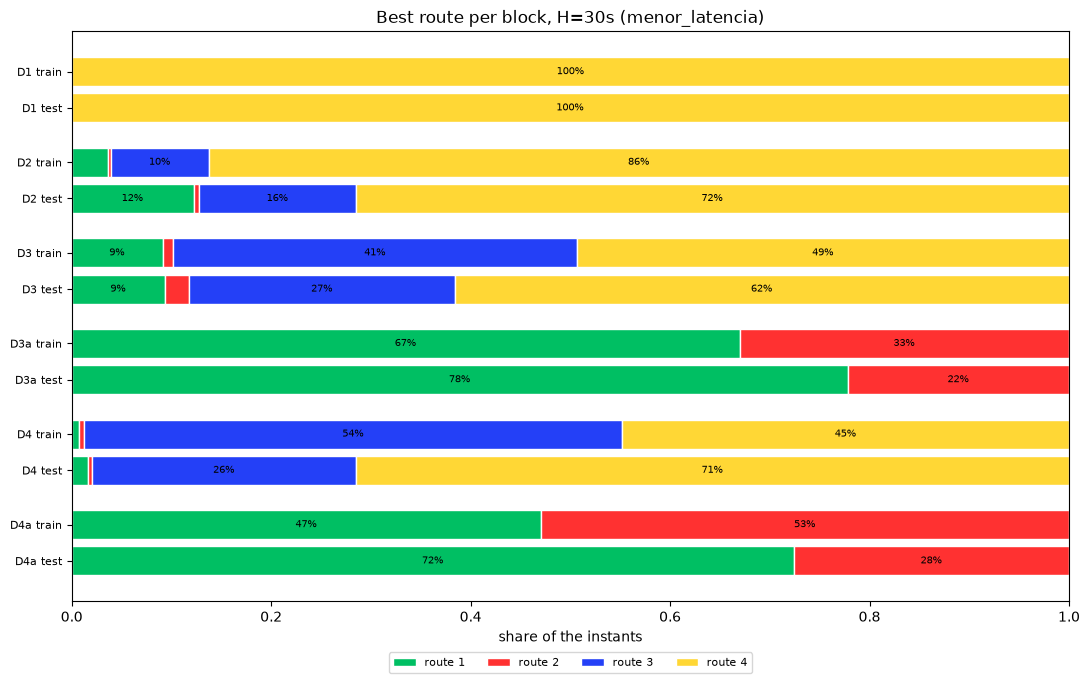

In [ ]:
# Share of each route in the training and test blocks, one bar pair per dataset
for target in targets:
    plot_block_shares_fs({dataset: route_shares_fs(target, dataset) for dataset in datasets},
                         f'Best route per block, H={H_REF}s ({target})',
                         path=RESULTS_DIR[target] / f'class_distribution_H{H_REF}.png')

## Model evaluation, dataset by dataset

The loop below runs both scenarios for every dataset and every feature set:

**Scenario 1, horizon sweep.** For each `H` in `horizons`, `pt.preparar_treino_teste`
shifts the target to `t + H` and cuts each dataset chronologically (first 80% to
train, last 20% to test, with a gap of `H` seconds between them). Every model is
trained **once** on the whole training block and measured on the whole test block,
next to the two baselines: **persistence** (the best route in `H` seconds is the
best route now) and the **majority class** of the training block.

**Scenario 2, training window `W`.** Instead of everything up to `t`, the models
see only the last `W` seconds. For each evaluated test instant `t` they are
retrained from scratch on the pairs `(X(τ), y(τ + H))` whose label had already been
observed at `t`, and then predict `y(t + H)` from `X(t)`:

    t − H − W  <  τ  ≤  t − H        (τ ≤ t − 1 when H = 0)

A window holds at most `W` samples, fewer where the series has gaps. It may reach
back into the training block or into the gap before the test block, which is fine:
those instants are in the past of `t`. Over a few seconds the best route rarely
changes, so many windows hold a single label. Those windows predict that label
directly, for every model, since most classifiers cannot be fitted on one class.
For that reason the **window majority** (the most frequent label of the window) is
reported as a third baseline: it is what a sliding-window learner gets without
using `X`. Only one test instant every `WINDOW_STEP` seconds is evaluated,
because every one of them refits every model.

A training block with a single class makes some models fail; they get `NaN`
instead of stopping the loop.

In [ ]:
def make_pipelines_fs(names=evaluated_models, random_state=RANDOM_STATE, n_jobs=-1,
                      n_samples=None):
    """The 7 classifiers of the predictive section, each preceded by a StandardScaler.

    n_samples: size of the training set when it is known to be small (scenario 2);
    KNN cannot ask for more neighbours than there are samples.
    """
    neighbours = 5 if n_samples is None else max(1, min(5, n_samples))
    catalogue = {
        'LogisticRegression': lambda: LogisticRegression(max_iter=1000),
        'KNeighbors': lambda: KNeighborsClassifier(n_neighbors=neighbours),
        'SVC': lambda: svm.SVC(random_state=random_state),
        'DecisionTree': lambda: tree.DecisionTreeClassifier(random_state=random_state),
        'ExtraTrees': lambda: ExtraTreesClassifier(random_state=random_state, n_jobs=n_jobs),
        'RandomForest': lambda: RandomForestClassifier(random_state=random_state, n_jobs=n_jobs),
        'GaussianNB': lambda: GaussianNB(var_smoothing=VAR_SMOOTHING),
    }
    return {name: Pipeline([('scaler', StandardScaler()), ('classifier', catalogue[name]())])
            for name in names}


def evaluate_full_block_fs(wide, horizon_s, evaluated_models=evaluated_models):
    """Scenario 1: train once on the training block, measure on the test block."""
    frame, train, test = blocks_fs(wide, horizon_s)
    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    X_train, y_train, X_test, y_test = X[train], y[train], X[test], y[test]

    rows = []
    for name, model in make_pipelines_fs(evaluated_models).items():
        try:
            y_pred = model.fit(X_train, y_train).predict(X_test)
            accuracy = accuracy_score(y_test, y_pred)
            f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
        except ValueError as error:
            print(f'    {name}: not trained ({error})')
            accuracy = f1 = np.nan
        rows.append({'model': name, 'accuracy': accuracy, 'f1_macro': f1})

    majority_class = int(pd.Series(y_train).value_counts().idxmax())
    return {
        'results': pd.DataFrame(rows),
        'persistence': float((current[test] == y_test).mean()),
        'majority': float((y_test == majority_class).mean()),
        'n_train': len(y_train),
        'n_test': len(y_test),
    }


def evaluate_window_instant_fs(X_window, y_window, x_now, evaluated_models=evaluated_models):
    """Predictions of every model retrained on one window, plus the window majority."""
    labels, counts = np.unique(y_window, return_counts=True)
    majority = int(labels[counts.argmax()])  # a tie goes to the lowest route number
    out = {'window_majority': majority, 'single_class': len(labels) == 1, 'fallback': 0}

    for name, model in make_pipelines_fs(evaluated_models, n_jobs=1, n_samples=len(y_window)).items():
        if len(labels) == 1:
            out[name] = majority
            continue
        try:
            out[name] = int(model.fit(X_window, y_window).predict(x_now[None, :])[0])
        except ValueError:
            # e.g. a class with too few samples for the model; counted, not hidden
            out[name] = majority
            out['fallback'] += 1
    return out


def run_training_window_fs(wide, horizon_s, window_sizes=windows,
                           step_s=WINDOW_STEP, evaluated_models=evaluated_models,
                           n_jobs=N_JOBS):
    """Scenario 2: one prediction per evaluated test instant, model and window size."""
    ordered = wide.sort_values(['dataset_id', 'ts_epoch']).reset_index(drop=True)
    frame, _, test = blocks_fs(ordered, horizon_s)

    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    ts = frame['ts_epoch'].to_numpy()
    # Last instant whose label is known at t: t - H, or t - 1 when H = 0
    last_known = max(horizon_s, 1)

    rows = []
    for dataset, positions in frame.groupby('dataset_id').indices.items():
        positions = positions[np.argsort(ts[positions])]
        ts_d = ts[positions]
        evaluated = positions[test[positions]][::step_s]

        for W in window_sizes:
            cases = []  # (evaluated instant, positions of its window)
            for i in evaluated:
                upper = ts[i] - last_known
                start = np.searchsorted(ts_d, upper - W, side='right')
                stop = np.searchsorted(ts_d, upper, side='right')
                if stop > start:
                    cases.append((i, positions[start:stop]))

            outputs = Parallel(n_jobs=n_jobs)(
                delayed(evaluate_window_instant_fs)(X[w], y[w], X[i], evaluated_models)
                for i, w in cases
            )
            for (i, w), out in zip(cases, outputs):
                rows.append({'dataset': dataset, 'ts_epoch': int(ts[i]), 'window_s': W,
                             'n_train': len(w), 'y_true': int(y[i]),
                             'persistence': int(current[i]), **out})
    return pd.DataFrame(rows)


print('evaluation helpers defined')

evaluation helpers defined


In [ ]:
sweep_fs, sweep_baselines_fs, window_predictions_fs = {}, {}, {}

for target in targets:
    sweep_rows, baseline_rows, window_parts = [], [], []
    for dataset in datasets:
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            started = time.time()

            # Scenario 1: horizon sweep, whole training block
            for H in horizons:
                result = evaluate_full_block_fs(wide, H)
                sweep_rows.append(result['results'].assign(
                    dataset=dataset, feature_set=feature_set, horizon_s=H))
                baseline_rows.append({
                    'dataset': dataset, 'feature_set': feature_set, 'horizon_s': H,
                    'persistence': result['persistence'], 'majority': result['majority'],
                    'n_train': result['n_train'], 'n_test': result['n_test'],
                })

            # Scenario 2: sliding training window
            for H in horizons:
                part = run_training_window_fs(wide, H)
                part.insert(0, 'horizon_s', H)
                part.insert(0, 'feature_set', feature_set)
                window_parts.append(part)

            print(f'{target:24s} | {dataset:4s} | {feature_set:26s} | '
                  f'{len(pt.colunas_de_feature(wide)):3d} columns | {len(wide):5d} instants '
                  f'| {time.time() - started:6.1f} s')

    sweep_fs[target] = pd.concat(sweep_rows, ignore_index=True)[
        ['dataset', 'feature_set', 'horizon_s', 'model', 'accuracy', 'f1_macro']]
    sweep_baselines_fs[target] = pd.DataFrame(baseline_rows)
    window_predictions_fs[target] = pd.concat(window_parts, ignore_index=True)

    results_dir = RESULTS_DIR[target]
    sweep_fs[target].to_csv(results_dir / 'sweep_accuracy.csv', index=False)
    sweep_baselines_fs[target].to_csv(results_dir / 'sweep_baselines.csv', index=False)
    window_predictions_fs[target].to_csv(results_dir / 'window_predictions.csv', index=False)
    print(f'saved to {results_dir}')

D1   | store: bandwidth features  |  52 columns |  3595 instants |   11.2 s
D1   | store: all features        | 100 columns |  3594 instants |    8.2 s
D2   | store: bandwidth features  |  52 columns |  3657 instants |   65.1 s
D2   | store: all features        | 100 columns |  3656 instants |   80.7 s
D3   | store: bandwidth features  |  52 columns |  3660 instants |   73.1 s
D3   | store: all features        | 100 columns |  3659 instants |  114.1 s
D3a  | store: bandwidth features  |  26 columns |  3660 instants |  133.5 s
D3a  | store: all features        |  50 columns |  3659 instants |  132.1 s
D4   | store: bandwidth features  |  52 columns |  3848 instants |  123.3 s
D4   | store: all features        | 100 columns |  3847 instants |  158.4 s
D4a  | store: bandwidth features  |  26 columns |  3848 instants |  122.2 s
D4a  | store: all features        |  50 columns |  3847 instants |  120.6 s
saved to /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPred

## Scenario 1: horizon sweep

The best model of each `(dataset, feature set, H)` next to the two baselines. The
success criterion is not the absolute accuracy but the **gain over persistence**: a
model that does not beat "the best route in `H` seconds is the best route now" does
not predict anything a reactive controller would not get for free. At `H = 0`
persistence is 1.0 by construction, so that column only isolates the effect of
the chronological split.

In [ ]:
_keys_fs = ['dataset', 'feature_set', 'horizon_s']
best_fs = {}
for target in targets:
    best = (sweep_fs[target].dropna(subset=['accuracy'])
            .sort_values('accuracy', ascending=False)
            .drop_duplicates(_keys_fs)
            .merge(sweep_baselines_fs[target], on=_keys_fs)
            .rename(columns={'model': 'best model'}))
    best['gain over persistence'] = best['accuracy'] - best['persistence']
    best_fs[target] = best.set_index(_keys_fs).sort_index().reindex(datasets, level=0)
    best_fs[target].to_csv(RESULTS_DIR[target] / 'sweep_best_model.csv')

    baselines = sweep_baselines_fs[target]
    print(f'=== target: {target} ===')
    print('Accuracy of the best model, by horizon (persistence and majority class below):')
    display(best_fs[target]['accuracy'].unstack('horizon_s').round(4))
    display(baselines[baselines.feature_set == feature_sets[0]]
            .set_index(['dataset', 'horizon_s'])[['persistence', 'majority']]
            .stack().unstack('horizon_s').reindex(datasets, level=0).round(4))

    print('Gain of the best model over persistence:')
    display(best_fs[target]['gain over persistence'].unstack('horizon_s').round(4))

Accuracy of the best model, by horizon (persistence and majority class below):


horizon_s                              0       1       5       15      30  \
dataset feature_set                                                         
D1      store: all features        1.0000  1.0000  1.0000  1.0000  1.0000   
        store: bandwidth features  1.0000  1.0000  1.0000  1.0000  1.0000   
D2      store: all features        0.9808  0.7380  0.7113  0.7153  0.7151   
        store: bandwidth features  0.7510  0.7133  0.7113  0.7153  0.7151   
D3      store: all features        0.9808  0.7174  0.6152  0.6199  0.6173   
        store: bandwidth features  0.7579  0.6685  0.6138  0.6157  0.6158   
D3a     store: all features        0.9918  0.8519  0.7683  0.7742  0.7784   
        store: bandwidth features  0.7962  0.7959  0.7683  0.7756  0.7784   
D4      store: all features        0.9766  0.7940  0.7493  0.7627  0.7432   
        store: bandwidth features  0.7971  0.7797  0.7392  0.7603  0.7517   
D4a     store: all features        0.9857  0.8096  0.7690  0.7680  0.7664   
        store: bandwidth features  0.8153  0.7901  0.7746  0.7670  0.7681   

horizon_s                              60  
dataset feature_set                        
D1      store: all features        1.0000  
        store: bandwidth features  1.0000  
D2      store: all features        0.7162  
        store: bandwidth features  0.7162  
D3      store: all features        0.6237  
        store: bandwidth features  0.6206  
D3a     store: all features        0.7785  
        store: bandwidth features  0.7785  
D4      store: all features        0.7011  
        store: bandwidth features  0.7145  
D4a     store: all features        0.7155  
        store: bandwidth features  0.7174

horizon_s                0       1       5       15      30      60
dataset                                                            
D1      persistence  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
        majority     1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
D2      persistence  1.0000  0.6763  0.5552  0.5498  0.5353  0.5615
        majority     0.7141  0.7133  0.7113  0.7153  0.7151  0.7162
D3      persistence  1.0000  0.6247  0.4483  0.4362  0.4417  0.5175
        majority     0.6088  0.6096  0.6138  0.6157  0.6158  0.6131
D3a     persistence  1.0000  0.6658  0.6538  0.6522  0.6043  0.6904
        majority     0.7661  0.7658  0.7683  0.7742  0.7784  0.7785
D4      persistence  1.0000  0.7601  0.6527  0.6551  0.6398  0.6686
        majority     0.2601  0.2608  0.2621  0.2597  0.2647  0.2697
D4a     persistence  1.0000  0.7927  0.7025  0.6951  0.6794  0.6815
        majority     0.2796  0.2803  0.2805  0.2770  0.2756  0.2812

Gain of the best model over persistence:


horizon_s                              0       1       5       15      30  \
dataset feature_set                                                         
D1      store: all features        0.0000  0.0000  0.0000  0.0000  0.0000   
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  0.0000   
D2      store: all features       -0.0192  0.0617  0.1561  0.1655  0.1799   
        store: bandwidth features -0.2490  0.0370  0.1561  0.1655  0.1799   
D3      store: all features       -0.0192  0.0933  0.1669  0.1837  0.1755   
        store: bandwidth features -0.2421  0.0438  0.1655  0.1795  0.1741   
D3a     store: all features       -0.0082  0.1852  0.1145  0.1220  0.1741   
        store: bandwidth features -0.2038  0.1301  0.1145  0.1234  0.1741   
D4      store: all features       -0.0234  0.0339  0.0958  0.1080  0.1025   
        store: bandwidth features -0.2029  0.0196  0.0865  0.1052  0.1119   
D4a     store: all features       -0.0143  0.0169  0.0656  0.0733  0.0861   
        store: bandwidth features -0.1847 -0.0026  0.0721  0.0719  0.0887   

horizon_s                              60  
dataset feature_set                        
D1      store: all features        0.0000  
        store: bandwidth features  0.0000  
D2      store: all features        0.1548  
        store: bandwidth features  0.1548  
D3      store: all features        0.1062  
        store: bandwidth features  0.1032  
D3a     store: all features        0.0880  
        store: bandwidth features  0.0880  
D4      store: all features        0.0316  
        store: bandwidth features  0.0459  
D4a     store: all features        0.0345  
        store: bandwidth features  0.0359

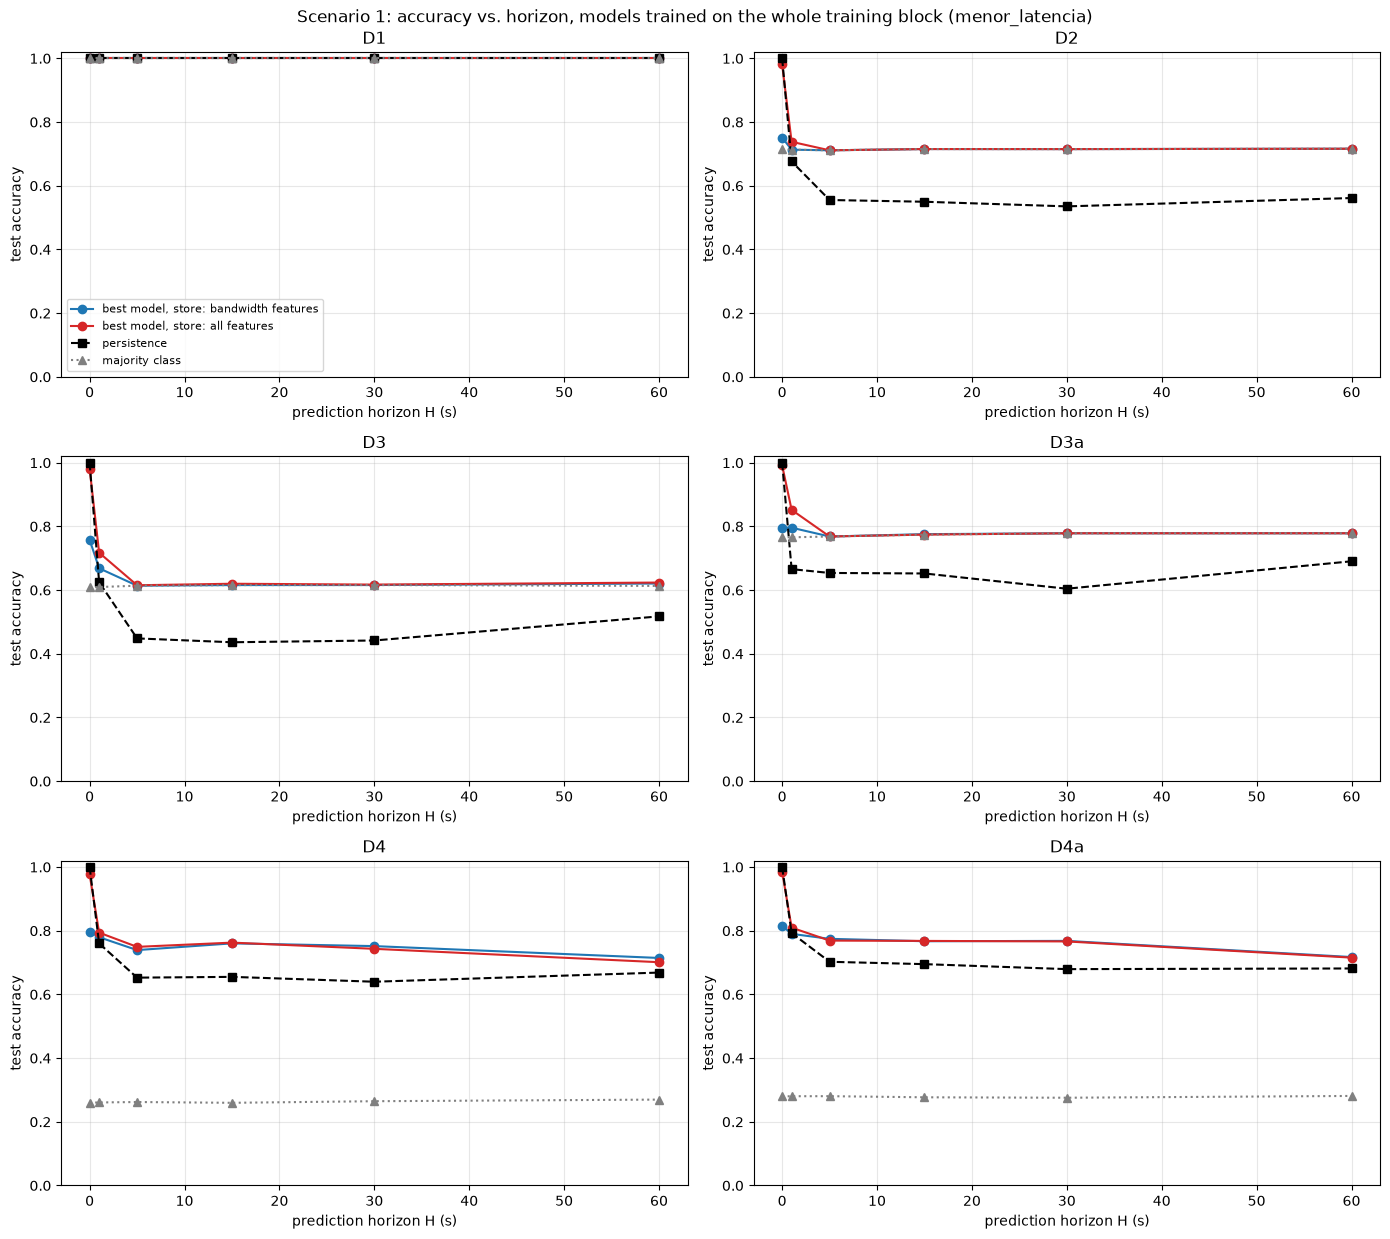

In [ ]:
for target in targets:
    plot_sweep_accuracy_fs(
        best_fs[target], sweep_baselines_fs[target], datasets, feature_sets,
        feature_sets_colors,
        f'Scenario 1: accuracy vs. horizon, models trained on the whole training block '
        f'({target})',
        path=RESULTS_DIR[target] / 'sweep_best_model.png')

### Scenario 1: confusion matrices and metrics beyond accuracy

Accuracy hides the class imbalance: in a dataset where one route is best in 70% of
the instants, a model that always answers that route scores 0.70. The metrics below
do not reward that:

| metric | what it measures | always predicting the majority route gives |
|---|---|---|
| `balanced_accuracy` | mean recall over the routes present in the test block | 1 / number of routes |
| `precision_macro`, `recall_macro`, `f1_macro` | mean over the routes, each route weighing the same | low, since the minority routes score 0 |
| `mcc` | Matthews correlation between predicted and actual routes, from −1 to 1 | 0 |

The loop of scenario 1 only kept accuracy and F1-macro, so the cell below retrains
the same models on the same blocks, this time keeping every prediction. The two
baselines are scored as predictors too, on the same instants: **persistence**
(the route of `t`) and the **majority class** of the training block. A check at the
end confirms that the retrained models reproduce the accuracies of the loop.

When the test block holds a single route (D1), `mcc` is undefined and scikit-learn reports 0 even for a perfect model; read D1 on the other metrics.

In [ ]:
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef

# Horizons retrained here; list(horizons) reproduces the whole sweep
PREDICTION_HORIZONS_FS = list(horizons)

METRICS_FS = ['accuracy', 'balanced_accuracy', 'precision_macro', 'recall_macro',
              'f1_macro', 'mcc']
BASELINES_FS = ['persistence', 'majority']


def classification_metrics_fs(y_true, y_pred):
    """Every metric of METRICS_FS for one set of predictions."""
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(y_true, y_pred),
    }


def predict_full_block_fs(wide, horizon_s, evaluated_models=evaluated_models):
    """Scenario 1 again, returning one row per test instant with every prediction.

    Same blocks and same models as evaluate_full_block_fs. A model that cannot be
    trained (single-class training block) gets NaN predictions.
    """
    frame, train, test = blocks_fs(wide, horizon_s)
    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    majority_class = int(pd.Series(y[train]).value_counts().idxmax())

    out = pd.DataFrame({
        'ts_epoch': frame['ts_epoch'].to_numpy()[test],
        'y_true': y[test],
        'persistence': current[test],
        'majority': majority_class,
    })
    for name, model in make_pipelines_fs(evaluated_models).items():
        try:
            out[name] = model.fit(X[train], y[train]).predict(X[test])
        except ValueError as error:
            print(f'    {name}: not trained ({error})')
            out[name] = np.nan
    return out


sweep_predictions_fs = {}
for target in targets:
    parts = []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            for H in PREDICTION_HORIZONS_FS:
                part = predict_full_block_fs(WIDE_FS[target][(dataset, feature_set)], H)
                part.insert(0, 'horizon_s', H)
                part.insert(0, 'feature_set', feature_set)
                part.insert(0, 'dataset', dataset)
                parts.append(part)
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    sweep_predictions_fs[target] = pd.concat(parts, ignore_index=True)
    sweep_predictions_fs[target].to_csv(RESULTS_DIR[target] / 'sweep_predictions.csv',
                                        index=False)


def metrics_table_fs(predictions, keys, predictors):
    """One row per (case, predictor) with every metric of METRICS_FS."""
    rows = []
    for case, group in predictions.groupby(keys):
        case = dict(zip(keys, case if isinstance(case, tuple) else (case,)))
        for predictor in predictors:
            valid = group[predictor].notna()
            if not valid.any():
                continue
            rows.append({**case, 'predictor': predictor, 'instants': int(valid.sum()),
                         **classification_metrics_fs(group.y_true[valid],
                                                     group[predictor][valid].astype(int))})
    return pd.DataFrame(rows)


sweep_metrics_fs = {}
for target in targets:
    metrics = metrics_table_fs(sweep_predictions_fs[target],
                               ['dataset', 'feature_set', 'horizon_s'],
                               evaluated_models + BASELINES_FS)
    sweep_metrics_fs[target] = metrics
    metrics.to_csv(RESULTS_DIR[target] / 'sweep_metrics.csv', index=False)

    # The retrained models must reproduce the accuracies of the loop
    check = metrics.merge(
        sweep_fs[target].rename(columns={'model': 'predictor', 'accuracy': 'loop_accuracy'}),
        on=['dataset', 'feature_set', 'horizon_s', 'predictor'])
    print(f'=== target: {target} ===')
    print(f'largest accuracy difference against the loop: '
          f'{(check.accuracy - check.loop_accuracy).abs().max():.2e} '
          f'over {len(check)} cases')

    print(f'Every metric at the reference horizon H={H_REF}s:')
    display(metrics[metrics.horizon_s == H_REF]
            .set_index(['dataset', 'feature_set', 'predictor'])[METRICS_FS]
            .reindex(datasets, level=0).round(3))

D1   |   16.7 s
D2   |   58.5 s
D3   |  526.6 s
D3a  |   12.5 s
D4   |   36.7 s
D4a  |   15.1 s
largest accuracy difference against the loop: 0.00e+00 over 504 cases

Every metric at the reference horizon H=30s:


accuracy  \
dataset feature_set               predictor                      
D1      store: all features       LogisticRegression     1.000   
                                  KNeighbors             1.000   
                                  SVC                    1.000   
                                  DecisionTree           1.000   
                                  ExtraTrees             1.000   
...                                                        ...   
D4a     store: bandwidth features ExtraTrees             0.730   
                                  RandomForest           0.711   
                                  GaussianNB             0.768   
                                  persistence            0.679   
                                  majority               0.276   

                                                      balanced_accuracy  \
dataset feature_set               predictor                               
D1      store: all features       LogisticRegression              1.000   
                                  KNeighbors                      1.000   
                                  SVC                             1.000   
                                  DecisionTree                    1.000   
                                  ExtraTrees                      1.000   
...                                                                 ...   
D4a     store: bandwidth features ExtraTrees                      0.605   
                                  RandomForest                    0.570   
                                  GaussianNB                      0.657   
                                  persistence                     0.608   
                                  majority                        0.500   

                                                      precision_macro  \
dataset feature_set               predictor                             
D1      store: all features       LogisticRegression            1.000   
                                  KNeighbors                    1.000   
                                  SVC                           1.000   
                                  DecisionTree                  1.000   
                                  ExtraTrees                    1.000   
...                                                               ...   
D4a     store: bandwidth features ExtraTrees                    0.645   
                                  RandomForest                  0.607   
                                  GaussianNB                    0.710   
                                  persistence                   0.604   
                                  majority                      0.138   

                                                      recall_macro  f1_macro  \
dataset feature_set               predictor                                    
D1      store: all features       LogisticRegression         1.000     1.000   
                                  KNeighbors                 1.000     1.000   
                                  SVC                        1.000     1.000   
                                  DecisionTree               1.000     1.000   
                                  ExtraTrees                 1.000     1.000   
...                                                            ...       ...   
D4a     store: bandwidth features ExtraTrees                 0.605     0.613   
                                  RandomForest               0.570     0.572   
                                  GaussianNB                 0.657     0.672   
                                  persistence                0.608     0.606   
                                  majority                   0.500     0.216   

                                                        mcc  
dataset feature_set               predictor                  
D1      store: all features       LogisticRegression  0.000  
                                  KNeighbo

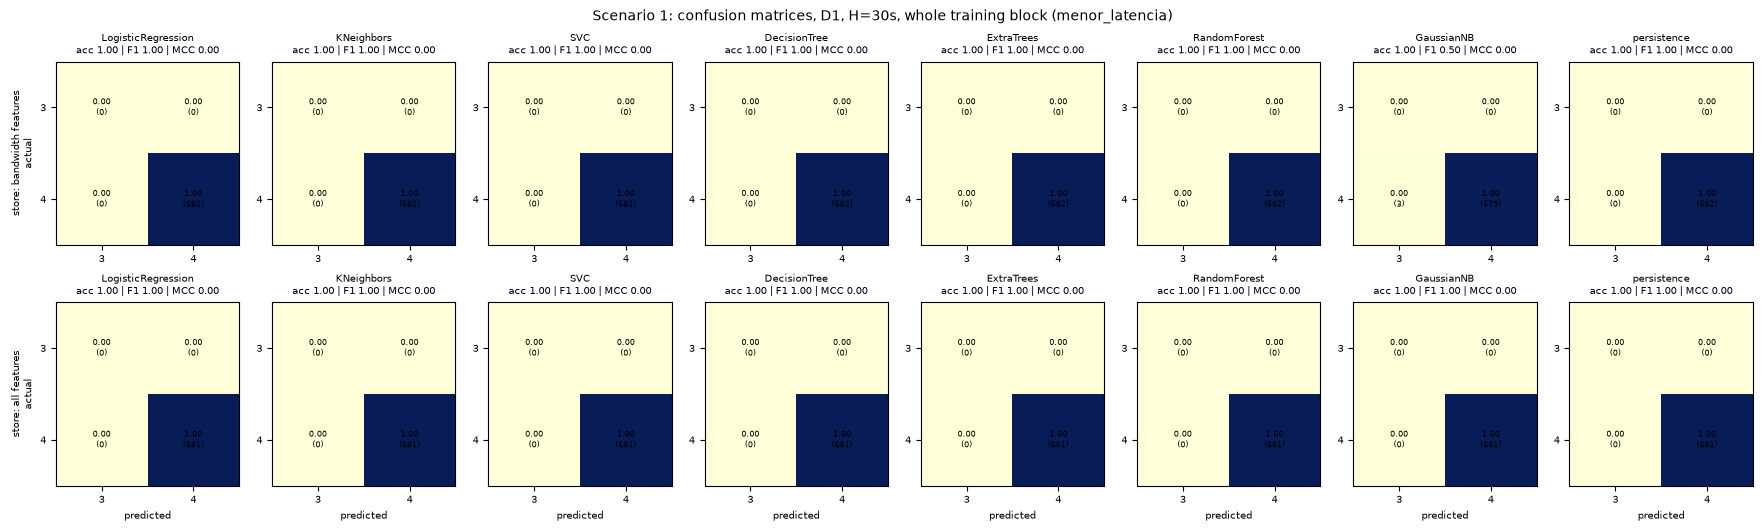

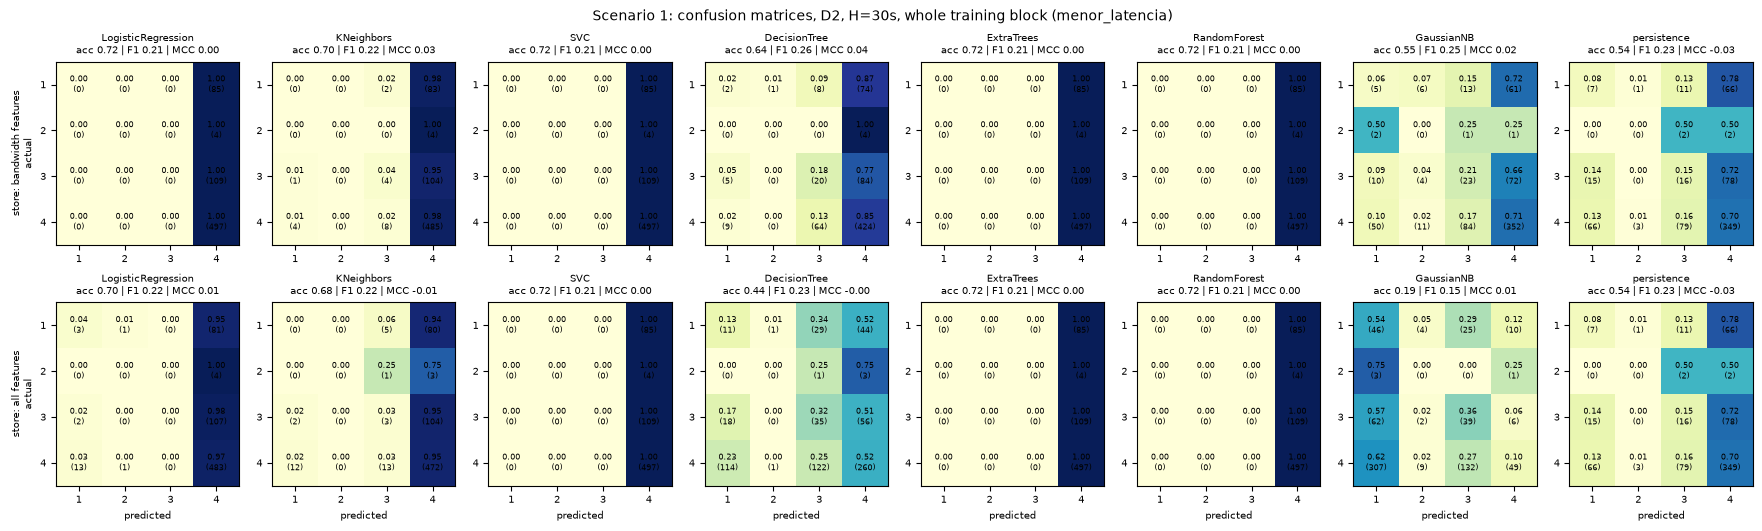

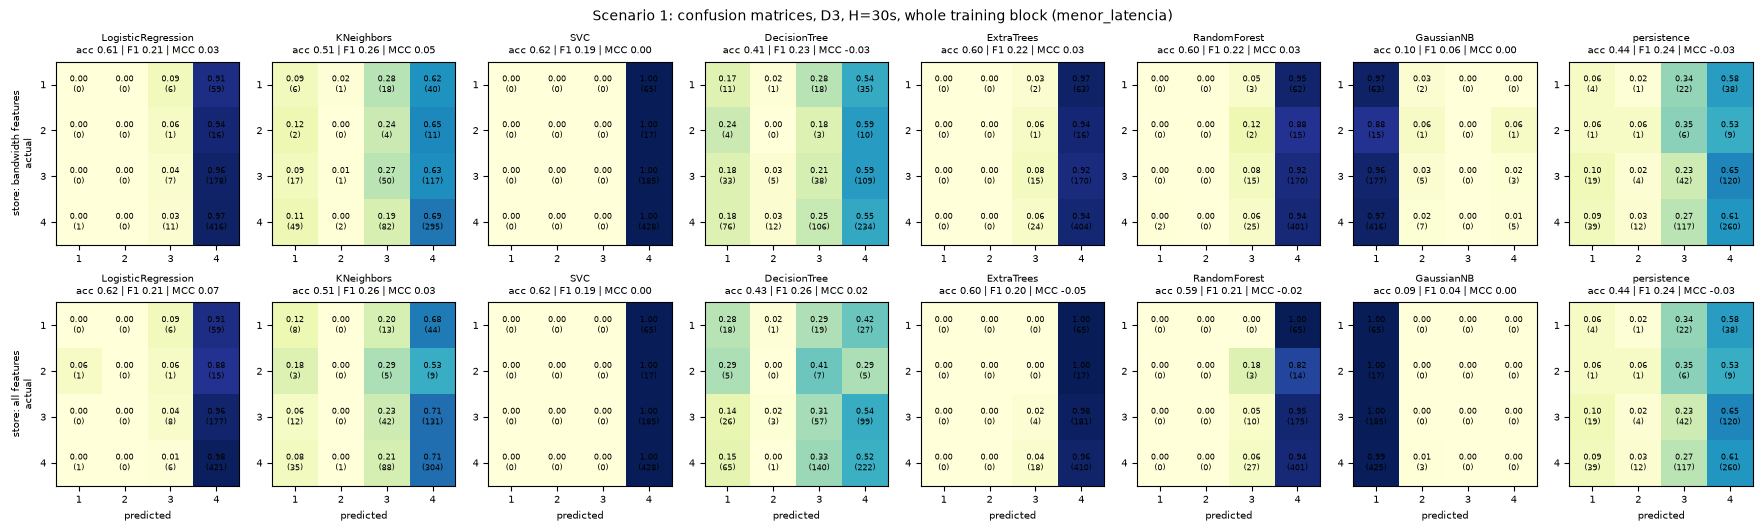

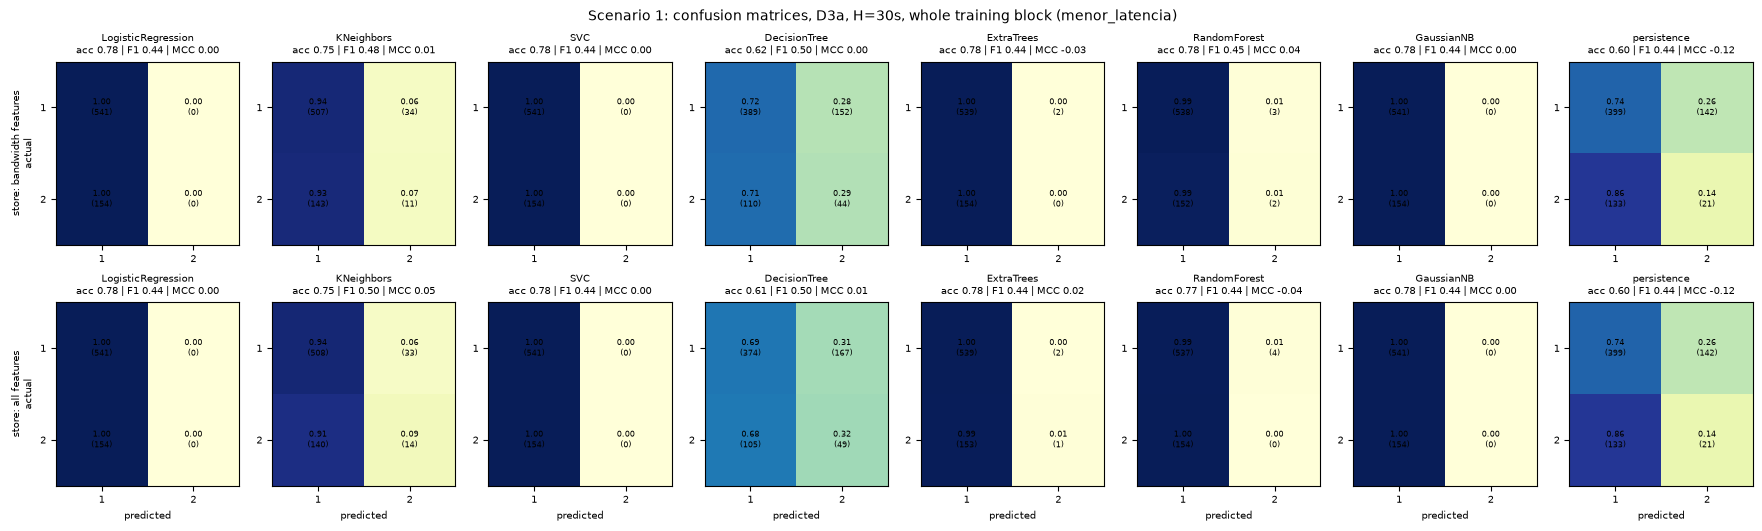

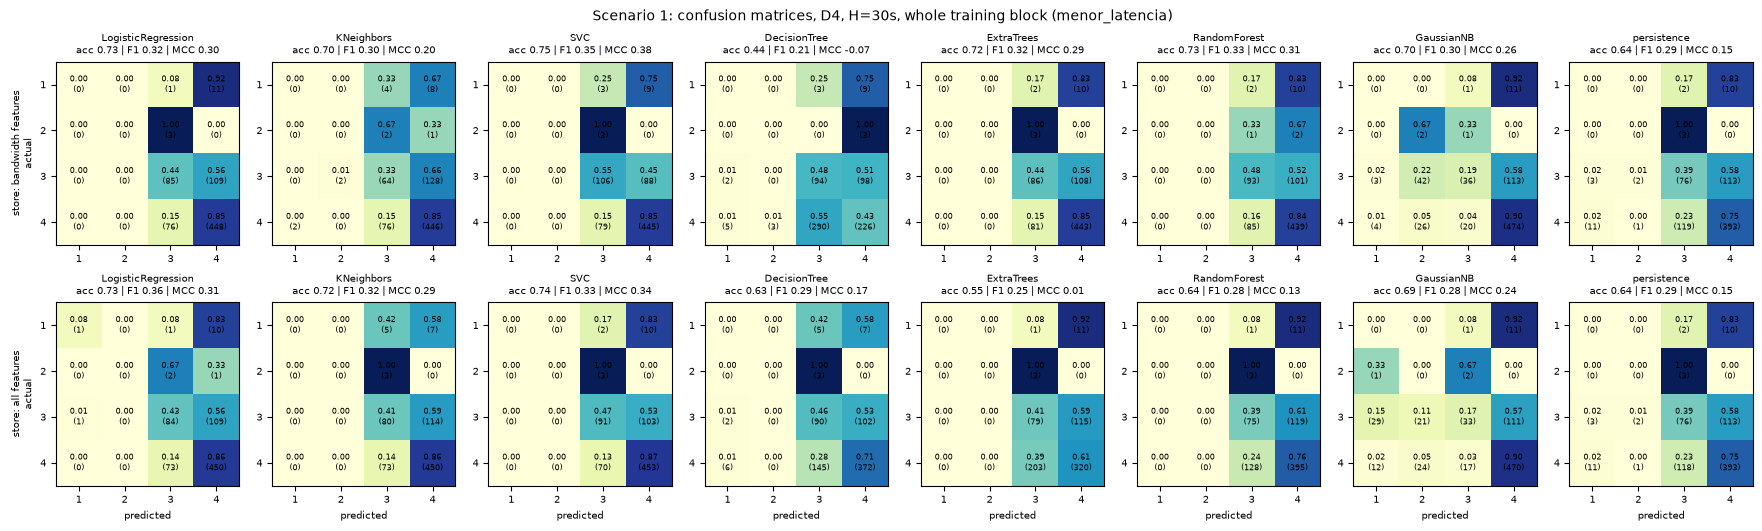

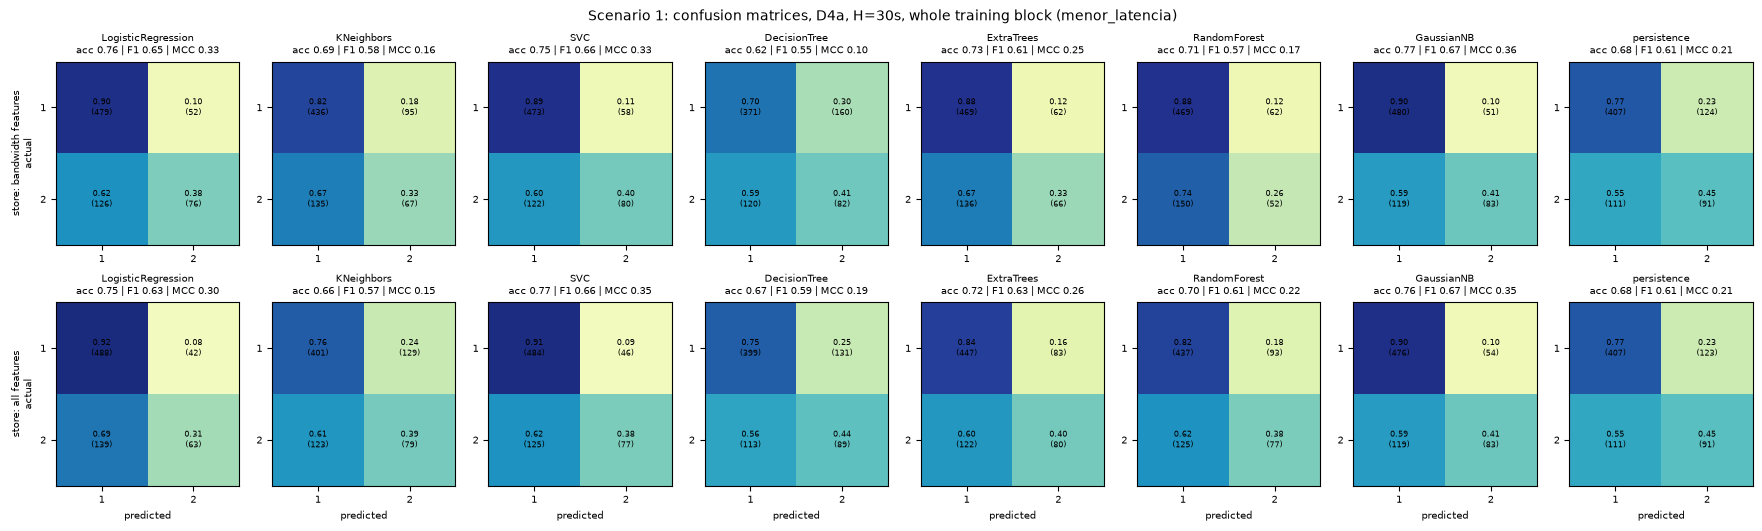

In [ ]:
# Confusion matrices of every model at one horizon: one figure per dataset, one row
#   per feature set (plot_confusion_rows_fs). Persistence is drawn next to the models.
#   CONFUSION_NORMALIZE_FS = True divides each row by its support, so the diagonal
#   becomes the recall of that route; the raw count is shown below it.
CONFUSION_H_FS = H_REF
CONFUSION_PREDICTORS_FS = evaluated_models + ['persistence']
CONFUSION_NORMALIZE_FS = True

for target in targets:
    predictions = sweep_predictions_fs[target]
    for dataset in datasets:
        plot_confusion_rows_fs(
            predictions[predictions.horizon_s == CONFUSION_H_FS], dataset,
            f'Scenario 1: confusion matrices, {dataset}, H={CONFUSION_H_FS}s, '
            f'whole training block ({target})',
            CONFUSION_PREDICTORS_FS, feature_sets, normalize=CONFUSION_NORMALIZE_FS,
            path=RESULTS_DIR[target] / f'sweep_confusion_{dataset}_H{CONFUSION_H_FS}.png')

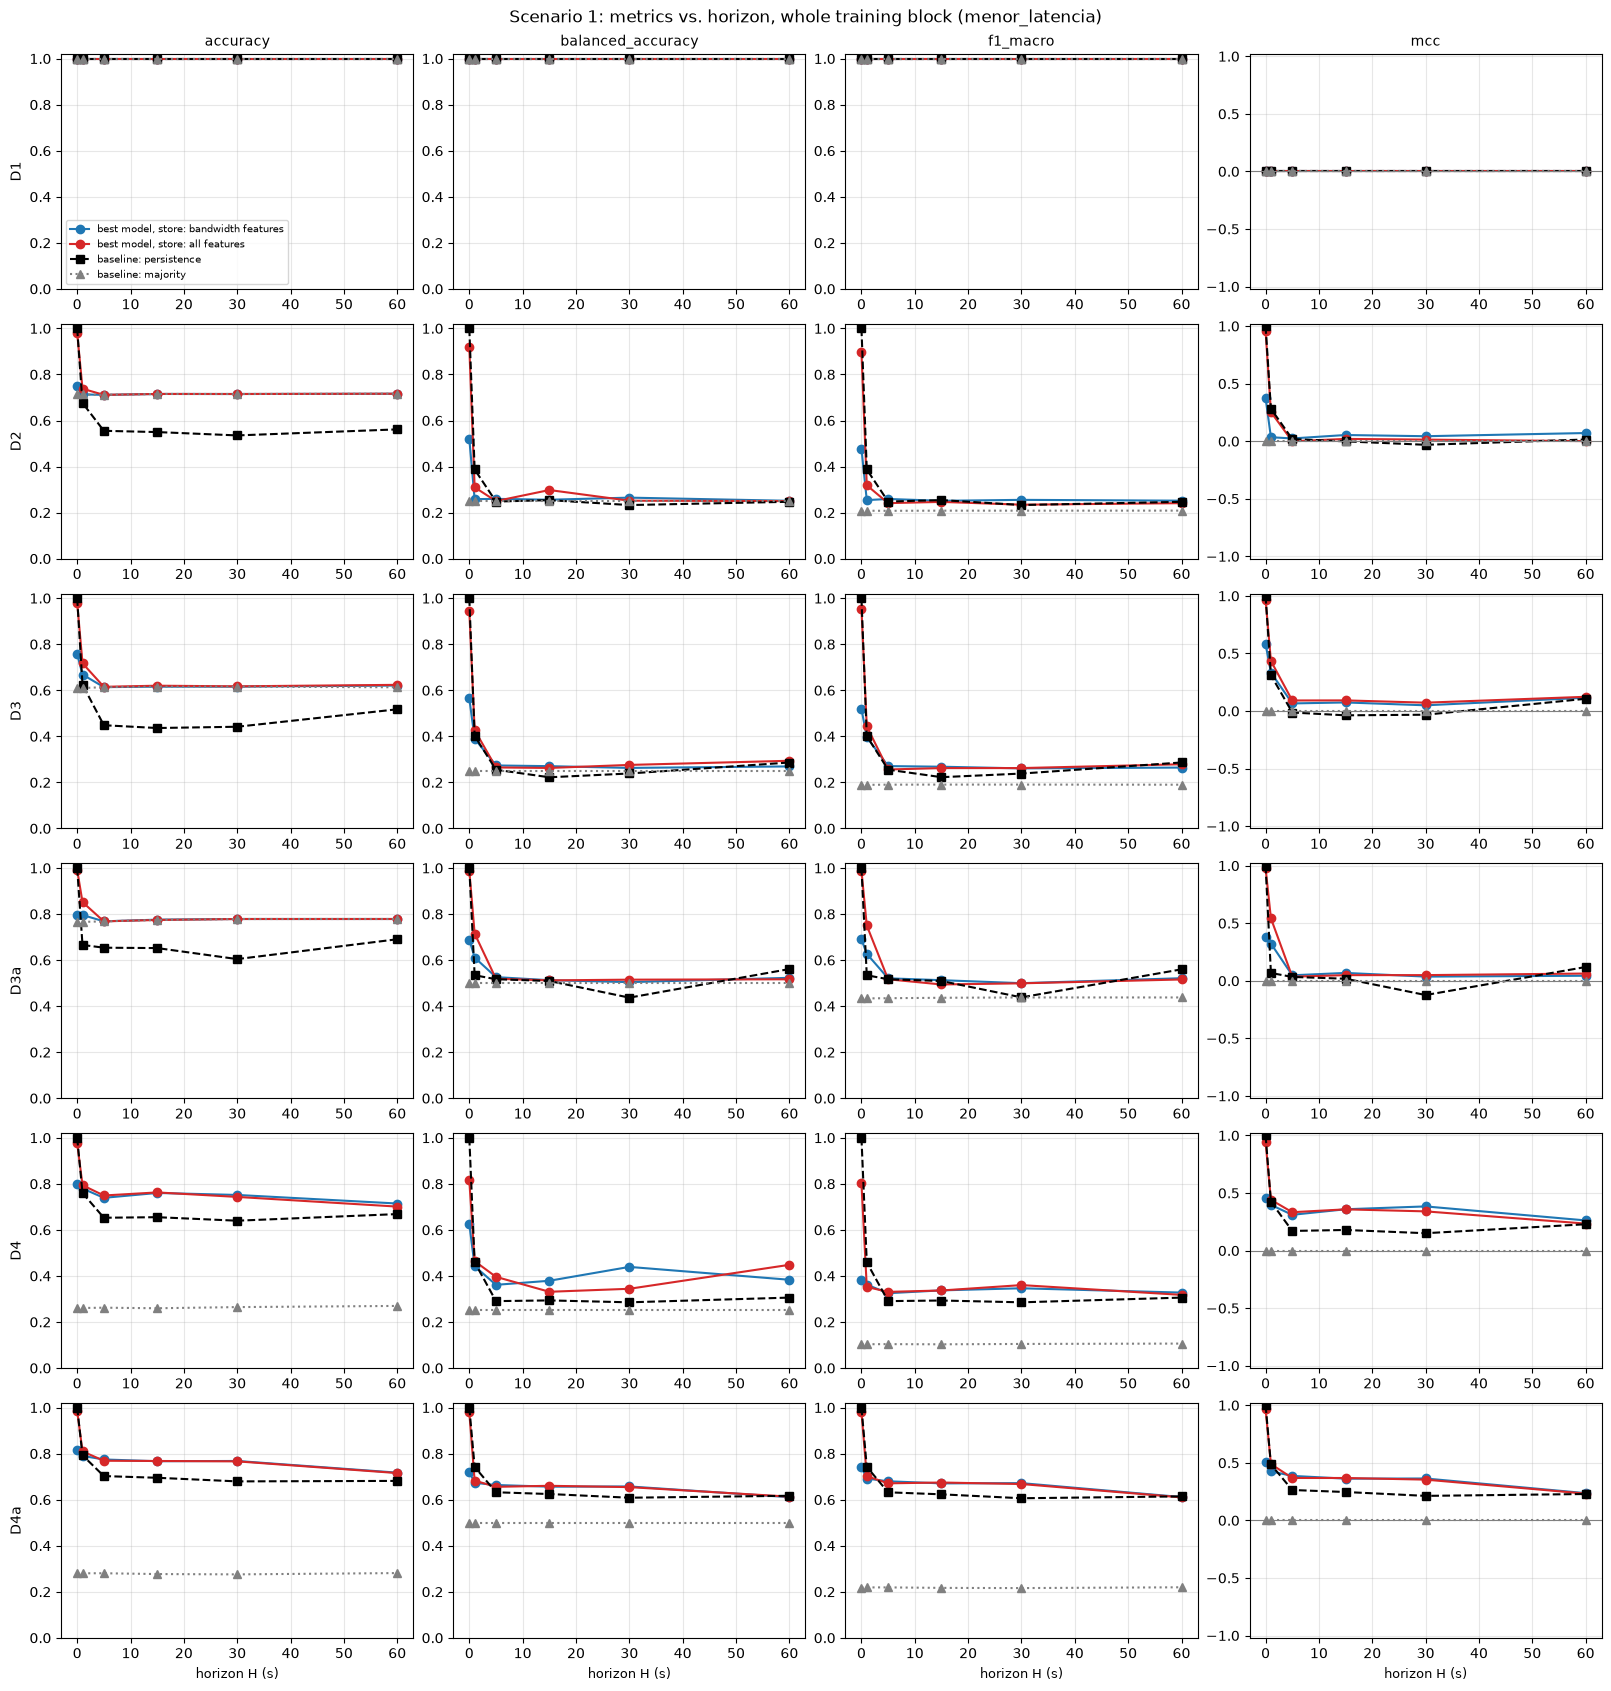

F1-macro of the best model minus that of persistence:


horizon_s                             0      1      5      15     30     60
dataset feature_set                                                        
D1      store: all features        0.000  0.000  0.000  0.000  0.000  0.000
        store: bandwidth features  0.000  0.000  0.000  0.000  0.000  0.000
D2      store: all features       -0.103 -0.069 -0.007 -0.008  0.001 -0.006
        store: bandwidth features -0.522 -0.133  0.011 -0.003  0.022  0.005
D3      store: all features       -0.046  0.042  0.001  0.039  0.024 -0.008
        store: bandwidth features -0.481 -0.005  0.016  0.045  0.022 -0.022
D3a     store: all features       -0.011  0.215 -0.000 -0.015  0.061 -0.044
        store: bandwidth features -0.310  0.093  0.004  0.004  0.062 -0.039
D4      store: all features       -0.198 -0.107  0.040  0.044  0.074  0.011
        store: bandwidth features -0.617 -0.097  0.034  0.044  0.061  0.022
D4a     store: all features       -0.018 -0.041  0.038  0.051  0.061 -0.003
        store: bandwidth features -0.257 -0.051  0.048  0.048  0.066 -0.003

In [ ]:
# Metrics beyond accuracy over the horizons. Each panel shows, for one dataset and one
#   metric, the best model of each feature set (best by that metric, so the model may
#   change from panel to panel) against the two baselines. On balanced accuracy, F1
#   and MCC the majority class drops to 1 / routes, low and 0 respectively, which is
#   where a model that only follows the dominant route shows up.
METRICS_PLOT_FS = ['accuracy', 'balanced_accuracy', 'f1_macro', 'mcc']


def best_by_metric_fs(metrics, keys, predictors=evaluated_models):
    """For every case and metric, the highest value among the given predictors."""
    models = metrics[metrics.predictor.isin(predictors)]
    return models.groupby(keys)[METRICS_FS].max()


best_metrics_fs = {}
for target in targets:
    metrics = sweep_metrics_fs[target]
    best_metrics_fs[target] = best_by_metric_fs(metrics, ['dataset', 'feature_set', 'horizon_s'])
    best_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'sweep_best_by_metric.csv')

    plot_metric_panels_fs(
        best_metrics_fs[target], metrics, 'horizon_s', METRICS_PLOT_FS, BASELINES_FS,
        datasets, feature_sets, feature_sets_colors,
        f'Scenario 1: metrics vs. horizon, whole training block ({target})', 'horizon H (s)',
        path=RESULTS_DIR[target] / 'sweep_metrics.png')

    print(f'=== target: {target} ===')
    print('F1-macro of the best model minus that of persistence:')
    persistence = (metrics[metrics.predictor == 'persistence']
                   .set_index(['dataset', 'feature_set', 'horizon_s']))
    display((best_metrics_fs[target]['f1_macro'] - persistence['f1_macro'])
            .unstack('horizon_s').reindex(datasets, level=0).round(3))

## Scenario 2: training window W

Accuracy over the evaluated test instants, per `(dataset, feature set, H, W, model)`,
next to three baselines measured on the same instants: persistence, the window
majority, and the **full block** model of scenario 1 (same feature set, horizon and
model). The full-block accuracy is measured on every test instant and this scenario
on one instant every `WINDOW_STEP` seconds, so the two match closely but not
exactly. `single_class %` is the share of windows holding a single label; when it
is close to 100%, every model collapses into the window majority, and a gain at
that `W` comes from the recent labels rather than from `X`.

In [ ]:
_case_fs = ['dataset', 'feature_set', 'horizon_s', 'window_s']
_columns_fs = ['best model', 'accuracy', 'persistence', 'window_majority', 'full_block',
               'single_class_pct', 'gain over persistence']
window_metrics_fs, window_best_fs = {}, {}
for target in targets:
    rows = []
    for case, group in window_predictions_fs[target].groupby(_case_fs):
        common = dict(zip(_case_fs, case),
                      instants=len(group),
                      mean_train_size=group.n_train.mean(),
                      single_class_pct=100 * group.single_class.mean(),
                      persistence=(group.persistence == group.y_true).mean(),
                      window_majority=(group.window_majority == group.y_true).mean())
        for model in evaluated_models:
            rows.append({
                **common, 'model': model,
                'accuracy': accuracy_score(group.y_true, group[model]),
                'f1_macro': f1_score(group.y_true, group[model], average='macro', zero_division=0),
            })

    window_metrics_fs[target] = pd.DataFrame(rows).merge(
        sweep_fs[target].rename(columns={'accuracy': 'full_block', 'f1_macro': 'full_block_f1'}),
        on=['dataset', 'feature_set', 'horizon_s', 'model'], how='left')
    window_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'window_metrics.csv', index=False)

    best = (window_metrics_fs[target].sort_values('accuracy', ascending=False)
            .drop_duplicates(_case_fs)
            .rename(columns={'model': 'best model'})
            .set_index(_case_fs).sort_index()
            .reindex(datasets, level=0))
    best['gain over persistence'] = best['accuracy'] - best['persistence']
    best['gain over window majority'] = best['accuracy'] - best['window_majority']
    window_best_fs[target] = best
    best.to_csv(RESULTS_DIR[target] / 'window_best_model.csv')

    print(f'=== target: {target} ===')
    print(f'Best model per window at the reference horizon H={H_REF}s:')
    display(best.xs(H_REF, level='horizon_s')[_columns_fs].round(4))

    print('Gain of the best window model over persistence (rows: dataset, feature set, W; '
          'columns: H):')
    display(best['gain over persistence'].unstack('horizon_s').round(4))

Best model per window at the reference horizon H=30s:


best model  accuracy  \
dataset feature_set               window_s                                 
D1      store: all features       5         LogisticRegression      1.00   
                                  10              DecisionTree      1.00   
                                  15        LogisticRegression      1.00   
                                  30        LogisticRegression      1.00   
                                  45                ExtraTrees      1.00   
...                                                        ...       ...   
D4a     store: bandwidth features 10              DecisionTree      0.72   
                                  15                KNeighbors      0.84   
                                  30                KNeighbors      0.88   
                                  45                       SVC      0.80   
                                  60                       SVC      0.80   

                                            persistence  window_majority  \
dataset feature_set               window_s                                 
D1      store: all features       5                1.00             1.00   
                                  10               1.00             1.00   
                                  15               1.00             1.00   
                                  30               1.00             1.00   
                                  45               1.00             1.00   
...                                                 ...              ...   
D4a     store: bandwidth features 10               0.68             0.68   
                                  15               0.68             0.76   
                                  30               0.68             0.76   
                                  45               0.68             0.76   
                                  60               0.68             0.80   

                                            full_block  single_class_pct  \
dataset feature_set               window_s                                 
D1      store: all features       5             1.0000             100.0   
                                  10            1.0000             100.0   
                                  15            1.0000             100.0   
                                  30            1.0000             100.0   
                                  45            1.0000             100.0   
...                                                ...               ...   
D4a     store: bandwidth features 10            0.6180              20.0   
                                  15            0.6862              20.0   
                                  30            0.6862              20.0   
                                  45            0.7544              16.0   
                                  60            0.7544              16.0   

                                            gain over persistence  
dataset feature_set               window_s                         
D1      store: all features       5                          0.00  
                                  10                         0.00  
                                  15                         0.00  
                                  30                         0.00  
                                  45                         0.00  
...                                                           ...  
D4a     store: bandwidth features 10                         0.04  
                                  15                         0.16  
                                  30                         0.20  
                                  45                         0.12  
                                  60                         0.12  

[72 rows x 7 columns]

Gain of the best window model over persistence (rows: dataset, feature set, W; columns: H):


horizon_s                                       0       1       5       15  \
dataset feature_set               window_s                                   
D1      store: all features       5         0.0000  0.0000  0.0000  0.0000   
                                  10        0.0000  0.0000  0.0000  0.0000   
                                  15        0.0000  0.0000  0.0000  0.0000   
                                  30        0.0000  0.0000  0.0000  0.0000   
                                  45        0.0000  0.0000  0.0000  0.0000   
...                                            ...     ...     ...     ...   
D4a     store: bandwidth features 10       -0.2308  0.0385  0.1538  0.2308   
                                  15       -0.1923  0.0385  0.1538  0.1923   
                                  30       -0.1923  0.0385  0.1154  0.1538   
                                  45       -0.1538  0.0000  0.1538  0.1538   
                                  60       -0.1923 -0.0385  0.1538  0.1538   

horizon_s                                     30      60  
dataset feature_set               window_s                
D1      store: all features       5         0.00  0.0000  
                                  10        0.00  0.0000  
                                  15        0.00  0.0000  
                                  30        0.00  0.0000  
                                  45        0.00  0.0000  
...                                          ...     ...  
D4a     store: bandwidth features 10        0.04  0.0417  
                                  15        0.16  0.0417  
                                  30        0.20  0.0417  
                                  45        0.12  0.0417  
                                  60        0.12  0.0000  

[72 rows x 6 columns]

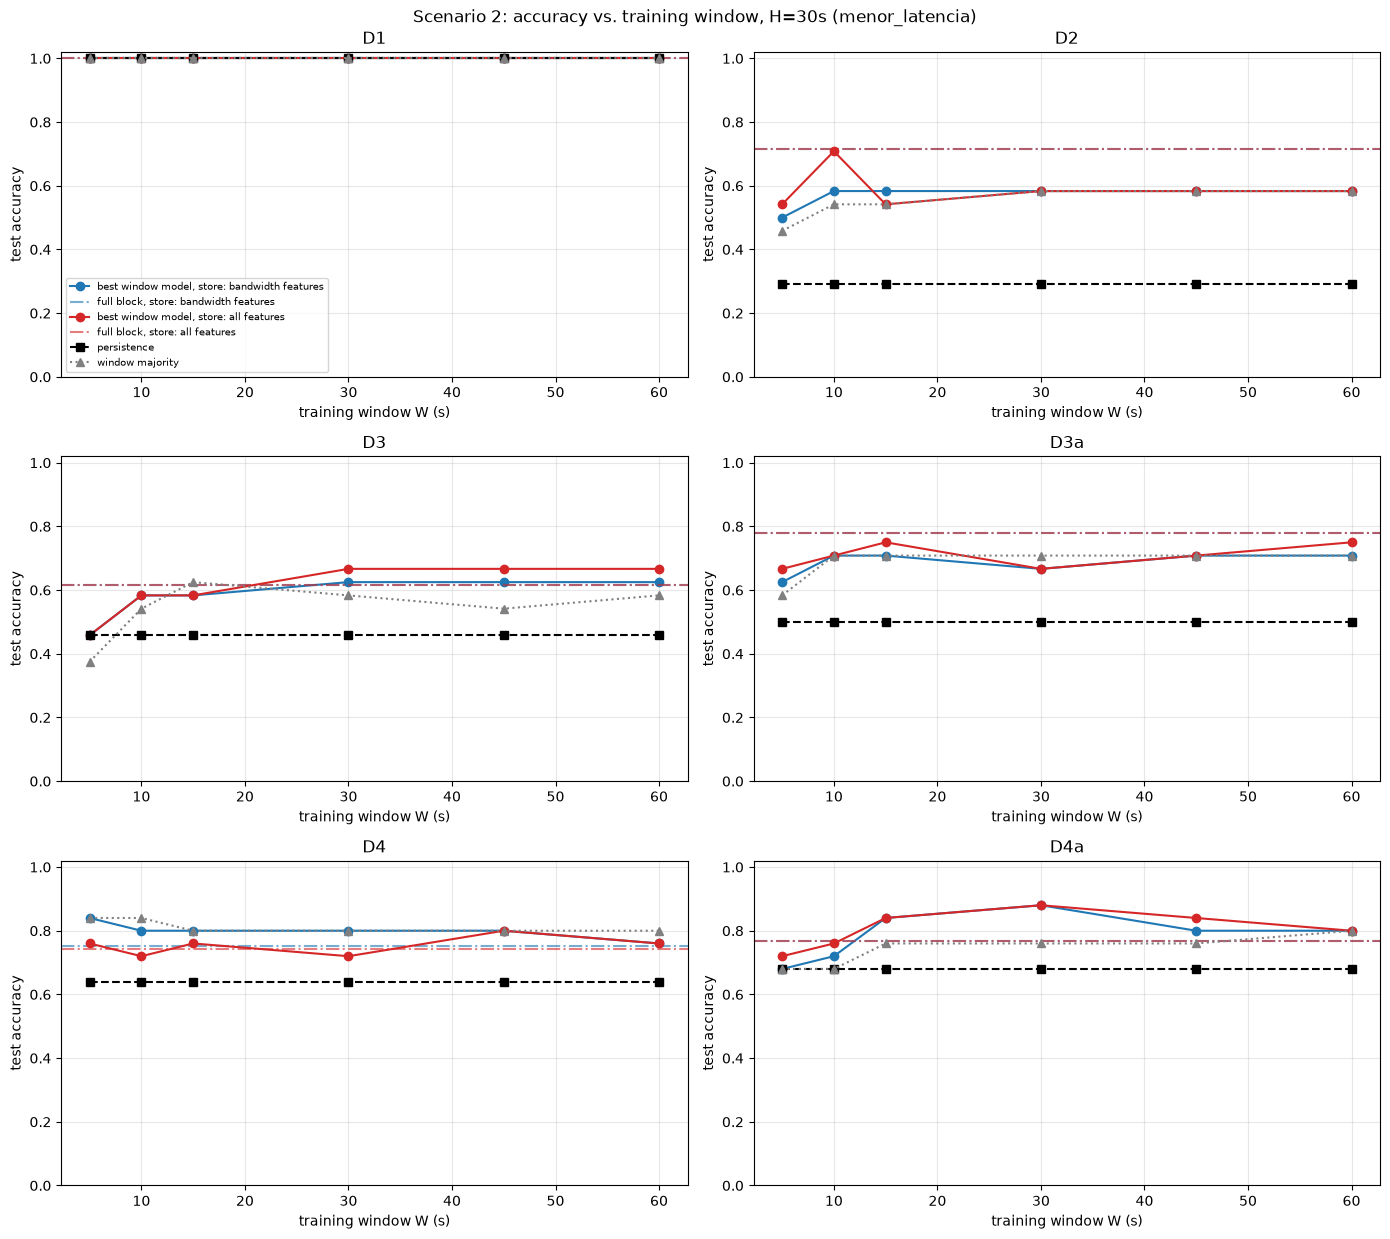

In [ ]:
for target in targets:
    plot_window_accuracy_fs(
        window_best_fs[target], best_fs[target], H_REF, datasets, feature_sets,
        feature_sets_colors,
        f'Scenario 2: accuracy vs. training window, H={H_REF}s ({target})',
        path=RESULTS_DIR[target] / f'window_accuracy_H{H_REF}.png')

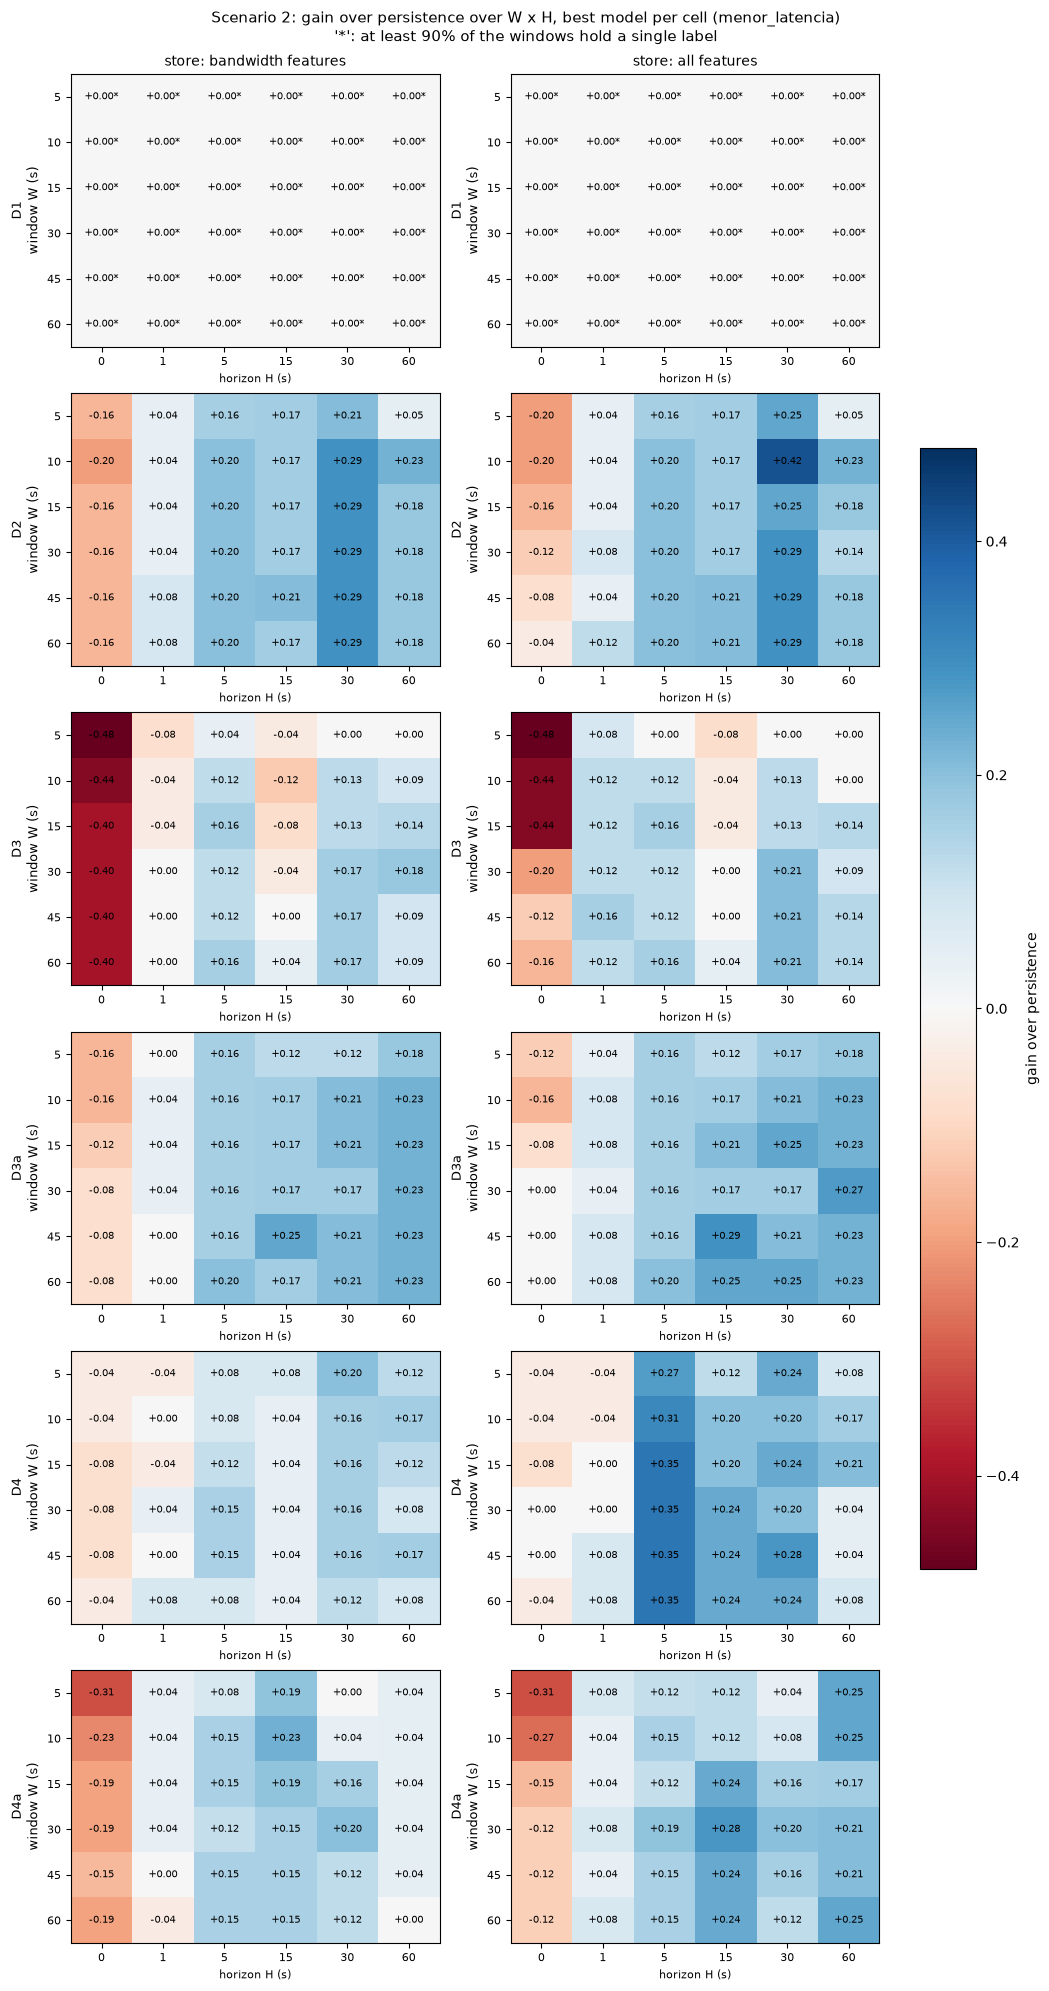

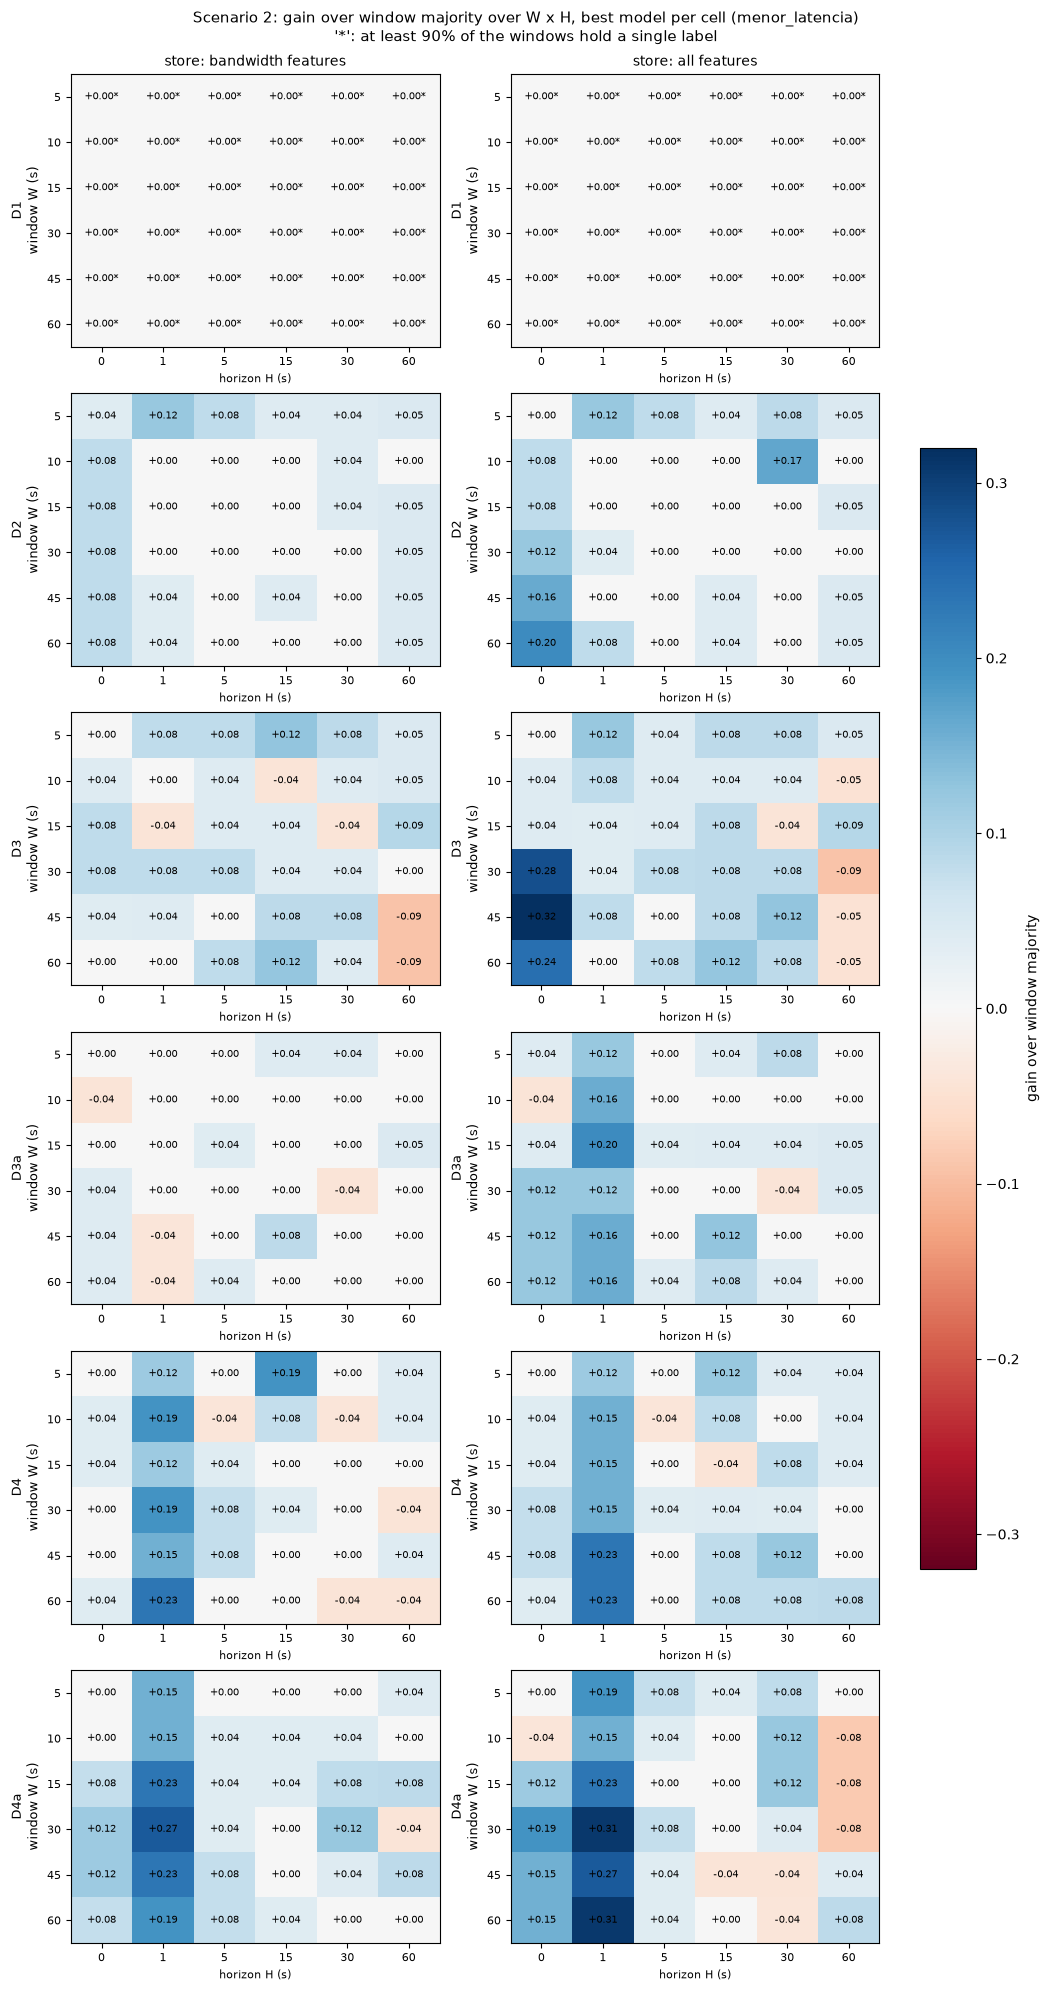

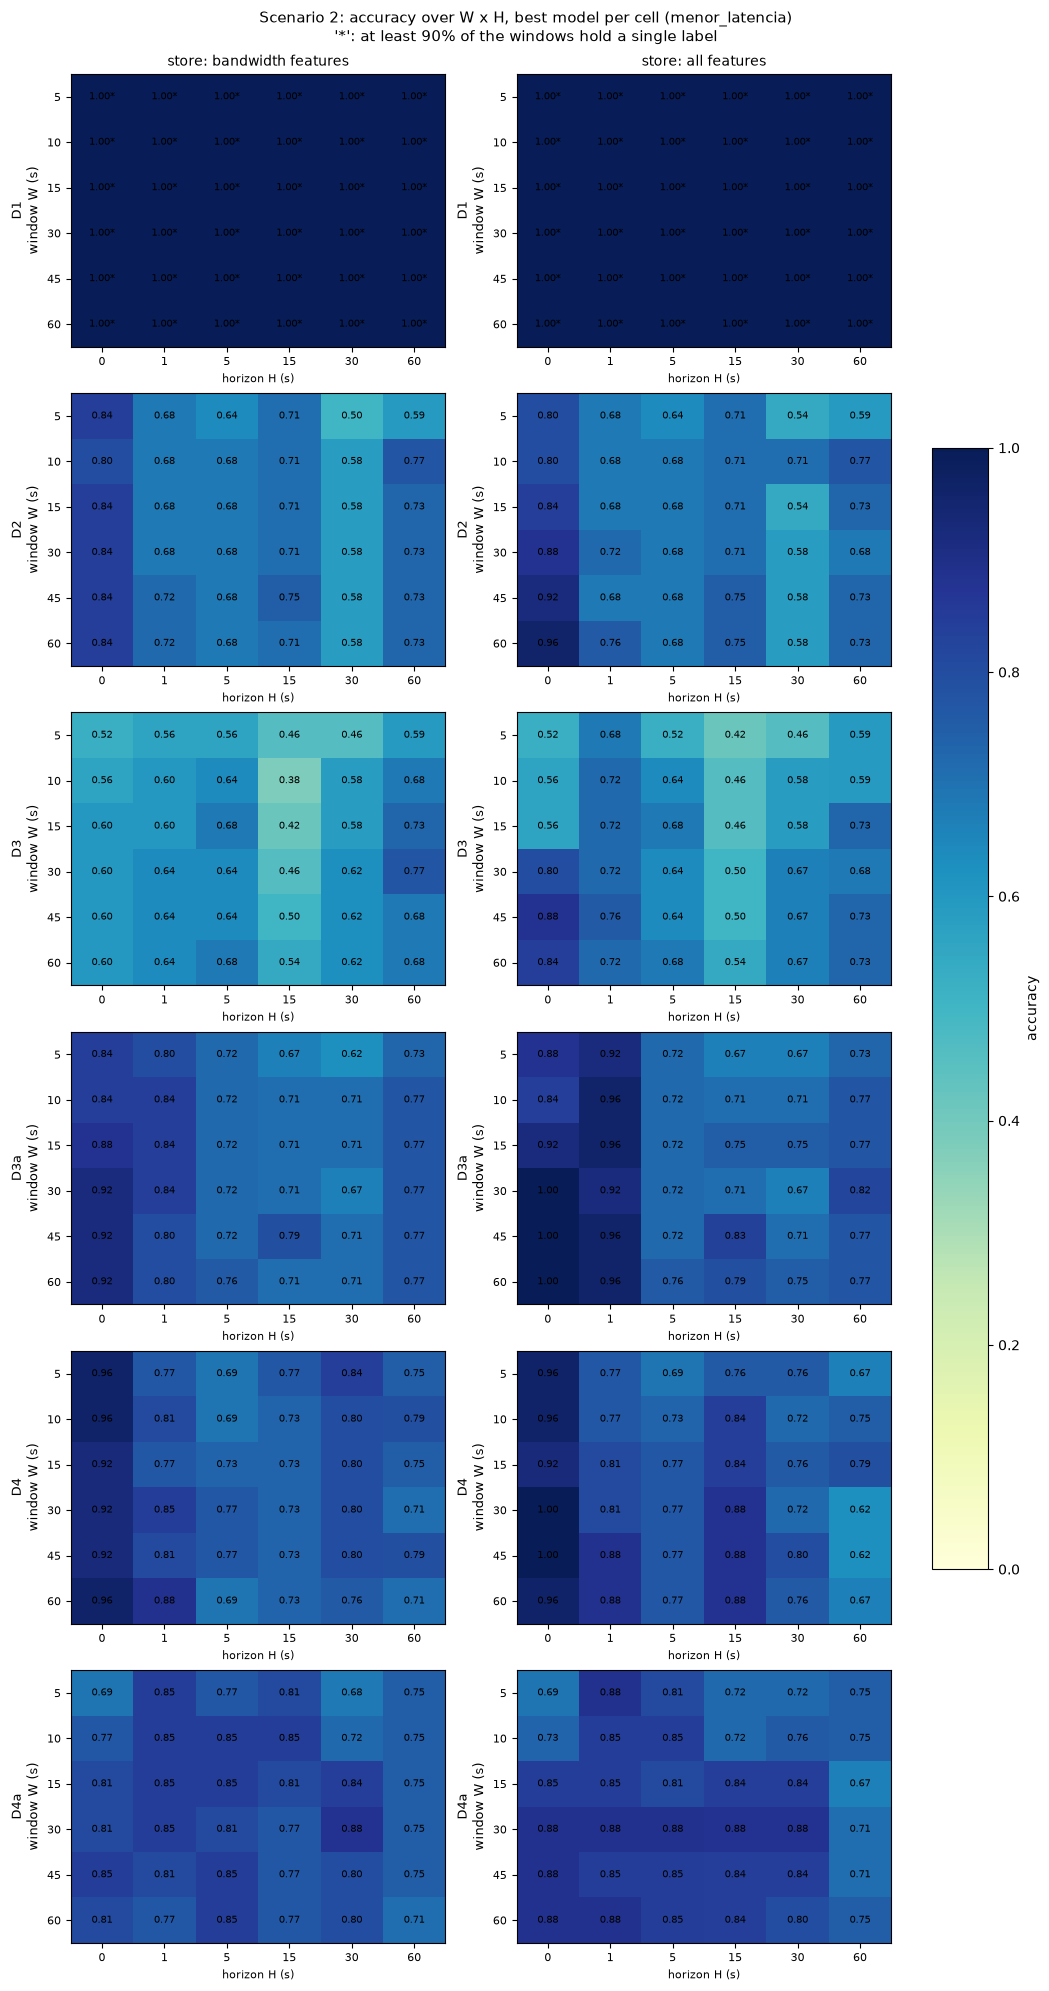

gain over persistence (best model per cell); rows: dataset, feature set, W; columns: H


horizon_s                                      0      1      5      15    30  \
dataset feature_set               window_s                                     
D1      store: all features       5         0.000  0.000  0.000  0.000  0.00   
                                  10        0.000  0.000  0.000  0.000  0.00   
                                  15        0.000  0.000  0.000  0.000  0.00   
                                  30        0.000  0.000  0.000  0.000  0.00   
                                  45        0.000  0.000  0.000  0.000  0.00   
...                                           ...    ...    ...    ...   ...   
D4a     store: bandwidth features 10       -0.231  0.038  0.154  0.231  0.04   
                                  15       -0.192  0.038  0.154  0.192  0.16   
                                  30       -0.192  0.038  0.115  0.154  0.20   
                                  45       -0.154  0.000  0.154  0.154  0.12   
                                  60       -0.192 -0.038  0.154  0.154  0.12   

horizon_s                                      60  
dataset feature_set               window_s         
D1      store: all features       5         0.000  
                                  10        0.000  
                                  15        0.000  
                                  30        0.000  
                                  45        0.000  
...                                           ...  
D4a     store: bandwidth features 10        0.042  
                                  15        0.042  
                                  30        0.042  
                                  45        0.042  
                                  60        0.000  

[72 rows x 6 columns]

gain over window majority (best model per cell); rows: dataset, feature set, W; columns: H


horizon_s                                      0      1      5      15    30  \
dataset feature_set               window_s                                     
D1      store: all features       5         0.000  0.000  0.000  0.000  0.00   
                                  10        0.000  0.000  0.000  0.000  0.00   
                                  15        0.000  0.000  0.000  0.000  0.00   
                                  30        0.000  0.000  0.000  0.000  0.00   
                                  45        0.000  0.000  0.000  0.000  0.00   
...                                           ...    ...    ...    ...   ...   
D4a     store: bandwidth features 10        0.000  0.154  0.038  0.038  0.04   
                                  15        0.077  0.231  0.038  0.038  0.08   
                                  30        0.115  0.269  0.038  0.000  0.12   
                                  45        0.115  0.231  0.077  0.000  0.04   
                                  60        0.077  0.192  0.077  0.038  0.00   

horizon_s                                      60  
dataset feature_set               window_s         
D1      store: all features       5         0.000  
                                  10        0.000  
                                  15        0.000  
                                  30        0.000  
                                  45        0.000  
...                                           ...  
D4a     store: bandwidth features 10        0.000  
                                  15        0.083  
                                  30       -0.042  
                                  45        0.083  
                                  60        0.000  

[72 rows x 6 columns]

In [ ]:
# Results over the whole (W, H) grid: one heatmap per dataset and feature set, with
#   the training window W on the rows and the horizon H on the columns.
#
#   MODEL_GRID_FS = None picks, in every cell, the model with the highest accuracy on
#   the evaluated test instants. That choice is made on the test instants themselves,
#   so it is optimistic. Set a model name (e.g. 'RandomForest') to read a single
#   model across the grid instead.
#
#   Three metrics, each in its own figure:
#     gain over persistence     - accuracy minus "the best route in H s is the one now"
#     gain over window majority - accuracy minus the most frequent label of the window,
#                                 i.e. what the model adds by using X at all
#     accuracy                  - the absolute value, for reference
#   A '*' marks the cells where at least SINGLE_CLASS_MARK_FS % of the windows hold a
#   single label: there every model returns the window majority, so the cell says
#   nothing about X.
MODEL_GRID_FS = None
SINGLE_CLASS_MARK_FS = 90

GRID_METRICS_FS = ['gain over persistence', 'gain over window majority', 'accuracy']
grid_model_label_fs = 'best model per cell' if MODEL_GRID_FS is None else MODEL_GRID_FS
_grid_tag_fs = 'best' if MODEL_GRID_FS is None else MODEL_GRID_FS

grid_table_fs = {}
for target in targets:
    if MODEL_GRID_FS is None:
        grid_source = window_best_fs[target].reset_index()
    else:
        metrics = window_metrics_fs[target]
        grid_source = metrics[metrics.model == MODEL_GRID_FS].copy()
        grid_source['gain over persistence'] = grid_source.accuracy - grid_source.persistence
        grid_source['gain over window majority'] = (grid_source.accuracy
                                                    - grid_source.window_majority)

    # Long table of the grid, saved once for every metric
    grid_table_fs[target] = (grid_source
                             .set_index(['dataset', 'feature_set', 'window_s', 'horizon_s'])
                             [GRID_METRICS_FS + ['persistence', 'window_majority',
                                                 'single_class_pct']]
                             .sort_index())
    grid_table_fs[target].to_csv(RESULTS_DIR[target] / f'window_grid_W_H_{_grid_tag_fs}.csv')

    for metric in GRID_METRICS_FS:
        plot_window_grid_fs(
            grid_source, metric,
            f'Scenario 2: {metric} over W x H, {grid_model_label_fs} ({target})',
            datasets, feature_sets, windows, horizons,
            SINGLE_CLASS_MARK_FS,
            path=(RESULTS_DIR[target]
                  / f'window_grid_{metric.replace(" ", "_")}_{_grid_tag_fs}.png'))

    # The same grid as tables: rows are (dataset, feature set, W), columns are H
    print(f'=== target: {target} ===')
    for metric in GRID_METRICS_FS[:2]:
        print(f'{metric} ({grid_model_label_fs}); rows: dataset, feature set, W; columns: H')
        display(grid_table_fs[target][metric].unstack('horizon_s')
                .reindex(columns=horizons).round(3))

### Scenario 2: confusion matrices and metrics beyond accuracy

The same metrics for the sliding training window, computed from the predictions the
loop already stored (`window_predictions_fs`), so nothing is retrained. The
predictors are the 7 models plus **persistence** and the **window majority**.
Each `(dataset, feature set, H, W)` case is scored on the evaluated instants only,
about 25 per case with `WINDOW_STEP = 30`. With so few instants a minority route
may appear once or twice, so `mcc` and the macro averages move in large steps; read
them as orders of magnitude.

Best model by each metric, H=30s (rows: dataset, feature set, W):


accuracy  balanced_accuracy  \
dataset feature_set               window_s                                
D1      store: all features       5             1.00              1.000   
                                  10            1.00              1.000   
                                  15            1.00              1.000   
                                  30            1.00              1.000   
                                  45            1.00              1.000   
...                                              ...                ...   
D4a     store: bandwidth features 10            0.72              0.675   
                                  15            0.84              0.725   
                                  30            0.88              0.850   
                                  45            0.80              0.750   
                                  60            0.80              0.700   

                                            precision_macro  recall_macro  \
dataset feature_set               window_s                                  
D1      store: all features       5                   1.000         1.000   
                                  10                  1.000         1.000   
                                  15                  1.000         1.000   
                                  30                  1.000         1.000   
                                  45                  1.000         1.000   
...                                                     ...           ...   
D4a     store: bandwidth features 10                  0.629         0.675   
                                  15                  0.765         0.725   
                                  30                  0.807         0.850   
                                  45                  0.697         0.750   
                                  60                  0.679         0.700   

                                            f1_macro    mcc  
dataset feature_set               window_s                   
D1      store: all features       5            1.000  0.000  
                                  10           1.000  0.000  
                                  15           1.000  0.000  
                                  30           1.000  0.000  
                                  45           1.000  0.000  
...                                              ...    ...  
D4a     store: bandwidth features 10           0.636  0.300  
                                  15           0.709  0.431  
                                  30           0.825  0.656  
                                  45           0.709  0.421  
                                  60           0.671  0.356  

[72 rows x 6 columns]

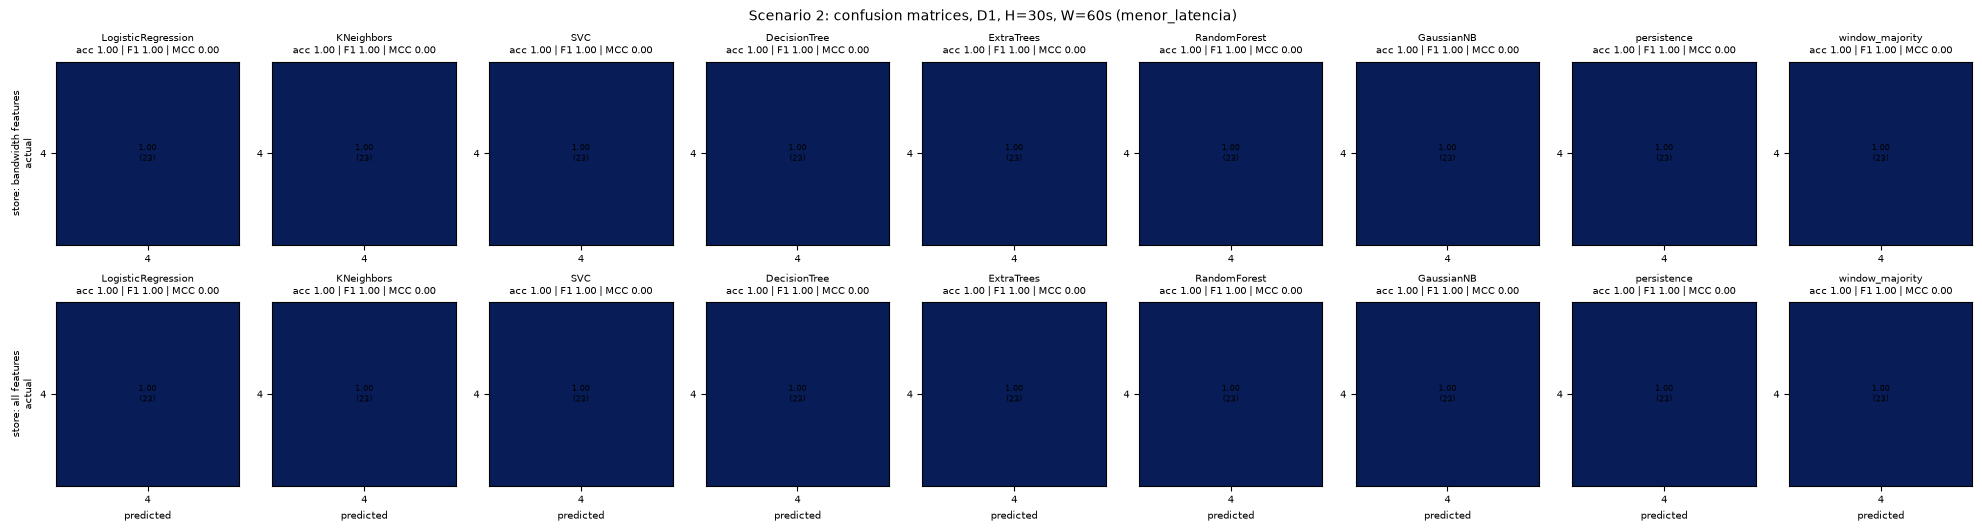

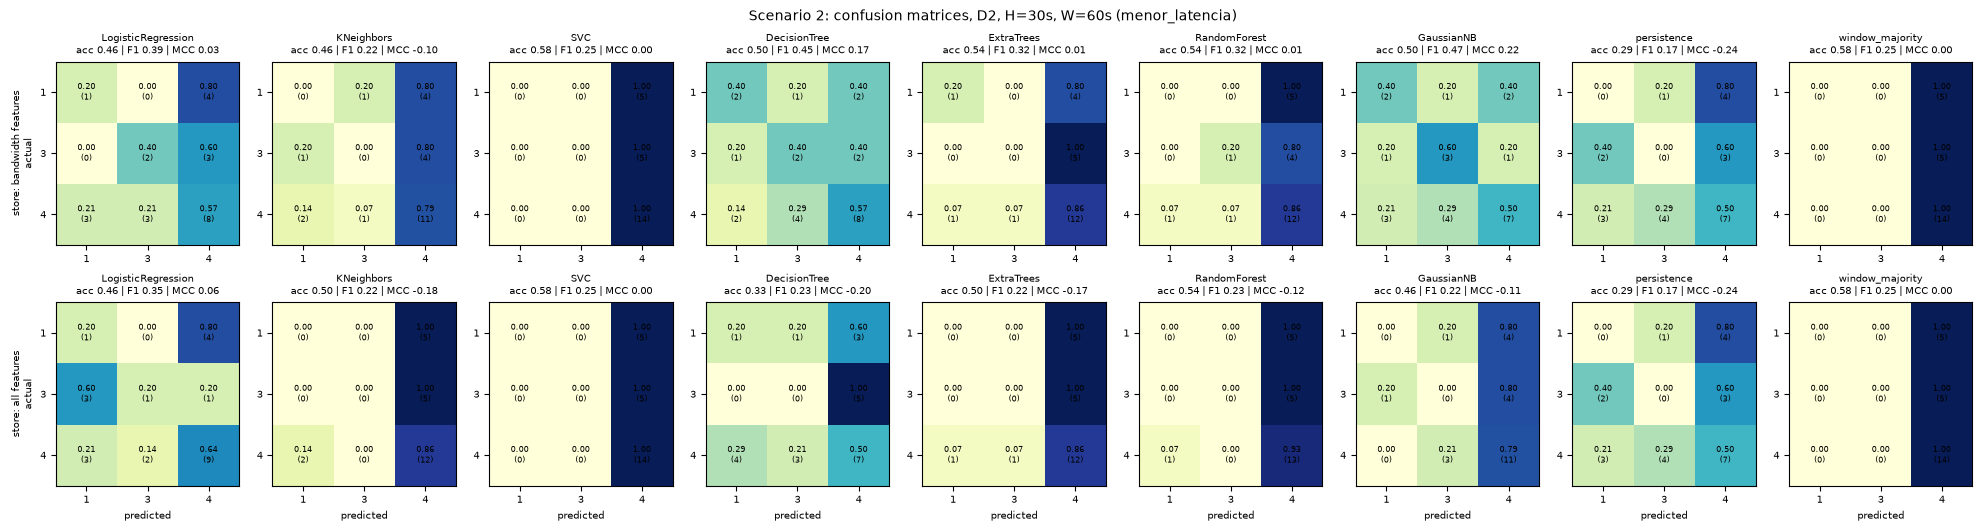

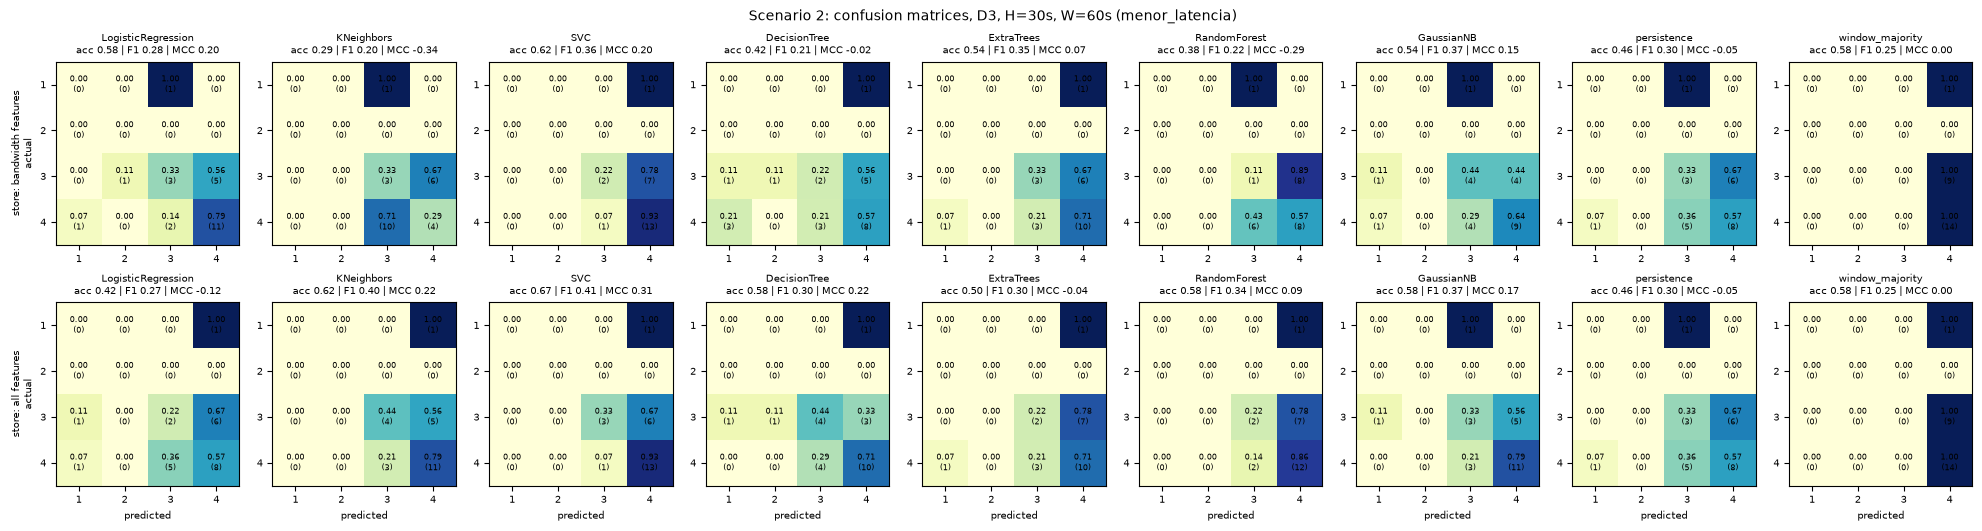

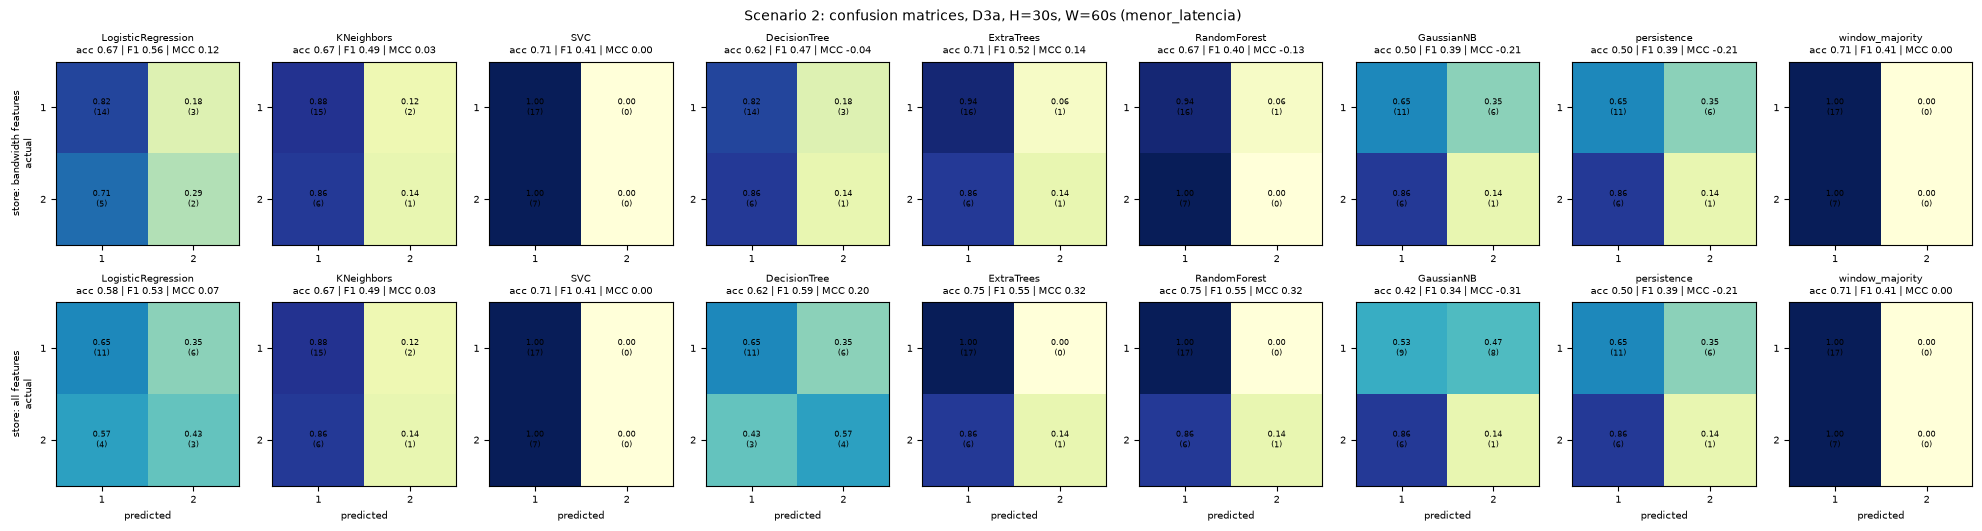

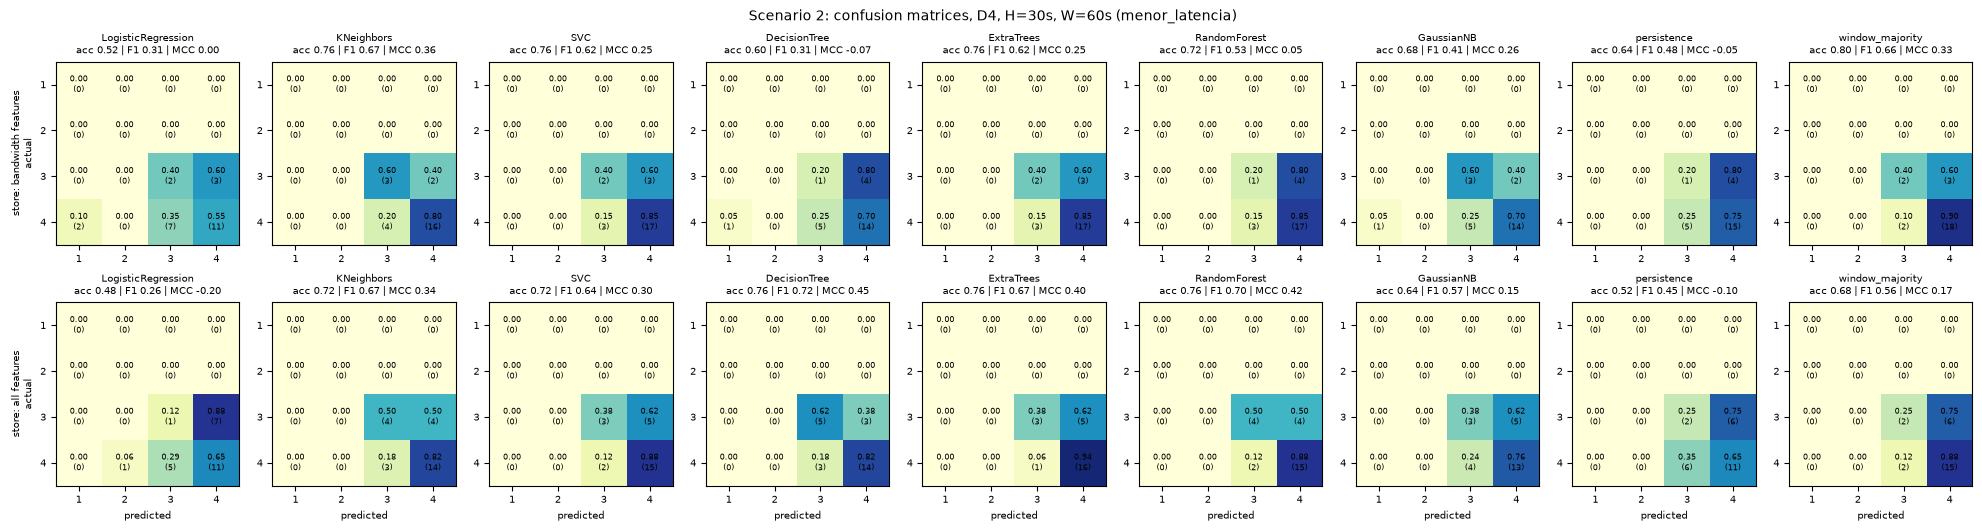

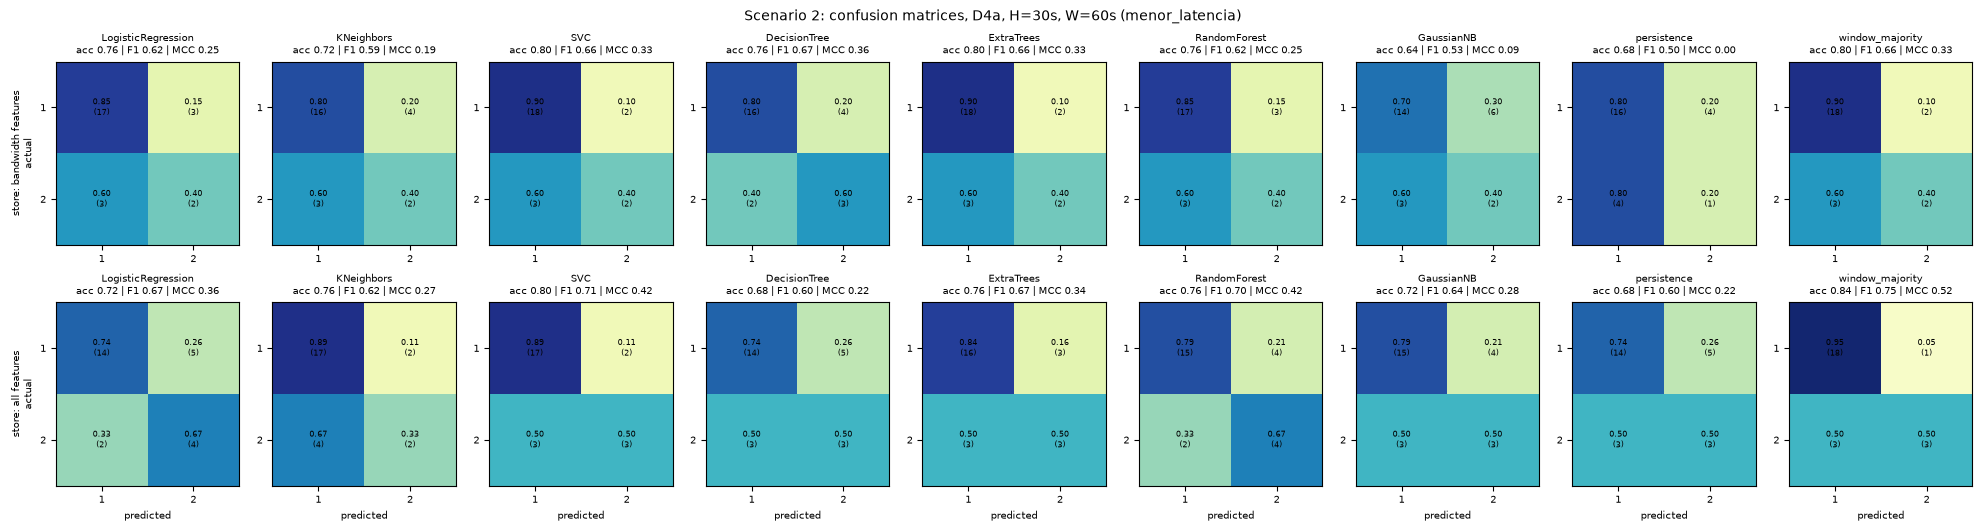

In [ ]:
WINDOW_BASELINES_FS = ['persistence', 'window_majority']

# Confusion matrices at the reference horizon and one window size, summed over the
#   evaluated instants of each dataset's test block
CONFUSION_W_FS = 60
CONFUSION_WINDOW_PREDICTORS_FS = evaluated_models + WINDOW_BASELINES_FS

window_class_metrics_fs, window_best_metrics_fs = {}, {}
for target in targets:
    predictions = window_predictions_fs[target]
    window_class_metrics_fs[target] = metrics_table_fs(
        predictions, ['dataset', 'feature_set', 'horizon_s', 'window_s'],
        evaluated_models + WINDOW_BASELINES_FS)
    window_class_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'window_class_metrics.csv',
                                           index=False)

    window_best_metrics_fs[target] = best_by_metric_fs(
        window_class_metrics_fs[target], ['dataset', 'feature_set', 'horizon_s', 'window_s'])
    window_best_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'window_best_by_metric.csv')

    print(f'=== target: {target} ===')
    print(f'Best model by each metric, H={H_REF}s (rows: dataset, feature set, W):')
    display(window_best_metrics_fs[target].xs(H_REF, level='horizon_s')
            .reindex(datasets, level=0).round(3))

    case = predictions[(predictions.horizon_s == H_REF)
                       & (predictions.window_s == CONFUSION_W_FS)]
    for dataset in datasets:
        plot_confusion_rows_fs(
            case, dataset,
            f'Scenario 2: confusion matrices, {dataset}, H={H_REF}s, W={CONFUSION_W_FS}s '
            f'({target})',
            CONFUSION_WINDOW_PREDICTORS_FS, feature_sets, normalize=CONFUSION_NORMALIZE_FS,
            path=(RESULTS_DIR[target]
                  / f'window_confusion_{dataset}_H{H_REF}_W{CONFUSION_W_FS}.png'))

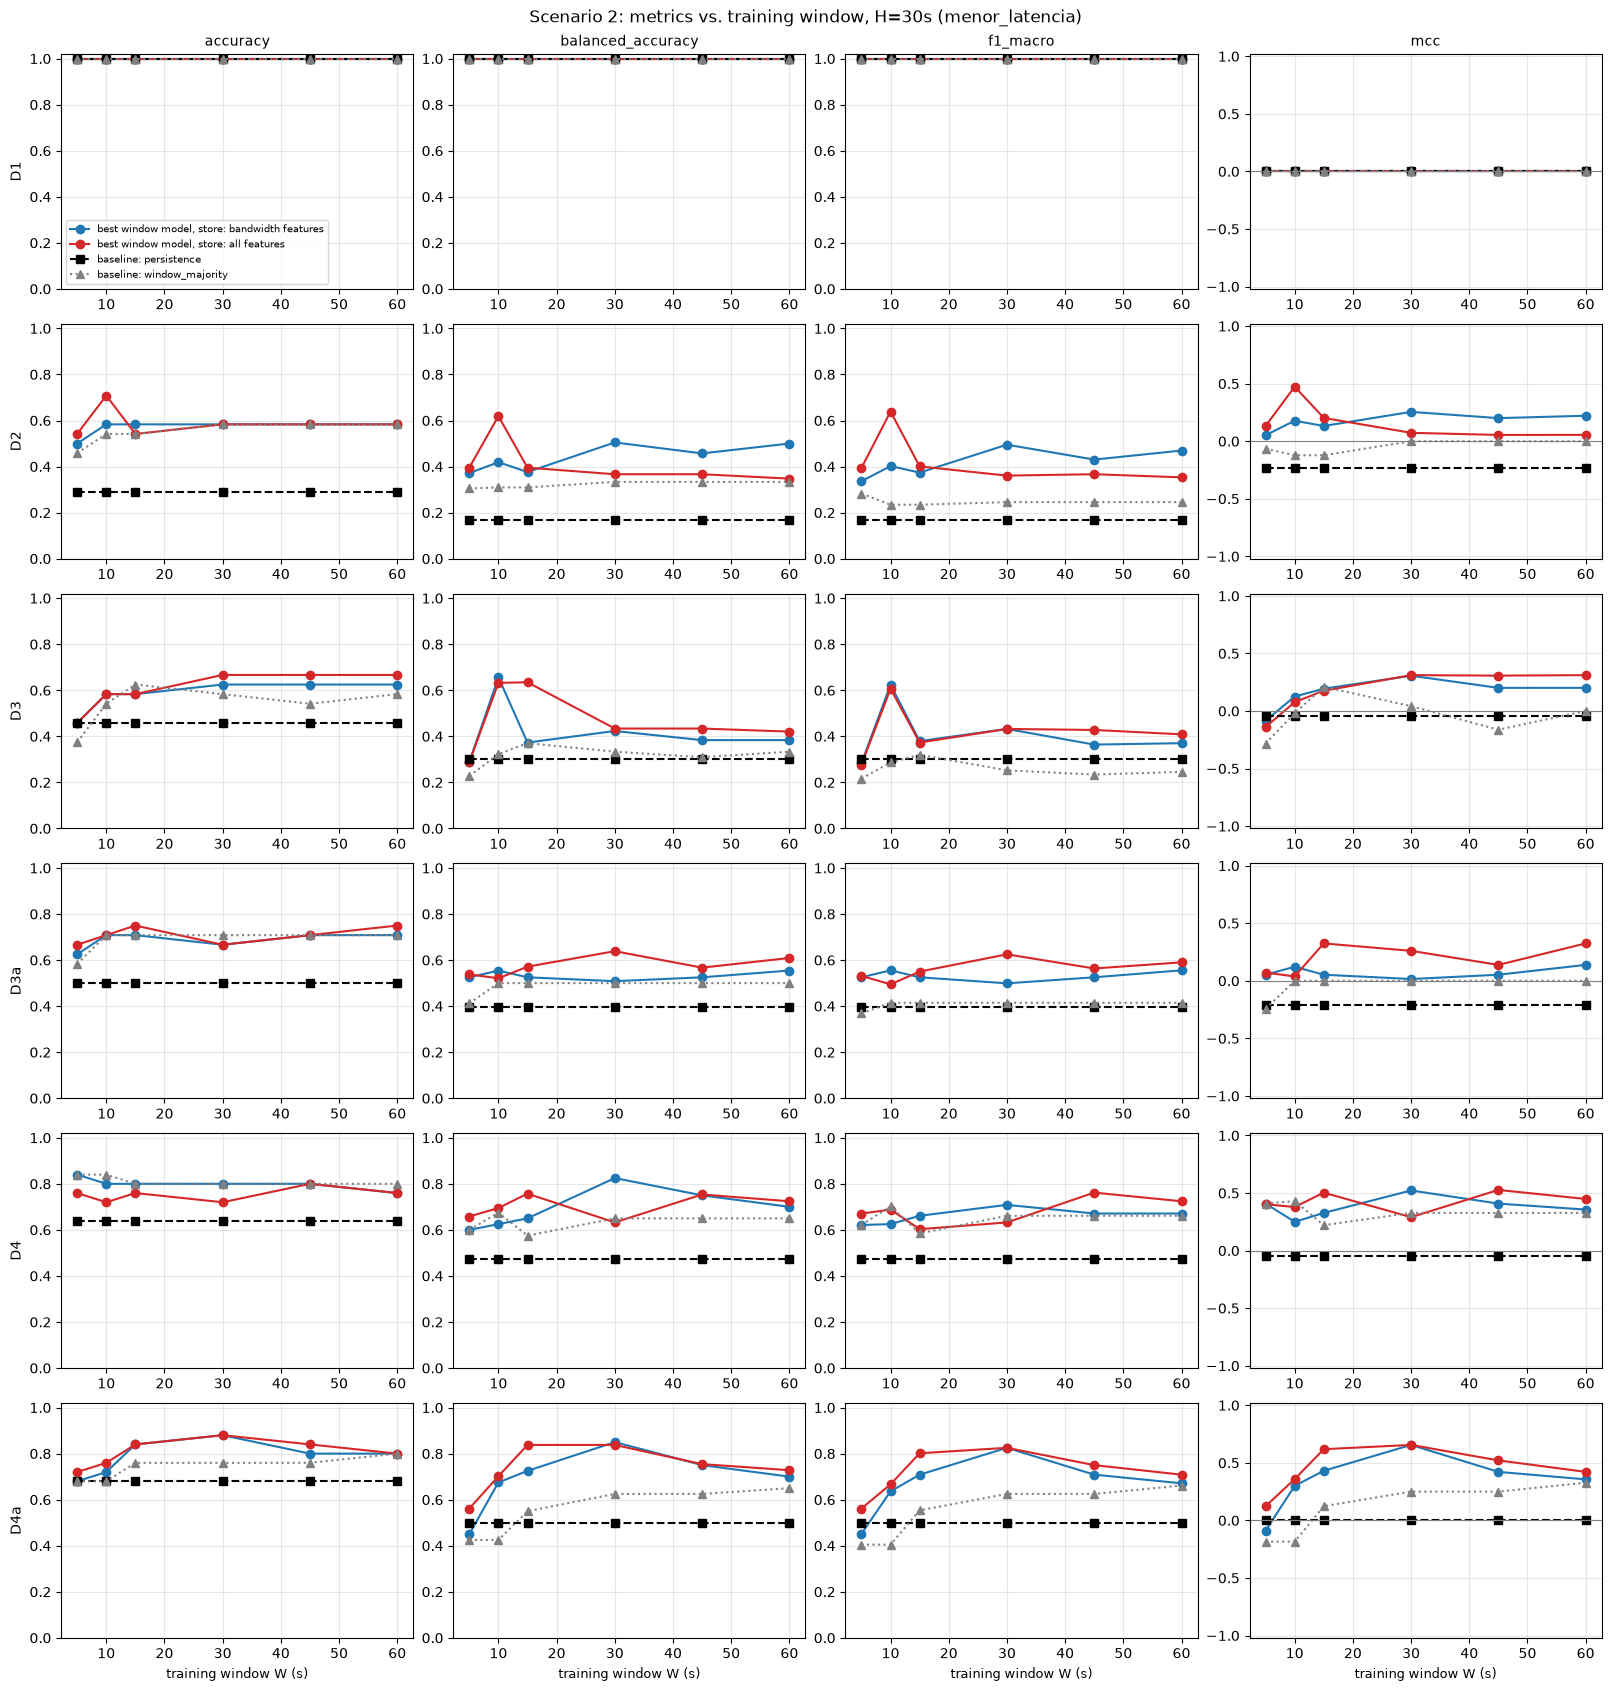

f1_macro of the best window model minus that of the window majority (rows: dataset, feature set, W; columns: H):


horizon_s                                      0      1      5      15     30  \
dataset feature_set               window_s                                      
D1      store: all features       5         0.000  0.000  0.000  0.000  0.000   
                                  10        0.000  0.000  0.000  0.000  0.000   
                                  15        0.000  0.000  0.000  0.000  0.000   
                                  30        0.000  0.000  0.000  0.000  0.000   
                                  45        0.000  0.000  0.000  0.000  0.000   
...                                           ...    ...    ...    ...    ...   
D4a     store: bandwidth features 10        0.072  0.374  0.117  0.061  0.231   
                                  15        0.134  0.402  0.040  0.069  0.155   
                                  30        0.170  0.417  0.083  0.022  0.200   
                                  45        0.223  0.346  0.124  0.038  0.084   
                                  60        0.182  0.341  0.155  0.088  0.010   

horizon_s                                      60  
dataset feature_set               window_s         
D1      store: all features       5         0.000  
                                  10        0.000  
                                  15        0.000  
                                  30        0.000  
                                  45        0.000  
...                                           ...  
D4a     store: bandwidth features 10        0.000  
                                  15        0.101  
                                  30       -0.039  
                                  45        0.101  
                                  60        0.026  

[72 rows x 6 columns]

In [ ]:
# Metrics beyond accuracy against the window size, at the reference horizon: best
#   model of each feature set (best by the metric of the panel) against persistence
#   and the window majority, measured on the same evaluated instants. Then the whole
#   (W, H) grid of METRIC_GRID_FS: best model minus the window majority.
METRIC_GRID_FS = 'f1_macro'

for target in targets:
    class_metrics = window_class_metrics_fs[target]
    plot_metric_panels_fs(
        window_best_metrics_fs[target].xs(H_REF, level='horizon_s'),
        class_metrics[class_metrics.horizon_s == H_REF],
        'window_s', METRICS_PLOT_FS, WINDOW_BASELINES_FS,
        datasets, feature_sets, feature_sets_colors,
        f'Scenario 2: metrics vs. training window, H={H_REF}s ({target})',
        'training window W (s)', curve_label='best window model',
        path=RESULTS_DIR[target] / f'window_metrics_H{H_REF}.png')

    majority = (class_metrics[class_metrics.predictor == 'window_majority']
                .set_index(['dataset', 'feature_set', 'horizon_s', 'window_s'])[METRIC_GRID_FS])
    print(f'=== target: {target} ===')
    print(f'{METRIC_GRID_FS} of the best window model minus that of the window majority '
          f'(rows: dataset, feature set, W; columns: H):')
    display((window_best_metrics_fs[target][METRIC_GRID_FS] - majority)
            .unstack('horizon_s').reindex(columns=horizons)
            .reindex(datasets, level=0).round(3))

## Targets side by side

With more than one target in `targets`, the reference horizon `H_REF` of both
scenarios, one column block per target. Each target is read against its own
persistence: the same route can be the best by latency and not by bandwidth, so
the absolute accuracies are not comparable across targets, the gains are.

In [ ]:
_scenario_1_columns_fs = ['best model', 'accuracy', 'persistence', 'majority',
                          'gain over persistence']
print(f'Scenario 1, H={H_REF}s: best model trained on the whole training block')
display(pd.concat({target: best_fs[target].xs(H_REF, level='horizon_s')[_scenario_1_columns_fs]
                   for target in targets}, axis=1).round(4))

print(f'Scenario 2, H={H_REF}s: gain of the best window model over persistence '
      f'and over the window majority')
display(pd.concat({target: window_best_fs[target].xs(H_REF, level='horizon_s')
                   [['gain over persistence', 'gain over window majority']]
                   for target in targets}, axis=1).round(4))

## Notes on this section

- **`H = 0` with `store: all features` is not a forecast.** The lowest-latency target
  is the `argmin` of latency columns that are in `X`. Read `H > 0` against
  persistence.
- **`y` comes from the label files, the features from the store.** The two are
  joined by timestamp after the clock offset is removed. With `menor_latencia`, the
  `store vs label agreement` column of the build report must be 1.0; anything
  lower means the clocks are misaligned.
- **The store holds a few instants fewer than the label files** (ping start-up),
  and the latency windows drop the first instant of each route. Every baseline is
  measured on the rows of its own feature set, so the comparisons stay fair.
- **D3a and D4a are routes 1 and 2 of D3 and D4**, built from the same capture.
  They are not independent evidence and should not be averaged with D3 and D4.
- **D1 has almost nothing to predict**: one route is best in virtually every
  instant and its bandwidth is pinned at capacity (see the variation table).
- **The window results are about the learner.** With a `W` of a few seconds, most
  windows hold a single label and every model returns the window majority.
- **Runtime.** Scenario 2 refits every model for each evaluated instant.
  `WINDOW_STEP`, `windows`, `horizons` and
  `feature_sets` are the switches that shorten it.

Outputs in `resultados_am/CenarioPreditivoFS/`, or `CenarioPreditivoFS_<target>/` for a target other than `menor_latencia` (one folder per target of `targets`):

| file | content |
|---|---|
| `build_report.csv` | clock offset, matched instants, store vs label agreement, size of `X` per dataset |
| `class_distribution_H{H}.csv`, `.png` | best-route shares per dataset and block |
| `feature_variation.csv` | features constant up to numerical noise |
| `sweep_accuracy.csv`, `sweep_baselines.csv`, `sweep_best_model.csv`, `.png` | scenario 1 |
| `window_predictions.csv`, `window_metrics.csv`, `window_best_model.csv`, `window_accuracy_H{H}.png` | scenario 2 |

## Model selection by time-series cross-validation

The tables above report, for every case, the **best of the 7 models by its accuracy
on the test block**. That choice is made on the test block itself, so part of the
gap to the baselines is selection luck, more so in scenario 2, where each case rests
on about 25 instants. This section **adds** a selection that never looks at the
test block:

1. For every `(dataset, feature set, H)`, the training block of scenario 1 is split
   by `TimeSeriesSplit(n_splits=CV_FOLDS, gap=H)`: `CV_FOLDS` consecutive validation
   chunks, each one scored by the models trained on every instant before it, with
   `H` rows left out between the two, the same rule as the gap between the training
   and test blocks. The store has one row per second, so `H` rows span at least `H`
   seconds and no training label `y(τ + H)` falls inside the validation chunk.
2. The model with the highest mean validation accuracy is the **CV-selected model**.
   A model that cannot be trained on some fold (e.g. a fold with a single route)
   ranks below the models trained on every fold; ties go to the first model of
   `evaluated_models`.
3. Its test accuracy is read from scenario 1 (`sweep_fs`): same model, same training
   block, so nothing is refitted on the test block.
4. Scenario 2 keeps the CV-selected model of the same `(dataset, feature set, H)` and
   reads its accuracy at every `W` from `window_metrics_fs`. `W` itself is not
   selected: every `W` is reported.

Next to it, the **test-selected** model (the best model of the tables above) and two
differences:

| column | meaning |
|---|---|
| `selection optimism` | test-selected minus CV-selected accuracy; never negative, and the part of the earlier tables that came from choosing on the test block |
| `cv minus test` | mean validation accuracy minus test accuracy of the CV-selected model; large values mean the regime changes between the training and test blocks |

The hyperparameters are the fixed ones of `make_pipelines_fs`: this section chooses
among the 7 models, it does not tune them.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

CV_FOLDS = 5

# Results of this section, next to the folder of each target:
#   CenarioPreditivoFS_cv_selection, CenarioPreditivoFS_<target>_cv_selection
RESULTS_DIR_CV = {target: folder.with_name(f'{folder.name}_cv_selection')
                  for target, folder in RESULTS_DIR.items()}
for _folder in RESULTS_DIR_CV.values():
    _folder.mkdir(parents=True, exist_ok=True)


def cross_validate_training_block_fs(wide, horizon_s, folds=CV_FOLDS,
                                     evaluated_models=evaluated_models):
    """Forward-chaining CV of every model inside the training block of scenario 1.

    Same frame and training block as evaluate_full_block_fs. Returns one row per
    (fold, model); a model that cannot be trained on a fold gets NaN there.
    """
    frame, train, _ = blocks_fs(wide, horizon_s)
    rows_train = np.flatnonzero(train)
    rows_train = rows_train[np.argsort(frame['ts_epoch'].to_numpy()[rows_train], kind='stable')]
    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)[rows_train]
    y = frame['melhor_rota'].to_numpy(dtype=int)[rows_train]

    rows = []
    splitter = TimeSeriesSplit(n_splits=folds, gap=horizon_s)
    for fold, (fit, validation) in enumerate(splitter.split(X), start=1):
        for name, model in make_pipelines_fs(evaluated_models).items():
            try:
                y_pred = model.fit(X[fit], y[fit]).predict(X[validation])
                accuracy = accuracy_score(y[validation], y_pred)
                f1 = f1_score(y[validation], y_pred, average='macro', zero_division=0)
            except ValueError:
                accuracy = f1 = np.nan
            rows.append({'fold': fold, 'model': name, 'n_fit': len(fit),
                         'n_validation': len(validation),
                         'fit_routes': len(np.unique(y[fit])),
                         'validation_routes': len(np.unique(y[validation])),
                         'accuracy': accuracy, 'f1_macro': f1})
    return pd.DataFrame(rows)


def select_model_cv_fs(cv_folds, evaluated_models=evaluated_models):
    """CV-selected model of one case and the per-model CV summary.

    Order: most folds trained, then highest mean validation accuracy, then the
    order of evaluated_models.
    """
    summary = (cv_folds.groupby('model')
               .agg(cv_accuracy=('accuracy', 'mean'), cv_accuracy_std=('accuracy', 'std'),
                    cv_f1_macro=('f1_macro', 'mean'), trained_folds=('accuracy', 'count'))
               .reindex(evaluated_models))
    ranking = (summary.assign(_order=np.arange(len(summary)))
               .sort_values(['trained_folds', 'cv_accuracy', '_order'],
                            ascending=[False, False, True], na_position='last'))
    return ranking.index[0], summary


print(f'CV helpers defined: TimeSeriesSplit with {CV_FOLDS} folds, gap = H rows')
for _target, _folder in RESULTS_DIR_CV.items():
    print(f'results      : {_folder} ({_target})')

In [ ]:
# Scenario 1: CV inside every training block, then the test accuracy of the selected model
cv_folds_fs, cv_summary_fs, cv_selected_fs = {}, {}, {}

for target in targets:
    fold_parts, summary_parts, selected_rows = [], [], []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            for H in horizons:
                case = {'dataset': dataset, 'feature_set': feature_set, 'horizon_s': H}
                folds_table = cross_validate_training_block_fs(wide, H)
                selected, summary = select_model_cv_fs(folds_table)
                fold_parts.append(folds_table.assign(**case))
                summary_parts.append(summary.reset_index().assign(
                    **case, selected=lambda table: table.model == selected))
                selected_rows.append({**case, 'cv model': selected,
                                      **summary.loc[selected].to_dict()})
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    cv_folds_fs[target] = pd.concat(fold_parts, ignore_index=True)
    cv_summary_fs[target] = pd.concat(summary_parts, ignore_index=True)

    # Test accuracy of the CV-selected model, read from the loop of scenario 1
    test_of_model = sweep_fs[target].rename(columns={
        'model': 'cv model', 'accuracy': 'test accuracy', 'f1_macro': 'test f1_macro'})
    test_selected = (best_fs[target].reset_index()
                     [_keys_fs + ['best model', 'accuracy']]
                     .rename(columns={'best model': 'test-selected model',
                                      'accuracy': 'test-selected accuracy'}))
    selected = (pd.DataFrame(selected_rows)
                .merge(test_of_model, on=_keys_fs + ['cv model'], how='left')
                .merge(sweep_baselines_fs[target][_keys_fs + ['persistence', 'majority']],
                       on=_keys_fs, how='left')
                .merge(test_selected, on=_keys_fs, how='left'))
    selected['gain over persistence'] = selected['test accuracy'] - selected['persistence']
    selected['selection optimism'] = (selected['test-selected accuracy']
                                      - selected['test accuracy'])
    selected['cv minus test'] = selected['cv_accuracy'] - selected['test accuracy']
    cv_selected_fs[target] = (selected.set_index(_keys_fs).sort_index()
                              .reindex(datasets, level=0))

    results_dir = RESULTS_DIR_CV[target]
    cv_folds_fs[target].to_csv(results_dir / 'cv_folds.csv', index=False)
    cv_summary_fs[target].to_csv(results_dir / 'cv_summary.csv', index=False)
    cv_selected_fs[target].to_csv(results_dir / 'sweep_cv_selected_model.csv')

    assert cv_selected_fs[target]['test accuracy'].notna().all(), \
        'a CV-selected model has no test accuracy in sweep_fs'
    assert (cv_selected_fs[target]['selection optimism'] >= -1e-12).all()

    table = cv_selected_fs[target]
    print(f'=== target: {target} ===')
    print('Test accuracy of the CV-selected model, by horizon:')
    display(table['test accuracy'].unstack('horizon_s').round(4))
    print('CV-selected model:')
    display(table['cv model'].unstack('horizon_s'))
    print('Gain of the CV-selected model over persistence:')
    display(table['gain over persistence'].unstack('horizon_s').round(4))
    print('Selection optimism (test-selected minus CV-selected accuracy):')
    display(table['selection optimism'].unstack('horizon_s').round(4))
    print(f'At H={H_REF}s:')
    display(table.xs(H_REF, level='horizon_s')[
        ['cv model', 'cv_accuracy', 'cv_accuracy_std', 'trained_folds', 'test accuracy',
         'cv minus test', 'test-selected model', 'test-selected accuracy',
         'selection optimism', 'persistence', 'majority', 'gain over persistence']].round(4))

In [ ]:
def plot_cv_selected_accuracy_fs(selected, baselines, datasets, feature_sets, colors,
                                 title, path=None):
    """Scenario 1: test accuracy of the CV-selected model against H.

    The test-selected model of the earlier tables is drawn as a faint dotted line of
    the same color, so the vertical distance between the two is the selection optimism.
    """
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        for feature_set in feature_sets:
            cases = selected.loc[(dataset, feature_set)]
            color = colors[feature_set]
            axis.plot(cases.index, cases['test accuracy'], marker='o', color=color,
                      label=f'CV-selected model, {feature_set}')
            axis.plot(cases.index, cases['test-selected accuracy'], linestyle=':',
                      color=color, alpha=0.5, label=f'test-selected model, {feature_set}')
        base = baselines[(baselines.dataset == dataset)
                         & (baselines.feature_set == feature_sets[0])]
        axis.plot(base.horizon_s, base.persistence, 's--', color='black', label='persistence')
        axis.plot(base.horizon_s, base.majority, '^:', color='gray', label='majority class')
        axis.set_title(dataset)
        axis.set_xlabel('prediction horizon H (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


for target in targets:
    plot_cv_selected_accuracy_fs(
        cv_selected_fs[target], sweep_baselines_fs[target], datasets, feature_sets,
        feature_sets_colors,
        f'Scenario 1: accuracy vs. horizon, model selected by TimeSeriesSplit CV '
        f'({target})',
        path=RESULTS_DIR_CV[target] / 'sweep_cv_selected_model.png')

In [ ]:
# Scenario 2: the CV-selected model of scenario 1, read at every training window W
_case_cv_fs = ['dataset', 'feature_set', 'horizon_s', 'window_s']
window_cv_selected_fs = {}
for target in targets:
    chosen = cv_selected_fs[target].reset_index()[_keys_fs + ['cv model']]
    window = (window_metrics_fs[target]
              .merge(chosen, on=_keys_fs)
              .query('model == `cv model`')
              .drop(columns='model'))
    test_selected = (window_best_fs[target].reset_index()
                     [_case_cv_fs + ['best model', 'accuracy']]
                     .rename(columns={'best model': 'test-selected model',
                                      'accuracy': 'test-selected accuracy'}))
    window = window.merge(test_selected, on=_case_cv_fs, how='left')
    window['gain over persistence'] = window['accuracy'] - window['persistence']
    window['gain over window majority'] = window['accuracy'] - window['window_majority']
    window['selection optimism'] = window['test-selected accuracy'] - window['accuracy']
    window_cv_selected_fs[target] = (window.set_index(_case_cv_fs).sort_index()
                                     .reindex(datasets, level=0))
    window_cv_selected_fs[target].to_csv(RESULTS_DIR_CV[target] / 'window_cv_selected_model.csv')

    assert len(window) == len(window_best_fs[target]), \
        'every (dataset, feature set, H, W) case must have its CV-selected model'

    table = window_cv_selected_fs[target]
    print(f'=== target: {target} ===')
    print(f'CV-selected model per window at the reference horizon H={H_REF}s:')
    display(table.xs(H_REF, level='horizon_s')[
        ['cv model', 'accuracy', 'persistence', 'window_majority', 'full_block',
         'single_class_pct', 'gain over persistence', 'gain over window majority',
         'test-selected model', 'test-selected accuracy', 'selection optimism']].round(4))
    print('Gain of the CV-selected model over persistence (rows: dataset, feature set, W; '
          'columns: H):')
    display(table['gain over persistence'].unstack('horizon_s').round(4))
    print('Selection optimism (test-selected minus CV-selected accuracy; rows: dataset, '
          'feature set, W; columns: H):')
    display(table['selection optimism'].unstack('horizon_s').round(4))

## Scenario 2: model and window selection by prequential evaluation in the training block

The previous section chooses the model of scenario 2 by the CV of scenario 1, that is,
by how it does when trained on a whole training block. A model that is good with
about 2,000 samples is not necessarily good with the 5 to 60 samples of a window, so
that choice transfers poorly. This section **adds** a selection made in the regime
of scenario 2 itself, again without looking at the test block:

1. The procedure of scenario 2 (`run_training_window_fs`) is replayed **inside the
   training block**: one instant `t` every `TRAIN_WINDOW_STEP` rows of the training
   block is evaluated, and for each one every model is retrained on the window
   `t − H' − W < τ ≤ t − H'`, with `H' = max(H, 1)`, and predicts `y(t + H)`. This is
   prequential (test-then-train) evaluation. Only instants whose longest window fits
   in the series are evaluated, so every `W` is scored on the same instants.
2. Nothing of the test block enters: every window ends at `t − H' ≤ t_train-end − 1`,
   and the labels it holds were all observed inside the training block.
3. Two selections are made from that training-block accuracy:
   - **per window**: for each `(dataset, feature set, H, W)`, the model with the best
     prequential accuracy, so every `W` is still reported;
   - **joint**: for each `(dataset, feature set, H)`, the pair `(W, model)` with the
     best prequential accuracy, which gives a single number per case for scenario 2,
     comparable with the CV-selected model of scenario 1.
   Ties go to the first model of `evaluated_models`, then to the smallest `W`.
4. The test accuracy of each choice is read from `window_metrics_fs`, nothing is
   refitted on the test block.

The jointly selected window model is also compared with the **CV-selected full-block
model of scenario 1 on the same evaluated test instants** (from `sweep_predictions_fs`),
so the two scenarios are read on exactly the same instants.

In [ ]:
# One evaluated instant every TRAIN_WINDOW_STEP rows of the training block. The training
#   block is about 4 times the test block, so with the same step as WINDOW_STEP this
#   costs about 4 times the scenario 2 loop; a larger step is cheaper and noisier.
TRAIN_WINDOW_STEP = WINDOW_STEP

# Results of this section, next to the folder of each target:
#   CenarioPreditivoFS_prequential_selection, CenarioPreditivoFS_<target>_prequential_selection
RESULTS_DIR_PREQ = {target: folder.with_name(f'{folder.name}_prequential_selection')
                    for target, folder in RESULTS_DIR.items()}
for _folder in RESULTS_DIR_PREQ.values():
    _folder.mkdir(parents=True, exist_ok=True)


def run_training_window_in_train_fs(wide, horizon_s, window_sizes=windows,
                                    step_s=TRAIN_WINDOW_STEP,
                                    evaluated_models=evaluated_models, n_jobs=N_JOBS):
    """Scenario 2 replayed inside the training block, same windows and same models.

    Same frame and blocks as run_training_window_fs; only the evaluated instants
    change: they come from the training block, and only those whose longest window
    lies inside the series are kept.
    """
    ordered = wide.sort_values(['dataset_id', 'ts_epoch']).reset_index(drop=True)
    frame, train, _ = blocks_fs(ordered, horizon_s)

    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    ts = frame['ts_epoch'].to_numpy()
    last_known = max(horizon_s, 1)
    longest = max(window_sizes)

    rows = []
    for dataset, positions in frame.groupby('dataset_id').indices.items():
        positions = positions[np.argsort(ts[positions])]
        ts_d = ts[positions]
        candidates = positions[train[positions]]
        candidates = candidates[ts[candidates] - last_known - longest >= ts_d[0] - 1]
        evaluated = candidates[::step_s]

        for W in window_sizes:
            cases = []
            for i in evaluated:
                upper = ts[i] - last_known
                start = np.searchsorted(ts_d, upper - W, side='right')
                stop = np.searchsorted(ts_d, upper, side='right')
                if stop > start:
                    cases.append((i, positions[start:stop]))

            outputs = Parallel(n_jobs=n_jobs)(
                delayed(evaluate_window_instant_fs)(X[w], y[w], X[i], evaluated_models)
                for i, w in cases
            )
            for (i, w), out in zip(cases, outputs):
                rows.append({'dataset': dataset, 'ts_epoch': int(ts[i]), 'window_s': W,
                             'n_train': len(w), 'y_true': int(y[i]),
                             'persistence': int(current[i]), **out})
    return pd.DataFrame(rows)


print(f'prequential helpers defined: one training instant every {TRAIN_WINDOW_STEP} rows')
for _target, _folder in RESULTS_DIR_PREQ.items():
    print(f'results      : {_folder} ({_target})')

In [ ]:
# Prequential evaluation inside every training block (the slow cell of this section)
train_window_predictions_fs = {}
for target in targets:
    parts = []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            for H in horizons:
                part = run_training_window_in_train_fs(wide, H)
                part.insert(0, 'horizon_s', H)
                part.insert(0, 'feature_set', feature_set)
                parts.append(part)
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    train_window_predictions_fs[target] = pd.concat(parts, ignore_index=True)
    train_window_predictions_fs[target].to_csv(
        RESULTS_DIR_PREQ[target] / 'train_window_predictions.csv', index=False)

In [ ]:
_model_order_fs = {name: position for position, name in enumerate(evaluated_models)}


def prequential_accuracy_fs(predictions, keys=_case_fs, evaluated_models=evaluated_models):
    """Accuracy of every model on the evaluated instants, one row per (case, model)."""
    rows = []
    for case, group in predictions.groupby(keys):
        common = dict(zip(keys, case), instants=len(group),
                      single_class_pct=100 * group.single_class.mean(),
                      window_majority=(group.window_majority == group.y_true).mean())
        for model in evaluated_models:
            rows.append({**common, 'model': model,
                         'accuracy': (group[model] == group.y_true).mean()})
    return pd.DataFrame(rows)


def pick_best_fs(table, keys):
    """Row of the highest accuracy per keys; ties to the first model, then the smallest W."""
    ranked = (table.assign(_order=table.model.map(_model_order_fs))
              .sort_values(['accuracy', '_order', 'window_s'],
                           ascending=[False, True, True]))
    return ranked.drop_duplicates(keys).drop(columns='_order')


train_window_metrics_fs, preq_per_window_fs, preq_joint_fs = {}, {}, {}
for target in targets:
    train_metrics = prequential_accuracy_fs(train_window_predictions_fs[target])
    train_window_metrics_fs[target] = train_metrics
    train_metrics.to_csv(RESULTS_DIR_PREQ[target] / 'train_window_metrics.csv', index=False)

    test_metrics = window_metrics_fs[target][
        _case_fs + ['model', 'accuracy', 'f1_macro', 'persistence', 'window_majority',
                    'single_class_pct', 'instants']].rename(columns={
        'accuracy': 'test accuracy', 'f1_macro': 'test f1_macro',
        'persistence': 'test persistence', 'window_majority': 'test window majority',
        'single_class_pct': 'test single_class_pct', 'instants': 'test instants'})
    test_selected = (window_best_fs[target].reset_index()[_case_fs + ['best model', 'accuracy']]
                     .rename(columns={'best model': 'test-selected model',
                                      'accuracy': 'test-selected accuracy'}))

    # Per window: model chosen on the training block, for every W
    per_window = (pick_best_fs(train_metrics, _case_fs)
                  .rename(columns={'model': 'preq model', 'accuracy': 'train accuracy',
                                   'instants': 'train instants',
                                   'window_majority': 'train window majority',
                                   'single_class_pct': 'train single_class_pct'})
                  .merge(test_metrics.rename(columns={'model': 'preq model'}),
                         on=_case_fs + ['preq model'], how='left')
                  .merge(test_selected, on=_case_fs, how='left'))
    per_window['gain over persistence'] = per_window['test accuracy'] - per_window['test persistence']
    per_window['gain over window majority'] = (per_window['test accuracy']
                                               - per_window['test window majority'])
    per_window['selection optimism'] = (per_window['test-selected accuracy']
                                        - per_window['test accuracy'])
    preq_per_window_fs[target] = (per_window.set_index(_case_fs).sort_index()
                                  .reindex(datasets, level=0))
    preq_per_window_fs[target].to_csv(RESULTS_DIR_PREQ[target] / 'window_preq_selected_model.csv')

    # Joint: the pair (W, model) chosen on the training block, one row per (dataset, feature set, H)
    joint = (pick_best_fs(train_metrics, _keys_fs)
             .rename(columns={'model': 'preq model', 'window_s': 'preq W',
                              'accuracy': 'train accuracy'})
             [_keys_fs + ['preq W', 'preq model', 'train accuracy']]
             .merge(test_metrics.rename(columns={'model': 'preq model', 'window_s': 'preq W'}),
                    on=_keys_fs + ['preq W', 'preq model'], how='left'))

    # Scenario 1 on the same evaluated test instants: the CV-selected full-block model
    #   when the CV section has run, its predictions read from sweep_predictions_fs
    if 'cv_selected_fs' in globals() and target in cv_selected_fs:
        instants = (window_predictions_fs[target]
                    [['dataset', 'feature_set', 'horizon_s', 'ts_epoch']].drop_duplicates())
        full = sweep_predictions_fs[target].merge(instants, on=instants.columns.tolist())
        chosen = cv_selected_fs[target]['cv model']
        full_rows = []
        for case, group in full.groupby(_keys_fs):
            model = chosen.loc[case]
            full_rows.append(dict(zip(_keys_fs, case), **{
                'full-block CV model': model,
                'full-block accuracy (same instants)': (group[model] == group.y_true).mean()}))
        joint = joint.merge(pd.DataFrame(full_rows), on=_keys_fs, how='left')
        joint['window minus full block'] = (joint['test accuracy']
                                            - joint['full-block accuracy (same instants)'])

    joint['gain over persistence'] = joint['test accuracy'] - joint['test persistence']
    joint['gain over window majority'] = joint['test accuracy'] - joint['test window majority']
    preq_joint_fs[target] = joint.set_index(_keys_fs).sort_index().reindex(datasets, level=0)
    preq_joint_fs[target].to_csv(RESULTS_DIR_PREQ[target] / 'window_preq_joint_selection.csv')

    assert per_window['test accuracy'].notna().all() and joint['test accuracy'].notna().all(), \
        'a selected (W, model) has no test accuracy in window_metrics_fs'
    assert (per_window['selection optimism'] >= -1e-12).all()

    print(f'=== target: {target} ===')
    print(f'Per window, H={H_REF}s: model chosen by prequential accuracy in the training block')
    display(preq_per_window_fs[target].xs(H_REF, level='horizon_s')[
        ['preq model', 'train accuracy', 'test accuracy', 'test persistence',
         'test window majority', 'gain over window majority', 'test-selected model',
         'test-selected accuracy', 'selection optimism']].round(4))
    print('Per window, gain over the window majority (rows: dataset, feature set, W; '
          'columns: H):')
    display(preq_per_window_fs[target]['gain over window majority']
            .unstack('horizon_s').reindex(columns=horizons).round(4))
    print('Joint (W, model) selection, test accuracy and gains (rows: dataset, feature set, H):')
    display(preq_joint_fs[target].round(4))

## Scenario 3: expanding training window

Scenario 2 retrains on the last `W` seconds only, so it mixes two effects: it
**updates** the model with labels observed after the training block, and it
**forgets** everything older than `W`. This section **adds** the baseline that
separates them: at each evaluated test instant `t`, the models are retrained from
scratch on **every** labelled pair up to the same limit as scenario 2,

    τ ≤ t − H',   H' = max(H, 1)

that is, the whole training block, the gap and the test instants whose label was
already observed at `t`. The evaluated instants are those of scenario 2 (one every
`WINDOW_STEP` rows of the test block), so the three training regimes are read on the
same instants:

| regime | trained on | column |
|---|---|---|
| frozen (scenario 1) | the training block, once | `frozen accuracy` |
| expanding (this section) | everything up to `t − H'`, retrained at each `t` | `expanding accuracy` |
| sliding (scenario 2) | the last `W` seconds before `t − H'` | `sliding accuracy` |

The model of the frozen and expanding regimes is the CV-selected model of scenario 1
(an expanding window holds about as many samples as the training block, so that
choice transfers); the sliding regime uses the `(W, model)` pair chosen by
prequential evaluation in the training block. No choice is made on the test block.

- `expanding minus frozen` is the effect of **updating** the model with recent labels.
- `sliding minus expanding` is the effect of **forgetting** what is older than `W`.

The **expanding majority** (most frequent label up to `t − H'`) is the baseline of this
regime that does not use `X`. Run this section after the two selection sections above.

In [ ]:
# Results of this section, next to the folder of each target:
#   CenarioPreditivoFS_expanding_window, CenarioPreditivoFS_<target>_expanding_window
RESULTS_DIR_EXP = {target: folder.with_name(f'{folder.name}_expanding_window')
                   for target, folder in RESULTS_DIR.items()}
for _folder in RESULTS_DIR_EXP.values():
    _folder.mkdir(parents=True, exist_ok=True)


def run_expanding_window_fs(wide, horizon_s, step_s=WINDOW_STEP,
                            evaluated_models=evaluated_models, n_jobs=N_JOBS):
    """Expanding window: same evaluated instants as run_training_window_fs, but every
    model is retrained on all the pairs up to t - H' instead of the last W seconds."""
    ordered = wide.sort_values(['dataset_id', 'ts_epoch']).reset_index(drop=True)
    frame, _, test = blocks_fs(ordered, horizon_s)

    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    ts = frame['ts_epoch'].to_numpy()
    last_known = max(horizon_s, 1)

    rows = []
    for dataset, positions in frame.groupby('dataset_id').indices.items():
        positions = positions[np.argsort(ts[positions])]
        ts_d = ts[positions]
        evaluated = positions[test[positions]][::step_s]

        cases = []
        for i in evaluated:
            stop = np.searchsorted(ts_d, ts[i] - last_known, side='right')
            if stop > 0:
                cases.append((i, positions[:stop]))

        outputs = Parallel(n_jobs=n_jobs)(
            delayed(evaluate_window_instant_fs)(X[w], y[w], X[i], evaluated_models)
            for i, w in cases
        )
        for (i, w), out in zip(cases, outputs):
            out['expanding_majority'] = out.pop('window_majority')
            rows.append({'dataset': dataset, 'ts_epoch': int(ts[i]), 'n_train': len(w),
                         'y_true': int(y[i]), 'persistence': int(current[i]), **out})
    return pd.DataFrame(rows)


print(f'expanding-window helper defined: same instants as scenario 2 '
      f'(one every {WINDOW_STEP} test rows)')
for _target, _folder in RESULTS_DIR_EXP.items():
    print(f'results      : {_folder} ({_target})')

In [ ]:
# Expanding window over every (dataset, feature set, H); each instant refits every model
#   on a few thousand samples
expanding_predictions_fs = {}
for target in targets:
    parts = []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            for H in horizons:
                part = run_expanding_window_fs(wide, H)
                part.insert(0, 'horizon_s', H)
                part.insert(0, 'feature_set', feature_set)
                parts.append(part)
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    expanding_predictions_fs[target] = pd.concat(parts, ignore_index=True)
    expanding_predictions_fs[target].to_csv(
        RESULTS_DIR_EXP[target] / 'expanding_predictions.csv', index=False)

    # Same evaluated instants as scenario 2
    sliding = (window_predictions_fs[target][_keys_fs + ['ts_epoch']]
               .drop_duplicates().sort_values(_keys_fs + ['ts_epoch']).reset_index(drop=True))
    expanding = (expanding_predictions_fs[target][_keys_fs + ['ts_epoch']]
                 .sort_values(_keys_fs + ['ts_epoch']).reset_index(drop=True))
    assert sliding.equals(expanding), 'expanding and sliding windows must share their instants'

In [ ]:
assert 'cv_selected_fs' in globals(), 'run the TimeSeriesSplit selection section first'

expanding_metrics_fs, regimes_fs = {}, {}
for target in targets:
    rows = []
    for case, group in expanding_predictions_fs[target].groupby(_keys_fs):
        common = dict(zip(_keys_fs, case), instants=len(group),
                      mean_train_size=group.n_train.mean(),
                      persistence=(group.persistence == group.y_true).mean(),
                      expanding_majority=(group.expanding_majority == group.y_true).mean())
        for model in evaluated_models:
            rows.append({**common, 'model': model,
                         'accuracy': (group[model] == group.y_true).mean(),
                         'f1_macro': f1_score(group.y_true, group[model], average='macro',
                                              zero_division=0)})
    expanding_metrics_fs[target] = pd.DataFrame(rows)
    expanding_metrics_fs[target].to_csv(RESULTS_DIR_EXP[target] / 'expanding_metrics.csv',
                                        index=False)

    # Frozen and expanding regimes with the CV-selected model of each case
    chosen = cv_selected_fs[target]['cv model']
    instants = expanding_predictions_fs[target][_keys_fs + ['ts_epoch']]
    frozen = sweep_predictions_fs[target].merge(instants, on=_keys_fs + ['ts_epoch'])
    regime_rows = []
    for case, group in frozen.groupby(_keys_fs):
        model = chosen.loc[case]
        expanding_row = expanding_metrics_fs[target].set_index(_keys_fs + ['model']).loc[
            case + (model,)]
        regime_rows.append(dict(zip(_keys_fs, case), **{
            'cv model': model, 'instants': len(group),
            'frozen accuracy': (group[model] == group.y_true).mean(),
            'expanding accuracy': expanding_row['accuracy'],
            'persistence': expanding_row['persistence'],
            'expanding majority': expanding_row['expanding_majority']}))
    regimes = pd.DataFrame(regime_rows)

    # Sliding regime with the (W, model) pair of the prequential selection, when it has run
    if 'preq_joint_fs' in globals() and target in preq_joint_fs:
        sliding_choice = (preq_joint_fs[target].reset_index()
                          [_keys_fs + ['preq W', 'preq model', 'test accuracy',
                                       'test window majority']]
                          .rename(columns={'test accuracy': 'sliding accuracy',
                                           'test window majority': 'window majority'}))
        regimes = regimes.merge(sliding_choice, on=_keys_fs, how='left')
        regimes['sliding minus expanding'] = (regimes['sliding accuracy']
                                              - regimes['expanding accuracy'])

    regimes['expanding minus frozen'] = regimes['expanding accuracy'] - regimes['frozen accuracy']
    regimes['expanding gain over persistence'] = (regimes['expanding accuracy']
                                                  - regimes['persistence'])
    regimes_fs[target] = regimes.set_index(_keys_fs).sort_index().reindex(datasets, level=0)
    regimes_fs[target].to_csv(RESULTS_DIR_EXP[target] / 'training_regimes.csv')

    table = regimes_fs[target]
    print(f'=== target: {target} ===')
    print(f'Training regimes at H={H_REF}s, same evaluated test instants:')
    display(table.xs(H_REF, level='horizon_s').round(4))
    print('Effect of updating, expanding minus frozen (rows: dataset, feature set; '
          'columns: H):')
    display(table['expanding minus frozen'].unstack('horizon_s').round(4))
    if 'sliding minus expanding' in table:
        print('Effect of forgetting, sliding minus expanding (rows: dataset, feature set; '
              'columns: H):')
        display(table['sliding minus expanding'].unstack('horizon_s').round(4))

In [ ]:
def plot_training_regimes_fs(regimes, datasets, feature_set, title, path=None):
    """Accuracy of the three training regimes against H, on the same test instants."""
    curves = [('frozen accuracy', 'o-', 'tab:blue', 'frozen (training block)'),
              ('expanding accuracy', 'D-', 'tab:green', 'expanding window'),
              ('sliding accuracy', 'v-', 'tab:orange', 'sliding window W'),
              ('persistence', 's--', 'black', 'persistence'),
              ('expanding majority', '^:', 'gray', 'expanding majority')]
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        cases = regimes.loc[(dataset, feature_set)]
        for column, style, color, label in curves:
            if column in cases:
                axis.plot(cases.index, cases[column], style, color=color, label=label)
        axis.set_title(dataset)
        axis.set_xlabel('prediction horizon H (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


for target in targets:
    for feature_set in feature_sets:
        plot_training_regimes_fs(
            regimes_fs[target], datasets, feature_set,
            f'Training regimes on the same test instants, {feature_set} ({target})',
            path=(RESULTS_DIR_EXP[target]
                  / f'training_regimes_{feature_set.split(": ")[1].replace(" ", "_")}.png'))